# Análisis exploratorio de la irradiancia difusa (DIF)

Análisis de calidad, distribución y estructura temporal de la familia DIF (`DIF`, `DIF std dev`, `DIF min` y `DIF max`) de la estación BSRN de Cabauw. Los resultados se resumen en el apartado 5.1 de la memoria.

- **Entrada:** `radiation_data_completo.parquet`, generado en el cuaderno `00_carga_y_analisis_univariante.ipynb`.
- **Salida:** tablas y figuras en carpetas de resultados dentro del directorio de trabajo de Colab.
- **Proxy de radiación:** `SWD > 10 W/m²` se usa solo como indicador provisional de presencia de radiación, no como definición física de día y noche.

**Contenido**

1. Carga y validación estructural
2. Tipos, frecuencia temporal y duplicados
3. Calidad y estadística descriptiva
4. Rachas de ausencias
5. Ausencias conjuntas, contraste con SWD y coherencia interna
6. Ceros y negativos
7. Variabilidad intraminutal y valores extremos
8. Síntesis de la calidad de la familia DIF
9. Descomposición STL
10. ACF horaria de la serie original y del residuo STL
11. PACF horaria de la serie original y del residuo STL
12. Comparación ACF–PACF
13. Primera diferencia horaria
14. Información mutua

Análisis complementarios, no utilizados en la memoria: STL robusto, ACF y PACF de la serie minutal y diagramas de retardo.

## Configuración

In [1]:
import io
import pandas as pd
from pandas.api.types import is_datetime64_any_dtype
from google.colab import files
from IPython.display import display

# Columnas de trabajo
COL_FECHA = "Date/Time"
COLUMNAS_DIF = ["DIF [W/m**2]", "DIF std dev [W/m**2]", "DIF min [W/m**2]", "DIF max [W/m**2]"]
COL_SWD = "SWD [W/m**2]"

# SWD se conserva únicamente para la proxy provisional de presencia de radiación
COLUMNAS_TRABAJO = [COL_FECHA] + COLUMNAS_DIF + [COL_SWD]
print("Configuración preparada.")
print("Columnas requeridas:")
for columna in COLUMNAS_TRABAJO:
    print(f"  - {columna}")

Configuración preparada.
Columnas requeridas:
  - Date/Time
  - DIF [W/m**2]
  - DIF std dev [W/m**2]
  - DIF min [W/m**2]
  - DIF max [W/m**2]
  - SWD [W/m**2]


## 1. Carga y validación estructural

Se carga el parquet y se valida su estructura antes de trabajar con la familia DIF.

### 1.1 Carga del parquet

In [2]:
archivos_subidos = files.upload()
if len(archivos_subidos) != 1:
    raise ValueError(
        "Debes seleccionar exactamente un archivo Parquet. "
        f"Se han seleccionado {len(archivos_subidos)} archivos."
    )

nombre_parquet, contenido_parquet = next(iter(archivos_subidos.items()))
if not nombre_parquet.lower().endswith((".parquet", ".pq")):
    raise ValueError(f"El archivo seleccionado no parece ser Parquet: {nombre_parquet!r}")

# Dataframe fuente: se mantendrá intacto
df_fuente = pd.read_parquet(io.BytesIO(contenido_parquet))
print(f"Archivo cargado: {nombre_parquet}")
print(f"Dimensiones del dataframe fuente: {df_fuente.shape}")

Saving radiation_data_completo.parquet to radiation_data_completo.parquet
Archivo cargado: radiation_data_completo.parquet
Dimensiones del dataframe fuente: (570240, 31)


### 1.2 Validación estructural

In [3]:
columnas_duplicadas = df_fuente.columns[df_fuente.columns.duplicated()].tolist()
if columnas_duplicadas:
    raise ValueError(f"Existen nombres de columnas duplicados: {columnas_duplicadas}")

columnas_faltantes = [columna for columna in COLUMNAS_TRABAJO if columna not in df_fuente.columns]
if columnas_faltantes:
    print("Columnas disponibles en el Parquet:")
    for columna in df_fuente.columns:
        print(repr(columna))

    raise KeyError(
        f"Faltan columnas necesarias: {columnas_faltantes}. "
        "No se ha realizado ningún renombrado automático."
    )

# Copia controlada con únicamente las variables necesarias
df_dif = df_fuente.loc[:, COLUMNAS_TRABAJO].copy(deep=True)

# Para evitar interpretar fechas ambiguas, el Parquet debe conservar Date/Time
# como tipo datetime. Si no lo hace, nos detendremos para definir su formato.
if not is_datetime64_any_dtype(df_dif[COL_FECHA]):
    muestra_fechas = df_dif[COL_FECHA].dropna().head(10).tolist()
    raise TypeError(
        f"{COL_FECHA!r} no tiene tipo datetime, sino "
        f"{df_dif[COL_FECHA].dtype!r}. "
        f"Muestra de valores: {muestra_fechas}. "
        "No se convierte automáticamente para evitar ambigüedades de formato."
    )

filas_antes_ordenar = len(df_dif)

# Ordenación estable; los NaT, si existen, se conservan al final
df_dif = df_dif.sort_values(by=COL_FECHA, kind="mergesort", na_position="last").reset_index(
    drop=True
)
filas_despues_ordenar = len(df_dif)
fechas_validas = df_dif[COL_FECHA].dropna()
numero_nat = int(df_dif[COL_FECHA].isna().sum())
zona_horaria_dtype = df_dif[COL_FECHA].dt.tz
zona_horaria_dtype = (
    str(zona_horaria_dtype) if zona_horaria_dtype is not None else "No incorporada en el dtype"
)
resumen_tarea_1 = pd.DataFrame(
    {
        "comprobación": [
            "Archivo Parquet",
            "Filas del dataframe fuente",
            "Columnas del dataframe fuente",
            "Filas del dataframe de trabajo",
            "Columnas del dataframe de trabajo",
            "Columnas necesarias presentes",
            "Tipo de Date/Time",
            "Date/Time ausentes o no válidos (NaT)",
            "Primera fecha válida",
            "Última fecha válida",
            "Fechas válidas ordenadas",
            "Zona horaria incorporada en el dtype",
            "Filas preservadas después de ordenar",
        ],
        "resultado": [
            nombre_parquet,
            len(df_fuente),
            df_fuente.shape[1],
            len(df_dif),
            df_dif.shape[1],
            len(columnas_faltantes) == 0,
            str(df_dif[COL_FECHA].dtype),
            numero_nat,
            fechas_validas.min() if not fechas_validas.empty else pd.NaT,
            fechas_validas.max() if not fechas_validas.empty else pd.NaT,
            fechas_validas.is_monotonic_increasing,
            zona_horaria_dtype,
            filas_antes_ordenar == filas_despues_ordenar,
        ],
    }
)
display(resumen_tarea_1)

,comprobación,resultado
0,Archivo Parquet,radiation_data_completo.parquet
1,Filas del dataframe fuente,570240
2,Columnas del dataframe fuente,31
3,Filas del dataframe de trabajo,570240
4,Columnas del dataframe de trabajo,6
5,Columnas necesarias presentes,True
6,Tipo de Date/Time,datetime64[ns]
7,Date/Time ausentes o no válidos (NaT),0
8,Primera fecha válida,2023-11-01 00:00:00
9,Última fecha válida,2024-11-30 23:59:00


### 1.3 Primeros registros

In [4]:
print("Primeros tres registros ordenados:")
display(df_dif.head(3))
print("\nÚltimos tres registros con fecha válida:")
display(df_dif.loc[df_dif[COL_FECHA].notna()].tail(3))
if numero_nat > 0:
    print(f"\nSe han conservado {numero_nat} filas con Date/Time = NaT:")
    display(df_dif.loc[df_dif[COL_FECHA].isna()].head(10))
else:
    print("\nNo se han detectado valores NaT en Date/Time.")

print("\ndf_fuente permanece intacto.")
print("El dataframe que utilizaremos en las siguientes tareas se llama df_dif.")

Primeros tres registros ordenados:


,Date/Time,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],SWD [W/m**2]
0,2023-11-01 00:00:00,0.0,0.1,0.0,0.0,-1.0
1,2023-11-01 00:01:00,0.0,0.1,0.0,0.0,-1.0
2,2023-11-01 00:02:00,0.0,0.1,-1.0,0.0,-1.0



Últimos tres registros con fecha válida:


,Date/Time,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],SWD [W/m**2]
570237,2024-11-30 23:57:00,0.0,0.1,0.0,0.0,0.0
570238,2024-11-30 23:58:00,0.0,0.1,0.0,0.0,0.0
570239,2024-11-30 23:59:00,0.0,0.1,0.0,0.0,0.0



No se han detectado valores NaT en Date/Time.

df_fuente permanece intacto.
El dataframe que utilizaremos en las siguientes tareas se llama df_dif.


## 2. Tipos, frecuencia temporal y duplicados

Sobre una copia de trabajo se comprueban los tipos de datos, la frecuencia temporal y los registros duplicados.

### 2.1 Copia de trabajo

In [5]:
import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_datetime64_any_dtype, is_numeric_dtype
objetos_requeridos = ["df_dif", "COL_FECHA", "COLUMNAS_DIF", "COL_SWD", "COLUMNAS_TRABAJO"]
objetos_ausentes = [nombre for nombre in objetos_requeridos if nombre not in globals()]
if objetos_ausentes:
    raise NameError(
        "Faltan objetos creados en la sección 1: "
        f"{objetos_ausentes}. Ejecuta primero sus celdas."
    )


# Nueva copia: df_dif permanece intacto
df_t2 = df_dif.copy(deep=True)
columnas_faltantes = [columna for columna in COLUMNAS_TRABAJO if columna not in df_t2.columns]
if columnas_faltantes:
    raise KeyError(f"Faltan columnas necesarias: {columnas_faltantes}")

if not df_t2[COL_FECHA].dropna().is_monotonic_increasing:
    raise ValueError(
        "Las fechas válidas no están ordenadas. " "Revisa la ejecución de la sección 1."
    )

print(f"Copia de trabajo creada: {df_t2.shape}")
print("df_dif no ha sido modificado.")

Copia de trabajo creada: (570240, 6)
df_dif no ha sido modificado.


### 2.2 Tipos de datos

In [6]:
registros_tipos = []
for columna in COLUMNAS_TRABAJO:
    es_fecha = columna == COL_FECHA
    tipo_correcto = (
        is_datetime64_any_dtype(df_t2[columna]) if es_fecha else is_numeric_dtype(df_t2[columna])
    )
    registros_tipos.append(
        {
            "columna": columna,
            "tipo_observado": str(df_t2[columna].dtype),
            "tipo_requerido": "datetime" if es_fecha else "numérico",
            "tipo_correcto": bool(tipo_correcto),
            "valores_no_nulos": int(df_t2[columna].notna().sum()),
            "ejemplos_no_nulos": df_t2[columna].dropna().head(3).tolist(),
        }
    )

tipos_t2 = pd.DataFrame(registros_tipos)
display(tipos_t2)
columnas_tipo_incorrecto = tipos_t2.loc[~tipos_t2["tipo_correcto"], "columna"].tolist()
if columnas_tipo_incorrecto:
    raise TypeError(
        "Estas columnas no tienen el tipo requerido: "
        f"{columnas_tipo_incorrecto}. "
        "No se ha realizado ninguna conversión automática."
    )

print("Todas las columnas tienen tipos compatibles con el análisis.")

,columna,tipo_observado,tipo_requerido,tipo_correcto,valores_no_nulos,ejemplos_no_nulos
0,Date/Time,datetime64[ns],datetime,True,570240,"[2023-11-01 00:00:00, 2023-11-01 00:01:00, 202..."
1,DIF [W/m**2],float64,numérico,True,558635,"[0.0, 0.0, 0.0]"
2,DIF std dev [W/m**2],float64,numérico,True,558635,"[0.1, 0.1, 0.1]"
3,DIF min [W/m**2],float64,numérico,True,558635,"[0.0, 0.0, -1.0]"
4,DIF max [W/m**2],float64,numérico,True,558635,"[0.0, 0.0, 0.0]"
5,SWD [W/m**2],float64,numérico,True,569311,"[-1.0, -1.0, -1.0]"


Todas las columnas tienen tipos compatibles con el análisis.


### 2.3 Frecuencia temporal observada

In [7]:
fechas_validas = df_t2[COL_FECHA].dropna()
fechas_unicas = pd.DatetimeIndex(fechas_validas.drop_duplicates()).sort_values()
if len(fechas_unicas) < 2:
    raise ValueError("No existen al menos dos timestamps únicos para analizar la frecuencia.")

intervalos = pd.Series(fechas_unicas[1:] - fechas_unicas[:-1], name="intervalo")
frecuencias_intervalos_t2 = (
    intervalos.value_counts().rename_axis("intervalo").reset_index(name="n_transiciones")
)
frecuencias_intervalos_t2["porcentaje_transiciones"] = (
    frecuencias_intervalos_t2["n_transiciones"].div(len(intervalos)).mul(100)
)
intervalo_modal = frecuencias_intervalos_t2.loc[0, "intervalo"]
porcentaje_modal = frecuencias_intervalos_t2.loc[0, "porcentaje_transiciones"]
try:
    frecuencia_inferida_pandas = pd.infer_freq(fechas_unicas) if len(fechas_unicas) >= 3 else None
except (TypeError, ValueError):
    frecuencia_inferida_pandas = None

resumen_frecuencia_t2 = pd.DataFrame(
    {
        "comprobación": [
            "Fechas válidas",
            "Timestamps únicos",
            "Transiciones analizadas",
            "Cobertura entre primera y última fecha",
            "Intervalo mínimo",
            "Intervalo mediano",
            "Intervalo modal",
            "Transiciones con intervalo modal (%)",
            "Intervalo máximo",
            "Frecuencia inferida por pandas",
        ],
        "resultado": [
            len(fechas_validas),
            len(fechas_unicas),
            len(intervalos),
            fechas_unicas[-1] - fechas_unicas[0],
            intervalos.min(),
            intervalos.median(),
            intervalo_modal,
            round(float(porcentaje_modal), 4),
            intervalos.max(),
            (
                frecuencia_inferida_pandas
                if frecuencia_inferida_pandas is not None
                else "No inferida por irregularidades o huecos"
            ),
        ],
    }
)
print("Resumen de la estructura temporal:")
display(resumen_frecuencia_t2)
print("\nDiez intervalos más frecuentes:")
display(frecuencias_intervalos_t2.head(10))

Resumen de la estructura temporal:


,comprobación,resultado
0,Fechas válidas,570240
1,Timestamps únicos,570240
2,Transiciones analizadas,570239
3,Cobertura entre primera y última fecha,395 days 23:59:00
4,Intervalo mínimo,0 days 00:01:00
5,Intervalo mediano,0 days 00:01:00
6,Intervalo modal,0 days 00:01:00
7,Transiciones con intervalo modal (%),100.0
8,Intervalo máximo,0 days 00:01:00
9,Frecuencia inferida por pandas,min



Diez intervalos más frecuentes:


,intervalo,n_transiciones,porcentaje_transiciones
0,0 days 00:01:00,570239,100.0


### 2.4 Duplicados temporales y exactos

In [8]:
# Duplicados de timestamps válidos
mascara_fecha_duplicada = df_t2[COL_FECHA].notna() & df_t2.duplicated(
    subset=[COL_FECHA], keep=False
)
df_fechas_duplicadas = df_t2.loc[mascara_fecha_duplicada, COLUMNAS_TRABAJO].sort_values(
    COL_FECHA, kind="mergesort"
)
grupos_fecha_duplicada = int(df_fechas_duplicadas[COL_FECHA].nunique())
filas_fecha_duplicada = len(df_fechas_duplicadas)
filas_excedentes_fecha = filas_fecha_duplicada - grupos_fecha_duplicada

# Duplicados exactos dentro de las seis columnas auditadas
mascara_duplicado_exacto = df_t2.duplicated(subset=COLUMNAS_TRABAJO, keep=False)
filas_duplicadas_exactas = int(mascara_duplicado_exacto.sum())
filas_excedentes_exactas = int(len(df_t2) - len(df_t2.drop_duplicates(subset=COLUMNAS_TRABAJO)))
columnas_medicion = COLUMNAS_DIF + [COL_SWD]
if grupos_fecha_duplicada > 0:
    diversidad_por_fecha = df_fechas_duplicadas.groupby(COL_FECHA, sort=True)[
        columnas_medicion
    ].nunique(dropna=False)
    mascara_conflicto = diversidad_por_fecha.gt(1).any(axis=1)
    grupos_con_mediciones_distintas = int(mascara_conflicto.sum())
    detalle_conflictos_t2 = diversidad_por_fecha.loc[mascara_conflicto].copy()
    detalle_conflictos_t2["columnas_con_diferencias"] = detalle_conflictos_t2.apply(
        lambda fila: ", ".join(fila.index[fila.gt(1)].tolist()), axis=1
    )
else:
    grupos_con_mediciones_distintas = 0
    detalle_conflictos_t2 = pd.DataFrame()

resumen_duplicados_t2 = pd.DataFrame(
    {
        "comprobación": [
            "Grupos con Date/Time duplicado",
            "Filas implicadas en timestamps duplicados",
            "Filas temporales excedentes",
            "Grupos duplicados con mediciones distintas",
            "Filas implicadas en duplicados exactos",
            "Filas exactas excedentes",
        ],
        "resultado": [
            grupos_fecha_duplicada,
            filas_fecha_duplicada,
            filas_excedentes_fecha,
            grupos_con_mediciones_distintas,
            filas_duplicadas_exactas,
            filas_excedentes_exactas,
        ],
    }
)
display(resumen_duplicados_t2)
if grupos_fecha_duplicada > 0:
    print("\nPrimeras 30 filas implicadas en timestamps duplicados:")
    display(df_fechas_duplicadas.head(30))
    if grupos_con_mediciones_distintas > 0:
        print("\nPrimeros 20 timestamps con mediciones distintas:")
        display(detalle_conflictos_t2.head(20))
    else:
        print("\nLos timestamps duplicados muestran mediciones idénticas.")
else:
    print("\nNo existen timestamps válidos duplicados.")

,comprobación,resultado
0,Grupos con Date/Time duplicado,0
1,Filas implicadas en timestamps duplicados,0
2,Filas temporales excedentes,0
3,Grupos duplicados con mediciones distintas,0
4,Filas implicadas en duplicados exactos,0
5,Filas exactas excedentes,0



No existen timestamps válidos duplicados.


## 3. Calidad y estadística descriptiva

Para cada variable de la familia DIF se cuantifican ausentes, infinitos, ceros y negativos, y se calculan los estadísticos descriptivos.

### 3.1 Preparación

In [9]:
import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_numeric_dtype
objetos_requeridos = ["df_t2", "COLUMNAS_DIF"]
objetos_ausentes = [nombre for nombre in objetos_requeridos if nombre not in globals()]
if objetos_ausentes:
    raise NameError(f"Faltan objetos de las tareas anteriores: {objetos_ausentes}")

columnas_faltantes = [columna for columna in COLUMNAS_DIF if columna not in df_t2.columns]
if columnas_faltantes:
    raise KeyError(f"Faltan columnas de la familia DIF: {columnas_faltantes}")

columnas_no_numericas = [
    columna for columna in COLUMNAS_DIF if not is_numeric_dtype(df_t2[columna])
]
if columnas_no_numericas:
    raise TypeError(f"Estas columnas no son numéricas: {columnas_no_numericas}")

# Copia independiente. No se modifican df_t2 ni las columnas originales.
df_t3 = df_t2.loc[:, COLUMNAS_DIF].copy(deep=True)
print(f"Dimensiones de df_t3: {df_t3.shape}")
print("Columnas auditadas:")
for columna in df_t3.columns:
    print(f"  - {columna}")

print("\ndf_t2 permanece intacto.")

Dimensiones de df_t3: (570240, 4)
Columnas auditadas:
  - DIF [W/m**2]
  - DIF std dev [W/m**2]
  - DIF min [W/m**2]
  - DIF max [W/m**2]

df_t2 permanece intacto.


### 3.2 Ausentes, infinitos, ceros y negativos

In [10]:
def calcular_porcentaje(numerador, denominador):
    if denominador == 0:
        return np.nan
    return numerador / denominador * 100

registros_calidad = []
for columna in COLUMNAS_DIF:
    valores = df_t3[columna].to_numpy(dtype=np.float64, na_value=np.nan)
    mascara_ausente = np.isnan(valores)
    mascara_pos_inf = np.isposinf(valores)
    mascara_neg_inf = np.isneginf(valores)
    mascara_infinito = np.isinf(valores)
    mascara_finito = np.isfinite(valores)

    # Cero exacto: incluye 0.0 y -0.0
    mascara_cero = mascara_finito & (valores == 0)
    mascara_negativo = mascara_finito & (valores < 0)
    n_total = len(valores)
    n_ausentes = int(mascara_ausente.sum())
    n_pos_inf = int(mascara_pos_inf.sum())
    n_neg_inf = int(mascara_neg_inf.sum())
    n_inf_total = int(mascara_infinito.sum())
    n_finitos = int(mascara_finito.sum())
    n_ceros = int(mascara_cero.sum())
    n_negativos = int(mascara_negativo.sum())
    registros_calidad.append(
        {
            "variable": columna,
            "n_filas": n_total,
            "n_ausentes": n_ausentes,
            "%_ausentes_sobre_total": calcular_porcentaje(n_ausentes, n_total),
            "n_finitos": n_finitos,
            "n_+inf": n_pos_inf,
            "n_-inf": n_neg_inf,
            "n_inf_total": n_inf_total,
            "%_inf_sobre_total": calcular_porcentaje(n_inf_total, n_total),
            "n_ceros": n_ceros,
            "%_ceros_sobre_total": calcular_porcentaje(n_ceros, n_total),
            "%_ceros_sobre_finitos": calcular_porcentaje(n_ceros, n_finitos),
            "n_negativos": n_negativos,
            "%_negativos_sobre_total": calcular_porcentaje(n_negativos, n_total),
            "%_negativos_sobre_finitos": calcular_porcentaje(n_negativos, n_finitos),
        }
    )

resumen_calidad_dif_t3 = pd.DataFrame(registros_calidad)
columnas_completitud = [
    "variable",
    "n_filas",
    "n_ausentes",
    "%_ausentes_sobre_total",
    "n_finitos",
    "n_+inf",
    "n_-inf",
    "n_inf_total",
    "%_inf_sobre_total",
]
columnas_ceros_negativos = [
    "variable",
    "n_ceros",
    "%_ceros_sobre_total",
    "%_ceros_sobre_finitos",
    "n_negativos",
    "%_negativos_sobre_total",
    "%_negativos_sobre_finitos",
]
print("Completitud y valores infinitos:")
display(
    resumen_calidad_dif_t3[columnas_completitud].style.format(precision=6, na_rep="No calculable")
)
print("\nCeros y negativos:")
display(
    resumen_calidad_dif_t3[columnas_ceros_negativos].style.format(
        precision=6, na_rep="No calculable"
    )
)

Completitud y valores infinitos:


,variable,n_filas,n_ausentes,%_ausentes_sobre_total,n_finitos,n_+inf,n_-inf,n_inf_total,%_inf_sobre_total
0,DIF [W/m**2],570240,11605,2.035108,558635,0,0,0,0.000000
1,DIF std dev [W/m**2],570240,11605,2.035108,558635,0,0,0,0.000000
2,DIF min [W/m**2],570240,11605,2.035108,558635,0,0,0,0.000000
3,DIF max [W/m**2],570240,11605,2.035108,558635,0,0,0,0.000000



Ceros y negativos:


,variable,n_ceros,%_ceros_sobre_total,%_ceros_sobre_finitos,n_negativos,%_negativos_sobre_total,%_negativos_sobre_finitos
0,DIF [W/m**2],53685,9.414457,9.610032,218624,38.338945,39.135393
1,DIF std dev [W/m**2],59066,10.358095,10.573272,0,0.000000,0.000000
2,DIF min [W/m**2],33107,5.805801,5.926410,240093,42.103851,42.978510
3,DIF max [W/m**2],80463,14.110375,14.403501,190840,33.466611,34.161841


### 3.3 Estadísticos descriptivos

In [11]:
registros_descriptivos = []
for columna in COLUMNAS_DIF:
    valores = df_t3[columna].to_numpy(dtype=np.float64, na_value=np.nan)
    valores_finitos = valores[np.isfinite(valores)]
    if len(valores_finitos) == 0:
        registros_descriptivos.append(
            {
                "variable": columna,
                "n_finitos": 0,
                "mínimo [W/m²]": np.nan,
                "q01 [W/m²]": np.nan,
                "q05 [W/m²]": np.nan,
                "q25 [W/m²]": np.nan,
                "media [W/m²]": np.nan,
                "mediana [W/m²]": np.nan,
                "q75 [W/m²]": np.nan,
                "q95 [W/m²]": np.nan,
                "q99 [W/m²]": np.nan,
                "máximo [W/m²]": np.nan,
            }
        )
        continue

    cuantiles = np.quantile(valores_finitos, [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    registros_descriptivos.append(
        {
            "variable": columna,
            "n_finitos": len(valores_finitos),
            "mínimo [W/m²]": valores_finitos.min(),
            "q01 [W/m²]": cuantiles[0],
            "q05 [W/m²]": cuantiles[1],
            "q25 [W/m²]": cuantiles[2],
            "media [W/m²]": valores_finitos.mean(),
            "mediana [W/m²]": cuantiles[3],
            "q75 [W/m²]": cuantiles[4],
            "q95 [W/m²]": cuantiles[5],
            "q99 [W/m²]": cuantiles[6],
            "máximo [W/m²]": valores_finitos.max(),
        }
    )

descriptivos_dif_t3 = pd.DataFrame(registros_descriptivos)
display(
    descriptivos_dif_t3.style.format(
        precision=4, thousands=".", decimal=",", na_rep="No calculable"
    )
)

,variable,n_finitos,mínimo [W/m²],q01 [W/m²],q05 [W/m²],q25 [W/m²],media [W/m²],mediana [W/m²],q75 [W/m²],q95 [W/m²],q99 [W/m²],máximo [W/m²]
0,DIF [W/m**2],558.635,"-4,0000","-1,0000","-1,0000","-1,0000","65,9648","2,0000","101,0000","300,0000","437,0000","723,0000"
1,DIF std dev [W/m**2],558.635,"0,0000","0,0000","0,0000","0,1000","1,0002","0,1000","0,6000","5,1000","12,9000","121,9000"
2,DIF min [W/m**2],558.635,"-4,0000","-2,0000","-1,0000","-1,0000","64,3504","2,0000","98,0000","293,0000","428,0000","718,0000"
3,DIF max [W/m**2],558.635,"-3,0000","-1,0000","-1,0000","-1,0000","67,6223","2,0000","102,0000","308,0000","449,0000","726,0000"


### 3.4 Controles

In [12]:
control_particion = (
    resumen_calidad_dif_t3["n_filas"]
    == (
        resumen_calidad_dif_t3["n_ausentes"]
        + resumen_calidad_dif_t3["n_inf_total"]
        + resumen_calidad_dif_t3["n_finitos"]
    )
).all()
control_ceros = (resumen_calidad_dif_t3["n_ceros"] <= resumen_calidad_dif_t3["n_finitos"]).all()
control_negativos = (
    resumen_calidad_dif_t3["n_negativos"] <= resumen_calidad_dif_t3["n_finitos"]
).all()
columnas_porcentaje = [
    columna for columna in resumen_calidad_dif_t3.columns if columna.startswith("%_")
]
porcentajes_apilados = resumen_calidad_dif_t3[columnas_porcentaje].stack()
control_porcentajes = porcentajes_apilados.between(0, 100).all()
control_fuente_intacta = df_t3.equals(df_t2.loc[:, COLUMNAS_DIF])
controles_t3 = pd.DataFrame(
    {
        "control": [
            "Ausentes + infinitos + finitos = total",
            "Número de ceros no supera valores finitos",
            "Número de negativos no supera valores finitos",
            "Porcentajes dentro del intervalo [0, 100]",
            "df_t2 y sus columnas originales permanecen intactos",
        ],
        "superado": [
            control_particion,
            control_ceros,
            control_negativos,
            control_porcentajes,
            control_fuente_intacta,
        ],
    }
)
display(controles_t3)
if controles_t3["superado"].all():
    print("Todos los controles de ejecución de la sección 3 se han superado.")
else:
    print("Existe algún control no superado. " "No continúes hasta revisarlo.")

,control,superado
0,Ausentes + infinitos + finitos = total,True
1,Número de ceros no supera valores finitos,True
2,Número de negativos no supera valores finitos,True
3,"Porcentajes dentro del intervalo [0, 100]",True
4,df_t2 y sus columnas originales permanecen int...,True


Todos los controles de ejecución de la sección 3 se han superado.


## 4. Rachas de ausencias

Se identifican las secuencias de minutos ausentes consecutivos, su duración y su distribución mensual.

### 4.1 Preparación temporal

In [13]:
import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_datetime64_any_dtype
objetos_requeridos = [
    "df_t2",
    "COL_FECHA",
    "COLUMNAS_DIF",
    "intervalo_modal",
    "resumen_calidad_dif_t3",
]
objetos_ausentes = [nombre for nombre in objetos_requeridos if nombre not in globals()]
if objetos_ausentes:
    raise NameError(f"Faltan objetos de tareas anteriores: {objetos_ausentes}")

columnas_t4 = [COL_FECHA] + COLUMNAS_DIF
columnas_faltantes = [columna for columna in columnas_t4 if columna not in df_t2.columns]
if columnas_faltantes:
    raise KeyError(f"Faltan columnas necesarias: {columnas_faltantes}")

if not is_datetime64_any_dtype(df_t2[COL_FECHA]):
    raise TypeError(f"{COL_FECHA!r} no tiene tipo datetime.")

# Copia independiente
df_t4 = df_t2.loc[:, columnas_t4].copy(deep=True).reset_index(drop=True)
cadencia_referencia_t4 = pd.Timedelta(intervalo_modal)
if pd.isna(cadencia_referencia_t4) or cadencia_referencia_t4 <= pd.Timedelta(0):
    raise ValueError(f"Cadencia modal no válida: {cadencia_referencia_t4}")

mascara_fecha_valida = df_t4[COL_FECHA].notna()
fechas_validas_t4 = df_t4.loc[mascara_fecha_valida, COL_FECHA]
if not fechas_validas_t4.is_monotonic_increasing:
    raise ValueError("Las fechas válidas no están ordenadas.")

if fechas_validas_t4.duplicated().any():
    raise ValueError(
        "Se han detectado timestamps duplicados. " "Esto contradice el cierre de la sección 2."
    )

# Transiciones que no coinciden con la cadencia modal observada
intervalos_t4 = fechas_validas_t4.diff()
mascara_salto = intervalos_t4.notna() & intervalos_t4.ne(cadencia_referencia_t4)
saltos_temporales_t4 = (
    pd.DataFrame(
        {
            "fecha_anterior": fechas_validas_t4.shift(1),
            "fecha_actual": fechas_validas_t4,
            "intervalo_observado": intervalos_t4,
        }
    )
    .loc[mascara_salto]
    .reset_index(drop=True)
)
n_nat_t4 = int(df_t4[COL_FECHA].isna().sum())
ausencias_en_filas_nat_t4 = pd.DataFrame(
    {
        "variable": COLUMNAS_DIF,
        "ausentes_en_filas_con_DateTime_NaT": [
            int(df_t4.loc[df_t4[COL_FECHA].isna(), columna].isna().sum())
            for columna in COLUMNAS_DIF
        ],
    }
)
print(f"Dimensiones de df_t4: {df_t4.shape}")
print(f"Cadencia modal observada utilizada: {cadencia_referencia_t4}")
print(f"Filas con Date/Time = NaT: {n_nat_t4}")
print(f"Transiciones temporales irregulares: {len(saltos_temporales_t4)}")
display(ausencias_en_filas_nat_t4)
if not saltos_temporales_t4.empty:
    print("\nTransiciones temporales irregulares:")
    display(saltos_temporales_t4)
else:
    print("\nNo se detectan transiciones temporales irregulares.")

Dimensiones de df_t4: (570240, 5)
Cadencia modal observada utilizada: 0 days 00:01:00
Filas con Date/Time = NaT: 0
Transiciones temporales irregulares: 0


,variable,ausentes_en_filas_con_DateTime_NaT
0,DIF [W/m**2],0
1,DIF std dev [W/m**2],0
2,DIF min [W/m**2],0
3,DIF max [W/m**2],0



No se detectan transiciones temporales irregulares.


### 4.2 Construcción y resumen de las rachas

In [14]:
columnas_detalle_rachas = [
    "variable",
    "id_racha",
    "fecha_inicio",
    "fecha_fin",
    "posicion_inicio_df_t4",
    "posicion_fin_df_t4",
    "n_filas_ausentes",
    "tiempo_entre_timestamps",
    "duracion_equivalente_cadencia_observada",
    "mes_inicio",
    "mes_fin",
    "atraviesa_cambio_de_mes",
]

def construir_rachas_ausencias(dataframe, columna, columna_fecha, cadencia):
    base = dataframe.loc[dataframe[columna_fecha].notna(), [columna_fecha, columna]].copy()
    base["_posicion_df_t4"] = base.index
    mascara_ausente = base[columna].isna()
    anterior_ausente = mascara_ausente.shift(1, fill_value=False)
    paso_temporal_regular = base[columna_fecha].diff().eq(cadencia)

    # Una racha empieza tras un valor válido o tras un salto temporal
    inicio_racha = mascara_ausente & (~anterior_ausente | ~paso_temporal_regular)
    base["_id_racha"] = inicio_racha.cumsum()
    base_ausente = base.loc[mascara_ausente]
    registros = []
    for id_racha, grupo in base_ausente.groupby("_id_racha", sort=True):
        fecha_inicio = grupo[columna_fecha].iloc[0]
        fecha_fin = grupo[columna_fecha].iloc[-1]
        n_filas = len(grupo)
        mes_inicio = fecha_inicio.strftime("%Y-%m")
        mes_fin = fecha_fin.strftime("%Y-%m")
        registros.append(
            {
                "variable": columna,
                "id_racha": int(id_racha),
                "fecha_inicio": fecha_inicio,
                "fecha_fin": fecha_fin,
                "posicion_inicio_df_t4": int(grupo["_posicion_df_t4"].iloc[0]),
                "posicion_fin_df_t4": int(grupo["_posicion_df_t4"].iloc[-1]),
                "n_filas_ausentes": int(n_filas),
                "tiempo_entre_timestamps": fecha_fin - fecha_inicio,
                "duracion_equivalente_cadencia_observada": n_filas * cadencia,
                "mes_inicio": mes_inicio,
                "mes_fin": mes_fin,
                "atraviesa_cambio_de_mes": mes_inicio != mes_fin,
            }
        )

    return pd.DataFrame(registros, columns=columnas_detalle_rachas)

tablas_rachas = [
    construir_rachas_ausencias(
        dataframe=df_t4, columna=columna, columna_fecha=COL_FECHA, cadencia=cadencia_referencia_t4
    )
    for columna in COLUMNAS_DIF
]
rachas_ausencias_t4 = pd.concat(tablas_rachas, ignore_index=True)
registros_resumen = []
for columna in COLUMNAS_DIF:
    detalle = rachas_ausencias_t4.loc[rachas_ausencias_t4["variable"].eq(columna)]
    n_ausentes = int(df_t4.loc[mascara_fecha_valida, columna].isna().sum())
    if detalle.empty:
        registros_resumen.append(
            {
                "variable": columna,
                "n_ausentes_con_fecha_valida": n_ausentes,
                "n_rachas": 0,
                "mediana_n_filas": np.nan,
                "p90_n_filas": np.nan,
                "p95_n_filas": np.nan,
                "máximo_n_filas": np.nan,
                "duración_equivalente_mediana": pd.NaT,
                "duración_equivalente_p90": pd.NaT,
                "duración_equivalente_p95": pd.NaT,
                "duración_equivalente_máxima": pd.NaT,
                "n_rachas_con_el_máximo": 0,
                "fecha_inicio_primera_racha_máxima": pd.NaT,
                "fecha_fin_primera_racha_máxima": pd.NaT,
            }
        )
        continue

    n_filas_rachas = detalle["n_filas_ausentes"]
    duraciones = detalle["duracion_equivalente_cadencia_observada"]
    maximo_filas = int(n_filas_rachas.max())
    rachas_maximas = detalle.loc[n_filas_rachas.eq(maximo_filas)]
    primera_maxima = rachas_maximas.iloc[0]
    registros_resumen.append(
        {
            "variable": columna,
            "n_ausentes_con_fecha_valida": n_ausentes,
            "n_rachas": len(detalle),
            "mediana_n_filas": n_filas_rachas.quantile(0.50),
            "p90_n_filas": n_filas_rachas.quantile(0.90),
            "p95_n_filas": n_filas_rachas.quantile(0.95),
            "máximo_n_filas": maximo_filas,
            "duración_equivalente_mediana": duraciones.quantile(0.50),
            "duración_equivalente_p90": duraciones.quantile(0.90),
            "duración_equivalente_p95": duraciones.quantile(0.95),
            "duración_equivalente_máxima": duraciones.max(),
            "n_rachas_con_el_máximo": len(rachas_maximas),
            "fecha_inicio_primera_racha_máxima": primera_maxima["fecha_inicio"],
            "fecha_fin_primera_racha_máxima": primera_maxima["fecha_fin"],
        }
    )

resumen_rachas_ausencias_t4 = pd.DataFrame(registros_resumen)
print(f"Número total de rachas: {len(rachas_ausencias_t4)}")
display(resumen_rachas_ausencias_t4)
print("\nPrimeras veinte rachas:")
display(rachas_ausencias_t4.head(20))
rachas_mas_largas_t4 = (
    rachas_ausencias_t4.sort_values(
        ["variable", "n_filas_ausentes", "fecha_inicio"],
        ascending=[True, False, True],
        kind="mergesort",
    )
    .groupby("variable", sort=False)
    .head(10)
)
print("\nDiez rachas más largas de cada variable:")
display(rachas_mas_largas_t4)

Número total de rachas: 904


,variable,n_ausentes_con_fecha_valida,n_rachas,mediana_n_filas,p90_n_filas,p95_n_filas,máximo_n_filas,duración_equivalente_mediana,duración_equivalente_p90,duración_equivalente_p95,duración_equivalente_máxima,n_rachas_con_el_máximo,fecha_inicio_primera_racha_máxima,fecha_fin_primera_racha_máxima
0,DIF [W/m**2],11605,226,2.0,4.0,6.75,11077,0 days 00:02:00,0 days 00:04:00,0 days 00:06:45,7 days 16:37:00,1,2023-12-20 07:23:00,2023-12-27 23:59:00
1,DIF std dev [W/m**2],11605,226,2.0,4.0,6.75,11077,0 days 00:02:00,0 days 00:04:00,0 days 00:06:45,7 days 16:37:00,1,2023-12-20 07:23:00,2023-12-27 23:59:00
2,DIF min [W/m**2],11605,226,2.0,4.0,6.75,11077,0 days 00:02:00,0 days 00:04:00,0 days 00:06:45,7 days 16:37:00,1,2023-12-20 07:23:00,2023-12-27 23:59:00
3,DIF max [W/m**2],11605,226,2.0,4.0,6.75,11077,0 days 00:02:00,0 days 00:04:00,0 days 00:06:45,7 days 16:37:00,1,2023-12-20 07:23:00,2023-12-27 23:59:00



Primeras veinte rachas:


,variable,id_racha,fecha_inicio,fecha_fin,posicion_inicio_df_t4,posicion_fin_df_t4,n_filas_ausentes,tiempo_entre_timestamps,duracion_equivalente_cadencia_observada,mes_inicio,mes_fin,atraviesa_cambio_de_mes
0,DIF [W/m**2],1,2023-11-01 12:02:00,2023-11-01 12:02:00,722,722,1,0 days 00:00:00,0 days 00:01:00,2023-11,2023-11,False
1,DIF [W/m**2],2,2023-11-03 10:32:00,2023-11-03 10:32:00,3512,3512,1,0 days 00:00:00,0 days 00:01:00,2023-11,2023-11,False
2,DIF [W/m**2],3,2023-11-06 09:29:00,2023-11-06 09:30:00,7769,7770,2,0 days 00:01:00,0 days 00:02:00,2023-11,2023-11,False
3,DIF [W/m**2],4,2023-11-08 13:31:00,2023-11-08 13:31:00,10891,10891,1,0 days 00:00:00,0 days 00:01:00,2023-11,2023-11,False
4,DIF [W/m**2],5,2023-11-10 10:39:00,2023-11-10 10:40:00,13599,13600,2,0 days 00:01:00,0 days 00:02:00,2023-11,2023-11,False
5,DIF [W/m**2],6,2023-11-13 08:15:00,2023-11-13 08:15:00,17775,17775,1,0 days 00:00:00,0 days 00:01:00,2023-11,2023-11,False
6,DIF [W/m**2],7,2023-11-15 10:19:00,2023-11-15 10:20:00,20779,20780,2,0 days 00:01:00,0 days 00:02:00,2023-11,2023-11,False
7,DIF [W/m**2],8,2023-11-17 12:53:00,2023-11-17 12:54:00,23813,23814,2,0 days 00:01:00,0 days 00:02:00,2023-11,2023-11,False
8,DIF [W/m**2],9,2023-11-20 10:36:00,2023-11-20 10:36:00,27996,27996,1,0 days 00:00:00,0 days 00:01:00,2023-11,2023-11,False
9,DIF [W/m**2],10,2023-11-22 12:28:00,2023-11-22 12:28:00,30988,30988,1,0 days 00:00:00,0 days 00:01:00,2023-11,2023-11,False



Diez rachas más largas de cada variable:


,variable,id_racha,fecha_inicio,fecha_fin,posicion_inicio_df_t4,posicion_fin_df_t4,n_filas_ausentes,tiempo_entre_timestamps,duracion_equivalente_cadencia_observada,mes_inicio,mes_fin,atraviesa_cambio_de_mes
20,DIF [W/m**2],21,2023-12-20 07:23:00,2023-12-27 23:59:00,71003,82079,11077,7 days 16:36:00,7 days 16:37:00,2023-12,2023-12,False
42,DIF [W/m**2],43,2024-02-06 07:41:00,2024-02-06 08:20:00,140141,140180,40,0 days 00:39:00,0 days 00:40:00,2024-02,2024-02,False
156,DIF [W/m**2],157,2024-07-24 04:53:00,2024-07-24 05:15:00,383333,383355,23,0 days 00:22:00,0 days 00:23:00,2024-07,2024-07,False
62,DIF [W/m**2],63,2024-03-15 09:04:00,2024-03-15 09:16:00,194944,194956,13,0 days 00:12:00,0 days 00:13:00,2024-03,2024-03,False
179,DIF [W/m**2],180,2024-09-03 11:50:00,2024-09-03 12:02:00,442790,442802,13,0 days 00:12:00,0 days 00:13:00,2024-09,2024-09,False
67,DIF [W/m**2],68,2024-03-20 09:21:00,2024-03-20 09:31:00,202161,202171,11,0 days 00:10:00,0 days 00:11:00,2024-03,2024-03,False
212,DIF [W/m**2],213,2024-11-05 12:53:00,2024-11-05 13:01:00,533573,533581,9,0 days 00:08:00,0 days 00:09:00,2024-11,2024-11,False
49,DIF [W/m**2],50,2024-02-19 08:58:00,2024-02-19 09:05:00,158938,158945,8,0 days 00:07:00,0 days 00:08:00,2024-02,2024-02,False
150,DIF [W/m**2],151,2024-07-15 06:51:00,2024-07-15 06:58:00,370491,370498,8,0 days 00:07:00,0 days 00:08:00,2024-07,2024-07,False
194,DIF [W/m**2],195,2024-09-27 06:52:00,2024-09-27 06:59:00,477052,477059,8,0 days 00:07:00,0 days 00:08:00,2024-09,2024-09,False



Diez rachas más largas — DIF [W/m**2]


puesto_en_variable,fecha_inicio,fecha_fin,n_filas_ausentes,duracion_equivalente_cadencia_observada,atraviesa_cambio_de_mes
1,2023-12-20 07:23,2023-12-27 23:59,"11,077",7 days 16:37:00,False
2,2024-02-06 07:41,2024-02-06 08:20,40,0 days 00:40:00,False
3,2024-07-24 04:53,2024-07-24 05:15,23,0 days 00:23:00,False
4,2024-03-15 09:04,2024-03-15 09:16,13,0 days 00:13:00,False
5,2024-09-03 11:50,2024-09-03 12:02,13,0 days 00:13:00,False
6,2024-03-20 09:21,2024-03-20 09:31,11,0 days 00:11:00,False
7,2024-11-05 12:53,2024-11-05 13:01,9,0 days 00:09:00,False
8,2024-02-19 08:58,2024-02-19 09:05,8,0 days 00:08:00,False
9,2024-07-15 06:51,2024-07-15 06:58,8,0 days 00:08:00,False
10,2024-09-27 06:52,2024-09-27 06:59,8,0 days 00:08:00,False



Diez rachas más largas — DIF max [W/m**2]


puesto_en_variable,fecha_inicio,fecha_fin,n_filas_ausentes,duracion_equivalente_cadencia_observada,atraviesa_cambio_de_mes
1,2023-12-20 07:23,2023-12-27 23:59,"11,077",7 days 16:37:00,False
2,2024-02-06 07:41,2024-02-06 08:20,40,0 days 00:40:00,False
3,2024-07-24 04:53,2024-07-24 05:15,23,0 days 00:23:00,False
4,2024-03-15 09:04,2024-03-15 09:16,13,0 days 00:13:00,False
5,2024-09-03 11:50,2024-09-03 12:02,13,0 days 00:13:00,False
6,2024-03-20 09:21,2024-03-20 09:31,11,0 days 00:11:00,False
7,2024-11-05 12:53,2024-11-05 13:01,9,0 days 00:09:00,False
8,2024-02-19 08:58,2024-02-19 09:05,8,0 days 00:08:00,False
9,2024-07-15 06:51,2024-07-15 06:58,8,0 days 00:08:00,False
10,2024-09-27 06:52,2024-09-27 06:59,8,0 days 00:08:00,False



Diez rachas más largas — DIF min [W/m**2]


puesto_en_variable,fecha_inicio,fecha_fin,n_filas_ausentes,duracion_equivalente_cadencia_observada,atraviesa_cambio_de_mes
1,2023-12-20 07:23,2023-12-27 23:59,"11,077",7 days 16:37:00,False
2,2024-02-06 07:41,2024-02-06 08:20,40,0 days 00:40:00,False
3,2024-07-24 04:53,2024-07-24 05:15,23,0 days 00:23:00,False
4,2024-03-15 09:04,2024-03-15 09:16,13,0 days 00:13:00,False
5,2024-09-03 11:50,2024-09-03 12:02,13,0 days 00:13:00,False
6,2024-03-20 09:21,2024-03-20 09:31,11,0 days 00:11:00,False
7,2024-11-05 12:53,2024-11-05 13:01,9,0 days 00:09:00,False
8,2024-02-19 08:58,2024-02-19 09:05,8,0 days 00:08:00,False
9,2024-07-15 06:51,2024-07-15 06:58,8,0 days 00:08:00,False
10,2024-09-27 06:52,2024-09-27 06:59,8,0 days 00:08:00,False



Diez rachas más largas — DIF std dev [W/m**2]


puesto_en_variable,fecha_inicio,fecha_fin,n_filas_ausentes,duracion_equivalente_cadencia_observada,atraviesa_cambio_de_mes
1,2023-12-20 07:23,2023-12-27 23:59,"11,077",7 days 16:37:00,False
2,2024-02-06 07:41,2024-02-06 08:20,40,0 days 00:40:00,False
3,2024-07-24 04:53,2024-07-24 05:15,23,0 days 00:23:00,False
4,2024-03-15 09:04,2024-03-15 09:16,13,0 days 00:13:00,False
5,2024-09-03 11:50,2024-09-03 12:02,13,0 days 00:13:00,False
6,2024-03-20 09:21,2024-03-20 09:31,11,0 days 00:11:00,False
7,2024-11-05 12:53,2024-11-05 13:01,9,0 days 00:09:00,False
8,2024-02-19 08:58,2024-02-19 09:05,8,0 days 00:08:00,False
9,2024-07-15 06:51,2024-07-15 06:58,8,0 days 00:08:00,False
10,2024-09-27 06:52,2024-09-27 06:59,8,0 days 00:08:00,False


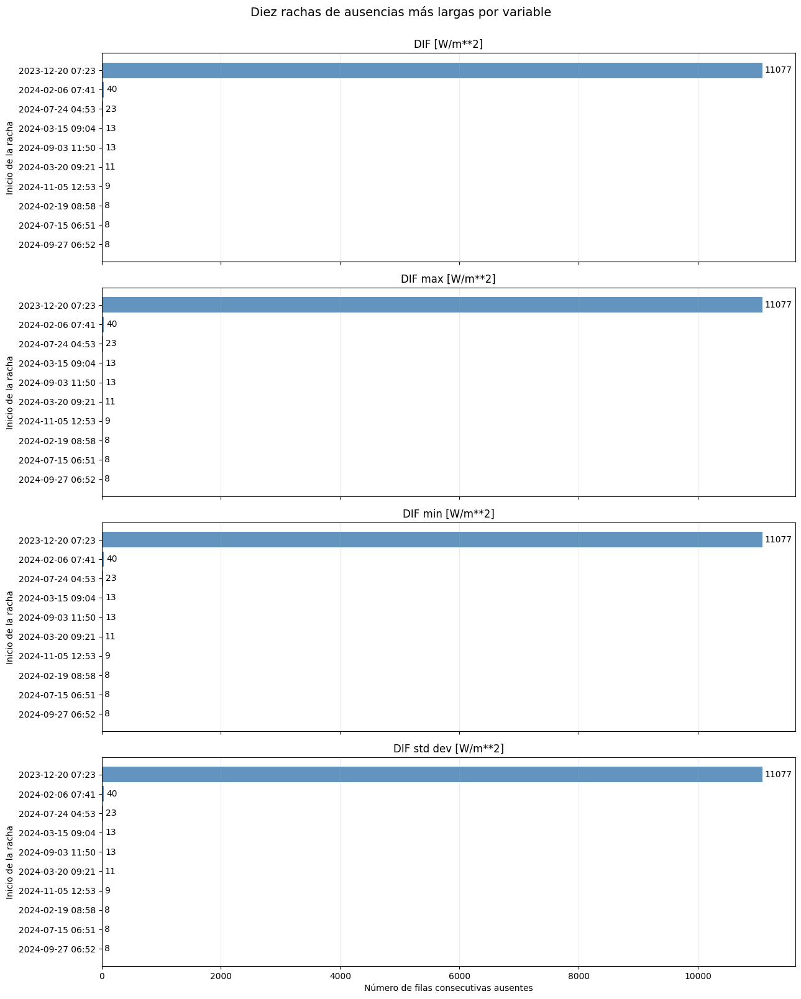

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Comprobación previa
if "rachas_ausencias_t4" not in globals():
    raise NameError(
        "No existe 'rachas_ausencias_t4'. " "Ejecuta primero la celda que construye las rachas."
    )


# 2. Seleccionar las diez rachas más largas de cada variable
rachas_mas_largas_t4 = (
    rachas_ausencias_t4.sort_values(
        ["variable", "n_filas_ausentes", "fecha_inicio"],
        ascending=[True, False, True],
        kind="mergesort",
    )
    .groupby("variable", sort=False)
    .head(10)
    .copy()
)

# Posición de cada racha dentro de su variable
rachas_mas_largas_t4.insert(
    1, "puesto_en_variable", rachas_mas_largas_t4.groupby("variable").cumcount().add(1)
)

# Duraciones numéricas, útiles para analizar el CSV
rachas_mas_largas_t4["tiempo_entre_timestamps_minutos"] = (
    pd.to_timedelta(rachas_mas_largas_t4["tiempo_entre_timestamps"], errors="coerce")
    .dt.total_seconds()
    .div(60)
    .round(2)
)
rachas_mas_largas_t4["duracion_equivalente_minutos"] = (
    pd.to_timedelta(
        rachas_mas_largas_t4["duracion_equivalente_cadencia_observada"], errors="coerce"
    )
    .dt.total_seconds()
    .div(60)
    .round(2)
)


# 3. Vista compacta: una tabla por variable
columnas_vista = [
    "puesto_en_variable",
    "fecha_inicio",
    "fecha_fin",
    "n_filas_ausentes",
    "duracion_equivalente_cadencia_observada",
    "atraviesa_cambio_de_mes",
]
for variable in rachas_mas_largas_t4["variable"].unique():
    tabla_variable = rachas_mas_largas_t4.loc[
        rachas_mas_largas_t4["variable"].eq(variable), columnas_vista
    ].copy()
    print(f"\nDiez rachas más largas — {variable}")
    display(
        tabla_variable.style.hide(axis="index")
        .format(
            {
                "fecha_inicio": lambda x: (x.strftime("%Y-%m-%d %H:%M") if pd.notna(x) else ""),
                "fecha_fin": lambda x: (x.strftime("%Y-%m-%d %H:%M") if pd.notna(x) else ""),
                "n_filas_ausentes": "{:,.0f}",
            }
        )
        .background_gradient(subset=["n_filas_ausentes"], cmap="Blues")
    )


# 4. Gráfico comparativo
variables = rachas_mas_largas_t4["variable"].unique().tolist()
fig, ejes = plt.subplots(
    nrows=len(variables), ncols=1, figsize=(13, 4 * len(variables)), sharex=True
)
if len(variables) == 1:
    ejes = [ejes]

for eje, variable in zip(ejes, variables):
    datos = (
        rachas_mas_largas_t4.loc[rachas_mas_largas_t4["variable"].eq(variable)]
        .sort_values(["n_filas_ausentes", "fecha_inicio"], ascending=[True, False])
        .copy()
    )
    etiquetas = datos["fecha_inicio"].dt.strftime("%Y-%m-%d %H:%M")
    barras = eje.barh(etiquetas, datos["n_filas_ausentes"], color="steelblue", alpha=0.85)
    eje.bar_label(barras, labels=datos["n_filas_ausentes"].astype(str), padding=3)
    eje.set_title(variable)
    eje.set_ylabel("Inicio de la racha")
    eje.grid(axis="x", alpha=0.25)

ejes[-1].set_xlabel("Número de filas consecutivas ausentes")
fig.suptitle("Diez rachas de ausencias más largas por variable", fontsize=14, y=1.002)
plt.tight_layout()
plt.show()

### 4.3 Distribución mensual

In [16]:
base_mensual = df_t4.loc[mascara_fecha_valida].copy()
base_mensual["mes"] = base_mensual[COL_FECHA].dt.strftime("%Y-%m")
n_filas_por_mes = base_mensual.groupby("mes", sort=True).size()
tablas_mensuales = []
for columna in COLUMNAS_DIF:
    n_ausentes_por_mes = base_mensual.loc[base_mensual[columna].isna()].groupby("mes").size()
    detalle_variable = rachas_ausencias_t4.loc[rachas_ausencias_t4["variable"].eq(columna)]
    n_rachas_iniciadas = detalle_variable.groupby("mes_inicio").size()
    maximo_racha_iniciada = detalle_variable.groupby("mes_inicio")["n_filas_ausentes"].max()
    tabla_mes = pd.DataFrame(
        {
            "n_filas_mes": n_filas_por_mes,
            "n_ausentes_mes": n_ausentes_por_mes.reindex(n_filas_por_mes.index, fill_value=0),
            "n_rachas_iniciadas_mes": n_rachas_iniciadas.reindex(
                n_filas_por_mes.index, fill_value=0
            ),
            "máximo_filas_racha_iniciada_mes": maximo_racha_iniciada.reindex(
                n_filas_por_mes.index, fill_value=0
            ),
        }
    )
    tabla_mes["%_ausentes_mes"] = tabla_mes["n_ausentes_mes"].div(tabla_mes["n_filas_mes"]).mul(100)
    tabla_mes.insert(0, "variable", columna)
    tablas_mensuales.append(tabla_mes.reset_index())

distribucion_mensual_ausencias_t4 = pd.concat(tablas_mensuales, ignore_index=True)
orden_variables = {variable: posicion for posicion, variable in enumerate(COLUMNAS_DIF)}
distribucion_mensual_ausencias_t4["_orden"] = distribucion_mensual_ausencias_t4["variable"].map(
    orden_variables
)
distribucion_mensual_ausencias_t4 = (
    distribucion_mensual_ausencias_t4.sort_values(["_orden", "mes"])
    .drop(columns="_orden")
    .reset_index(drop=True)
)
display(distribucion_mensual_ausencias_t4)

,mes,variable,n_filas_mes,n_ausentes_mes,n_rachas_iniciadas_mes,máximo_filas_racha_iniciada_mes,%_ausentes_mes
0,2023-11,DIF [W/m**2],43200,19,13,2,0.043981
1,2023-12,DIF [W/m**2],44640,11086,9,11077,24.834229
2,2024-01,DIF [W/m**2],44640,30,18,5,0.067204
3,2024-02,DIF [W/m**2],41760,69,15,40,0.165230
4,2024-03,DIF [W/m**2],44640,55,18,13,0.123208
5,2024-04,DIF [W/m**2],43200,48,20,7,0.111111
6,2024-05,DIF [W/m**2],44640,34,17,6,0.076165
7,2024-06,DIF [W/m**2],43200,64,30,5,0.148148
8,2024-07,DIF [W/m**2],44640,74,23,23,0.165771
9,2024-08,DIF [W/m**2],44640,22,15,4,0.049283


Distribución mensual de las ausencias de la familia DIF:


variable,mes,n_filas_mes,n_ausentes_mes,%_ausentes_mes,n_rachas_iniciadas_mes,máximo_filas_racha_iniciada_mes
DIF [W/m**2],2023-11,43.200,19,"0,0440 %",13,2
DIF [W/m**2],2023-12,44.640,11.086,"24,8342 %",9,11.077
DIF [W/m**2],2024-01,44.640,30,"0,0672 %",18,5
DIF [W/m**2],2024-02,41.760,69,"0,1652 %",15,40
DIF [W/m**2],2024-03,44.640,55,"0,1232 %",18,13
DIF [W/m**2],2024-04,43.200,48,"0,1111 %",20,7
DIF [W/m**2],2024-05,44.640,34,"0,0762 %",17,6
DIF [W/m**2],2024-06,43.200,64,"0,1481 %",30,5
DIF [W/m**2],2024-07,44.640,74,"0,1658 %",23,23
DIF [W/m**2],2024-08,44.640,22,"0,0493 %",15,4


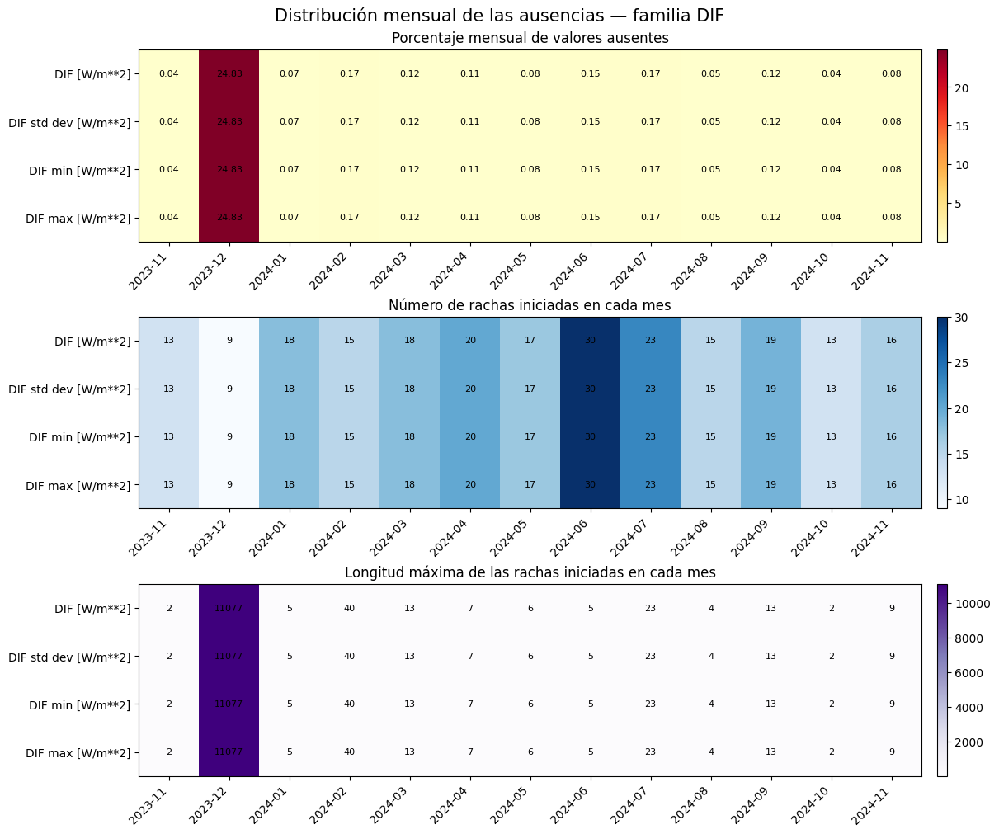

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Comprobaciones y preparación
objetos_requeridos = ["distribucion_mensual_ausencias_t4", "COLUMNAS_DIF"]
objetos_ausentes = [objeto for objeto in objetos_requeridos if objeto not in globals()]
if objetos_ausentes:
    raise NameError(f"Faltan objetos necesarios: {objetos_ausentes}")

columnas_exportacion = [
    "variable",
    "mes",
    "n_filas_mes",
    "n_ausentes_mes",
    "%_ausentes_mes",
    "n_rachas_iniciadas_mes",
    "máximo_filas_racha_iniciada_mes",
]
columnas_faltantes = [
    columna
    for columna in columnas_exportacion
    if columna not in distribucion_mensual_ausencias_t4.columns
]
if columnas_faltantes:
    raise KeyError(f"Faltan columnas en la distribución mensual: " f"{columnas_faltantes}")

exportacion_mensual_t4 = distribucion_mensual_ausencias_t4[columnas_exportacion].copy()
if exportacion_mensual_t4.duplicated(subset=["variable", "mes"]).any():
    raise ValueError("Existen combinaciones variable-mes duplicadas.")

orden_variables = {variable: posicion for posicion, variable in enumerate(COLUMNAS_DIF)}
exportacion_mensual_t4["_orden_variable"] = exportacion_mensual_t4["variable"].map(orden_variables)
exportacion_mensual_t4 = (
    exportacion_mensual_t4.sort_values(["_orden_variable", "mes"], kind="mergesort")
    .drop(columns="_orden_variable")
    .reset_index(drop=True)
)
columnas_recuento = [
    "n_filas_mes",
    "n_ausentes_mes",
    "n_rachas_iniciadas_mes",
    "máximo_filas_racha_iniciada_mes",
]
for columna in columnas_recuento:
    exportacion_mensual_t4[columna] = pd.to_numeric(
        exportacion_mensual_t4[columna], errors="raise"
    ).astype("Int64")

exportacion_mensual_t4["%_ausentes_mes"] = pd.to_numeric(
    exportacion_mensual_t4["%_ausentes_mes"], errors="raise"
)


# 2. Tabla visual completa
print("Distribución mensual de las ausencias de la familia DIF:")
display(
    exportacion_mensual_t4.style.hide(axis="index")
    .format(
        {
            "n_filas_mes": "{:,.0f}",
            "n_ausentes_mes": "{:,.0f}",
            "%_ausentes_mes": "{:.4f} %",
            "n_rachas_iniciadas_mes": "{:,.0f}",
            "máximo_filas_racha_iniciada_mes": "{:,.0f}",
        },
        na_rep="—",
        thousands=".",
        decimal=",",
    )
    .background_gradient(subset=["%_ausentes_mes"], cmap="YlOrRd")
    .background_gradient(subset=["máximo_filas_racha_iniciada_mes"], cmap="Purples")
)


# 3. Mapas de calor
metricas = [
    ("%_ausentes_mes", "Porcentaje mensual de valores ausentes", "YlOrRd", ".2f"),
    ("n_rachas_iniciadas_mes", "Número de rachas iniciadas en cada mes", "Blues", ".0f"),
    (
        "máximo_filas_racha_iniciada_mes",
        "Longitud máxima de las rachas iniciadas en cada mes",
        "Purples",
        ".0f",
    ),
]
meses = sorted(exportacion_mensual_t4["mes"].unique())
n_meses = len(meses)
fig, ejes = plt.subplots(
    nrows=len(metricas),
    ncols=1,
    figsize=(min(24, max(12, n_meses * 0.70)), 10),
    constrained_layout=True,
)
if len(metricas) == 1:
    ejes = [ejes]

anotar_celdas = n_meses <= 24
paso_etiquetas = max(1, int(np.ceil(n_meses / 24)))
posiciones_etiquetas = np.arange(0, n_meses, paso_etiquetas)
for eje, (columna, titulo, mapa_color, formato) in zip(ejes, metricas):
    matriz = exportacion_mensual_t4.pivot(index="variable", columns="mes", values=columna).reindex(
        index=COLUMNAS_DIF, columns=meses
    )
    valores = matriz.to_numpy(dtype=float)
    valores_mostrados = np.ma.masked_invalid(valores)
    imagen = eje.imshow(valores_mostrados, aspect="auto", cmap=mapa_color)
    eje.set_title(titulo)
    eje.set_yticks(np.arange(len(matriz.index)))
    eje.set_yticklabels(matriz.index)
    eje.set_xticks(posiciones_etiquetas)
    eje.set_xticklabels([meses[i] for i in posiciones_etiquetas], rotation=45, ha="right")
    if anotar_celdas:
        for fila in range(valores.shape[0]):
            for columna_mes in range(valores.shape[1]):
                valor = valores[fila, columna_mes]
                if np.isfinite(valor):
                    etiqueta = format(valor, formato)
                    eje.text(
                        columna_mes,
                        fila,
                        etiqueta,
                        ha="center",
                        va="center",
                        fontsize=8,
                        color="black",
                    )

    fig.colorbar(imagen, ax=eje, fraction=0.025, pad=0.02)

fig.suptitle("Distribución mensual de las ausencias — familia DIF", fontsize=15)
plt.show()

### 4.4 Controles

In [18]:
# 1. Todas las ausencias con fecha válida deben pertenecer
# exactamente a una racha.
control_asignacion_rachas = all(
    int(
        rachas_ausencias_t4.loc[
            rachas_ausencias_t4["variable"].eq(columna), "n_filas_ausentes"
        ].sum()
    )
    == int(df_t4.loc[mascara_fecha_valida, columna].isna().sum())
    for columna in COLUMNAS_DIF
)

# 2. Dentro de cada racha, los timestamps deben conservar
# la cadencia observada.
if rachas_ausencias_t4.empty:
    control_duracion_rachas = True
else:
    duracion_esperada_entre_extremos = (
        rachas_ausencias_t4["n_filas_ausentes"].sub(1).mul(cadencia_referencia_t4)
    )
    control_duracion_rachas = (
        rachas_ausencias_t4["tiempo_entre_timestamps"].eq(duracion_esperada_entre_extremos).all()
    )

# 3. La distribución mensual debe recuperar todas las ausencias.
control_distribucion_mensual = all(
    int(
        distribucion_mensual_ausencias_t4.loc[
            distribucion_mensual_ausencias_t4["variable"].eq(columna), "n_ausentes_mes"
        ].sum()
    )
    == int(df_t4.loc[mascara_fecha_valida, columna].isna().sum())
    for columna in COLUMNAS_DIF
)

# 4. Los recuentos totales deben coincidir con la sección 3.
ausentes_t3 = resumen_calidad_dif_t3.set_index("variable")["n_ausentes"]
control_coincidencia_t3 = all(
    int(df_t4[columna].isna().sum()) == int(ausentes_t3.loc[columna]) for columna in COLUMNAS_DIF
)
control_fuente_intacta = df_t4.equals(df_t2.loc[:, columnas_t4].reset_index(drop=True))
controles_t4 = pd.DataFrame(
    {
        "control": [
            "No existen Date/Time = NaT",
            "Las fechas válidas siguen ordenadas",
            "No existen timestamps duplicados",
            "Cada ausencia con fecha válida pertenece a una única racha",
            "Ninguna racha atraviesa una transición temporal irregular",
            "La distribución mensual recupera todas las ausencias",
            "Los ausentes coinciden con los calculados en la sección 3",
            "df_t2 y sus columnas originales permanecen intactos",
        ],
        "superado": [
            n_nat_t4 == 0,
            fechas_validas_t4.is_monotonic_increasing,
            not fechas_validas_t4.duplicated().any(),
            control_asignacion_rachas,
            control_duracion_rachas,
            control_distribucion_mensual,
            control_coincidencia_t3,
            control_fuente_intacta,
        ],
    }
)
display(controles_t4)
if controles_t4["superado"].all():
    print("Todos los controles de la sección 4 se han superado.")
else:
    print("Existe algún control no superado. " "No des por completada la tarea hasta revisarlo.")

,control,superado
0,No existen Date/Time = NaT,True
1,Las fechas válidas siguen ordenadas,True
2,No existen timestamps duplicados,True
3,Cada ausencia con fecha válida pertenece a una...,True
4,Ninguna racha atraviesa una transición tempora...,True
5,La distribución mensual recupera todas las aus...,True
6,Los ausentes coinciden con los calculados en l...,True
7,df_t2 y sus columnas originales permanecen int...,True


Todos los controles de la sección 4 se han superado.


## 5. Ausencias conjuntas, contraste con SWD y coherencia interna

Se comparan los patrones de ausencia de las cuatro columnas, se contrastan las ausencias y los negativos con SWD y se comprueban las relaciones `DIF min ≤ DIF ≤ DIF max` y `DIF std dev ≥ 0`.

### 5.1 Preparación

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# 1. Definición explícita de columnas
COL_FECHA_T5 = "Date/Time"
COL_DIF_T5 = "DIF [W/m**2]"
COL_DIF_STD_T5 = "DIF std dev [W/m**2]"
COL_DIF_MIN_T5 = "DIF min [W/m**2]"
COL_DIF_MAX_T5 = "DIF max [W/m**2]"
COL_SWD_T5 = "SWD [W/m**2]"
COLUMNAS_DIF_T5 = [COL_DIF_T5, COL_DIF_STD_T5, COL_DIF_MIN_T5, COL_DIF_MAX_T5]
COLUMNAS_T5 = [COL_FECHA_T5, *COLUMNAS_DIF_T5, COL_SWD_T5]

# Tolerancia exclusivamente numérica.
# No representa una tolerancia física del instrumento.
TOLERANCIA_NUMERICA_T5 = 1e-9


# 2. Comprobaciones previas
if "df_t2" not in globals():
    raise NameError(
        "No existe 'df_t2'. Recarga o ejecuta primero las " "celdas anteriores del cuaderno."
    )

columnas_ausentes = [columna for columna in COLUMNAS_T5 if columna not in df_t2.columns]
if columnas_ausentes:
    raise KeyError(f"Faltan columnas necesarias para la sección 5: " f"{columnas_ausentes}")

if not pd.api.types.is_datetime64_any_dtype(df_t2[COL_FECHA_T5]):
    raise TypeError(f"{COL_FECHA_T5} debe ser de tipo datetime.")

columnas_no_numericas = [
    columna
    for columna in [*COLUMNAS_DIF_T5, COL_SWD_T5]
    if not pd.api.types.is_numeric_dtype(df_t2[columna])
]
if columnas_no_numericas:
    raise TypeError(f"Estas columnas deberían ser numéricas: " f"{columnas_no_numericas}")


# 3. Copia de trabajo: no modifica df_t2
df_t5 = df_t2.loc[:, COLUMNAS_T5].copy(deep=True).reset_index(drop=True)
fechas_t5 = df_t5[COL_FECHA_T5]
if fechas_t5.isna().any():
    raise ValueError("Existen Date/Time = NaT. Revisa la sección 4.")

if fechas_t5.duplicated().any():
    raise ValueError("Existen timestamps duplicados. Revisa la sección 4.")

if not fechas_t5.is_monotonic_increasing:
    raise ValueError("Date/Time no está ordenado de forma creciente.")

print("Preparación de la sección 5 completada.")
print(f"Dimensiones de df_t5: {df_t5.shape}")
print(f"Periodo: {fechas_t5.min()} — {fechas_t5.max()}")
print(f"Columnas analizadas: {COLUMNAS_T5}")
print("No se ha eliminado, imputado ni sobrescrito " "ninguna observación.")

Preparación de la sección 5 completada.
Dimensiones de df_t5: (570240, 6)
Periodo: 2023-11-01 00:00:00 — 2024-11-30 23:59:00
Columnas analizadas: ['Date/Time', 'DIF [W/m**2]', 'DIF std dev [W/m**2]', 'DIF min [W/m**2]', 'DIF max [W/m**2]', 'SWD [W/m**2]']
No se ha eliminado, imputado ni sobrescrito ninguna observación.


### 5.2 Patrones conjuntos de ausencia

In [20]:
# 1. Máscaras de ausencia
mascaras_nulos_dif_t5 = df_t5[COLUMNAS_DIF_T5].isna()
n_variables_dif_ausentes_t5 = mascaras_nulos_dif_t5.sum(axis=1)
estado_ausencia_dif_t5 = pd.Series(
    np.select(
        [n_variables_dif_ausentes_t5.eq(0), n_variables_dif_ausentes_t5.eq(len(COLUMNAS_DIF_T5))],
        ["Ninguna ausente", "Todas ausentes"],
        default="Ausencia parcial",
    ),
    index=df_t5.index,
    name="estado_ausencia_dif",
)


# 2. Resumen por variable
mascara_referencia_t5 = mascaras_nulos_dif_t5[COL_DIF_T5]
registros_resumen_ausencias = []
for columna in COLUMNAS_DIF_T5:
    mascara = mascaras_nulos_dif_t5[columna]
    registros_resumen_ausencias.append(
        {
            "variable": columna,
            "n_ausentes": int(mascara.sum()),
            "%_ausentes": float(mascara.mean() * 100),
            "mascara_igual_a_DIF": bool(mascara.equals(mascara_referencia_t5)),
        }
    )

resumen_ausencias_conjuntas_t5 = pd.DataFrame(registros_resumen_ausencias)
display(resumen_ausencias_conjuntas_t5)


# 3. Codificación de los patrones
# 0 = valor disponible
# 1 = valor ausente
# Orden:
# DIF | std dev | min | max
codigo_patron_nulos_t5 = mascaras_nulos_dif_t5.astype("int8").astype(str).agg("".join, axis=1)
patrones_conjuntos_nulos_t5 = (
    codigo_patron_nulos_t5.value_counts(dropna=False)
    .rename_axis("codigo_patron")
    .reset_index(name="n_filas")
)
patrones_conjuntos_nulos_t5["%_filas"] = (
    patrones_conjuntos_nulos_t5["n_filas"].div(len(df_t5)).mul(100)
)
patrones_conjuntos_nulos_t5["n_variables_ausentes"] = patrones_conjuntos_nulos_t5[
    "codigo_patron"
].str.count("1")
patrones_conjuntos_nulos_t5["tipo_patron"] = np.select(
    [
        patrones_conjuntos_nulos_t5["codigo_patron"].eq("0000"),
        patrones_conjuntos_nulos_t5["codigo_patron"].eq("1111"),
    ],
    ["Ninguna ausente", "Todas ausentes"],
    default="Ausencia parcial",
)

def describir_patron_t5(codigo):
    partes = []
    for columna, indicador in zip(COLUMNAS_DIF_T5, codigo):
        estado = "ausente" if indicador == "1" else "válida"
        partes.append(f"{columna}: {estado}")

    return " | ".join(partes)

patrones_conjuntos_nulos_t5["descripcion"] = patrones_conjuntos_nulos_t5["codigo_patron"].map(
    describir_patron_t5
)
print("Orden del código: DIF | std dev | min | max")
display(patrones_conjuntos_nulos_t5)


# 4. Coincidencia por parejas
registros_coincidencia = []
for posicion_a, variable_a in enumerate(COLUMNAS_DIF_T5):
    for variable_b in COLUMNAS_DIF_T5[posicion_a + 1 :]:
        mascara_a = mascaras_nulos_dif_t5[variable_a]
        mascara_b = mascaras_nulos_dif_t5[variable_b]
        ambas_ausentes = mascara_a & mascara_b
        solo_a = mascara_a & ~mascara_b
        solo_b = ~mascara_a & mascara_b
        union_ausencias = mascara_a | mascara_b
        n_union = int(union_ausencias.sum())
        registros_coincidencia.append(
            {
                "variable_a": variable_a,
                "variable_b": variable_b,
                "ambas_ausentes": int(ambas_ausentes.sum()),
                "solo_variable_a_ausente": int(solo_a.sum()),
                "solo_variable_b_ausente": int(solo_b.sum()),
                "coincidencia_total_%": float(mascara_a.eq(mascara_b).mean() * 100),
                "jaccard_ausencias": (
                    float(ambas_ausentes.sum() / n_union) if n_union > 0 else np.nan
                ),
            }
        )

coincidencia_ausencias_parejas_t5 = pd.DataFrame(registros_coincidencia)
display(coincidencia_ausencias_parejas_t5)


# 5. Filas con ausencias parciales
mascara_ausencia_parcial_t5 = estado_ausencia_dif_t5.eq("Ausencia parcial")
filas_ausencia_parcial_t5 = df_t5.loc[
    mascara_ausencia_parcial_t5, [COL_FECHA_T5, *COLUMNAS_DIF_T5]
].copy()
if not filas_ausencia_parcial_t5.empty:
    filas_ausencia_parcial_t5.insert(
        1, "codigo_patron", codigo_patron_nulos_t5.loc[mascara_ausencia_parcial_t5].to_numpy()
    )

print("Filas con ausencia parcial en la familia DIF:", len(filas_ausencia_parcial_t5))
display(filas_ausencia_parcial_t5.head(20))

,variable,n_ausentes,%_ausentes,mascara_igual_a_DIF
0,DIF [W/m**2],11605,2.035108,True
1,DIF std dev [W/m**2],11605,2.035108,True
2,DIF min [W/m**2],11605,2.035108,True
3,DIF max [W/m**2],11605,2.035108,True


Orden del código: DIF | std dev | min | max


,codigo_patron,n_filas,%_filas,n_variables_ausentes,tipo_patron,descripcion
0,0000,558635,97.964892,0,Ninguna ausente,DIF [W/m**2]: válida | DIF std dev [W/m**2]: v...
1,1111,11605,2.035108,4,Todas ausentes,DIF [W/m**2]: ausente | DIF std dev [W/m**2]: ...


,variable_a,variable_b,ambas_ausentes,solo_variable_a_ausente,solo_variable_b_ausente,coincidencia_total_%,jaccard_ausencias
0,DIF [W/m**2],DIF std dev [W/m**2],11605,0,0,100.0,1.0
1,DIF [W/m**2],DIF min [W/m**2],11605,0,0,100.0,1.0
2,DIF [W/m**2],DIF max [W/m**2],11605,0,0,100.0,1.0
3,DIF std dev [W/m**2],DIF min [W/m**2],11605,0,0,100.0,1.0
4,DIF std dev [W/m**2],DIF max [W/m**2],11605,0,0,100.0,1.0
5,DIF min [W/m**2],DIF max [W/m**2],11605,0,0,100.0,1.0


Filas con ausencia parcial en la familia DIF: 0


,Date/Time,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2]


### 5.3 Ausencias y negativos frente a SWD

In [21]:
# 1. Clasificación de SWD
swd_t5 = df_t5[COL_SWD_T5]
swd_array_t5 = swd_t5.to_numpy(dtype=float, na_value=np.nan)
mascara_swd_finita_t5 = pd.Series(np.isfinite(swd_array_t5), index=df_t5.index)
mascara_swd_ausente_t5 = swd_t5.isna()
mascara_swd_no_finita_t5 = swd_t5.notna() & ~mascara_swd_finita_t5
categoria_swd_t5 = pd.Series(pd.NA, index=df_t5.index, dtype="string", name="categoria_swd")
categoria_swd_t5.loc[mascara_swd_ausente_t5] = "SWD ausente"
categoria_swd_t5.loc[mascara_swd_no_finita_t5] = "SWD no finito"
categoria_swd_t5.loc[mascara_swd_finita_t5 & swd_t5.le(10)] = "SWD ≤ 10"
categoria_swd_t5.loc[mascara_swd_finita_t5 & swd_t5.gt(10)] = "SWD > 10"


# 2. Tabla cruzada DIF-SWD
orden_estados_dif = ["Ninguna ausente", "Ausencia parcial", "Todas ausentes"]
orden_categorias_swd = ["SWD ausente", "SWD no finito", "SWD ≤ 10", "SWD > 10"]
tabla_conteos_dif_swd = pd.crosstab(estado_ausencia_dif_t5, categoria_swd_t5).reindex(
    index=orden_estados_dif, columns=orden_categorias_swd, fill_value=0
)
contraste_dif_swd_t5 = (
    tabla_conteos_dif_swd.rename_axis(index="estado_ausencia_dif")
    .reset_index()
    .melt(id_vars="estado_ausencia_dif", var_name="categoria_swd", value_name="n_filas")
)
denominador_estado = contraste_dif_swd_t5.groupby("estado_ausencia_dif")["n_filas"].transform("sum")
contraste_dif_swd_t5["%_dentro_estado_DIF"] = np.where(
    denominador_estado.gt(0),
    contraste_dif_swd_t5["n_filas"].div(denominador_estado).mul(100),
    np.nan,
)
tabla_cruzada_dif_swd_t5 = tabla_conteos_dif_swd.copy()
tabla_cruzada_dif_swd_t5["Total"] = tabla_cruzada_dif_swd_t5.sum(axis=1)
tabla_cruzada_dif_swd_t5.loc["Total"] = tabla_cruzada_dif_swd_t5.sum(axis=0)
print("Tabla cruzada de recuentos:")
display(tabla_cruzada_dif_swd_t5)
print("Tabla en formato largo y con porcentajes:")
display(contraste_dif_swd_t5)


# 3. Detalle de las filas con toda la familia DIF ausente
mascara_toda_familia_dif_ausente_t5 = estado_ausencia_dif_t5.eq("Todas ausentes")
detalle_ausencias_dif_swd_t5 = df_t5.loc[
    mascara_toda_familia_dif_ausente_t5, [COL_FECHA_T5, COL_SWD_T5, *COLUMNAS_DIF_T5]
].copy()
detalle_ausencias_dif_swd_t5.insert(
    2, "categoria_swd", categoria_swd_t5.loc[mascara_toda_familia_dif_ausente_t5].to_numpy()
)
proxy_swd_mayor_10 = pd.Series(pd.NA, index=detalle_ausencias_dif_swd_t5.index, dtype="boolean")
indices_swd_finita = mascara_toda_familia_dif_ausente_t5 & mascara_swd_finita_t5
proxy_swd_mayor_10.loc[indices_swd_finita] = swd_t5.loc[indices_swd_finita].gt(10)
detalle_ausencias_dif_swd_t5["swd_mayor_10_proxy"] = proxy_swd_mayor_10
print("Filas con las cuatro variables DIF ausentes:", len(detalle_ausencias_dif_swd_t5))
display(detalle_ausencias_dif_swd_t5.head(20))


# 4. Distribución mensual del contraste
base_mensual_t5 = pd.DataFrame(
    {
        "mes": (df_t5[COL_FECHA_T5].dt.strftime("%Y-%m")),
        "dif_todas_ausentes": mascara_toda_familia_dif_ausente_t5,
        "dif_ausencia_parcial": mascara_ausencia_parcial_t5,
        "swd_ausente": mascara_swd_ausente_t5,
        "dif_y_swd_ausentes": (mascara_toda_familia_dif_ausente_t5 & mascara_swd_ausente_t5),
        "dif_ausente_swd_disponible": (mascara_toda_familia_dif_ausente_t5 & mascara_swd_finita_t5),
        "dif_ausente_swd_le_10": (
            mascara_toda_familia_dif_ausente_t5 & mascara_swd_finita_t5 & swd_t5.le(10)
        ),
        "dif_ausente_swd_gt_10": (
            mascara_toda_familia_dif_ausente_t5 & mascara_swd_finita_t5 & swd_t5.gt(10)
        ),
    }
)
distribucion_mensual_contraste_t5 = (
    base_mensual_t5.groupby("mes", sort=True)
    .agg(
        n_filas=("mes", "size"),
        n_dif_todas_ausentes=("dif_todas_ausentes", "sum"),
        n_dif_ausencia_parcial=("dif_ausencia_parcial", "sum"),
        n_swd_ausente=("swd_ausente", "sum"),
        n_dif_y_swd_ausentes=("dif_y_swd_ausentes", "sum"),
        n_dif_ausente_swd_disponible=("dif_ausente_swd_disponible", "sum"),
        n_dif_ausente_swd_le_10=("dif_ausente_swd_le_10", "sum"),
        n_dif_ausente_swd_gt_10=("dif_ausente_swd_gt_10", "sum"),
    )
    .reset_index()
)
distribucion_mensual_contraste_t5["%_dif_todas_ausentes"] = (
    distribucion_mensual_contraste_t5["n_dif_todas_ausentes"]
    .div(distribucion_mensual_contraste_t5["n_filas"])
    .mul(100)
)
distribucion_mensual_contraste_t5["%_swd_ausente"] = (
    distribucion_mensual_contraste_t5["n_swd_ausente"]
    .div(distribucion_mensual_contraste_t5["n_filas"])
    .mul(100)
)
denominador_dif_ausente = distribucion_mensual_contraste_t5["n_dif_todas_ausentes"].replace(
    0, np.nan
)
distribucion_mensual_contraste_t5["%_swd_gt_10_durante_ausencia_DIF"] = (
    distribucion_mensual_contraste_t5["n_dif_ausente_swd_gt_10"]
    .div(denominador_dif_ausente)
    .mul(100)
)
display(distribucion_mensual_contraste_t5)


# 5. Negativos de la familia DIF según SWD
registros_negativos_swd = []
for columna in COLUMNAS_DIF_T5:
    valores_columna = df_t5[columna].to_numpy(dtype=float, na_value=np.nan)
    mascara_negativa = pd.Series(
        np.isfinite(valores_columna) & (valores_columna < 0), index=df_t5.index
    )
    n_negativos = int(mascara_negativa.sum())
    registro = {"variable": columna, "n_negativos": n_negativos}
    for categoria in orden_categorias_swd:
        nombre_columna = "n_negativos_" + categoria.lower().replace(" ", "_").replace(
            "≤", "le"
        ).replace(">", "gt")
        registro[nombre_columna] = int((mascara_negativa & categoria_swd_t5.eq(categoria)).sum())

    n_negativos_swd_gt_10 = int((mascara_negativa & categoria_swd_t5.eq("SWD > 10")).sum())
    registro["%_negativos_con_SWD_gt_10"] = (
        n_negativos_swd_gt_10 / n_negativos * 100 if n_negativos > 0 else np.nan
    )
    registros_negativos_swd.append(registro)

resumen_negativos_swd_t5 = pd.DataFrame(registros_negativos_swd)
display(resumen_negativos_swd_t5)


# 6. SWD durante la racha máxima detectada en la sección 4
inicio_racha_max_t5 = None
fin_racha_max_t5 = None
columnas_resumen_intervalo = [
    "fecha_inicio",
    "fecha_fin",
    "n_filas_intervalo",
    "n_swd_ausente",
    "n_swd_no_finito",
    "n_swd_finito",
    "n_swd_le_10",
    "n_swd_gt_10",
    "%_swd_gt_10",
    "swd_mínimo",
    "swd_mediana",
    "swd_máximo",
]
resumen_intervalo_maximo_t5 = pd.DataFrame(columns=columnas_resumen_intervalo)
if "rachas_ausencias_t4" in globals() and not rachas_ausencias_t4.empty:
    detalle_rachas_dif = rachas_ausencias_t4.loc[rachas_ausencias_t4["variable"].eq(COL_DIF_T5)]
    if not detalle_rachas_dif.empty:
        racha_maxima_dif = detalle_rachas_dif.sort_values(
            ["n_filas_ausentes", "fecha_inicio"], ascending=[False, True]
        ).iloc[0]
        inicio_racha_max_t5 = racha_maxima_dif["fecha_inicio"]
        fin_racha_max_t5 = racha_maxima_dif["fecha_fin"]
        mascara_intervalo_maximo = fechas_t5.ge(inicio_racha_max_t5) & fechas_t5.le(
            fin_racha_max_t5
        )
        mascara_finita_intervalo = mascara_intervalo_maximo & mascara_swd_finita_t5
        swd_finita_intervalo = swd_t5.loc[mascara_finita_intervalo]
        n_swd_finito_intervalo = int(mascara_finita_intervalo.sum())
        resumen_intervalo_maximo_t5 = pd.DataFrame(
            [
                {
                    "fecha_inicio": inicio_racha_max_t5,
                    "fecha_fin": fin_racha_max_t5,
                    "n_filas_intervalo": int(mascara_intervalo_maximo.sum()),
                    "n_swd_ausente": int((mascara_intervalo_maximo & mascara_swd_ausente_t5).sum()),
                    "n_swd_no_finito": int(
                        (mascara_intervalo_maximo & mascara_swd_no_finita_t5).sum()
                    ),
                    "n_swd_finito": n_swd_finito_intervalo,
                    "n_swd_le_10": int((mascara_finita_intervalo & swd_t5.le(10)).sum()),
                    "n_swd_gt_10": int((mascara_finita_intervalo & swd_t5.gt(10)).sum()),
                    "%_swd_gt_10": (
                        (
                            (mascara_finita_intervalo & swd_t5.gt(10)).sum()
                            / n_swd_finito_intervalo
                            * 100
                        )
                        if n_swd_finito_intervalo > 0
                        else np.nan
                    ),
                    "swd_mínimo": (
                        float(swd_finita_intervalo.min())
                        if not swd_finita_intervalo.empty
                        else np.nan
                    ),
                    "swd_mediana": (
                        float(swd_finita_intervalo.median())
                        if not swd_finita_intervalo.empty
                        else np.nan
                    ),
                    "swd_máximo": (
                        float(swd_finita_intervalo.max())
                        if not swd_finita_intervalo.empty
                        else np.nan
                    ),
                }
            ]
        )
        print("SWD durante la racha máxima de DIF:")
        display(resumen_intervalo_maximo_t5)

else:
    print(
        "No se ha encontrado 'rachas_ausencias_t4'. "
        "El contraste global se ha calculado, pero no el "
        "resumen específico de la racha máxima."
    )

Tabla cruzada de recuentos:


categoria_swd,SWD ausente,SWD no finito,SWD ≤ 10,SWD > 10,Total
estado_ausencia_dif,,,,,
Ninguna ausente,607,0,299402,258626,558635
Ausencia parcial,0,0,0,0,0
Todas ausentes,322,0,7997,3286,11605
Total,929,0,307399,261912,570240


Tabla en formato largo y con porcentajes:


,estado_ausencia_dif,categoria_swd,n_filas,%_dentro_estado_DIF
0,Ninguna ausente,SWD ausente,607,0.108658
1,Ausencia parcial,SWD ausente,0,NaN
2,Todas ausentes,SWD ausente,322,2.774666
3,Ninguna ausente,SWD no finito,0,0.000000
4,Ausencia parcial,SWD no finito,0,NaN
5,Todas ausentes,SWD no finito,0,0.000000
6,Ninguna ausente,SWD ≤ 10,299402,53.595281
7,Ausencia parcial,SWD ≤ 10,0,NaN
8,Todas ausentes,SWD ≤ 10,7997,68.909953
9,Ninguna ausente,SWD > 10,258626,46.296061


Filas con las cuatro variables DIF ausentes: 11605


,Date/Time,SWD [W/m**2],categoria_swd,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],swd_mayor_10_proxy
722,2023-11-01 12:02:00,NaN,SWD ausente,NaN,NaN,NaN,NaN,<NA>
3512,2023-11-03 10:32:00,245.0,SWD > 10,NaN,NaN,NaN,NaN,True
7769,2023-11-06 09:29:00,333.0,SWD > 10,NaN,NaN,NaN,NaN,True
7770,2023-11-06 09:30:00,314.0,SWD > 10,NaN,NaN,NaN,NaN,True
10891,2023-11-08 13:31:00,67.0,SWD > 10,NaN,NaN,NaN,NaN,True
13599,2023-11-10 10:39:00,33.0,SWD > 10,NaN,NaN,NaN,NaN,True
13600,2023-11-10 10:40:00,30.0,SWD > 10,NaN,NaN,NaN,NaN,True
17775,2023-11-13 08:15:00,NaN,SWD ausente,NaN,NaN,NaN,NaN,<NA>
20779,2023-11-15 10:19:00,NaN,SWD ausente,NaN,NaN,NaN,NaN,<NA>
20780,2023-11-15 10:20:00,291.0,SWD > 10,NaN,NaN,NaN,NaN,True


,mes,n_filas,n_dif_todas_ausentes,n_dif_ausencia_parcial,n_swd_ausente,n_dif_y_swd_ausentes,n_dif_ausente_swd_disponible,n_dif_ausente_swd_le_10,n_dif_ausente_swd_gt_10,%_dif_todas_ausentes,%_swd_ausente,%_swd_gt_10_durante_ausencia_DIF
0,2023-11,43200,19,0,39,5,14,1,13,0.043981,0.090278,68.421053
1,2023-12,44640,11086,0,197,189,10897,7990,2907,24.834229,0.441308,26.222262
2,2024-01,44640,30,0,24,5,25,0,25,0.067204,0.053763,83.333333
3,2024-02,41760,69,0,86,51,18,0,18,0.165230,0.205939,26.086957
4,2024-03,44640,55,0,56,6,49,0,49,0.123208,0.125448,89.090909
5,2024-04,43200,48,0,68,10,38,0,38,0.111111,0.157407,79.166667
6,2024-05,44640,34,0,26,7,27,0,27,0.076165,0.058244,79.411765
7,2024-06,43200,64,0,33,11,53,3,50,0.148148,0.076389,78.125000
8,2024-07,44640,74,0,100,5,69,0,69,0.165771,0.224014,93.243243
9,2024-08,44640,22,0,42,4,18,0,18,0.049283,0.094086,81.818182


,variable,n_negativos,n_negativos_swd_ausente,n_negativos_swd_no_finito,n_negativos_swd_le_10,n_negativos_swd_gt_10,%_negativos_con_SWD_gt_10
0,DIF [W/m**2],218624,0,0,218624,0,0.0
1,DIF std dev [W/m**2],0,0,0,0,0,NaN
2,DIF min [W/m**2],240093,0,0,240093,0,0.0
3,DIF max [W/m**2],190840,0,0,190840,0,0.0


SWD durante la racha máxima de DIF:


,fecha_inicio,fecha_fin,n_filas_intervalo,n_swd_ausente,n_swd_no_finito,n_swd_finito,n_swd_le_10,n_swd_gt_10,%_swd_gt_10,swd_mínimo,swd_mediana,swd_máximo
0,2023-12-20 07:23:00,2023-12-27 23:59:00,11077,187,0,10890,7990,2900,26.629936,-4.0,-1.0,323.0


### 5.4 Coherencia interna

In [22]:
# 1. Filas evaluables
datos_dif_numericos_t5 = df_t5[COLUMNAS_DIF_T5].apply(pd.to_numeric, errors="coerce")
matriz_dif_t5 = datos_dif_numericos_t5.to_numpy(dtype=float, na_value=np.nan)
mascara_dif_completa_finita_t5 = pd.Series(
    np.isfinite(matriz_dif_t5).all(axis=1), index=df_t5.index
)
dif_t5 = datos_dif_numericos_t5[COL_DIF_T5]
dif_std_t5 = datos_dif_numericos_t5[COL_DIF_STD_T5]
dif_min_t5 = datos_dif_numericos_t5[COL_DIF_MIN_T5]
dif_max_t5 = datos_dif_numericos_t5[COL_DIF_MAX_T5]
rango_dif_t5 = dif_max_t5 - dif_min_t5


# 2. Reglas de coherencia
# Los controles principales son desigualdades necesariamente
# exigibles.
# Los diagnósticos relacionados con valores exactamente cero
# pueden verse afectados por el redondeo instrumental.
reglas_coherencia_t5 = [
    {
        "tipo_control": "Principal",
        "regla": "DIF min ≤ DIF",
        "incumplimiento": (
            mascara_dif_completa_finita_t5 & dif_min_t5.gt(dif_t5 + TOLERANCIA_NUMERICA_T5)
        ),
        "magnitud": dif_min_t5 - dif_t5,
    },
    {
        "tipo_control": "Principal",
        "regla": "DIF ≤ DIF max",
        "incumplimiento": (
            mascara_dif_completa_finita_t5 & dif_t5.gt(dif_max_t5 + TOLERANCIA_NUMERICA_T5)
        ),
        "magnitud": dif_t5 - dif_max_t5,
    },
    {
        "tipo_control": "Principal",
        "regla": "DIF min ≤ DIF max",
        "incumplimiento": (
            mascara_dif_completa_finita_t5 & dif_min_t5.gt(dif_max_t5 + TOLERANCIA_NUMERICA_T5)
        ),
        "magnitud": dif_min_t5 - dif_max_t5,
    },
    {
        "tipo_control": "Principal",
        "regla": "DIF std dev ≥ 0",
        "incumplimiento": (mascara_dif_completa_finita_t5 & dif_std_t5.lt(-TOLERANCIA_NUMERICA_T5)),
        "magnitud": -dif_std_t5,
    },
    {
        "tipo_control": "Diagnóstico de redondeo",
        "regla": ("Rango ≈ 0 pero DIF std dev > 0"),
        "incumplimiento": (
            mascara_dif_completa_finita_t5
            & rango_dif_t5.abs().le(TOLERANCIA_NUMERICA_T5)
            & dif_std_t5.gt(TOLERANCIA_NUMERICA_T5)
        ),
        "magnitud": dif_std_t5.abs(),
    },
    {
        "tipo_control": "Diagnóstico de redondeo",
        "regla": ("DIF std dev ≈ 0 pero rango > 0"),
        "incumplimiento": (
            mascara_dif_completa_finita_t5
            & dif_std_t5.abs().le(TOLERANCIA_NUMERICA_T5)
            & rango_dif_t5.gt(TOLERANCIA_NUMERICA_T5)
        ),
        "magnitud": rango_dif_t5,
    },
]


# 3. Resumen y detalle de incidencias
registros_resumen_coherencia = []
bloques_detalle_incidencias = []
mascara_incidencias_principales_t5 = pd.Series(False, index=df_t5.index)
mascara_advertencias_diagnosticas_t5 = pd.Series(False, index=df_t5.index)
n_evaluadas = int(mascara_dif_completa_finita_t5.sum())
for regla in reglas_coherencia_t5:
    mascara_incidencia = regla["incumplimiento"]
    n_incidencias = int(mascara_incidencia.sum())
    if regla["tipo_control"] == "Principal":
        mascara_incidencias_principales_t5 |= mascara_incidencia
    else:
        mascara_advertencias_diagnosticas_t5 |= mascara_incidencia

    registros_resumen_coherencia.append(
        {
            "tipo_control": regla["tipo_control"],
            "regla": regla["regla"],
            "n_filas_evaluadas": n_evaluadas,
            "n_incidencias": n_incidencias,
            "%_incidencias_sobre_evaluadas": (
                n_incidencias / n_evaluadas * 100 if n_evaluadas > 0 else np.nan
            ),
            "máxima_magnitud_incidencia": (
                float(regla["magnitud"].loc[mascara_incidencia].max())
                if n_incidencias > 0
                else np.nan
            ),
        }
    )
    if n_incidencias > 0:
        bloque = df_t5.loc[mascara_incidencia, [COL_FECHA_T5, *COLUMNAS_DIF_T5]].copy()
        bloque.insert(1, "tipo_control", regla["tipo_control"])
        bloque.insert(2, "regla_incumplida", regla["regla"])
        bloque["rango_DIF_max_menos_min"] = rango_dif_t5.loc[mascara_incidencia].to_numpy()
        bloque["magnitud_incidencia"] = regla["magnitud"].loc[mascara_incidencia].to_numpy()
        bloques_detalle_incidencias.append(bloque)

resumen_coherencia_t5 = pd.DataFrame(registros_resumen_coherencia)
columnas_detalle_coherencia = [
    COL_FECHA_T5,
    "tipo_control",
    "regla_incumplida",
    *COLUMNAS_DIF_T5,
    "rango_DIF_max_menos_min",
    "magnitud_incidencia",
]
if bloques_detalle_incidencias:
    detalle_incidencias_coherencia_t5 = pd.concat(bloques_detalle_incidencias, ignore_index=True)
else:
    detalle_incidencias_coherencia_t5 = pd.DataFrame(columns=columnas_detalle_coherencia)

print("Resumen de coherencia interna:")
display(resumen_coherencia_t5)
print("Filas con incumplimientos principales:", int(mascara_incidencias_principales_t5.sum()))
print("Filas con advertencias diagnósticas:", int(mascara_advertencias_diagnosticas_t5.sum()))
display(detalle_incidencias_coherencia_t5.head(30))


# 4. Variables descriptivas intraminuto
metricas_intraminuto_t5 = pd.DataFrame(
    {
        "rango_DIF_max_menos_min": rango_dif_t5,
        "DIF_menos_DIF_min": dif_t5 - dif_min_t5,
        "DIF_max_menos_DIF": dif_max_t5 - dif_t5,
        "DIF_std_dev": dif_std_t5,
        "ratio_std_sobre_rango": (
            dif_std_t5.div(rango_dif_t5.where(rango_dif_t5.gt(TOLERANCIA_NUMERICA_T5)))
        ),
    }
)
metricas_intraminuto_t5 = metricas_intraminuto_t5.loc[mascara_dif_completa_finita_t5].replace(
    [np.inf, -np.inf], np.nan
)

def resumir_metrica_t5(serie):
    serie_valida = serie.dropna()
    if serie_valida.empty:
        return {
            "n": 0,
            "mínimo": np.nan,
            "p01": np.nan,
            "p25": np.nan,
            "mediana": np.nan,
            "media": np.nan,
            "p75": np.nan,
            "p95": np.nan,
            "p99": np.nan,
            "máximo": np.nan,
        }

    return {
        "n": int(serie_valida.size),
        "mínimo": float(serie_valida.min()),
        "p01": float(serie_valida.quantile(0.01)),
        "p25": float(serie_valida.quantile(0.25)),
        "mediana": float(serie_valida.median()),
        "media": float(serie_valida.mean()),
        "p75": float(serie_valida.quantile(0.75)),
        "p95": float(serie_valida.quantile(0.95)),
        "p99": float(serie_valida.quantile(0.99)),
        "máximo": float(serie_valida.max()),
    }

resumen_variabilidad_intraminuto_t5 = pd.DataFrame(
    {
        columna: resumir_metrica_t5(metricas_intraminuto_t5[columna])
        for columna in metricas_intraminuto_t5.columns
    }
).T
resumen_variabilidad_intraminuto_t5 = resumen_variabilidad_intraminuto_t5.reset_index().rename(
    columns={"index": "métrica"}
)
print(
    "Resumen de variabilidad intraminuto.\n"
    "El ratio std/rango es descriptivo; no se utiliza "
    "como regla automática de coherencia."
)
display(resumen_variabilidad_intraminuto_t5)

Resumen de coherencia interna:


,tipo_control,regla,n_filas_evaluadas,n_incidencias,%_incidencias_sobre_evaluadas,máxima_magnitud_incidencia
0,Principal,DIF min ≤ DIF,558635,0,0.000000,NaN
1,Principal,DIF ≤ DIF max,558635,0,0.000000,NaN
2,Principal,DIF min ≤ DIF max,558635,0,0.000000,NaN
3,Principal,DIF std dev ≥ 0,558635,0,0.000000,NaN
4,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,558635,214727,38.437799,0.4
5,Diagnóstico de redondeo,DIF std dev ≈ 0 pero rango > 0,558635,13532,2.422333,1.0


Filas con incumplimientos principales: 0
Filas con advertencias diagnósticas: 228259


,Date/Time,tipo_control,regla_incumplida,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],rango_DIF_max_menos_min,magnitud_incidencia
0,2023-11-01 00:00:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
1,2023-11-01 00:01:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
2,2023-11-01 00:03:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
3,2023-11-01 00:04:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
4,2023-11-01 00:05:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
5,2023-11-01 00:12:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
6,2023-11-01 00:15:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
7,2023-11-01 00:21:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
8,2023-11-01 00:22:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1
9,2023-11-01 00:25:00,Diagnóstico de redondeo,Rango ≈ 0 pero DIF std dev > 0,0.0,0.1,0.0,0.0,0.0,0.1


Resumen de variabilidad intraminuto.
El ratio std/rango es descriptivo; no se utiliza como regla automática de coherencia.


,métrica,n,mínimo,p01,p25,mediana,media,p75,p95,p99,máximo
0,rango_DIF_max_menos_min,558635.0,0.0,0.0,0.0,1.000000,3.271959,2.0,17.0,42.0,328.0
1,DIF_menos_DIF_min,558635.0,0.0,0.0,0.0,0.000000,1.614471,1.0,8.0,21.0,182.0
2,DIF_max_menos_DIF,558635.0,0.0,0.0,0.0,0.000000,1.657488,1.0,9.0,21.0,240.0
3,DIF_std_dev,558635.0,0.0,0.0,0.1,0.100000,1.000157,0.6,5.1,12.9,121.9
4,ratio_std_sobre_rango,298374.0,0.0,0.0,0.1,0.277778,0.238394,0.3,0.4,0.5,0.7


### 5.5 Visualizaciones

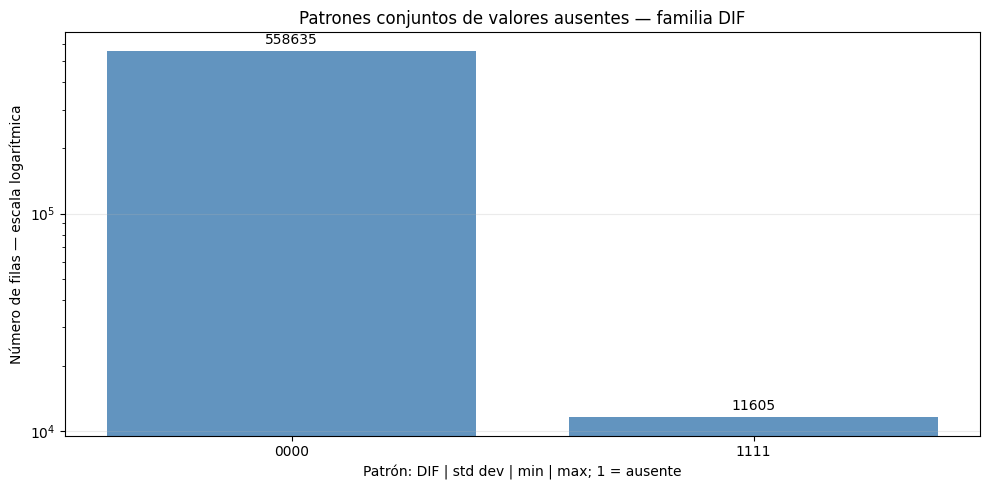

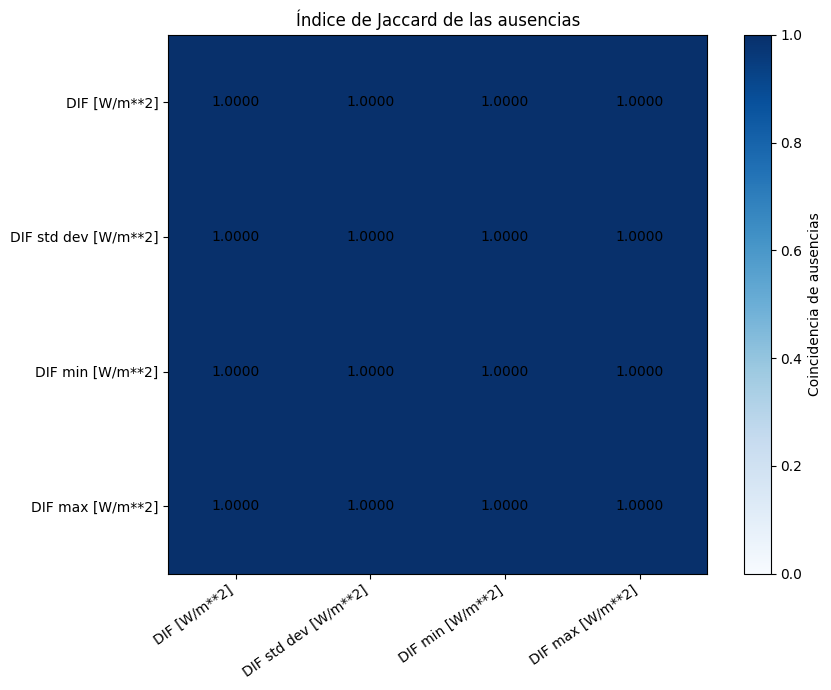

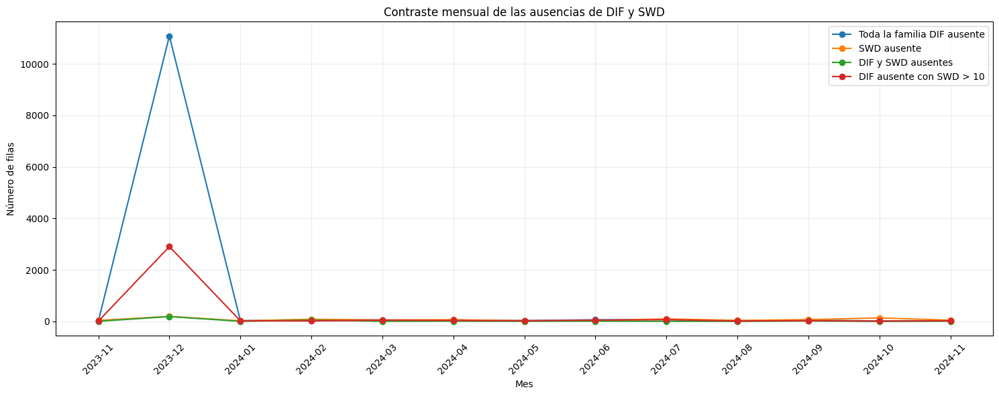

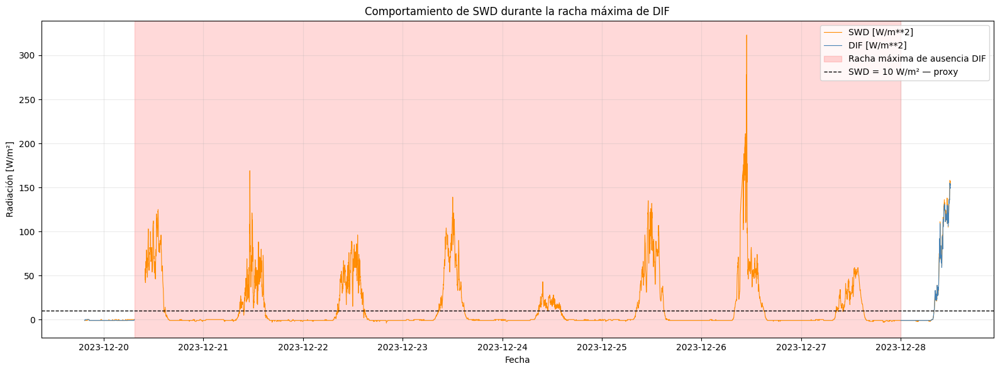

In [23]:
# 1. Patrones conjuntos de nulos
fig, eje = plt.subplots(figsize=(10, 5))
barras = eje.bar(
    patrones_conjuntos_nulos_t5["codigo_patron"],
    patrones_conjuntos_nulos_t5["n_filas"],
    color="steelblue",
    alpha=0.85,
)
eje.bar_label(barras, labels=patrones_conjuntos_nulos_t5["n_filas"].astype(str), padding=3)
if (
    patrones_conjuntos_nulos_t5["n_filas"].gt(0).all()
    and patrones_conjuntos_nulos_t5["n_filas"].max() / patrones_conjuntos_nulos_t5["n_filas"].min()
    > 20
):
    eje.set_yscale("log")
    eje.set_ylabel("Número de filas — escala logarítmica")
else:
    eje.set_ylabel("Número de filas")

eje.set_xlabel("Patrón: DIF | std dev | min | max; 1 = ausente")
eje.set_title("Patrones conjuntos de valores ausentes — familia DIF")
eje.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# 2. Coincidencia de ausencias por parejas
matriz_jaccard = pd.DataFrame(np.nan, index=COLUMNAS_DIF_T5, columns=COLUMNAS_DIF_T5)
for variable in COLUMNAS_DIF_T5:
    matriz_jaccard.loc[variable, variable] = 1.0

for _, fila in coincidencia_ausencias_parejas_t5.iterrows():
    variable_a = fila["variable_a"]
    variable_b = fila["variable_b"]
    valor = fila["jaccard_ausencias"]
    matriz_jaccard.loc[variable_a, variable_b] = valor
    matriz_jaccard.loc[variable_b, variable_a] = valor

fig, eje = plt.subplots(figsize=(9, 7))
imagen = eje.imshow(matriz_jaccard.to_numpy(dtype=float), vmin=0, vmax=1, cmap="Blues")
eje.set_xticks(np.arange(len(COLUMNAS_DIF_T5)))
eje.set_yticks(np.arange(len(COLUMNAS_DIF_T5)))
eje.set_xticklabels(COLUMNAS_DIF_T5, rotation=35, ha="right")
eje.set_yticklabels(COLUMNAS_DIF_T5)
for fila in range(len(COLUMNAS_DIF_T5)):
    for columna in range(len(COLUMNAS_DIF_T5)):
        valor = matriz_jaccard.iloc[fila, columna]
        if pd.notna(valor):
            eje.text(columna, fila, f"{valor:.4f}", ha="center", va="center", color="black")

eje.set_title("Índice de Jaccard de las ausencias")
fig.colorbar(imagen, ax=eje, label="Coincidencia de ausencias")
plt.tight_layout()
plt.show()


# 3. Evolución mensual DIF-SWD
fig, eje = plt.subplots(figsize=(15, 6))
eje.plot(
    distribucion_mensual_contraste_t5["mes"],
    distribucion_mensual_contraste_t5["n_dif_todas_ausentes"],
    marker="o",
    label="Toda la familia DIF ausente",
)
eje.plot(
    distribucion_mensual_contraste_t5["mes"],
    distribucion_mensual_contraste_t5["n_swd_ausente"],
    marker="o",
    label="SWD ausente",
)
eje.plot(
    distribucion_mensual_contraste_t5["mes"],
    distribucion_mensual_contraste_t5["n_dif_y_swd_ausentes"],
    marker="o",
    label="DIF y SWD ausentes",
)
eje.plot(
    distribucion_mensual_contraste_t5["mes"],
    distribucion_mensual_contraste_t5["n_dif_ausente_swd_gt_10"],
    marker="o",
    label="DIF ausente con SWD > 10",
)
eje.set_title("Contraste mensual de las ausencias de DIF y SWD")
eje.set_xlabel("Mes")
eje.set_ylabel("Número de filas")
eje.tick_params(axis="x", rotation=45)
eje.grid(alpha=0.25)
eje.legend()
plt.tight_layout()
plt.show()


# 4. SWD alrededor de la racha máxima de DIF
if inicio_racha_max_t5 is not None and fin_racha_max_t5 is not None:
    margen_visual = pd.Timedelta(hours=12)
    mascara_ventana = fechas_t5.ge(inicio_racha_max_t5 - margen_visual) & fechas_t5.le(
        fin_racha_max_t5 + margen_visual
    )
    ventana_t5 = df_t5.loc[mascara_ventana, [COL_FECHA_T5, COL_DIF_T5, COL_SWD_T5]]
    fig, eje = plt.subplots(figsize=(16, 6))
    eje.plot(
        ventana_t5[COL_FECHA_T5],
        ventana_t5[COL_SWD_T5],
        linewidth=0.8,
        label=COL_SWD_T5,
        color="darkorange",
    )
    eje.plot(
        ventana_t5[COL_FECHA_T5],
        ventana_t5[COL_DIF_T5],
        linewidth=0.8,
        label=COL_DIF_T5,
        color="steelblue",
    )
    eje.axvspan(
        inicio_racha_max_t5,
        fin_racha_max_t5,
        color="red",
        alpha=0.15,
        label="Racha máxima de ausencia DIF",
    )
    eje.axhline(10, color="black", linestyle="--", linewidth=1, label="SWD = 10 W/m² — proxy")
    eje.set_title("Comportamiento de SWD durante la racha máxima de DIF")
    eje.set_xlabel("Fecha")
    eje.set_ylabel("Radiación [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()
    plt.tight_layout()
    plt.show()

### 5.6 Controles

In [24]:
# 1. Controles de ejecución y reconciliación
control_fuente_intacta_t5 = df_t5.equals(df_t2.loc[:, COLUMNAS_T5].reset_index(drop=True))
control_patrones_recuperan_filas = int(patrones_conjuntos_nulos_t5["n_filas"].sum()) == len(df_t5)
control_contraste_recupera_filas = int(contraste_dif_swd_t5["n_filas"].sum()) == len(df_t5)
control_mensual_recupera_filas = int(distribucion_mensual_contraste_t5["n_filas"].sum()) == len(
    df_t5
)
control_detalle_ausencias = len(detalle_ausencias_dif_swd_t5) == int(
    mascara_toda_familia_dif_ausente_t5.sum()
)
control_recuento_por_variable = all(
    int(resumen_ausencias_conjuntas_t5.set_index("variable").loc[columna, "n_ausentes"])
    == int(df_t5[columna].isna().sum())
    for columna in COLUMNAS_DIF_T5
)
control_particion_evaluables = int(mascara_dif_completa_finita_t5.sum()) + int(
    (~mascara_dif_completa_finita_t5).sum()
) == len(df_t5)
registros_controles = [
    {
        "control": ("df_t5 coincide con la selección original de df_t2"),
        "superado": control_fuente_intacta_t5,
    },
    {
        "control": ("Los patrones conjuntos recuperan todas las filas"),
        "superado": control_patrones_recuperan_filas,
    },
    {
        "control": ("Los recuentos por variable coinciden con df_t5"),
        "superado": control_recuento_por_variable,
    },
    {
        "control": ("La tabla cruzada DIF-SWD recupera todas las filas"),
        "superado": control_contraste_recupera_filas,
    },
    {
        "control": ("La distribución mensual recupera todas las filas"),
        "superado": control_mensual_recupera_filas,
    },
    {
        "control": ("El detalle DIF-SWD recupera todas las ausencias DIF"),
        "superado": control_detalle_ausencias,
    },
    {
        "control": ("Las filas evaluables y no evaluables forman " "una partición completa"),
        "superado": control_particion_evaluables,
    },
]

# Comprobación adicional con la sección 3, si sigue en memoria
if "resumen_calidad_dif_t3" in globals():
    try:
        ausentes_t3 = resumen_calidad_dif_t3.set_index("variable")["n_ausentes"]
        coincidencia_t3 = all(
            int(df_t5[columna].isna().sum()) == int(ausentes_t3.loc[columna])
            for columna in COLUMNAS_DIF_T5
        )
        registros_controles.append(
            {"control": ("Los ausentes coinciden con la sección 3"), "superado": coincidencia_t3}
        )

    except (KeyError, TypeError, ValueError):
        print("No se ha podido contrastar automáticamente " "con resumen_calidad_dif_t3.")

controles_t5 = pd.DataFrame(registros_controles)
display(controles_t5)


# 2. Tabla compacta de hallazgos
n_todas_ausentes = int(mascara_toda_familia_dif_ausente_t5.sum())
n_ausencias_parciales = int(mascara_ausencia_parcial_t5.sum())
n_swd_ausente_durante_dif = int(
    (mascara_toda_familia_dif_ausente_t5 & categoria_swd_t5.eq("SWD ausente")).sum()
)
n_swd_gt_10_durante_dif = int(
    (mascara_toda_familia_dif_ausente_t5 & categoria_swd_t5.eq("SWD > 10")).sum()
)
n_incidencias_principales = int(mascara_incidencias_principales_t5.sum())
n_advertencias_diagnosticas = int(mascara_advertencias_diagnosticas_t5.sum())
fila_negativos_dif = resumen_negativos_swd_t5.loc[
    resumen_negativos_swd_t5["variable"].eq(COL_DIF_T5)
]
n_negativos_dif_swd_gt_10 = (
    int(fila_negativos_dif["n_negativos_swd_gt_10"].iloc[0])
    if not fila_negativos_dif.empty
    else np.nan
)
hallazgos_t5 = pd.DataFrame(
    [
        {
            "hallazgo": ("Las cuatro máscaras de ausencia son idénticas"),
            "valor": bool(resumen_ausencias_conjuntas_t5["mascara_igual_a_DIF"].all()),
            "interpretación": ("Indica si toda la familia DIF pierde datos " "simultáneamente."),
        },
        {
            "hallazgo": "Filas con ausencia parcial de DIF",
            "valor": n_ausencias_parciales,
            "interpretación": (
                "Si es cero, no hay pérdidas independientes "
                "entre media, desviación, mínimo y máximo."
            ),
        },
        {
            "hallazgo": ("Filas con toda la familia DIF ausente"),
            "valor": n_todas_ausentes,
            "interpretación": (
                "Debe coincidir con los 11.605 ausentes " "obtenidos anteriormente."
            ),
        },
        {
            "hallazgo": ("Ausencia simultánea de DIF y SWD"),
            "valor": n_swd_ausente_durante_dif,
            "interpretación": (
                "Ayuda a diferenciar un fallo específico de DIF " "de una interrupción más general."
            ),
        },
        {
            "hallazgo": ("DIF ausente mientras SWD > 10"),
            "valor": n_swd_gt_10_durante_dif,
            "interpretación": (
                "Había radiación de onda corta medible según "
                "la proxy mientras DIF no estaba disponible."
            ),
        },
        {
            "hallazgo": ("Filas con incoherencia matemática principal"),
            "valor": n_incidencias_principales,
            "interpretación": ("Incumplimientos de min ≤ DIF ≤ max, " "min ≤ max o std dev ≥ 0."),
        },
        {
            "hallazgo": ("Advertencias de coherencia cero/rango"),
            "valor": n_advertencias_diagnosticas,
            "interpretación": ("Deben revisarse considerando el redondeo " "instrumental."),
        },
        {
            "hallazgo": ("DIF negativo mientras SWD > 10"),
            "valor": n_negativos_dif_swd_gt_10,
            "interpretación": (
                "Permite separar negativos nocturnos de " "posibles incidencias diurnas."
            ),
        },
    ]
)
display(hallazgos_t5)
if controles_t5["superado"].all():
    print("Todos los controles de ejecución de la " "sección 5 se han superado.")
else:
    print("Existe algún control de ejecución no superado. " "Revísalo antes de cerrar la tarea.")

,control,superado
0,df_t5 coincide con la selección original de df_t2,True
1,Los patrones conjuntos recuperan todas las filas,True
2,Los recuentos por variable coinciden con df_t5,True
3,La tabla cruzada DIF-SWD recupera todas las filas,True
4,La distribución mensual recupera todas las filas,True
5,El detalle DIF-SWD recupera todas las ausencia...,True
6,Las filas evaluables y no evaluables forman un...,True
7,Los ausentes coinciden con la sección 3,True


,hallazgo,valor,interpretación
0,Las cuatro máscaras de ausencia son idénticas,True,Indica si toda la familia DIF pierde datos sim...
1,Filas con ausencia parcial de DIF,0,"Si es cero, no hay pérdidas independientes ent..."
2,Filas con toda la familia DIF ausente,11605,Debe coincidir con los 11.605 ausentes obtenid...
3,Ausencia simultánea de DIF y SWD,322,Ayuda a diferenciar un fallo específico de DIF...
4,DIF ausente mientras SWD > 10,3286,Había radiación de onda corta medible según la...
5,Filas con incoherencia matemática principal,0,"Incumplimientos de min ≤ DIF ≤ max, min ≤ max ..."
6,Advertencias de coherencia cero/rango,228259,Deben revisarse considerando el redondeo instr...
7,DIF negativo mientras SWD > 10,0,Permite separar negativos nocturnos de posible...


Todos los controles de ejecución de la sección 5 se han superado.


## 6. Ceros y negativos

Se comparan los ceros y los negativos en el conjunto completo, por hora y según la proxy de SWD.

### 6.1 Preparación y clasificación de los valores

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Variables de la sección 6
COL_FECHA_T6 = "Date/Time"
COL_DIF_T6 = "DIF [W/m**2]"
COL_DIF_STD_T6 = "DIF std dev [W/m**2]"
COL_DIF_MIN_T6 = "DIF min [W/m**2]"
COL_DIF_MAX_T6 = "DIF max [W/m**2]"
COL_SWD_T6 = "SWD [W/m**2]"
COLUMNAS_DIF_T6 = [COL_DIF_T6, COL_DIF_STD_T6, COL_DIF_MIN_T6, COL_DIF_MAX_T6]
COLUMNAS_T6 = [COL_FECHA_T6, *COLUMNAS_DIF_T6, COL_SWD_T6]


# 2. Comprobación de disponibilidad
if "df_t2" not in globals():
    raise NameError(
        "No se ha encontrado 'df_t2'. " "Ejecuta primero las celdas de preparación de la sección 2."
    )

columnas_ausentes_t6 = [columna for columna in COLUMNAS_T6 if columna not in df_t2.columns]
if columnas_ausentes_t6:
    raise KeyError(f"Faltan las siguientes columnas en df_t2: " f"{columnas_ausentes_t6}")


# 3. Copia independiente
# No se modifica df_t2 ni se aplica limpieza o imputación.
df_t6 = df_t2.loc[:, COLUMNAS_T6].copy().reset_index(drop=True)
fechas_t6 = pd.to_datetime(df_t6[COL_FECHA_T6], errors="coerce")
n_fechas_no_validas_t6 = int(fechas_t6.isna().sum())
if n_fechas_no_validas_t6 > 0:
    raise ValueError(
        "Se han detectado fechas no válidas en la sección 6: " f"{n_fechas_no_validas_t6}"
    )

hora_t6 = fechas_t6.dt.hour.astype("int8")


# 4. Conversión numérica en objetos auxiliares
# Los valores de df_t6 permanecen intactos.
datos_dif_numericos_t6 = df_t6[COLUMNAS_DIF_T6].apply(pd.to_numeric, errors="coerce")
swd_t6 = pd.to_numeric(df_t6[COL_SWD_T6], errors="coerce")


# 5. Máscaras de ceros, negativos y positivos
# Cero: valor registrado exactamente igual a 0.
# Negativo: valor finito estrictamente menor que 0.
# Positivo: valor finito estrictamente mayor que 0.
mascaras_estado_t6 = {}
for variable in COLUMNAS_DIF_T6:
    serie = datos_dif_numericos_t6[variable]
    vector = serie.to_numpy(dtype=float, na_value=np.nan)
    mascara_finita = pd.Series(np.isfinite(vector), index=df_t6.index)
    mascara_ausente_original = df_t6[variable].isna()
    mascara_no_finita_no_ausente = ~mascara_ausente_original & ~mascara_finita
    mascara_cero = mascara_finita & serie.eq(0).fillna(False)
    mascara_negativa = mascara_finita & serie.lt(0).fillna(False)
    mascara_positiva = mascara_finita & serie.gt(0).fillna(False)
    mascaras_estado_t6[variable] = {
        "finita": mascara_finita,
        "ausente_original": mascara_ausente_original,
        "no_finita_no_ausente": mascara_no_finita_no_ausente,
        "cero": mascara_cero,
        "negativa": mascara_negativa,
        "positiva": mascara_positiva,
    }


# 6. Categorías de SWD
# IMPORTANTE:
# SWD > 10 y SWD ≤ 10 son exclusivamente proxies
# provisionales. No constituyen una definición astronómica
# definitiva de día y noche.
CAT_SWD_GT10_T6 = "SWD > 10 W/m² — proxy provisional " "de presencia de radiación"
CAT_SWD_LE10_T6 = "SWD ≤ 10 W/m² — proxy provisional " "de radiación baja/nula"
CAT_SWD_AUSENTE_T6 = "SWD ausente"
CAT_SWD_NO_FINITA_T6 = "SWD no finita"
ORDEN_CATEGORIAS_SWD_T6 = [
    CAT_SWD_GT10_T6,
    CAT_SWD_LE10_T6,
    CAT_SWD_AUSENTE_T6,
    CAT_SWD_NO_FINITA_T6,
]
CATEGORIAS_PROXY_PRINCIPALES_T6 = [CAT_SWD_GT10_T6, CAT_SWD_LE10_T6]
vector_swd_t6 = swd_t6.to_numpy(dtype=float, na_value=np.nan)
mascara_swd_ausente_t6 = df_t6[COL_SWD_T6].isna()
mascara_swd_finita_t6 = pd.Series(np.isfinite(vector_swd_t6), index=df_t6.index)
mascara_swd_no_finita_t6 = ~mascara_swd_ausente_t6 & ~mascara_swd_finita_t6
mascara_swd_gt10_t6 = mascara_swd_finita_t6 & swd_t6.gt(10).fillna(False)
mascara_swd_le10_t6 = mascara_swd_finita_t6 & swd_t6.le(10).fillna(False)
categoria_swd_t6 = pd.Series(
    pd.NA, index=df_t6.index, dtype="object", name="categoria_swd_proxy_provisional"
)
categoria_swd_t6.loc[mascara_swd_gt10_t6] = CAT_SWD_GT10_T6
categoria_swd_t6.loc[mascara_swd_le10_t6] = CAT_SWD_LE10_T6
categoria_swd_t6.loc[mascara_swd_ausente_t6] = CAT_SWD_AUSENTE_T6
categoria_swd_t6.loc[mascara_swd_no_finita_t6] = CAT_SWD_NO_FINITA_T6
categoria_swd_t6 = pd.Series(
    pd.Categorical(categoria_swd_t6, categories=ORDEN_CATEGORIAS_SWD_T6, ordered=True),
    index=df_t6.index,
    name="categoria_swd_proxy_provisional",
)


# 7. Funciones auxiliares
def porcentaje_t6(numerador, denominador):
    return numerador / denominador * 100 if denominador > 0 else np.nan

def calcular_metricas_segmento_t6(variable, mascara_segmento):
    mascara_segmento = pd.Series(mascara_segmento, index=df_t6.index).fillna(False).astype(bool)
    mascaras = mascaras_estado_t6[variable]
    n_filas = int(mascara_segmento.sum())
    n_finitos = int((mascara_segmento & mascaras["finita"]).sum())
    n_ausentes_originales = int((mascara_segmento & mascaras["ausente_original"]).sum())
    n_no_finitos_no_ausentes = int((mascara_segmento & mascaras["no_finita_no_ausente"]).sum())
    n_no_evaluables = n_filas - n_finitos
    n_ceros = int((mascara_segmento & mascaras["cero"]).sum())
    n_negativos = int((mascara_segmento & mascaras["negativa"]).sum())
    n_positivos = int((mascara_segmento & mascaras["positiva"]).sum())
    return {
        "n_filas_segmento": n_filas,
        "n_valores_finitos": n_finitos,
        "n_ausentes_originales": n_ausentes_originales,
        "n_no_finitos_no_ausentes": n_no_finitos_no_ausentes,
        "n_no_evaluables": n_no_evaluables,
        "n_ceros": n_ceros,
        "%_ceros_sobre_finitos": porcentaje_t6(n_ceros, n_finitos),
        "n_negativos": n_negativos,
        "%_negativos_sobre_finitos": porcentaje_t6(n_negativos, n_finitos),
        "n_positivos": n_positivos,
        "%_positivos_sobre_finitos": porcentaje_t6(n_positivos, n_finitos),
    }

print("Filas analizadas:", len(df_t6))
print("Intervalo:", fechas_t6.min(), "—", fechas_t6.max())
print("La separación SWD > 10 / SWD ≤ 10 se utilizará " "solo como proxy provisional.")

Filas analizadas: 570240
Intervalo: 2023-11-01 00:00:00 — 2024-11-30 23:59:00
La separación SWD > 10 / SWD ≤ 10 se utilizará solo como proxy provisional.


### 6.2 Conjunto completo y comparación por proxy de SWD

In [26]:
# 1. Resumen global
mascara_todas_filas_t6 = pd.Series(True, index=df_t6.index)
registros_globales_t6 = []
for variable in COLUMNAS_DIF_T6:
    registro = {
        "variable": variable,
        **calcular_metricas_segmento_t6(variable, mascara_todas_filas_t6),
    }
    registros_globales_t6.append(registro)

resumen_global_ceros_negativos_t6 = pd.DataFrame(registros_globales_t6)
print("Ceros y negativos en el conjunto completo:")
display(resumen_global_ceros_negativos_t6)


# 2. Resumen por categoría SWD
# Se mantienen también SWD ausente y SWD no finita para
# asegurar que todas las filas quedan reconciliadas.
registros_proxy_t6 = []
for variable in COLUMNAS_DIF_T6:
    for categoria in ORDEN_CATEGORIAS_SWD_T6:
        mascara_categoria = categoria_swd_t6.eq(categoria)
        registro = {
            "variable": variable,
            "categoria_swd_proxy_provisional": categoria,
            **calcular_metricas_segmento_t6(variable, mascara_categoria),
        }
        registros_proxy_t6.append(registro)

resumen_por_proxy_swd_t6 = pd.DataFrame(registros_proxy_t6)
print("Resumen según la proxy provisional basada en SWD:")
display(
    resumen_por_proxy_swd_t6.loc[
        resumen_por_proxy_swd_t6["categoria_swd_proxy_provisional"].isin(
            CATEGORIAS_PROXY_PRINCIPALES_T6
        )
    ]
)


# 3. Tabla comparativa directa
# Las diferencias se calculan como:
# porcentaje con SWD > 10 menos porcentaje con SWD ≤ 10.
registros_comparacion_proxy_t6 = []
for variable in COLUMNAS_DIF_T6:
    tabla_variable = resumen_por_proxy_swd_t6.loc[resumen_por_proxy_swd_t6["variable"].eq(variable)]
    fila_gt10 = tabla_variable.loc[
        tabla_variable["categoria_swd_proxy_provisional"].eq(CAT_SWD_GT10_T6)
    ].iloc[0]
    fila_le10 = tabla_variable.loc[
        tabla_variable["categoria_swd_proxy_provisional"].eq(CAT_SWD_LE10_T6)
    ].iloc[0]
    pct_ceros_gt10 = float(fila_gt10["%_ceros_sobre_finitos"])
    pct_ceros_le10 = float(fila_le10["%_ceros_sobre_finitos"])
    pct_negativos_gt10 = float(fila_gt10["%_negativos_sobre_finitos"])
    pct_negativos_le10 = float(fila_le10["%_negativos_sobre_finitos"])
    n_ceros_proxy_finita = int(fila_gt10["n_ceros"] + fila_le10["n_ceros"])
    n_negativos_proxy_finita = int(fila_gt10["n_negativos"] + fila_le10["n_negativos"])
    registros_comparacion_proxy_t6.append(
        {
            "variable": variable,
            "n_finitos_SWD_gt_10_proxy": int(fila_gt10["n_valores_finitos"]),
            "n_ceros_SWD_gt_10_proxy": int(fila_gt10["n_ceros"]),
            "%_ceros_SWD_gt_10_proxy": pct_ceros_gt10,
            "n_negativos_SWD_gt_10_proxy": int(fila_gt10["n_negativos"]),
            "%_negativos_SWD_gt_10_proxy": pct_negativos_gt10,
            "n_finitos_SWD_le_10_proxy": int(fila_le10["n_valores_finitos"]),
            "n_ceros_SWD_le_10_proxy": int(fila_le10["n_ceros"]),
            "%_ceros_SWD_le_10_proxy": pct_ceros_le10,
            "n_negativos_SWD_le_10_proxy": int(fila_le10["n_negativos"]),
            "%_negativos_SWD_le_10_proxy": pct_negativos_le10,
            "diferencia_pp_ceros_gt10_menos_le10": pct_ceros_gt10 - pct_ceros_le10,
            "diferencia_pp_negativos_gt10_menos_le10": pct_negativos_gt10 - pct_negativos_le10,
            "razón_prevalencia_ceros_gt10_sobre_le10": (
                pct_ceros_gt10 / pct_ceros_le10
                if pd.notna(pct_ceros_le10) and pct_ceros_le10 > 0
                else np.nan
            ),
            "razón_prevalencia_negativos_gt10_sobre_le10": (
                pct_negativos_gt10 / pct_negativos_le10
                if pd.notna(pct_negativos_le10) and pct_negativos_le10 > 0
                else np.nan
            ),
            ("%_ceros_localizados_en_SWD_gt_10_" "entre_SWD_finita"): porcentaje_t6(
                int(fila_gt10["n_ceros"]), n_ceros_proxy_finita
            ),
            ("%_negativos_localizados_en_SWD_gt_10_" "entre_SWD_finita"): porcentaje_t6(
                int(fila_gt10["n_negativos"]), n_negativos_proxy_finita
            ),
        }
    )

comparacion_proxy_swd_t6 = pd.DataFrame(registros_comparacion_proxy_t6)
print("Comparación directa de las dos categorías de la " "proxy provisional:")
display(comparacion_proxy_swd_t6)

Ceros y negativos en el conjunto completo:


,variable,n_filas_segmento,n_valores_finitos,n_ausentes_originales,n_no_finitos_no_ausentes,n_no_evaluables,n_ceros,%_ceros_sobre_finitos,n_negativos,%_negativos_sobre_finitos,n_positivos,%_positivos_sobre_finitos
0,DIF [W/m**2],570240,558635,11605,0,11605,53685,9.610032,218624,39.135393,286326,51.254576
1,DIF std dev [W/m**2],570240,558635,11605,0,11605,59066,10.573272,0,0.000000,499569,89.426728
2,DIF min [W/m**2],570240,558635,11605,0,11605,33107,5.926410,240093,42.978510,285435,51.095080
3,DIF max [W/m**2],570240,558635,11605,0,11605,80463,14.403501,190840,34.161841,287332,51.434658


Resumen según la proxy provisional basada en SWD:


,variable,categoria_swd_proxy_provisional,n_filas_segmento,n_valores_finitos,n_ausentes_originales,n_no_finitos_no_ausentes,n_no_evaluables,n_ceros,%_ceros_sobre_finitos,n_negativos,%_negativos_sobre_finitos,n_positivos,%_positivos_sobre_finitos
0,DIF [W/m**2],SWD > 10 W/m² — proxy provisional de presencia...,261912,258626,3286,0,3286,0,0.000000,0,0.000000,258626,100.000000
1,DIF [W/m**2],SWD ≤ 10 W/m² — proxy provisional de radiación...,307399,299402,7997,0,7997,53685,17.930742,218624,73.020220,27093,9.049038
4,DIF std dev [W/m**2],SWD > 10 W/m² — proxy provisional de presencia...,261912,258626,3286,0,3286,422,0.163170,0,0.000000,258204,99.836830
5,DIF std dev [W/m**2],SWD ≤ 10 W/m² — proxy provisional de radiación...,307399,299402,7997,0,7997,58639,19.585374,0,0.000000,240763,80.414626
8,DIF min [W/m**2],SWD > 10 W/m² — proxy provisional de presencia...,261912,258626,3286,0,3286,0,0.000000,0,0.000000,258626,100.000000
9,DIF min [W/m**2],SWD ≤ 10 W/m² — proxy provisional de radiación...,307399,299402,7997,0,7997,33107,11.057708,240093,80.190847,26202,8.751445
12,DIF max [W/m**2],SWD > 10 W/m² — proxy provisional de presencia...,261912,258626,3286,0,3286,0,0.000000,0,0.000000,258626,100.000000
13,DIF max [W/m**2],SWD ≤ 10 W/m² — proxy provisional de radiación...,307399,299402,7997,0,7997,80463,26.874570,190840,63.740389,28099,9.385041


Comparación directa de las dos categorías de la proxy provisional:


,variable,n_finitos_SWD_gt_10_proxy,n_ceros_SWD_gt_10_proxy,%_ceros_SWD_gt_10_proxy,n_negativos_SWD_gt_10_proxy,%_negativos_SWD_gt_10_proxy,n_finitos_SWD_le_10_proxy,n_ceros_SWD_le_10_proxy,%_ceros_SWD_le_10_proxy,n_negativos_SWD_le_10_proxy,%_negativos_SWD_le_10_proxy,diferencia_pp_ceros_gt10_menos_le10,diferencia_pp_negativos_gt10_menos_le10,razón_prevalencia_ceros_gt10_sobre_le10,razón_prevalencia_negativos_gt10_sobre_le10,%_ceros_localizados_en_SWD_gt_10_entre_SWD_finita,%_negativos_localizados_en_SWD_gt_10_entre_SWD_finita
0,DIF [W/m**2],258626,0,0.00000,0,0.0,299402,53685,17.930742,218624,73.020220,-17.930742,-73.020220,0.000000,0.0,0.000000,0.0
1,DIF std dev [W/m**2],258626,422,0.16317,0,0.0,299402,58639,19.585374,0,0.000000,-19.422204,0.000000,0.008331,NaN,0.714516,NaN
2,DIF min [W/m**2],258626,0,0.00000,0,0.0,299402,33107,11.057708,240093,80.190847,-11.057708,-80.190847,0.000000,0.0,0.000000,0.0
3,DIF max [W/m**2],258626,0,0.00000,0,0.0,299402,80463,26.874570,190840,63.740389,-26.874570,-63.740389,0.000000,0.0,0.000000,0.0


### 6.3 Distribución por hora y por hora y proxy

In [27]:
# 1. Ceros y negativos por hora en el conjunto completo
registros_horarios_t6 = []
for variable in COLUMNAS_DIF_T6:
    for hora in range(24):
        mascara_hora = hora_t6.eq(hora)
        registro = {
            "variable": variable,
            "hora": hora,
            **calcular_metricas_segmento_t6(variable, mascara_hora),
        }
        registros_horarios_t6.append(registro)

resumen_horario_t6 = pd.DataFrame(registros_horarios_t6)
print("Ceros y negativos por hora:")
display(resumen_horario_t6)


# 2. Ceros y negativos por hora y categoría SWD
# Esta tabla permite comprobar si el patrón horario continúa
# existiendo dentro de cada categoría de la proxy provisional.
registros_horarios_proxy_t6 = []
for variable in COLUMNAS_DIF_T6:
    for hora in range(24):
        mascara_hora = hora_t6.eq(hora)
        for categoria in ORDEN_CATEGORIAS_SWD_T6:
            mascara_segmento = mascara_hora & categoria_swd_t6.eq(categoria)
            registro = {
                "variable": variable,
                "hora": hora,
                "categoria_swd_proxy_provisional": categoria,
                **calcular_metricas_segmento_t6(variable, mascara_segmento),
            }
            registros_horarios_proxy_t6.append(registro)

resumen_horario_proxy_t6 = pd.DataFrame(registros_horarios_proxy_t6)
print("Ceros y negativos por hora y proxy provisional:")
display(
    resumen_horario_proxy_t6.loc[
        resumen_horario_proxy_t6["categoria_swd_proxy_provisional"].isin(
            CATEGORIAS_PROXY_PRINCIPALES_T6
        )
    ]
)


# 3. Horas con mayor porcentaje
# Se selecciona la primera hora en caso de empate.
def obtener_hora_maxima_t6(variable, columna_porcentaje):
    tabla = resumen_horario_t6.loc[
        resumen_horario_t6["variable"].eq(variable) & resumen_horario_t6["n_valores_finitos"].gt(0)
    ].copy()
    tabla = tabla.dropna(subset=[columna_porcentaje])
    if tabla.empty:
        return np.nan, np.nan

    fila = tabla.sort_values([columna_porcentaje, "hora"], ascending=[False, True]).iloc[0]
    return (int(fila["hora"]), float(fila[columna_porcentaje]))

registros_hallazgos_t6 = []
comparacion_indexada_t6 = comparacion_proxy_swd_t6.set_index("variable")
for variable in COLUMNAS_DIF_T6:
    fila_global = resumen_global_ceros_negativos_t6.set_index("variable").loc[variable]
    fila_proxy = comparacion_indexada_t6.loc[variable]
    hora_max_ceros, pct_max_ceros = obtener_hora_maxima_t6(variable, "%_ceros_sobre_finitos")
    hora_max_negativos, pct_max_negativos = obtener_hora_maxima_t6(
        variable, "%_negativos_sobre_finitos"
    )
    registros_hallazgos_t6.append(
        {
            "variable": variable,
            "n_ceros_total": int(fila_global["n_ceros"]),
            "%_ceros_total_sobre_finitos": float(fila_global["%_ceros_sobre_finitos"]),
            "n_negativos_total": int(fila_global["n_negativos"]),
            "%_negativos_total_sobre_finitos": float(fila_global["%_negativos_sobre_finitos"]),
            "n_ceros_SWD_gt_10_proxy": int(fila_proxy["n_ceros_SWD_gt_10_proxy"]),
            "n_negativos_SWD_gt_10_proxy": int(fila_proxy["n_negativos_SWD_gt_10_proxy"]),
            "n_ceros_SWD_le_10_proxy": int(fila_proxy["n_ceros_SWD_le_10_proxy"]),
            "n_negativos_SWD_le_10_proxy": int(fila_proxy["n_negativos_SWD_le_10_proxy"]),
            "hora_mayor_%_ceros": hora_max_ceros,
            "máximo_%_ceros_horario": pct_max_ceros,
            "hora_mayor_%_negativos": hora_max_negativos,
            "máximo_%_negativos_horario": pct_max_negativos,
        }
    )

hallazgos_t6 = pd.DataFrame(registros_hallazgos_t6)
print("Tabla compacta de hallazgos:")
display(hallazgos_t6)


# 4. Detalle de eventos con SWD > 10
# Se exportan las filas en las que alguna variable DIF es
# cero o negativa mientras SWD > 10. Esto permite revisar
# los casos potencialmente más informativos.
matriz_dif_t6 = datos_dif_numericos_t6.to_numpy(dtype=float, na_value=np.nan)
mascara_matriz_finita_t6 = np.isfinite(matriz_dif_t6)
mascara_matriz_no_positiva_t6 = mascara_matriz_finita_t6 & (matriz_dif_t6 <= 0)
mascara_alguna_dif_no_positiva_t6 = pd.Series(
    mascara_matriz_no_positiva_t6.any(axis=1), index=df_t6.index
)
mascara_detalle_gt10_t6 = mascara_swd_gt10_t6 & mascara_alguna_dif_no_positiva_t6
detalle_eventos_swd_gt10_t6 = df_t6.loc[mascara_detalle_gt10_t6].copy()
detalle_eventos_swd_gt10_t6.insert(1, "categoria_swd_proxy_provisional", CAT_SWD_GT10_T6)
CLAVES_VARIABLES_T6 = {
    COL_DIF_T6: "DIF",
    COL_DIF_STD_T6: "DIF_std_dev",
    COL_DIF_MIN_T6: "DIF_min",
    COL_DIF_MAX_T6: "DIF_max",
}
for variable, clave in CLAVES_VARIABLES_T6.items():
    detalle_eventos_swd_gt10_t6[f"{clave}_es_cero"] = (
        mascaras_estado_t6[variable]["cero"].loc[mascara_detalle_gt10_t6].to_numpy()
    )
    detalle_eventos_swd_gt10_t6[f"{clave}_es_negativo"] = (
        mascaras_estado_t6[variable]["negativa"].loc[mascara_detalle_gt10_t6].to_numpy()
    )

print(
    "Filas con alguna variable DIF igual a cero o negativa "
    "y SWD > 10 según la proxy provisional:",
    len(detalle_eventos_swd_gt10_t6),
)
display(detalle_eventos_swd_gt10_t6.head(30))

Ceros y negativos por hora:


,variable,hora,n_filas_segmento,n_valores_finitos,n_ausentes_originales,n_no_finitos_no_ausentes,n_no_evaluables,n_ceros,%_ceros_sobre_finitos,n_negativos,%_negativos_sobre_finitos,n_positivos,%_positivos_sobre_finitos
0,DIF [W/m**2],0,23760,23340,420,0,420,3694,15.826907,19646,84.173093,0,0.000000
1,DIF [W/m**2],1,23760,23335,425,0,425,3679,15.766017,19656,84.233983,0,0.000000
2,DIF [W/m**2],2,23760,23340,420,0,420,3603,15.437018,19732,84.541560,5,0.021422
3,DIF [W/m**2],3,23760,23336,424,0,424,4357,18.670723,15876,68.032225,3103,13.297052
4,DIF [W/m**2],4,23760,23319,441,0,441,3769,16.162786,12006,51.485913,7544,32.351302
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,DIF max [W/m**2],19,23760,23280,480,0,480,5280,22.680412,12984,55.773196,5016,21.546392
92,DIF max [W/m**2],20,23760,23280,480,0,480,6098,26.194158,16665,71.585052,517,2.220790
93,DIF max [W/m**2],21,23760,23280,480,0,480,5907,25.373711,17373,74.626289,0,0.000000
94,DIF max [W/m**2],22,23760,23280,480,0,480,6037,25.932131,17243,74.067869,0,0.000000


Ceros y negativos por hora y proxy provisional:


,variable,hora,categoria_swd_proxy_provisional,n_filas_segmento,n_valores_finitos,n_ausentes_originales,n_no_finitos_no_ausentes,n_no_evaluables,n_ceros,%_ceros_sobre_finitos,n_negativos,%_negativos_sobre_finitos,n_positivos,%_positivos_sobre_finitos
0,DIF [W/m**2],0,SWD > 10 W/m² — proxy provisional de presencia...,0,0,0,0,0,0,NaN,0,NaN,0,NaN
1,DIF [W/m**2],0,SWD ≤ 10 W/m² — proxy provisional de radiación...,23760,23340,420,0,420,3694,15.826907,19646,84.173093,0,0.0
4,DIF [W/m**2],1,SWD > 10 W/m² — proxy provisional de presencia...,0,0,0,0,0,0,NaN,0,NaN,0,NaN
5,DIF [W/m**2],1,SWD ≤ 10 W/m² — proxy provisional de radiación...,23755,23335,420,0,420,3679,15.766017,19656,84.233983,0,0.0
8,DIF [W/m**2],2,SWD > 10 W/m² — proxy provisional de presencia...,0,0,0,0,0,0,NaN,0,NaN,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373,DIF max [W/m**2],21,SWD ≤ 10 W/m² — proxy provisional de radiación...,23751,23280,471,0,471,5907,25.373711,17373,74.626289,0,0.0
376,DIF max [W/m**2],22,SWD > 10 W/m² — proxy provisional de presencia...,0,0,0,0,0,0,NaN,0,NaN,0,NaN
377,DIF max [W/m**2],22,SWD ≤ 10 W/m² — proxy provisional de radiación...,23760,23280,480,0,480,6037,25.932131,17243,74.067869,0,0.0
380,DIF max [W/m**2],23,SWD > 10 W/m² — proxy provisional de presencia...,0,0,0,0,0,0,NaN,0,NaN,0,NaN


Tabla compacta de hallazgos:


,variable,n_ceros_total,%_ceros_total_sobre_finitos,n_negativos_total,%_negativos_total_sobre_finitos,n_ceros_SWD_gt_10_proxy,n_negativos_SWD_gt_10_proxy,n_ceros_SWD_le_10_proxy,n_negativos_SWD_le_10_proxy,hora_mayor_%_ceros,máximo_%_ceros_horario,hora_mayor_%_negativos,máximo_%_negativos_horario
0,DIF [W/m**2],53685,9.610032,218624,39.135393,0,0,53685,218624,3,18.670723,2,84.541560
1,DIF std dev [W/m**2],59066,10.573272,0,0.000000,422,0,58639,0,21,19.875430,0,0.000000
2,DIF min [W/m**2],33107,5.926410,240093,42.978510,0,0,33107,240093,3,12.868529,21,92.817869
3,DIF max [W/m**2],80463,14.403501,190840,34.161841,0,0,80463,190840,3,27.108330,1,75.718877


Filas con alguna variable DIF igual a cero o negativa y SWD > 10 según la proxy provisional: 422


,Date/Time,categoria_swd_proxy_provisional,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],SWD [W/m**2],DIF_es_cero,DIF_es_negativo,DIF_std_dev_es_cero,DIF_std_dev_es_negativo,DIF_min_es_cero,DIF_min_es_negativo,DIF_max_es_cero,DIF_max_es_negativo
3818,2023-11-03 15:38:00,SWD > 10 W/m² — proxy provisional de presencia...,23.0,0.0,23.0,23.0,32.0,False,False,True,False,False,False,False,False
6464,2023-11-05 11:44:00,SWD > 10 W/m² — proxy provisional de presencia...,97.0,0.0,97.0,97.0,97.0,False,False,True,False,False,False,False,False
7648,2023-11-06 07:28:00,SWD > 10 W/m² — proxy provisional de presencia...,32.0,0.0,31.0,32.0,57.0,False,False,True,False,False,False,False,False
9213,2023-11-07 09:33:00,SWD > 10 W/m² — proxy provisional de presencia...,70.0,0.0,70.0,70.0,280.0,False,False,True,False,False,False,False,False
9254,2023-11-07 10:14:00,SWD > 10 W/m² — proxy provisional de presencia...,72.0,0.0,72.0,72.0,324.0,False,False,True,False,False,False,False,False
10532,2023-11-08 07:32:00,SWD > 10 W/m² — proxy provisional de presencia...,52.0,0.0,52.0,52.0,86.0,False,False,True,False,False,False,False,False
10775,2023-11-08 11:35:00,SWD > 10 W/m² — proxy provisional de presencia...,223.0,0.0,223.0,223.0,223.0,False,False,True,False,False,False,False,False
15317,2023-11-11 15:17:00,SWD > 10 W/m² — proxy provisional de presencia...,29.0,0.0,29.0,29.0,52.0,False,False,True,False,False,False,False,False
15333,2023-11-11 15:33:00,SWD > 10 W/m² — proxy provisional de presencia...,20.0,0.0,19.0,20.0,30.0,False,False,True,False,False,False,False,False
19569,2023-11-14 14:09:00,SWD > 10 W/m² — proxy provisional de presencia...,14.0,0.0,13.0,14.0,13.0,False,False,True,False,False,False,False,False


### 6.4 Visualizaciones

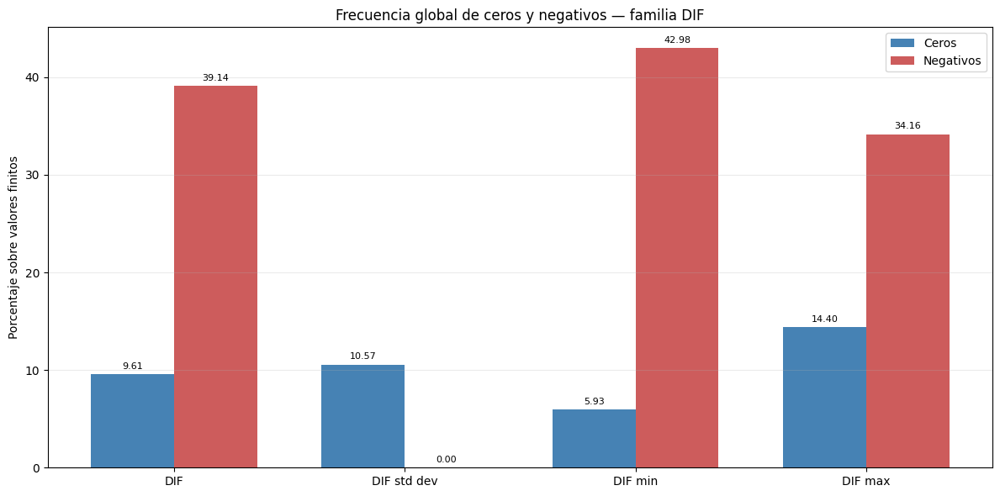

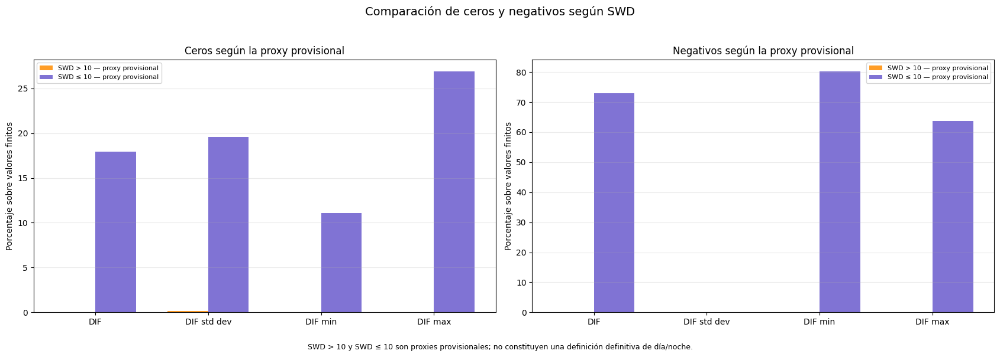

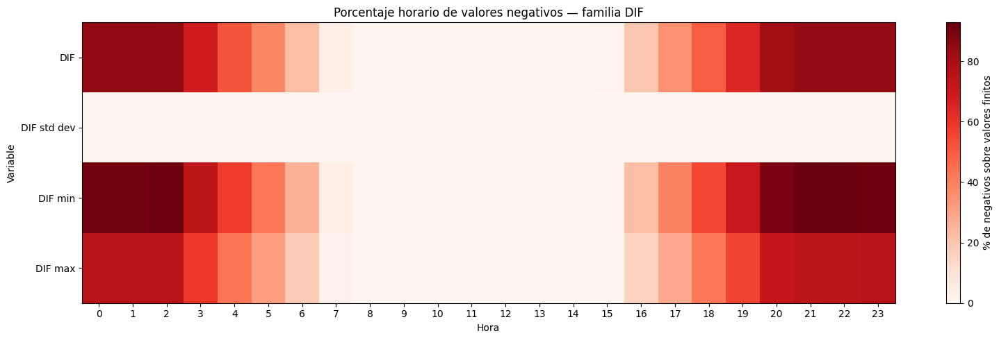

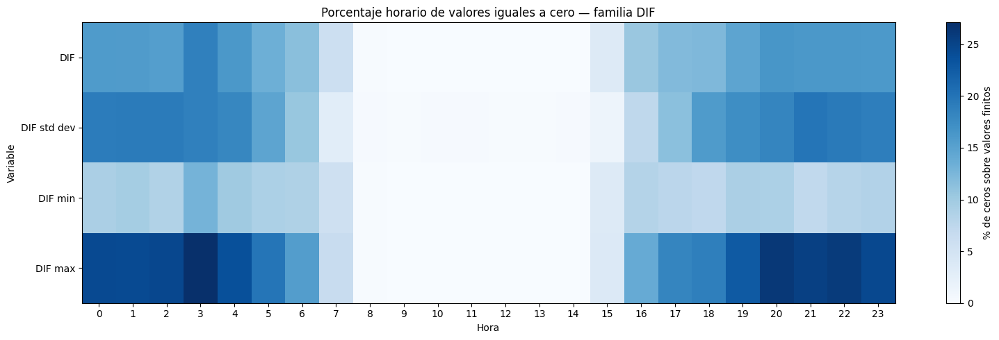

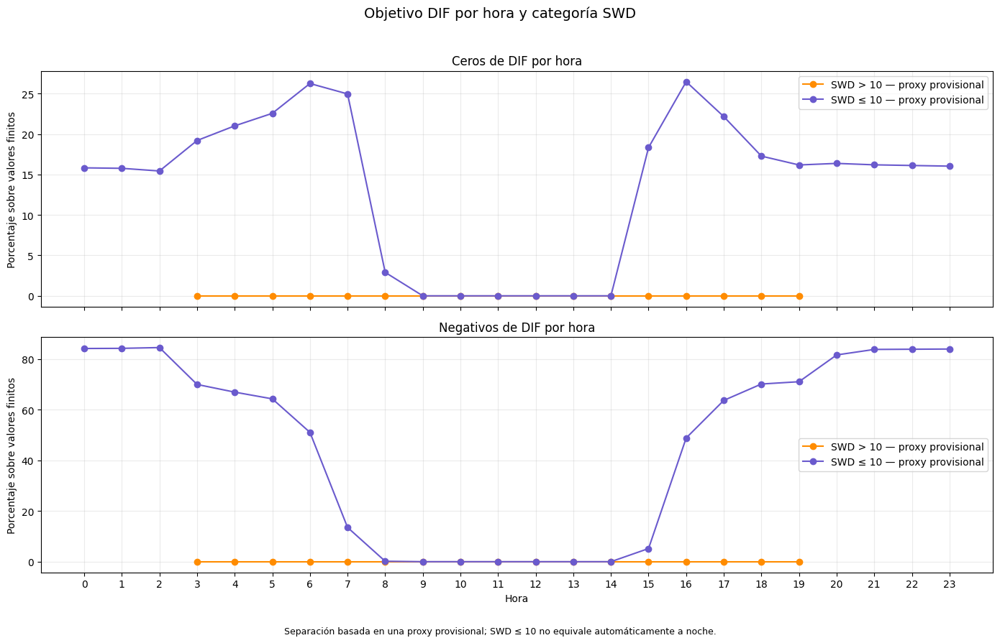

In [28]:
# 1. Preparación
carpeta_resultados_t6 = Path("tarea_6_resultados")
carpeta_resultados_t6.mkdir(exist_ok=True)
rutas_graficas_t6 = []
NOMBRES_CORTOS_T6 = {
    COL_DIF_T6: "DIF",
    COL_DIF_STD_T6: "DIF std dev",
    COL_DIF_MIN_T6: "DIF min",
    COL_DIF_MAX_T6: "DIF max",
}
ETIQUETAS_CORTAS_PROXY_T6 = {
    CAT_SWD_GT10_T6: "SWD > 10 — proxy provisional",
    CAT_SWD_LE10_T6: "SWD ≤ 10 — proxy provisional",
}


# 2. Gráfica 1 — Comparación global
tabla_grafico_global_t6 = resumen_global_ceros_negativos_t6.set_index("variable").reindex(
    COLUMNAS_DIF_T6
)
posiciones = np.arange(len(COLUMNAS_DIF_T6))
ancho = 0.36
fig, eje = plt.subplots(figsize=(12, 6))
barras_ceros = eje.bar(
    posiciones - ancho / 2,
    tabla_grafico_global_t6["%_ceros_sobre_finitos"],
    width=ancho,
    label="Ceros",
    color="steelblue",
)
barras_negativos = eje.bar(
    posiciones + ancho / 2,
    tabla_grafico_global_t6["%_negativos_sobre_finitos"],
    width=ancho,
    label="Negativos",
    color="indianred",
)
eje.bar_label(barras_ceros, fmt="%.2f", padding=3, fontsize=8)
eje.bar_label(barras_negativos, fmt="%.2f", padding=3, fontsize=8)
eje.set_xticks(posiciones)
eje.set_xticklabels([NOMBRES_CORTOS_T6[variable] for variable in COLUMNAS_DIF_T6])
eje.set_ylabel("Porcentaje sobre valores finitos")
eje.set_title("Frecuencia global de ceros y negativos — familia DIF")
eje.grid(axis="y", alpha=0.25)
eje.legend()
plt.tight_layout()
ruta_grafica_1_t6 = carpeta_resultados_t6 / "grafica_01_comparacion_global.png"
fig.savefig(ruta_grafica_1_t6, dpi=180, bbox_inches="tight")
rutas_graficas_t6.append(ruta_grafica_1_t6)
plt.show()


# 3. Gráfica 2 — Comparación por proxy provisional
tabla_proxy_principal_t6 = resumen_por_proxy_swd_t6.loc[
    resumen_por_proxy_swd_t6["categoria_swd_proxy_provisional"].isin(
        CATEGORIAS_PROXY_PRINCIPALES_T6
    )
]
fig, ejes = plt.subplots(nrows=1, ncols=2, figsize=(17, 6), sharex=True)
configuraciones = [
    ("%_ceros_sobre_finitos", "Ceros", "steelblue"),
    ("%_negativos_sobre_finitos", "Negativos", "indianred"),
]
colores_proxy = {CAT_SWD_GT10_T6: "darkorange", CAT_SWD_LE10_T6: "slateblue"}
for eje, (columna_porcentaje, nombre_evento, _) in zip(ejes, configuraciones):
    for indice_categoria, categoria in enumerate(CATEGORIAS_PROXY_PRINCIPALES_T6):
        valores = (
            tabla_proxy_principal_t6.loc[
                tabla_proxy_principal_t6["categoria_swd_proxy_provisional"].eq(categoria)
            ]
            .set_index("variable")
            .reindex(COLUMNAS_DIF_T6)[columna_porcentaje]
        )
        desplazamiento = (indice_categoria - 0.5) * ancho
        eje.bar(
            posiciones + desplazamiento,
            valores,
            width=ancho,
            label=ETIQUETAS_CORTAS_PROXY_T6[categoria],
            color=colores_proxy[categoria],
            alpha=0.85,
        )

    eje.set_xticks(posiciones)
    eje.set_xticklabels([NOMBRES_CORTOS_T6[variable] for variable in COLUMNAS_DIF_T6])
    eje.set_title(f"{nombre_evento} según la proxy provisional")
    eje.set_ylabel("Porcentaje sobre valores finitos")
    eje.grid(axis="y", alpha=0.25)
    eje.legend(fontsize=8)

fig.suptitle("Comparación de ceros y negativos según SWD", fontsize=14)
fig.text(
    0.5,
    0.01,
    (
        "SWD > 10 y SWD ≤ 10 son proxies provisionales; "
        "no constituyen una definición definitiva de día/noche."
    ),
    ha="center",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
ruta_grafica_2_t6 = carpeta_resultados_t6 / "grafica_02_comparacion_proxy_swd.png"
fig.savefig(ruta_grafica_2_t6, dpi=180, bbox_inches="tight")
rutas_graficas_t6.append(ruta_grafica_2_t6)
plt.show()


# 4. Función para mapas horarios
def graficar_mapa_horario_t6(columna_porcentaje, titulo, etiqueta_color, nombre_archivo, cmap):
    tabla_mapa = resumen_horario_t6.pivot(
        index="variable", columns="hora", values=columna_porcentaje
    ).reindex(index=COLUMNAS_DIF_T6, columns=range(24))
    matriz = tabla_mapa.to_numpy(dtype=float)
    valores_validos = matriz[np.isfinite(matriz)]
    vmax = max(1.0, float(valores_validos.max())) if valores_validos.size > 0 else 1.0
    fig, eje = plt.subplots(figsize=(16, 5))
    imagen = eje.imshow(matriz, aspect="auto", cmap=cmap, vmin=0, vmax=vmax)
    eje.set_xticks(np.arange(24))
    eje.set_xticklabels(range(24))
    eje.set_yticks(np.arange(len(COLUMNAS_DIF_T6)))
    eje.set_yticklabels([NOMBRES_CORTOS_T6[variable] for variable in COLUMNAS_DIF_T6])
    eje.set_xlabel("Hora")
    eje.set_ylabel("Variable")
    eje.set_title(titulo)
    fig.colorbar(imagen, ax=eje, label=etiqueta_color)
    plt.tight_layout()
    ruta = carpeta_resultados_t6 / nombre_archivo
    fig.savefig(ruta, dpi=180, bbox_inches="tight")
    rutas_graficas_t6.append(ruta)
    plt.show()


# 5. Gráfica 3 — Negativos por hora
graficar_mapa_horario_t6(
    columna_porcentaje=("%_negativos_sobre_finitos"),
    titulo=("Porcentaje horario de valores negativos " "— familia DIF"),
    etiqueta_color=("% de negativos sobre valores finitos"),
    nombre_archivo=("grafica_03_negativos_por_hora.png"),
    cmap="Reds",
)


# 6. Gráfica 4 — Ceros por hora
graficar_mapa_horario_t6(
    columna_porcentaje=("%_ceros_sobre_finitos"),
    titulo=("Porcentaje horario de valores iguales a cero " "— familia DIF"),
    etiqueta_color=("% de ceros sobre valores finitos"),
    nombre_archivo=("grafica_04_ceros_por_hora.png"),
    cmap="Blues",
)


# 7. Gráfica 5 — Objetivo DIF por hora y proxy
tabla_objetivo_hora_proxy_t6 = resumen_horario_proxy_t6.loc[
    resumen_horario_proxy_t6["variable"].eq(COL_DIF_T6)
    & resumen_horario_proxy_t6["categoria_swd_proxy_provisional"].isin(
        CATEGORIAS_PROXY_PRINCIPALES_T6
    )
]
fig, ejes = plt.subplots(nrows=2, ncols=1, figsize=(14, 9), sharex=True)
configuracion_objetivo = [
    ("%_ceros_sobre_finitos", "Ceros de DIF por hora"),
    ("%_negativos_sobre_finitos", "Negativos de DIF por hora"),
]
for eje, (columna_porcentaje, titulo) in zip(ejes, configuracion_objetivo):
    for categoria in CATEGORIAS_PROXY_PRINCIPALES_T6:
        tabla_linea = tabla_objetivo_hora_proxy_t6.loc[
            tabla_objetivo_hora_proxy_t6["categoria_swd_proxy_provisional"].eq(categoria)
        ].sort_values("hora")
        eje.plot(
            tabla_linea["hora"],
            tabla_linea[columna_porcentaje],
            marker="o",
            linewidth=1.5,
            label=ETIQUETAS_CORTAS_PROXY_T6[categoria],
            color=colores_proxy[categoria],
        )

    eje.set_ylabel("Porcentaje sobre valores finitos")
    eje.set_title(titulo)
    eje.grid(alpha=0.25)
    eje.legend()

ejes[-1].set_xlabel("Hora")
ejes[-1].set_xticks(range(24))
fig.suptitle("Objetivo DIF por hora y categoría SWD", fontsize=14)
fig.text(
    0.5,
    0.01,
    (
        "Separación basada en una proxy provisional; "
        "SWD ≤ 10 no equivale automáticamente a noche."
    ),
    ha="center",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
ruta_grafica_5_t6 = carpeta_resultados_t6 / "grafica_05_dif_hora_proxy_swd.png"
fig.savefig(ruta_grafica_5_t6, dpi=180, bbox_inches="tight")
rutas_graficas_t6.append(ruta_grafica_5_t6)
plt.show()

### 6.5 Controles de conciliación

In [29]:
# 1. Función de reconciliación con el resumen global
COLUMNAS_RECONCILIACION_T6 = [
    "n_filas_segmento",
    "n_valores_finitos",
    "n_ausentes_originales",
    "n_no_finitos_no_ausentes",
    "n_no_evaluables",
    "n_ceros",
    "n_negativos",
    "n_positivos",
]

def tabla_reconcilia_con_global_t6(tabla):
    global_indexado = resumen_global_ceros_negativos_t6.set_index("variable")
    for variable in COLUMNAS_DIF_T6:
        tabla_variable = tabla.loc[tabla["variable"].eq(variable)]
        fila_global = global_indexado.loc[variable]
        for columna in COLUMNAS_RECONCILIACION_T6:
            if int(tabla_variable[columna].sum()) != int(fila_global[columna]):
                return False

    return True


# 2. Controles principales
control_fuente_intacta_t6 = df_t6.equals(df_t2.loc[:, COLUMNAS_T6].reset_index(drop=True))
control_fechas_validas_t6 = fechas_t6.notna().all()
control_categorias_swd_completas_t6 = categoria_swd_t6.notna().all()
control_particion_global_t6 = all(
    (int(fila["n_valores_finitos"]) + int(fila["n_no_evaluables"]) == len(df_t6))
    and (
        int(fila["n_ceros"]) + int(fila["n_negativos"]) + int(fila["n_positivos"])
        == int(fila["n_valores_finitos"])
    )
    for _, fila in resumen_global_ceros_negativos_t6.iterrows()
)
control_proxy_recupera_global_t6 = tabla_reconcilia_con_global_t6(resumen_por_proxy_swd_t6)
control_horas_recuperan_global_t6 = tabla_reconcilia_con_global_t6(resumen_horario_t6)
control_hora_proxy_recupera_global_t6 = tabla_reconcilia_con_global_t6(resumen_horario_proxy_t6)
control_particion_swd_finita_t6 = int(mascara_swd_gt10_t6.sum()) + int(
    mascara_swd_le10_t6.sum()
) == int(mascara_swd_finita_t6.sum())
registros_controles_t6 = [
    {
        "control": ("df_t6 coincide con la selección original de df_t2"),
        "superado": bool(control_fuente_intacta_t6),
    },
    {"control": "Todas las fechas son válidas", "superado": bool(control_fechas_validas_t6)},
    {
        "control": ("Todas las filas tienen una categoría SWD"),
        "superado": bool(control_categorias_swd_completas_t6),
    },
    {
        "control": ("Ceros, negativos y positivos forman una " "partición de los valores finitos"),
        "superado": bool(control_particion_global_t6),
    },
    {
        "control": ("SWD > 10 y SWD ≤ 10 recuperan todos los " "valores finitos de SWD"),
        "superado": bool(control_particion_swd_finita_t6),
    },
    {
        "control": ("Las categorías SWD recuperan el resumen global"),
        "superado": bool(control_proxy_recupera_global_t6),
    },
    {
        "control": ("Las 24 horas recuperan el resumen global"),
        "superado": bool(control_horas_recuperan_global_t6),
    },
    {
        "control": ("Hora y categoría SWD recuperan el resumen global"),
        "superado": bool(control_hora_proxy_recupera_global_t6),
    },
]


# 3. Reconciliación opcional con la sección 5
if "resumen_negativos_swd_t5" in globals():
    columnas_t5_necesarias = {
        "variable",
        "n_negativos",
        "n_negativos_swd_le_10",
        "n_negativos_swd_gt_10",
    }
    if columnas_t5_necesarias.issubset(resumen_negativos_swd_t5.columns):
        resumen_t5_indexado = resumen_negativos_swd_t5.set_index("variable")
        resumen_t6_indexado = comparacion_proxy_swd_t6.set_index("variable")
        global_t6_indexado = resumen_global_ceros_negativos_t6.set_index("variable")
        coincidencia_negativos_t5_t6 = all(
            (
                int(resumen_t5_indexado.loc[variable, "n_negativos"])
                == int(global_t6_indexado.loc[variable, "n_negativos"])
            )
            and (
                int(resumen_t5_indexado.loc[variable, "n_negativos_swd_gt_10"])
                == int(resumen_t6_indexado.loc[variable, "n_negativos_SWD_gt_10_proxy"])
            )
            and (
                int(resumen_t5_indexado.loc[variable, "n_negativos_swd_le_10"])
                == int(resumen_t6_indexado.loc[variable, "n_negativos_SWD_le_10_proxy"])
            )
            for variable in COLUMNAS_DIF_T6
        )
        registros_controles_t6.append(
            {
                "control": ("Los negativos coinciden con la sección 5"),
                "superado": bool(coincidencia_negativos_t5_t6),
            }
        )

    else:
        print(
            "Se ha encontrado resumen_negativos_swd_t5, "
            "pero no contiene todas las columnas necesarias "
            "para la reconciliación automática."
        )


# 4. Resultado de los controles
controles_t6 = pd.DataFrame(registros_controles_t6)
display(controles_t6)
if controles_t6["superado"].all():
    print("Todos los controles de ejecución de la " "sección 6 se han superado.")
else:
    print("Existe algún control no superado. " "No cierres la tarea hasta revisarlo.")

,control,superado
0,df_t6 coincide con la selección original de df_t2,True
1,Todas las fechas son válidas,True
2,Todas las filas tienen una categoría SWD,True
3,"Ceros, negativos y positivos forman una partic...",True
4,SWD > 10 y SWD ≤ 10 recuperan todos los valore...,True
5,Las categorías SWD recuperan el resumen global,True
6,Las 24 horas recuperan el resumen global,True
7,Hora y categoría SWD recuperan el resumen global,True
8,Los negativos coinciden con la sección 5,True


Todos los controles de ejecución de la sección 6 se han superado.


## 7. Variabilidad intraminutal y valores extremos

Se caracterizan la desviación típica intraminutal y el rango `DIF max − DIF min`, su relación y los valores extremos.

### 7.1 Preparación

In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Comprobar que existe el dataframe de trabajo
if "df_t2" not in globals():
    raise NameError(
        "No existe df_t2. Ejecuta primero las celdas de carga " "y preparación de la sección 2."
    )


# 2. Columnas
COL_FECHA_T7 = "Date/Time"
COL_DIF_T7 = "DIF [W/m**2]"
COL_DIF_STD_T7 = "DIF std dev [W/m**2]"
COL_DIF_MIN_T7 = "DIF min [W/m**2]"
COL_DIF_MAX_T7 = "DIF max [W/m**2]"
COL_SWD_T7 = "SWD [W/m**2]"
COL_RANGO_T7 = "Rango DIF max menos DIF min [W/m**2]"
COLUMNAS_DIF_T7 = [COL_DIF_T7, COL_DIF_STD_T7, COL_DIF_MIN_T7, COL_DIF_MAX_T7]
COLUMNAS_NECESARIAS_T7 = [COL_FECHA_T7, *COLUMNAS_DIF_T7, COL_SWD_T7]
columnas_ausentes_t7 = [
    columna for columna in COLUMNAS_NECESARIAS_T7 if columna not in df_t2.columns
]
if columnas_ausentes_t7:
    raise KeyError("Faltan columnas necesarias para la sección 7: " f"{columnas_ausentes_t7}")


# 3. Copia independiente
df_t7 = df_t2.loc[:, COLUMNAS_NECESARIAS_T7].copy(deep=True).reset_index(drop=True)
fechas_t7 = pd.to_datetime(df_t7[COL_FECHA_T7], errors="coerce")
datos_dif_numericos_t7 = df_t7[COLUMNAS_DIF_T7].apply(pd.to_numeric, errors="coerce")
swd_numerica_t7 = pd.to_numeric(df_t7[COL_SWD_T7], errors="coerce")


# 4. Función para detectar valores finitos
def mascara_finita_t7(serie):
    valores = serie.to_numpy(dtype=float, na_value=np.nan)
    return pd.Series(np.isfinite(valores), index=serie.index)

mascaras_finitas_dif_t7 = {
    columna: mascara_finita_t7(datos_dif_numericos_t7[columna]) for columna in COLUMNAS_DIF_T7
}


# 5. Rango intraminuto DIF max − DIF min
dif_min_array_t7 = datos_dif_numericos_t7[COL_DIF_MIN_T7].to_numpy(dtype=float, na_value=np.nan)
dif_max_array_t7 = datos_dif_numericos_t7[COL_DIF_MAX_T7].to_numpy(dtype=float, na_value=np.nan)
mascara_extremos_finitos_t7 = np.isfinite(dif_min_array_t7) & np.isfinite(dif_max_array_t7)
rango_dif_array_t7 = np.full(len(df_t7), np.nan, dtype=float)
rango_dif_array_t7[mascara_extremos_finitos_t7] = (
    dif_max_array_t7[mascara_extremos_finitos_t7] - dif_min_array_t7[mascara_extremos_finitos_t7]
)
rango_dif_t7 = pd.Series(rango_dif_array_t7, index=df_t7.index, name=COL_RANGO_T7)


# 6. Proxy provisional basada en SWD
CAT_SWD_GT10_T7 = "SWD > 10 — proxy provisional"
CAT_SWD_LE10_T7 = "SWD ≤ 10 — proxy provisional"
CAT_SWD_AUSENTE_T7 = "SWD ausente"
CAT_SWD_NO_FINITA_T7 = "SWD no finita"
ORDEN_CATEGORIAS_SWD_T7 = [
    CAT_SWD_GT10_T7,
    CAT_SWD_LE10_T7,
    CAT_SWD_AUSENTE_T7,
    CAT_SWD_NO_FINITA_T7,
]
mascara_swd_ausente_t7 = df_t7[COL_SWD_T7].isna()
mascara_swd_finita_t7 = mascara_finita_t7(swd_numerica_t7)
categoria_swd_t7 = pd.Series(CAT_SWD_NO_FINITA_T7, index=df_t7.index, dtype="object")
categoria_swd_t7.loc[mascara_swd_ausente_t7] = CAT_SWD_AUSENTE_T7
categoria_swd_t7.loc[mascara_swd_finita_t7 & swd_numerica_t7.gt(10)] = CAT_SWD_GT10_T7
categoria_swd_t7.loc[mascara_swd_finita_t7 & swd_numerica_t7.le(10)] = CAT_SWD_LE10_T7
categoria_swd_t7 = pd.Series(
    pd.Categorical(categoria_swd_t7, categories=ORDEN_CATEGORIAS_SWD_T7, ordered=True),
    index=df_t7.index,
    name="categoria_swd_proxy_provisional",
)


# 7. Tabla analítica derivada
analisis_t7 = pd.DataFrame(
    {
        COL_FECHA_T7: fechas_t7,
        COL_DIF_T7: datos_dif_numericos_t7[COL_DIF_T7],
        COL_DIF_STD_T7: datos_dif_numericos_t7[COL_DIF_STD_T7],
        COL_DIF_MIN_T7: datos_dif_numericos_t7[COL_DIF_MIN_T7],
        COL_DIF_MAX_T7: datos_dif_numericos_t7[COL_DIF_MAX_T7],
        COL_RANGO_T7: rango_dif_t7,
        COL_SWD_T7: swd_numerica_t7,
        "categoria_swd_proxy_provisional": categoria_swd_t7,
    }
)
print("Filas analizadas:", len(analisis_t7))
print("Intervalo:", fechas_t7.min(), "—", fechas_t7.max())
print("La separación mediante SWD se mantiene únicamente " "como proxy provisional.")

Filas analizadas: 570240
Intervalo: 2023-11-01 00:00:00 — 2024-11-30 23:59:00
La separación mediante SWD se mantiene únicamente como proxy provisional.


### 7.2 Distribuciones globales y por proxy

In [31]:
def porcentaje_t7(numerador, denominador):
    if denominador == 0:
        return np.nan

    return 100.0 * numerador / denominador

def resumir_metrica_t7(nombre_metrica, serie, mascara_segmento=None, nombre_segmento="Global"):
    if mascara_segmento is None:
        mascara_segmento = pd.Series(True, index=serie.index)

    mascara_segmento = mascara_segmento.fillna(False).astype(bool)
    valores_array = serie.to_numpy(dtype=float, na_value=np.nan)
    mascara_segmento_array = mascara_segmento.to_numpy(dtype=bool)
    mascara_finita_array = mascara_segmento_array & np.isfinite(valores_array)
    valores_finitos = valores_array[mascara_finita_array]
    n_filas = int(mascara_segmento_array.sum())
    n_finitos = int(mascara_finita_array.sum())
    n_no_evaluables = n_filas - n_finitos
    if n_finitos == 0:
        cuantiles = {
            0.01: np.nan,
            0.05: np.nan,
            0.25: np.nan,
            0.50: np.nan,
            0.75: np.nan,
            0.95: np.nan,
            0.99: np.nan,
            0.995: np.nan,
        }
        minimo = np.nan
        maximo = np.nan
        media = np.nan
        desviacion = np.nan

    else:
        serie_finita = pd.Series(valores_finitos)
        cuantiles = serie_finita.quantile(
            [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.995]
        ).to_dict()
        minimo = float(valores_finitos.min())
        maximo = float(valores_finitos.max())
        media = float(valores_finitos.mean())
        desviacion = float(valores_finitos.std(ddof=1))

    n_ceros = int((valores_finitos == 0).sum())
    n_negativos = int((valores_finitos < 0).sum())
    n_positivos = int((valores_finitos > 0).sum())
    return {
        "metrica": nombre_metrica,
        "segmento": nombre_segmento,
        "n_filas_segmento": n_filas,
        "n_valores_finitos": n_finitos,
        "n_no_evaluables": n_no_evaluables,
        "n_ceros": n_ceros,
        "%_ceros_sobre_finitos": porcentaje_t7(n_ceros, n_finitos),
        "n_negativos": n_negativos,
        "%_negativos_sobre_finitos": porcentaje_t7(n_negativos, n_finitos),
        "n_positivos": n_positivos,
        "minimo": minimo,
        "p01": cuantiles[0.01],
        "p05": cuantiles[0.05],
        "p25": cuantiles[0.25],
        "mediana": cuantiles[0.50],
        "p75": cuantiles[0.75],
        "p95": cuantiles[0.95],
        "p99": cuantiles[0.99],
        "p99_5": cuantiles[0.995],
        "maximo": maximo,
        "media": media,
        "desviacion_estandar_muestral": desviacion,
    }

METRICAS_VARIABILIDAD_T7 = {
    "DIF std dev": analisis_t7[COL_DIF_STD_T7],
    "Rango DIF max − DIF min": analisis_t7[COL_RANGO_T7],
}


# 1. Resumen global
resumen_global_variabilidad_t7 = pd.DataFrame(
    [
        resumir_metrica_t7(nombre_metrica, serie)
        for nombre_metrica, serie in METRICAS_VARIABILIDAD_T7.items()
    ]
)
print("Distribuciones globales:")
display(resumen_global_variabilidad_t7)


# 2. Resumen por proxy provisional
registros_proxy_t7 = []
for nombre_metrica, serie in METRICAS_VARIABILIDAD_T7.items():
    for categoria in ORDEN_CATEGORIAS_SWD_T7:
        mascara_categoria = categoria_swd_t7.eq(categoria)
        registros_proxy_t7.append(
            resumir_metrica_t7(
                nombre_metrica, serie, mascara_segmento=mascara_categoria, nombre_segmento=categoria
            )
        )

resumen_variabilidad_proxy_t7 = pd.DataFrame(registros_proxy_t7)
print("Distribuciones según la proxy provisional:")
display(
    resumen_variabilidad_proxy_t7.loc[
        resumen_variabilidad_proxy_t7["segmento"].isin([CAT_SWD_GT10_T7, CAT_SWD_LE10_T7])
    ]
)

Distribuciones globales:


,metrica,segmento,n_filas_segmento,n_valores_finitos,n_no_evaluables,n_ceros,%_ceros_sobre_finitos,n_negativos,%_negativos_sobre_finitos,n_positivos,...,p05,p25,mediana,p75,p95,p99,p99_5,maximo,media,desviacion_estandar_muestral
0,DIF std dev,Global,570240,558635,11605,59066,10.573272,0,0.0,499569,...,0.0,0.1,0.1,0.6,5.1,12.9,17.1,121.9,1.000157,2.66034
1,Rango DIF max − DIF min,Global,570240,558635,11605,260261,46.588739,0,0.0,298374,...,0.0,0.0,1.0,2.0,17.0,42.0,55.0,328.0,3.271959,8.57384


Distribuciones según la proxy provisional:


,metrica,segmento,n_filas_segmento,n_valores_finitos,n_no_evaluables,n_ceros,%_ceros_sobre_finitos,n_negativos,%_negativos_sobre_finitos,n_positivos,...,p05,p25,mediana,p75,p95,p99,p99_5,maximo,media,desviacion_estandar_muestral
0,DIF std dev,SWD > 10 — proxy provisional,261912,258626,3286,422,0.163170,0,0.0,258204,...,0.1,0.2,0.7,2.3,8.5,17.5,22.0875,121.9,2.057798,3.629384
1,DIF std dev,SWD ≤ 10 — proxy provisional,307399,299402,7997,58639,19.585374,0,0.0,240763,...,0.0,0.1,0.1,0.1,0.1,0.2,0.3000,1.8,0.084828,0.055279
4,Rango DIF max − DIF min,SWD > 10 — proxy provisional,261912,258626,3286,30923,11.956648,0,0.0,227703,...,0.0,1.0,3.0,8.0,28.0,56.0,70.0000,328.0,6.777903,11.634688
5,Rango DIF max − DIF min,SWD ≤ 10 — proxy provisional,307399,299402,7997,229250,76.569295,0,0.0,70152,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0000,6.0,0.237714,0.436063


### 7.3 Relación entre la desviación típica y el rango

In [32]:
std_array_t7 = analisis_t7[COL_DIF_STD_T7].to_numpy(dtype=float, na_value=np.nan)
rango_array_t7 = analisis_t7[COL_RANGO_T7].to_numpy(dtype=float, na_value=np.nan)
mascara_std_finita_t7 = np.isfinite(std_array_t7)
mascara_rango_finito_t7 = np.isfinite(rango_array_t7)
mascara_comparable_t7 = mascara_std_finita_t7 & mascara_rango_finito_t7
std_comparable_t7 = std_array_t7[mascara_comparable_t7]
rango_comparable_t7 = rango_array_t7[mascara_comparable_t7]
n_comparables_t7 = len(std_comparable_t7)
TOLERANCIA_T7 = 1e-9

def crear_diagnostico_t7(diagnostico, mascara_evento, denominador):
    n_eventos = int(np.asarray(mascara_evento).sum())
    return {
        "diagnostico": diagnostico,
        "n_eventos": n_eventos,
        "denominador": int(denominador),
        "porcentaje": porcentaje_t7(n_eventos, denominador),
    }

diagnosticos_t7 = [
    crear_diagnostico_t7(
        "DIF std dev negativa",
        std_array_t7[mascara_std_finita_t7] < 0,
        int(mascara_std_finita_t7.sum()),
    ),
    crear_diagnostico_t7(
        "Rango DIF max − DIF min negativo",
        rango_array_t7[mascara_rango_finito_t7] < 0,
        int(mascara_rango_finito_t7.sum()),
    ),
    crear_diagnostico_t7(
        "DIF std dev = 0 y rango = 0",
        (
            np.isclose(std_comparable_t7, 0, atol=TOLERANCIA_T7)
            & np.isclose(rango_comparable_t7, 0, atol=TOLERANCIA_T7)
        ),
        n_comparables_t7,
    ),
    crear_diagnostico_t7(
        "DIF std dev = 0 y rango > 0",
        (
            np.isclose(std_comparable_t7, 0, atol=TOLERANCIA_T7)
            & (rango_comparable_t7 > TOLERANCIA_T7)
        ),
        n_comparables_t7,
    ),
    crear_diagnostico_t7(
        "DIF std dev > 0 y rango = 0",
        (
            (std_comparable_t7 > TOLERANCIA_T7)
            & np.isclose(rango_comparable_t7, 0, atol=TOLERANCIA_T7)
        ),
        n_comparables_t7,
    ),
    crear_diagnostico_t7(
        "DIF std dev mayor que el rango",
        (std_comparable_t7 > rango_comparable_t7 + TOLERANCIA_T7),
        n_comparables_t7,
    ),
]
diagnosticos_std_rango_t7 = pd.DataFrame(diagnosticos_t7)
print("Diagnósticos entre DIF std dev y el rango:")
display(diagnosticos_std_rango_t7)


# Ratio DIF std dev / rango para rangos positivos
mascara_ratio_t7 = mascara_comparable_t7 & (rango_array_t7 > TOLERANCIA_T7)
ratio_std_rango_t7 = std_array_t7[mascara_ratio_t7] / rango_array_t7[mascara_ratio_t7]
if len(ratio_std_rango_t7) > 0:
    resumen_ratio_std_rango_t7 = pd.DataFrame(
        [
            {
                "n_ratios_evaluables": len(ratio_std_rango_t7),
                "minimo": float(np.min(ratio_std_rango_t7)),
                "p25": float(np.quantile(ratio_std_rango_t7, 0.25)),
                "mediana": float(np.quantile(ratio_std_rango_t7, 0.50)),
                "p75": float(np.quantile(ratio_std_rango_t7, 0.75)),
                "p95": float(np.quantile(ratio_std_rango_t7, 0.95)),
                "p99": float(np.quantile(ratio_std_rango_t7, 0.99)),
                "maximo": float(np.max(ratio_std_rango_t7)),
                "correlacion_pearson_std_rango": float(
                    pd.Series(std_comparable_t7).corr(pd.Series(rango_comparable_t7))
                ),
            }
        ]
    )

else:
    resumen_ratio_std_rango_t7 = pd.DataFrame(
        [
            {
                "n_ratios_evaluables": 0,
                "minimo": np.nan,
                "p25": np.nan,
                "mediana": np.nan,
                "p75": np.nan,
                "p95": np.nan,
                "p99": np.nan,
                "maximo": np.nan,
                "correlacion_pearson_std_rango": np.nan,
            }
        ]
    )

print("Resumen de la relación std dev / rango:")
display(resumen_ratio_std_rango_t7)

Diagnósticos entre DIF std dev y el rango:


,diagnostico,n_eventos,denominador,porcentaje
0,DIF std dev negativa,0,558635,0.000000
1,Rango DIF max − DIF min negativo,0,558635,0.000000
2,DIF std dev = 0 y rango = 0,45534,558635,8.150939
3,DIF std dev = 0 y rango > 0,13532,558635,2.422333
4,DIF std dev > 0 y rango = 0,214727,558635,38.437799
5,DIF std dev mayor que el rango,214727,558635,38.437799


Resumen de la relación std dev / rango:


,n_ratios_evaluables,minimo,p25,mediana,p75,p95,p99,maximo,correlacion_pearson_std_rango
0,298374,0.0,0.1,0.277778,0.3,0.4,0.5,0.7,0.994466


### 7.4 Valores extremos

In [33]:
COLUMNAS_DETALLE_T7 = [
    COL_FECHA_T7,
    COL_DIF_T7,
    COL_DIF_STD_T7,
    COL_DIF_MIN_T7,
    COL_DIF_MAX_T7,
    COL_RANGO_T7,
    COL_SWD_T7,
    "categoria_swd_proxy_provisional",
]

def obtener_top_10_t7(columna_orden):
    valores = analisis_t7[columna_orden].to_numpy(dtype=float, na_value=np.nan)
    mascara_finita = np.isfinite(valores)
    tabla = (
        analisis_t7.loc[mascara_finita, COLUMNAS_DETALLE_T7]
        .sort_values(by=[columna_orden, COL_FECHA_T7], ascending=[False, True], kind="mergesort")
        .head(10)
        .copy()
        .reset_index(drop=True)
    )
    tabla.insert(0, "posición", np.arange(1, len(tabla) + 1))
    return tabla


# Ranking principal de variabilidad
top_10_std_dev_t7 = obtener_top_10_t7(COL_DIF_STD_T7)

# Ranking complementario según amplitud intraminuto
top_10_rango_t7 = obtener_top_10_t7(COL_RANGO_T7)

# Valores máximos de la variable objetivo
top_10_dif_t7 = obtener_top_10_t7(COL_DIF_T7)
print("Diez minutos con mayor DIF std dev:")
display(top_10_std_dev_t7)
print("Diez minutos con mayor rango DIF max − DIF min:")
display(top_10_rango_t7)
print("Diez valores máximos de DIF:")
display(top_10_dif_t7)

Diez minutos con mayor DIF std dev:


,posición,Date/Time,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],Rango DIF max menos DIF min [W/m**2],SWD [W/m**2],categoria_swd_proxy_provisional
0,1,2024-04-03 15:23:00,361.0,121.9,190.0,515.0,325.0,514.0,SWD > 10 — proxy provisional
1,2,2024-04-03 15:35:00,290.0,110.0,147.0,448.0,301.0,343.0,SWD > 10 — proxy provisional
2,3,2024-04-03 15:38:00,258.0,109.9,139.0,434.0,295.0,256.0,SWD > 10 — proxy provisional
3,4,2024-04-03 15:41:00,274.0,108.5,180.0,455.0,275.0,293.0,SWD > 10 — proxy provisional
4,5,2024-04-03 15:40:00,190.0,94.4,110.0,391.0,281.0,180.0,SWD > 10 — proxy provisional
5,6,2024-04-09 14:54:00,430.0,94.4,265.0,593.0,328.0,522.0,SWD > 10 — proxy provisional
6,7,2024-04-03 15:25:00,368.0,92.1,231.0,540.0,309.0,387.0,SWD > 10 — proxy provisional
7,8,2024-08-23 12:06:00,371.0,92.1,261.0,528.0,267.0,436.0,SWD > 10 — proxy provisional
8,9,2024-04-03 15:26:00,453.0,88.7,271.0,535.0,264.0,460.0,SWD > 10 — proxy provisional
9,10,2024-07-16 12:10:00,399.0,81.7,272.0,513.0,241.0,590.0,SWD > 10 — proxy provisional


Diez minutos con mayor rango DIF max − DIF min:


,posición,Date/Time,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],Rango DIF max menos DIF min [W/m**2],SWD [W/m**2],categoria_swd_proxy_provisional
0,1,2024-04-09 14:54:00,430.0,94.4,265.0,593.0,328.0,522.0,SWD > 10 — proxy provisional
1,2,2024-04-03 15:23:00,361.0,121.9,190.0,515.0,325.0,514.0,SWD > 10 — proxy provisional
2,3,2024-04-03 15:25:00,368.0,92.1,231.0,540.0,309.0,387.0,SWD > 10 — proxy provisional
3,4,2024-04-03 15:35:00,290.0,110.0,147.0,448.0,301.0,343.0,SWD > 10 — proxy provisional
4,5,2024-04-03 15:38:00,258.0,109.9,139.0,434.0,295.0,256.0,SWD > 10 — proxy provisional
5,6,2024-04-03 15:40:00,190.0,94.4,110.0,391.0,281.0,180.0,SWD > 10 — proxy provisional
6,7,2024-04-03 15:41:00,274.0,108.5,180.0,455.0,275.0,293.0,SWD > 10 — proxy provisional
7,8,2024-04-03 15:28:00,395.0,80.8,229.0,502.0,273.0,408.0,SWD > 10 — proxy provisional
8,9,2024-08-23 12:06:00,371.0,92.1,261.0,528.0,267.0,436.0,SWD > 10 — proxy provisional
9,10,2024-04-03 15:37:00,114.0,56.5,88.0,354.0,266.0,117.0,SWD > 10 — proxy provisional


Diez valores máximos de DIF:


,posición,Date/Time,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2],Rango DIF max menos DIF min [W/m**2],SWD [W/m**2],categoria_swd_proxy_provisional
0,1,2024-07-02 12:24:00,723.0,2.6,718.0,726.0,8.0,793.0,SWD > 10 — proxy provisional
1,2,2024-07-02 12:25:00,720.0,1.6,718.0,724.0,6.0,792.0,SWD > 10 — proxy provisional
2,3,2024-07-02 12:23:00,719.0,1.5,716.0,721.0,5.0,833.0,SWD > 10 — proxy provisional
3,4,2024-07-02 12:26:00,707.0,10.2,689.0,721.0,32.0,781.0,SWD > 10 — proxy provisional
4,5,2024-06-03 11:58:00,702.0,2.9,697.0,705.0,8.0,825.0,SWD > 10 — proxy provisional
5,6,2024-06-03 11:59:00,699.0,1.8,696.0,702.0,6.0,828.0,SWD > 10 — proxy provisional
6,7,2024-06-03 11:57:00,697.0,4.2,688.0,703.0,15.0,835.0,SWD > 10 — proxy provisional
7,8,2024-06-03 12:00:00,697.0,4.1,688.0,702.0,14.0,816.0,SWD > 10 — proxy provisional
8,9,2024-07-02 12:22:00,695.0,14.2,676.0,721.0,45.0,736.0,SWD > 10 — proxy provisional
9,10,2024-06-06 10:48:00,682.0,2.4,680.0,688.0,8.0,972.0,SWD > 10 — proxy provisional


### 7.5 Visualizaciones

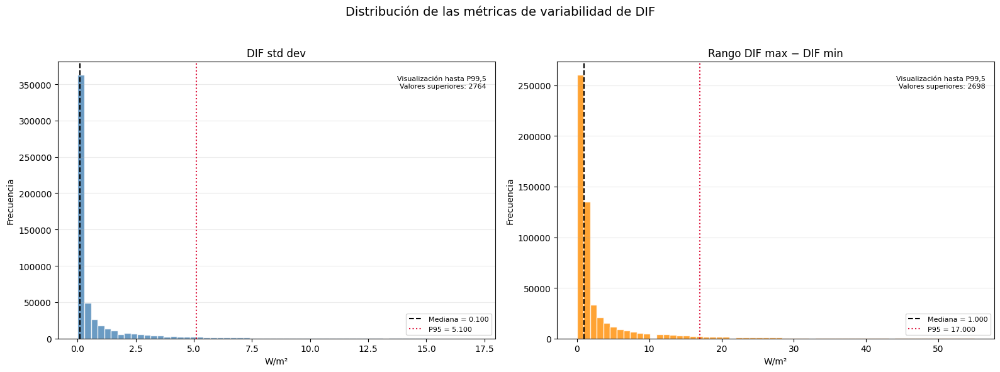

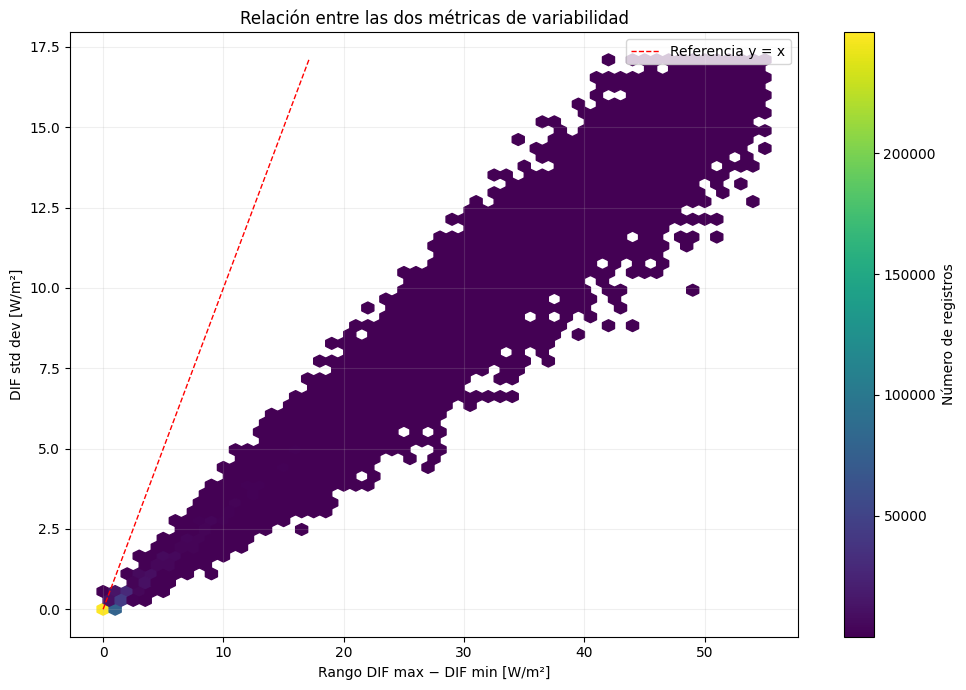

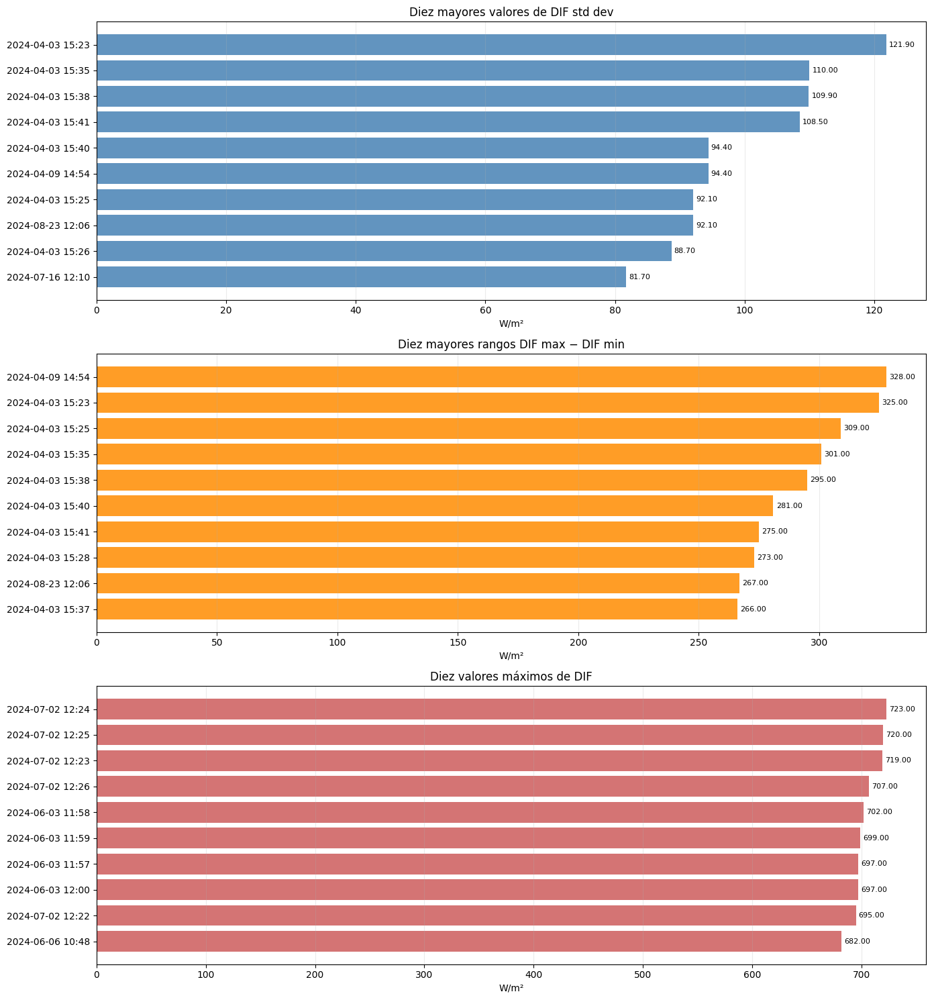

In [34]:
carpeta_resultados_t7 = Path("tarea_7_resultados")
carpeta_resultados_t7.mkdir(exist_ok=True)
rutas_graficas_t7 = []


# 1. Distribuciones
# El recorte en p99,5 es exclusivamente visual.
# No se elimina ningún registro de las tablas.
fig, ejes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
configuraciones_t7 = [
    (COL_DIF_STD_T7, "DIF std dev", "steelblue"),
    (COL_RANGO_T7, "Rango DIF max − DIF min", "darkorange"),
]
for eje, (columna, titulo, color) in zip(ejes, configuraciones_t7):
    valores = analisis_t7[columna].to_numpy(dtype=float, na_value=np.nan)
    valores = valores[np.isfinite(valores)]
    if len(valores) == 0:
        eje.text(0.5, 0.5, "Sin valores finitos", ha="center", va="center")
        continue

    limite_visual = float(np.quantile(valores, 0.995))
    valores_visibles = valores[valores <= limite_visual]
    n_superiores = int((valores > limite_visual).sum())
    eje.hist(valores_visibles, bins=60, color=color, alpha=0.80, edgecolor="white")
    mediana = float(np.median(valores))
    p95 = float(np.quantile(valores, 0.95))
    eje.axvline(
        mediana, color="black", linestyle="--", linewidth=1.5, label=f"Mediana = {mediana:.3f}"
    )
    eje.axvline(p95, color="crimson", linestyle=":", linewidth=1.5, label=f"P95 = {p95:.3f}")
    eje.set_title(titulo)
    eje.set_xlabel("W/m²")
    eje.set_ylabel("Frecuencia")
    eje.grid(axis="y", alpha=0.25)
    eje.legend(fontsize=8)
    eje.text(
        0.98,
        0.95,
        (f"Visualización hasta P99,5\n" f"Valores superiores: {n_superiores}"),
        transform=eje.transAxes,
        ha="right",
        va="top",
        fontsize=8,
    )

fig.suptitle("Distribución de las métricas de variabilidad de DIF", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
ruta_grafica_1_t7 = carpeta_resultados_t7 / "grafica_01_distribuciones_variabilidad.png"
fig.savefig(ruta_grafica_1_t7, dpi=180, bbox_inches="tight")
rutas_graficas_t7.append(ruta_grafica_1_t7)
plt.show()


# 2. Relación entre rango y desviación estándar
# También se limita a P99,5 únicamente para visualizar.
if n_comparables_t7 > 0:
    limite_x = float(np.quantile(rango_comparable_t7, 0.995))
    limite_y = float(np.quantile(std_comparable_t7, 0.995))
    mascara_visual_t7 = (rango_comparable_t7 <= limite_x) & (std_comparable_t7 <= limite_y)
    fig, eje = plt.subplots(figsize=(10, 7))
    hexbin = eje.hexbin(
        rango_comparable_t7[mascara_visual_t7],
        std_comparable_t7[mascara_visual_t7],
        gridsize=55,
        mincnt=1,
        cmap="viridis",
    )
    fig.colorbar(hexbin, ax=eje, label="Número de registros")
    limite_diagonal = min(limite_x, limite_y)
    eje.plot(
        [0, limite_diagonal],
        [0, limite_diagonal],
        linestyle="--",
        color="red",
        linewidth=1,
        label="Referencia y = x",
    )
    eje.set_xlabel("Rango DIF max − DIF min [W/m²]")
    eje.set_ylabel("DIF std dev [W/m²]")
    eje.set_title("Relación entre las dos métricas de variabilidad")
    eje.grid(alpha=0.20)
    eje.legend()
    plt.tight_layout()
    ruta_grafica_2_t7 = carpeta_resultados_t7 / "grafica_02_relacion_std_rango.png"
    fig.savefig(ruta_grafica_2_t7, dpi=180, bbox_inches="tight")
    rutas_graficas_t7.append(ruta_grafica_2_t7)
    plt.show()


# 3. Rankings de extremos
def dibujar_ranking_t7(eje, tabla, columna_valor, titulo, color):
    tabla_grafico = tabla.iloc[::-1].copy()
    etiquetas = tabla_grafico[COL_FECHA_T7].dt.strftime("%Y-%m-%d %H:%M")
    barras = eje.barh(etiquetas, tabla_grafico[columna_valor], color=color, alpha=0.85)
    eje.bar_label(barras, fmt="%.2f", padding=3, fontsize=8)
    eje.set_title(titulo)
    eje.set_xlabel("W/m²")
    eje.grid(axis="x", alpha=0.25)

fig, ejes = plt.subplots(nrows=3, ncols=1, figsize=(14, 15))
dibujar_ranking_t7(
    ejes[0], top_10_std_dev_t7, COL_DIF_STD_T7, "Diez mayores valores de DIF std dev", "steelblue"
)
dibujar_ranking_t7(
    ejes[1], top_10_rango_t7, COL_RANGO_T7, "Diez mayores rangos DIF max − DIF min", "darkorange"
)
dibujar_ranking_t7(ejes[2], top_10_dif_t7, COL_DIF_T7, "Diez valores máximos de DIF", "indianred")
plt.tight_layout()
ruta_grafica_3_t7 = carpeta_resultados_t7 / "grafica_03_rankings_extremos.png"
fig.savefig(ruta_grafica_3_t7, dpi=180, bbox_inches="tight")
rutas_graficas_t7.append(ruta_grafica_3_t7)
plt.show()

### 7.6 Controles

In [35]:
def tabla_ordenada_descendente_t7(tabla, columna):
    valores = tabla[columna].to_numpy(dtype=float, na_value=np.nan)
    if len(valores) <= 1:
        return True

    return bool(np.all(np.diff(valores) <= 0))

def longitud_top_correcta_t7(tabla, serie):
    valores = serie.to_numpy(dtype=float, na_value=np.nan)
    n_finitos = int(np.isfinite(valores).sum())
    return len(tabla) == min(10, n_finitos)

def top_coincide_con_maximo_t7(tabla, columna, serie):
    valores = serie.to_numpy(dtype=float, na_value=np.nan)
    valores_finitos = valores[np.isfinite(valores)]
    if len(valores_finitos) == 0:
        return tabla.empty

    return bool(np.isclose(tabla.iloc[0][columna], valores_finitos.max()))


# 1. Controles de fuente y construcción
control_fuente_intacta_t7 = df_t7.equals(
    df_t2.loc[:, COLUMNAS_NECESARIAS_T7].reset_index(drop=True)
)
control_fechas_validas_t7 = fechas_t7.notna().all()
control_categorias_completas_t7 = categoria_swd_t7.notna().all()
control_rango_definido_correctamente_t7 = np.array_equal(
    np.isfinite(rango_dif_array_t7), mascara_extremos_finitos_t7
)


# 2. Reconciliación de resúmenes
control_particion_global_t7 = all(
    (int(fila["n_valores_finitos"]) + int(fila["n_no_evaluables"]) == len(df_t7))
    and (
        int(fila["n_ceros"]) + int(fila["n_negativos"]) + int(fila["n_positivos"])
        == int(fila["n_valores_finitos"])
    )
    for _, fila in resumen_global_variabilidad_t7.iterrows()
)
COLUMNAS_RECONCILIACION_T7 = [
    "n_filas_segmento",
    "n_valores_finitos",
    "n_no_evaluables",
    "n_ceros",
    "n_negativos",
    "n_positivos",
]
control_proxy_recupera_global_t7 = True
for metrica in resumen_global_variabilidad_t7["metrica"].unique():
    fila_global = resumen_global_variabilidad_t7.loc[
        resumen_global_variabilidad_t7["metrica"].eq(metrica)
    ].iloc[0]
    tabla_proxy_metrica = resumen_variabilidad_proxy_t7.loc[
        resumen_variabilidad_proxy_t7["metrica"].eq(metrica)
    ]
    for columna in COLUMNAS_RECONCILIACION_T7:
        if int(tabla_proxy_metrica[columna].sum()) != int(fila_global[columna]):
            control_proxy_recupera_global_t7 = False


# 3. Controles de rankings
control_longitud_top_std_t7 = longitud_top_correcta_t7(
    top_10_std_dev_t7, analisis_t7[COL_DIF_STD_T7]
)
control_longitud_top_rango_t7 = longitud_top_correcta_t7(top_10_rango_t7, analisis_t7[COL_RANGO_T7])
control_longitud_top_dif_t7 = longitud_top_correcta_t7(top_10_dif_t7, analisis_t7[COL_DIF_T7])
control_orden_top_std_t7 = tabla_ordenada_descendente_t7(top_10_std_dev_t7, COL_DIF_STD_T7)
control_orden_top_rango_t7 = tabla_ordenada_descendente_t7(top_10_rango_t7, COL_RANGO_T7)
control_orden_top_dif_t7 = tabla_ordenada_descendente_t7(top_10_dif_t7, COL_DIF_T7)
control_maximos_top_t7 = all(
    [
        top_coincide_con_maximo_t7(top_10_std_dev_t7, COL_DIF_STD_T7, analisis_t7[COL_DIF_STD_T7]),
        top_coincide_con_maximo_t7(top_10_rango_t7, COL_RANGO_T7, analisis_t7[COL_RANGO_T7]),
        top_coincide_con_maximo_t7(top_10_dif_t7, COL_DIF_T7, analisis_t7[COL_DIF_T7]),
    ]
)


# 4. Tabla de controles
controles_t7 = pd.DataFrame(
    [
        {
            "control": "df_t7 coincide con la selección original de df_t2",
            "superado": bool(control_fuente_intacta_t7),
        },
        {"control": "Todas las fechas son válidas", "superado": bool(control_fechas_validas_t7)},
        {
            "control": "Todas las filas tienen categoría SWD",
            "superado": bool(control_categorias_completas_t7),
        },
        {
            "control": "El rango se calcula solo con min y max finitos",
            "superado": bool(control_rango_definido_correctamente_t7),
        },
        {
            "control": "Las clases de signo recuperan los valores finitos",
            "superado": bool(control_particion_global_t7),
        },
        {
            "control": "Las categorías SWD recuperan el resumen global",
            "superado": bool(control_proxy_recupera_global_t7),
        },
        {
            "control": "Los tres rankings tienen la longitud correcta",
            "superado": bool(
                control_longitud_top_std_t7
                and control_longitud_top_rango_t7
                and control_longitud_top_dif_t7
            ),
        },
        {
            "control": "Los tres rankings están ordenados",
            "superado": bool(
                control_orden_top_std_t7 and control_orden_top_rango_t7 and control_orden_top_dif_t7
            ),
        },
        {
            "control": "La primera fila contiene el máximo real",
            "superado": bool(control_maximos_top_t7),
        },
    ]
)
display(controles_t7)
if controles_t7["superado"].all():
    print("Todos los controles de ejecución de la " "sección 7 se han superado.")
else:
    print("Existe algún control no superado. " "No cierres la tarea hasta revisarlo.")

,control,superado
0,df_t7 coincide con la selección original de df_t2,True
1,Todas las fechas son válidas,True
2,Todas las filas tienen categoría SWD,True
3,El rango se calcula solo con min y max finitos,True
4,Las clases de signo recuperan los valores finitos,True
5,Las categorías SWD recuperan el resumen global,True
6,Los tres rankings tienen la longitud correcta,True
7,Los tres rankings están ordenados,True
8,La primera fila contiene el máximo real,True


Todos los controles de ejecución de la sección 7 se han superado.


## 8. Síntesis de la calidad de la familia DIF

La serie temporal contiene 570.240 registros consecutivos con una frecuencia exacta de un minuto, sin timestamps ausentes, duplicados ni transiciones temporales irregulares. Las cuatro variables de la familia DIF presentan 11.605 valores ausentes —el 2,035 %— y comparten exactamente el mismo patrón de ausencia. El 95,45 % de estas ausencias pertenece a una única racha de 11.077 minutos comprendida entre el 20 y el 27 de diciembre de 2023. Esta racha se tratará como una discontinuidad temporal: no se interpolará a través de ella y las futuras ventanas de modelado que la atraviesen deberán excluirse o identificarse explícitamente.

No se han encontrado valores infinitos ni violaciones de las relaciones `DIF min ≤ DIF ≤ DIF max` y `DIF std dev ≥ 0`. Todos los valores negativos de DIF aparecen cuando `SWD ≤ 10 W/m²`, utilizada únicamente como proxy provisional de baja radiación, y no se observa ningún valor negativo cuando `SWD > 10 W/m²`. Por ello, los negativos se consideran compatibles con ruido u offset instrumental alrededor de cero durante la noche o el crepúsculo. Se conservarán las variables originales sin truncar negativos, eliminar extremos, aplicar winsorización ni sobrescribir valores. No se crea una versión depurada de la DIF: su utilidad dependería del planteamiento predictivo y tendría que evaluarse frente a la señal original.

La desviación estándar intraminuto y el rango `DIF max − DIF min` son internamente coherentes y están fuertemente relacionados. La variabilidad absoluta aumenta generalmente durante los meses de mayor radiación, aunque también existen periodos de DIF muy alta y estable. Estos resultados no permiten atribuir los episodios extremos directamente a la nubosidad ni determinar todavía la predictibilidad a un minuto. A partir de aquí se estudia la estructura temporal de la serie.

## 9. Descomposición STL

Sobre la serie horaria se separan la tendencia, la componente diaria y el residuo.

### 9.1 Preparación y cobertura horaria

In [36]:
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Comprobar objetos de las tareas anteriores
OBJETOS_REQUERIDOS_STL = ["df_t2", "COL_FECHA", "COLUMNAS_DIF"]
objetos_ausentes_stl = [nombre for nombre in OBJETOS_REQUERIDOS_STL if nombre not in globals()]
if objetos_ausentes_stl:
    raise NameError("Faltan objetos de las tareas anteriores: " f"{objetos_ausentes_stl}")


# 2. Definiciones
COL_DIF_STL = "DIF [W/m**2]"
COL_STD_STL = "DIF std dev [W/m**2]"
COL_MIN_STL = "DIF min [W/m**2]"
COL_MAX_STL = "DIF max [W/m**2]"
COL_RANGO_STL = "Rango DIF max menos DIF min [W/m**2]"
VARIABLES_ORIGINALES_STL = [COL_DIF_STL, COL_STD_STL, COL_MIN_STL, COL_MAX_STL]
VARIABLES_STL = VARIABLES_ORIGINALES_STL + [COL_RANGO_STL]
INICIO_STL_PRINCIPAL = pd.Timestamp("2023-12-28 00:00:00")


# 3. Copia controlada
df_stl_minuto = df_t2.loc[:, [COL_FECHA] + VARIABLES_ORIGINALES_STL].copy(deep=True)
df_stl_minuto[COL_FECHA] = pd.to_datetime(df_stl_minuto[COL_FECHA], errors="coerce")
if df_stl_minuto[COL_FECHA].isna().any():
    raise ValueError("Se han detectado fechas no válidas.")

df_stl_minuto = (
    df_stl_minuto.sort_values(COL_FECHA, kind="mergesort")
    .loc[lambda tabla: tabla[COL_FECHA] >= INICIO_STL_PRINCIPAL]
    .set_index(COL_FECHA)
)


# 4. Controles temporales
if df_stl_minuto.index.duplicated().any():
    raise ValueError("Existen timestamps duplicados.")

if not df_stl_minuto.index.is_monotonic_increasing:
    raise ValueError("Los timestamps no están ordenados.")

intervalos_stl = df_stl_minuto.index.to_series().diff().dropna()
if not intervalos_stl.eq(pd.Timedelta(minutes=1)).all():
    raise ValueError("El segmento no conserva una frecuencia exacta " "de un minuto.")


# 5. Rango intraminuto
df_stl_minuto[COL_RANGO_STL] = df_stl_minuto[COL_MAX_STL] - df_stl_minuto[COL_MIN_STL]


# 6. Agregación horaria provisional
# Todavía no se rellenan ausencias ni se establece un mínimo
# de minutos válidos.
df_stl_horario_media = df_stl_minuto[VARIABLES_STL].resample("1h").mean()
conteos_horarios_stl = df_stl_minuto[VARIABLES_STL].resample("1h").count()
filas_horarias_stl = df_stl_minuto[COL_DIF_STL].resample("1h").size().rename("n_minutos_esperados")
cobertura_horaria_stl = pd.concat(
    [filas_horarias_stl, conteos_horarios_stl.add_prefix("n_validos__")], axis=1
)


# 7. Comprobar si las cinco métricas tienen la misma cobertura
columnas_conteos = [f"n_validos__{variable}" for variable in VARIABLES_STL]
control_conteos_iguales = cobertura_horaria_stl[columnas_conteos].nunique(axis=1).eq(1).all()
cobertura_horaria_stl["n_validos_familia_DIF"] = cobertura_horaria_stl[f"n_validos__{COL_DIF_STL}"]
cobertura_horaria_stl["hora_completa"] = (
    cobertura_horaria_stl["n_validos_familia_DIF"] == cobertura_horaria_stl["n_minutos_esperados"]
)
cobertura_horaria_stl["hora_parcial"] = cobertura_horaria_stl["n_validos_familia_DIF"].between(
    1, cobertura_horaria_stl["n_minutos_esperados"] - 1
)
cobertura_horaria_stl["hora_sin_datos"] = cobertura_horaria_stl["n_validos_familia_DIF"] == 0


# 8. Resumen
resumen_preparacion_stl = pd.DataFrame(
    {
        "comprobación": [
            "Inicio solicitado del segmento",
            "Primer timestamp observado",
            "Último timestamp observado",
            "Filas a resolución de un minuto",
            "Horas generadas",
            "Horas completas",
            "Horas parciales",
            "Horas completamente ausentes",
            "Mínimo de minutos válidos en una hora",
            "Mediana de minutos válidos en una hora",
            "Cobertura igual en toda la familia DIF",
            "Zona horaria incorporada",
        ],
        "resultado": [
            INICIO_STL_PRINCIPAL,
            df_stl_minuto.index.min(),
            df_stl_minuto.index.max(),
            len(df_stl_minuto),
            len(df_stl_horario_media),
            int(cobertura_horaria_stl["hora_completa"].sum()),
            int(cobertura_horaria_stl["hora_parcial"].sum()),
            int(cobertura_horaria_stl["hora_sin_datos"].sum()),
            int(cobertura_horaria_stl["n_validos_familia_DIF"].min()),
            float(cobertura_horaria_stl["n_validos_familia_DIF"].median()),
            bool(control_conteos_iguales),
            (
                str(df_stl_minuto.index.tz)
                if df_stl_minuto.index.tz is not None
                else "No incorporada"
            ),
        ],
    }
)
display(resumen_preparacion_stl)


# 9. Distribución de la cobertura
distribucion_cobertura_stl = (
    cobertura_horaria_stl["n_validos_familia_DIF"]
    .value_counts()
    .sort_index()
    .rename_axis("minutos_válidos_en_la_hora")
    .reset_index(name="n_horas")
)
print("Distribución de minutos válidos por hora:")
display(distribucion_cobertura_stl)
horas_incompletas_stl = cobertura_horaria_stl.loc[
    ~cobertura_horaria_stl["hora_completa"],
    ["n_minutos_esperados", "n_validos_familia_DIF", "hora_parcial", "hora_sin_datos"],
].reset_index()
print("Primeras horas incompletas:")
display(horas_incompletas_stl.head(30))


# 10. Control de conservación
control_fuente_stl = df_t2.equals(df_t2.copy(deep=True))
print("df_t2 permanece intacto:", control_fuente_stl)
print("\nTodavía no se ha interpolado, rellenado " "ni eliminado ningún valor.")

,comprobación,resultado
0,Inicio solicitado del segmento,2023-12-28 00:00:00
1,Primer timestamp observado,2023-12-28 00:00:00
2,Último timestamp observado,2024-11-30 23:59:00
3,Filas a resolución de un minuto,488160
4,Horas generadas,8136
5,Horas completas,7940
6,Horas parciales,196
7,Horas completamente ausentes,0
8,Mínimo de minutos válidos en una hora,39
9,Mediana de minutos válidos en una hora,60.0


Distribución de minutos válidos por hora:


,minutos_válidos_en_la_hora,n_horas
0,39,1
1,41,1
2,43,1
3,44,1
4,47,1
5,48,1
6,50,1
7,51,1
8,52,2
9,53,7


Primeras horas incompletas:


,Date/Time,n_minutos_esperados,n_validos_familia_DIF,hora_parcial,hora_sin_datos
0,2023-12-29 09:00:00,60,59,True,False
1,2024-01-02 11:00:00,60,58,True,False
2,2024-01-05 08:00:00,60,59,True,False
3,2024-01-08 09:00:00,60,59,True,False
4,2024-01-09 09:00:00,60,58,True,False
5,2024-01-09 11:00:00,60,59,True,False
6,2024-01-09 12:00:00,60,48,True,False
7,2024-01-10 12:00:00,60,59,True,False
8,2024-01-12 11:00:00,60,59,True,False
9,2024-01-15 10:00:00,60,59,True,False


df_t2 permanece intacto: True

Todavía no se ha interpolado, rellenado ni eliminado ningún valor.


Cobertura desde el 28 de diciembre de 2023:

- 488.160 minutos y 8.136 horas.
- 7.940 horas completas (97,59 %) y 196 horas parciales (2,41 %).
- Ninguna hora completamente vacía.
- 501 minutos ausentes en total, el 0,103 % del segmento.
- Todas las horas conservan al menos 39 de sus 60 minutos.

Además, 154 de las 196 horas parciales tienen 58 o 59 minutos válidos: en el 78,6 % de ellas solo faltan uno o dos minutos.

### 9.2 STL horario no robusto

Descomposición con `period=24`, `robust=False` y la ventana de tendencia por defecto.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.seasonal import STL

# 1. Comprobar los objetos de preparación
OBJETOS_REQUERIDOS_STL_DIF_NO_ROBUSTO = [
    "df_stl_horario_media",
    "cobertura_horaria_stl",
    "COL_DIF_STL",
]
objetos_ausentes_stl_dif_no_robusto = [
    nombre for nombre in OBJETOS_REQUERIDOS_STL_DIF_NO_ROBUSTO if nombre not in globals()
]
if objetos_ausentes_stl_dif_no_robusto:
    raise NameError(
        "Faltan objetos de la preparación horaria: " f"{objetos_ausentes_stl_dif_no_robusto}"
    )

if COL_DIF_STL not in df_stl_horario_media.columns:
    raise KeyError(f"No existe la columna '{COL_DIF_STL}' " "en df_stl_horario_media.")

if "n_validos_familia_DIF" not in cobertura_horaria_stl.columns:
    raise KeyError("No existe la columna " "'n_validos_familia_DIF' " "en cobertura_horaria_stl.")


# 2. Preparar una serie independiente
serie_dif_horaria_stl_no_robusto = (
    df_stl_horario_media[COL_DIF_STL].copy(deep=True).sort_index().asfreq("1h")
)
serie_dif_horaria_stl_no_robusto.name = "DIF horaria media [W/m²]"
if not isinstance(serie_dif_horaria_stl_no_robusto.index, pd.DatetimeIndex):
    raise TypeError("El índice de la serie debe ser un DatetimeIndex.")

if serie_dif_horaria_stl_no_robusto.index.duplicated().any():
    raise ValueError("La serie horaria contiene timestamps duplicados.")

if not (serie_dif_horaria_stl_no_robusto.index.is_monotonic_increasing):
    raise ValueError("La serie horaria no está ordenada.")

if serie_dif_horaria_stl_no_robusto.isna().any():
    fechas_ausentes_no_robusto = serie_dif_horaria_stl_no_robusto[
        serie_dif_horaria_stl_no_robusto.isna()
    ].index.tolist()
    raise ValueError(
        "La serie contiene horas sin media calculable. "
        "Primeras fechas: "
        f"{fechas_ausentes_no_robusto[:10]}"
    )

if not np.isfinite(serie_dif_horaria_stl_no_robusto.to_numpy(dtype=float)).all():
    raise ValueError("La serie contiene valores no finitos.")


# 3. Configuración independiente
PERIODO_DIARIO_STL_NO_ROBUSTO = 24
VENTANA_ESTACIONAL_STL_NO_ROBUSTO = 13
VENTANA_LOW_PASS_STL_NO_ROBUSTO = 25
modelo_stl_dif_no_robusto = STL(
    endog=serie_dif_horaria_stl_no_robusto,
    period=PERIODO_DIARIO_STL_NO_ROBUSTO,
    seasonal=VENTANA_ESTACIONAL_STL_NO_ROBUSTO,
    trend=None,
    low_pass=VENTANA_LOW_PASS_STL_NO_ROBUSTO,
    seasonal_deg=1,
    trend_deg=1,
    low_pass_deg=1,
    robust=False,
)
configuracion_efectiva_no_robusto = modelo_stl_dif_no_robusto.config
if bool(configuracion_efectiva_no_robusto["robust"]):
    raise RuntimeError("El modelo no se ha configurado con robust=False.")


# 4. Ajustar el STL
resultado_stl_dif_no_robusto = modelo_stl_dif_no_robusto.fit()


# 5. Guardar los componentes con índice explícito
indice_stl_no_robusto = serie_dif_horaria_stl_no_robusto.index
componentes_stl_dif_no_robusto = pd.DataFrame(
    {
        "DIF_observada": (serie_dif_horaria_stl_no_robusto),
        "tendencia": pd.Series(
            np.asarray(resultado_stl_dif_no_robusto.trend), index=indice_stl_no_robusto
        ),
        "estacional": pd.Series(
            np.asarray(resultado_stl_dif_no_robusto.seasonal), index=indice_stl_no_robusto
        ),
        "residuo": pd.Series(
            np.asarray(resultado_stl_dif_no_robusto.resid), index=indice_stl_no_robusto
        ),
        # Con robust=False estos pesos deben ser iguales a 1.
        "peso_STL": pd.Series(
            np.asarray(resultado_stl_dif_no_robusto.weights), index=indice_stl_no_robusto
        ),
    }
)


# 6. Añadir la cobertura horaria
cobertura_reindexada_no_robusto = cobertura_horaria_stl["n_validos_familia_DIF"].reindex(
    indice_stl_no_robusto
)
if cobertura_reindexada_no_robusto.isna().any():
    raise ValueError(
        "No se ha podido alinear completamente " "la cobertura horaria con los componentes."
    )

componentes_stl_dif_no_robusto["minutos_validos"] = cobertura_reindexada_no_robusto


# 7. Comprobar componentes y pesos
COLUMNAS_COMPONENTES_NO_ROBUSTO = [
    "DIF_observada",
    "tendencia",
    "estacional",
    "residuo",
    "peso_STL",
]
if componentes_stl_dif_no_robusto[COLUMNAS_COMPONENTES_NO_ROBUSTO].isna().any().any():
    raise ValueError("Se han generado valores ausentes " "en los componentes.")

if not np.isfinite(
    componentes_stl_dif_no_robusto[COLUMNAS_COMPONENTES_NO_ROBUSTO].to_numpy(dtype=float)
).all():
    raise ValueError("Se han generado valores no finitos " "en los componentes.")

pesos_iguales_a_uno_no_robusto = bool(
    np.allclose(componentes_stl_dif_no_robusto["peso_STL"], 1.0, rtol=0, atol=1e-12)
)
if not pesos_iguales_a_uno_no_robusto:
    raise RuntimeError("Con robust=False se esperaban pesos " "STL iguales a 1.")


# 8. Comprobar la reconstrucción
reconstruccion_stl_dif_no_robusto = (
    componentes_stl_dif_no_robusto["tendencia"]
    + componentes_stl_dif_no_robusto["estacional"]
    + componentes_stl_dif_no_robusto["residuo"]
)
error_reconstruccion_stl_dif_no_robusto = (
    componentes_stl_dif_no_robusto["DIF_observada"] - reconstruccion_stl_dif_no_robusto
)
max_error_reconstruccion_stl_dif_no_robusto = float(
    error_reconstruccion_stl_dif_no_robusto.abs().max()
)
control_reconstruccion_stl_dif_no_robusto = bool(
    np.allclose(
        componentes_stl_dif_no_robusto["DIF_observada"],
        reconstruccion_stl_dif_no_robusto,
        rtol=1e-10,
        atol=1e-8,
    )
)
if not control_reconstruccion_stl_dif_no_robusto:
    raise RuntimeError("La reconstrucción STL no es correcta.")


# 9. Configuración realmente utilizada
configuracion_stl_dif_no_robusto = pd.DataFrame(
    {
        "parámetro": list(configuracion_efectiva_no_robusto.keys()),
        "valor": list(configuracion_efectiva_no_robusto.values()),
    }
)
print("Configuración utilizada por STL " "(robust=False):")
display(configuracion_stl_dif_no_robusto)


# 10. Resumen de la ejecución
resumen_ejecucion_stl_dif_no_robusto = pd.DataFrame(
    {
        "comprobación": [
            "Primera hora",
            "Última hora",
            "Número de observaciones",
            "Valores ausentes",
            "Periodo diario",
            "Ventana estacional",
            "Ventana de tendencia efectiva",
            "Ventana low-pass",
            "Configuración robusta efectiva",
            "Reconstrucción correcta",
            "Error máximo de reconstrucción",
            "Todos los pesos STL iguales a 1",
            "Horas con menos de 60 minutos válidos",
            "Mínimo de minutos válidos",
        ],
        "resultado": [
            (serie_dif_horaria_stl_no_robusto.index.min()),
            (serie_dif_horaria_stl_no_robusto.index.max()),
            len(serie_dif_horaria_stl_no_robusto),
            int(serie_dif_horaria_stl_no_robusto.isna().sum()),
            configuracion_efectiva_no_robusto["period"],
            configuracion_efectiva_no_robusto["seasonal"],
            configuracion_efectiva_no_robusto["trend"],
            configuracion_efectiva_no_robusto["low_pass"],
            bool(configuracion_efectiva_no_robusto["robust"]),
            control_reconstruccion_stl_dif_no_robusto,
            max_error_reconstruccion_stl_dif_no_robusto,
            pesos_iguales_a_uno_no_robusto,
            int((componentes_stl_dif_no_robusto["minutos_validos"] < 60).sum()),
            int(componentes_stl_dif_no_robusto["minutos_validos"].min()),
        ],
    }
)
print("Resumen de la ejecución " "(robust=False):")
display(resumen_ejecucion_stl_dif_no_robusto)


# 11. Estadísticos de los componentes
resumen_componentes_stl_dif_no_robusto = (
    componentes_stl_dif_no_robusto[["DIF_observada", "tendencia", "estacional", "residuo"]]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)
print("Resumen estadístico de los componentes " "(robust=False):")
display(resumen_componentes_stl_dif_no_robusto.style.format(precision=4))
print("\nEl ajuste se ha ejecutado con robust=False.")
print("No se ha modificado ni interpolado " "la serie horaria original.")
print("No se han sobrescrito los objetos " "del análisis robusto.")

Configuración utilizada por STL (robust=False):


,parámetro,valor
0,period,24
1,seasonal,13
2,seasonal_deg,1
3,seasonal_jump,1
4,trend,41
5,trend_deg,1
6,trend_jump,1
7,low_pass,25
8,low_pass_deg,1
9,low_pass_jump,1


Resumen de la ejecución (robust=False):


,comprobación,resultado
0,Primera hora,2023-12-28 00:00:00
1,Última hora,2024-11-30 23:00:00
2,Número de observaciones,8136
3,Valores ausentes,0
4,Periodo diario,24
5,Ventana estacional,13
6,Ventana de tendencia efectiva,41
7,Ventana low-pass,25
8,Configuración robusta efectiva,False
9,Reconstrucción correcta,True


Resumen estadístico de los componentes (robust=False):


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
DIF_observada,8136.0000,72.4374,104.9619,-3.2167,-1.3275,-1.0000,-1.0000,9.1250,118.6292,305.3542,410.8983,555.1500
tendencia,8136.0000,72.4385,41.8691,4.9720,8.0635,15.3218,33.4163,70.5625,107.6777,142.7941,161.4096,179.1303
estacional,8136.0000,-0.0005,88.3882,-141.0862,-129.3835,-117.7632,-67.1620,-22.9418,65.5188,164.7322,205.0803,260.5937
residuo,8136.0000,-0.0006,34.7922,-167.7670,-105.9818,-56.4234,-11.9578,-0.5515,11.4403,57.0901,112.0756,208.3021



El ajuste se ha ejecutado con robust=False.
No se ha modificado ni interpolado la serie horaria original.
No se han sobrescrito los objetos del análisis robusto.


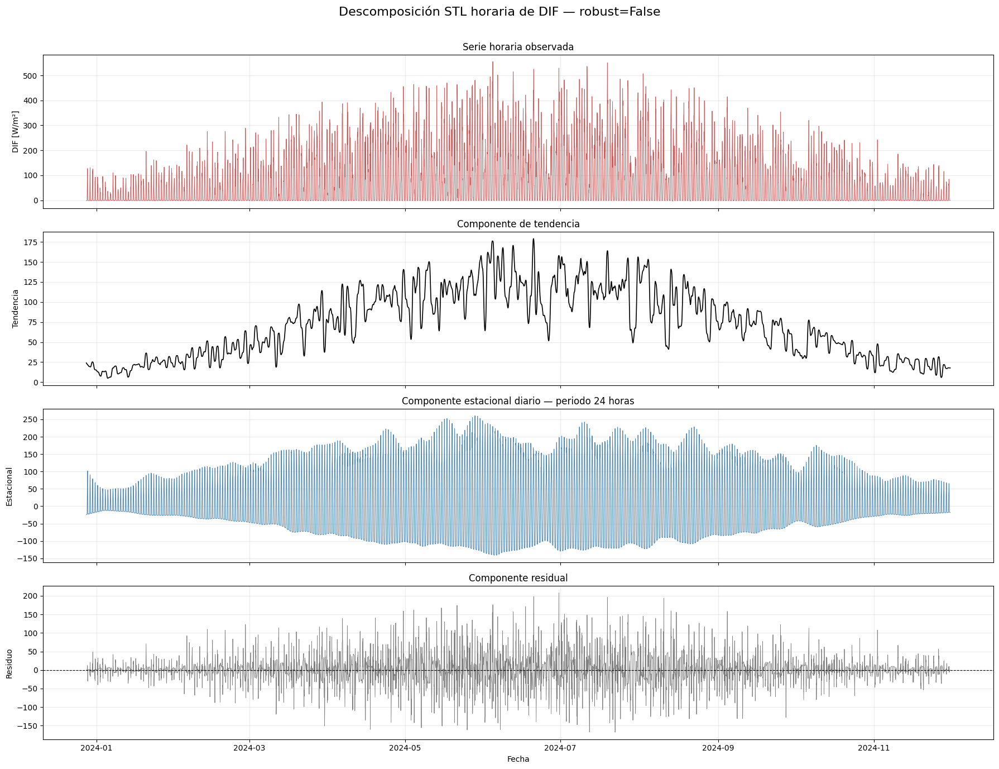

In [38]:
if "componentes_stl_dif_no_robusto" not in globals():
    raise NameError(
        "No existe 'componentes_stl_dif_no_robusto'. " "Ejecuta primero la sección 9.2."
    )

fig_stl_dif_no_robusto, ejes_stl_dif_no_robusto = plt.subplots(
    nrows=4, ncols=1, figsize=(18, 14), sharex=True
)


# Serie observada
ejes_stl_dif_no_robusto[0].plot(
    componentes_stl_dif_no_robusto.index,
    componentes_stl_dif_no_robusto["DIF_observada"],
    color="indianred",
    linewidth=0.7,
)
ejes_stl_dif_no_robusto[0].set_ylabel("DIF [W/m²]")
ejes_stl_dif_no_robusto[0].set_title("Serie horaria observada")
ejes_stl_dif_no_robusto[0].grid(alpha=0.25)


# Tendencia
ejes_stl_dif_no_robusto[1].plot(
    componentes_stl_dif_no_robusto.index,
    componentes_stl_dif_no_robusto["tendencia"],
    color="black",
    linewidth=1.2,
)
ejes_stl_dif_no_robusto[1].set_ylabel("Tendencia")
ejes_stl_dif_no_robusto[1].set_title("Componente de tendencia")
ejes_stl_dif_no_robusto[1].grid(alpha=0.25)


# Componente estacional
ejes_stl_dif_no_robusto[2].plot(
    componentes_stl_dif_no_robusto.index,
    componentes_stl_dif_no_robusto["estacional"],
    color="steelblue",
    linewidth=0.7,
)
ejes_stl_dif_no_robusto[2].set_ylabel("Estacional")
ejes_stl_dif_no_robusto[2].set_title("Componente estacional diario — " "periodo 24 horas")
ejes_stl_dif_no_robusto[2].grid(alpha=0.25)


# Residuo
ejes_stl_dif_no_robusto[3].plot(
    componentes_stl_dif_no_robusto.index,
    componentes_stl_dif_no_robusto["residuo"],
    color="grey",
    linewidth=0.6,
)
ejes_stl_dif_no_robusto[3].axhline(0, color="black", linestyle="--", linewidth=0.8)
ejes_stl_dif_no_robusto[3].set_ylabel("Residuo")
ejes_stl_dif_no_robusto[3].set_xlabel("Fecha")
ejes_stl_dif_no_robusto[3].set_title("Componente residual")
ejes_stl_dif_no_robusto[3].grid(alpha=0.25)
fig_stl_dif_no_robusto.suptitle("Descomposición STL horaria de DIF " "— robust=False", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

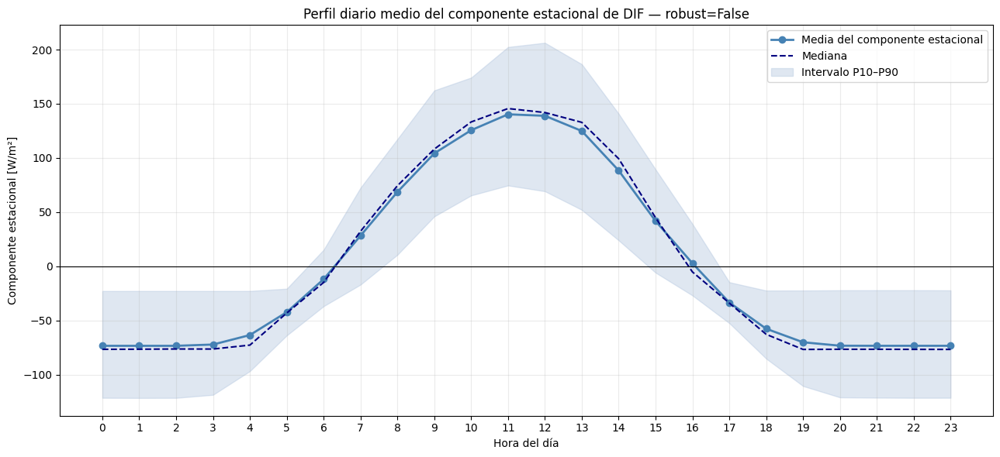

Perfil horario del componente estacional (robust=False):


,hora,media,mediana,p10,p90
0,0,-73.335,-76.584,-121.359,-22.802
1,1,-73.344,-76.474,-121.472,-22.781
2,2,-73.338,-76.262,-121.402,-22.786
3,3,-72.160,-76.310,-118.578,-22.774
4,4,-63.420,-72.682,-96.700,-22.756
5,5,-42.270,-43.058,-63.769,-20.660
6,6,-11.851,-14.856,-36.800,15.283
7,7,28.283,32.338,-16.884,72.556
8,8,68.642,74.377,10.652,117.368
9,9,104.238,108.173,46.057,162.340


In [39]:
if "componentes_stl_dif_no_robusto" not in globals():
    raise NameError(
        "No existe 'componentes_stl_dif_no_robusto'. " "Ejecuta primero la sección 9.2."
    )


# 1. Construir el perfil
tabla_perfil_stl_dif_no_robusto = (
    componentes_stl_dif_no_robusto[["estacional"]]
    .assign(hora=lambda tabla: tabla.index.hour)
    .groupby("hora", sort=True)["estacional"]
    .agg(
        media="mean",
        mediana="median",
        p10=lambda serie: serie.quantile(0.10),
        p90=lambda serie: serie.quantile(0.90),
    )
    .reset_index()
)


# 2. Representar el perfil
fig_perfil_stl_dif_no_robusto, eje_perfil_no_robusto = plt.subplots(figsize=(13, 6))
eje_perfil_no_robusto.plot(
    tabla_perfil_stl_dif_no_robusto["hora"],
    tabla_perfil_stl_dif_no_robusto["media"],
    color="steelblue",
    marker="o",
    linewidth=2,
    label="Media del componente estacional",
)
eje_perfil_no_robusto.plot(
    tabla_perfil_stl_dif_no_robusto["hora"],
    tabla_perfil_stl_dif_no_robusto["mediana"],
    color="navy",
    linestyle="--",
    linewidth=1.5,
    label="Mediana",
)
eje_perfil_no_robusto.fill_between(
    tabla_perfil_stl_dif_no_robusto["hora"],
    tabla_perfil_stl_dif_no_robusto["p10"],
    tabla_perfil_stl_dif_no_robusto["p90"],
    color="lightsteelblue",
    alpha=0.4,
    label="Intervalo P10–P90",
)
eje_perfil_no_robusto.axhline(0, color="black", linewidth=0.8)
eje_perfil_no_robusto.set_xticks(np.arange(0, 24, 1))
eje_perfil_no_robusto.set_xlabel("Hora del día")
eje_perfil_no_robusto.set_ylabel("Componente estacional [W/m²]")
eje_perfil_no_robusto.set_title(
    "Perfil diario medio del componente estacional " "de DIF — robust=False"
)
eje_perfil_no_robusto.grid(alpha=0.25)
eje_perfil_no_robusto.legend()
plt.tight_layout()
plt.show()


# 3. Mostrar la tabla
print("Perfil horario del componente estacional " "(robust=False):")
display(
    tabla_perfil_stl_dif_no_robusto.style.format(
        {"media": "{:.3f}", "mediana": "{:.3f}", "p10": "{:.3f}", "p90": "{:.3f}"}
    )
)

Negativos y residuos por hora (robust=False):


,hora,n_horas,DIF_mediana,estacional_mediana,estacional_p10,estacional_p90,residuo_media,residuo_mediana,residuo_p10,residuo_p90,residuo_abs_mediana,residuo_abs_p95,porcentaje_DIF_negativa,porcentaje_estacional_negativa,porcentaje_residuo_negativo,porcentaje_residuo_menor_menos_10,porcentaje_residuo_menor_menos_50,porcentaje_residuo_menor_menos_100
0,0,339,-1.000,-76.584,-121.359,-22.802,0.011,-0.770,-15.297,14.852,6.487,28.450,93.510,100.000,53.392,18.584,0.000,0.000
1,1,339,-1.000,-76.474,-121.472,-22.781,0.011,-0.801,-15.448,13.904,7.112,29.086,92.625,100.000,53.097,19.469,0.000,0.000
2,2,339,-1.000,-76.262,-121.402,-22.786,0.011,-0.899,-17.126,15.726,7.674,32.205,93.805,100.000,54.572,19.469,0.000,0.000
3,3,339,-0.933,-76.310,-118.578,-22.774,0.011,-0.554,-18.260,16.212,8.143,32.695,69.912,100.000,52.802,20.354,0.000,0.000
4,4,339,-0.217,-72.682,-96.700,-22.756,0.010,-0.101,-20.189,18.004,9.188,35.892,52.507,100.000,50.442,23.599,0.295,0.000
5,5,339,8.967,-43.058,-63.769,-20.660,0.010,-0.133,-22.417,23.507,9.459,41.804,35.103,100.000,50.442,24.484,0.885,0.000
6,6,339,48.317,-14.856,-36.800,15.283,0.010,1.113,-32.374,27.162,10.625,57.001,18.584,70.796,47.788,26.254,2.655,0.295
7,7,339,89.500,32.338,-16.884,72.556,0.012,-0.758,-42.612,38.310,14.467,71.981,1.180,30.383,51.622,29.499,7.670,0.295
8,8,339,126.167,74.377,10.652,117.368,-0.005,-0.142,-56.719,61.120,20.995,93.163,0.000,1.180,50.442,34.218,12.389,1.475
9,9,339,158.237,108.173,46.057,162.340,-0.014,-1.637,-62.210,69.505,29.387,109.721,0.000,0.000,52.802,40.413,15.044,3.245


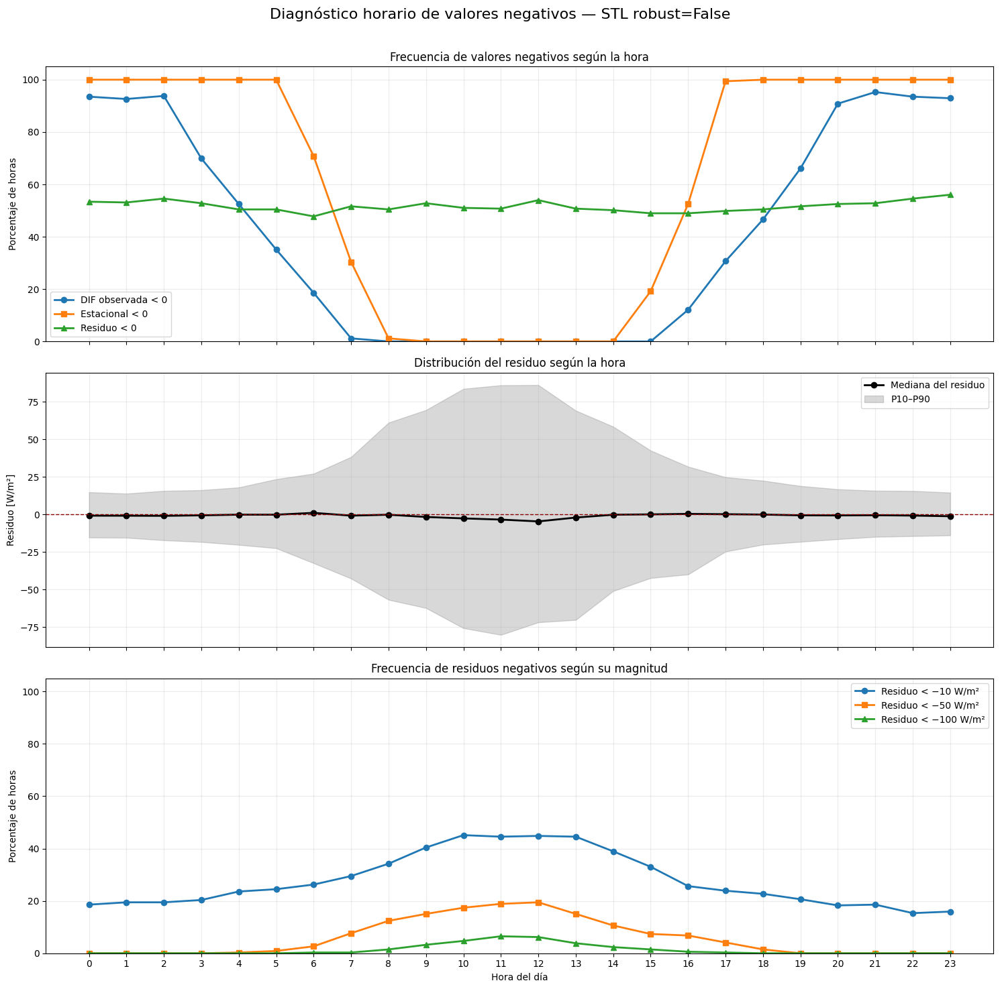

Veinte componentes estacionales más negativos:


,Date/Time,DIF_observada,tendencia,estacional,residuo,minutos_validos,hora,mes
0,2024-06-05 02:00:00,-1.000,124.596,-141.086,15.490,60,2,6
1,2024-06-05 01:00:00,-1.000,130.790,-141.013,9.223,60,1,6
2,2024-06-05 21:00:00,-1.000,118.816,-140.870,21.054,60,21,6
3,2024-06-05 23:00:00,-1.000,127.189,-140.839,12.650,60,23,6
4,2024-06-05 22:00:00,-1.000,122.850,-140.837,16.987,60,22,6
5,2024-06-05 00:00:00,-1.050,137.426,-140.811,2.335,60,0,6
6,2024-06-04 23:00:00,-1.000,144.155,-140.803,-4.352,60,23,6
7,2024-06-06 00:00:00,-1.000,131.699,-140.621,7.922,60,0,6
8,2024-06-06 01:00:00,-1.000,136.216,-140.581,3.366,60,1,6
9,2024-06-05 20:00:00,-0.517,115.186,-140.560,24.857,60,20,6


Veinte residuos más negativos:


,Date/Time,DIF_observada,tendencia,estacional,residuo,minutos_validos,hora,mes
0,2024-07-22 11:00:00,175.633,119.814,223.586,-167.767,60,11,7
1,2024-07-12 10:00:00,51.333,68.206,150.424,-167.297,60,10,7
2,2024-07-22 12:00:00,139.150,119.433,186.688,-166.970,60,12,7
3,2024-07-12 11:00:00,129.717,68.044,223.835,-162.162,60,11,7
4,2024-05-25 10:00:00,118.617,114.878,165.166,-161.427,60,10,5
5,2024-06-07 11:00:00,173.950,126.167,208.650,-160.867,60,11,6
6,2024-04-17 10:00:00,76.283,91.356,145.096,-160.169,60,10,4
7,2024-05-07 12:00:00,103.683,67.307,192.138,-155.762,60,12,5
8,2024-05-07 11:00:00,108.817,67.114,196.955,-155.252,60,11,5
9,2024-05-07 10:00:00,103.900,66.934,191.616,-154.650,60,10,5


In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Comprobar el objeto
if "componentes_stl_dif_no_robusto" not in globals():
    raise NameError(
        "No existe 'componentes_stl_dif_no_robusto'. "
        "Ejecuta primero la descomposición robust=False."
    )


# 2. Preparar diagnóstico independiente
diagnostico_negativos_stl_dif_no_robusto = (
    componentes_stl_dif_no_robusto[
        ["DIF_observada", "tendencia", "estacional", "residuo", "minutos_validos"]
    ]
    .copy(deep=True)
    .sort_index()
)
diagnostico_negativos_stl_dif_no_robusto["hora"] = (
    diagnostico_negativos_stl_dif_no_robusto.index.hour
)
diagnostico_negativos_stl_dif_no_robusto["mes"] = (
    diagnostico_negativos_stl_dif_no_robusto.index.month
)
diagnostico_negativos_stl_dif_no_robusto["residuo_absoluto"] = (
    diagnostico_negativos_stl_dif_no_robusto["residuo"].abs()
)


# 3. Resumen por hora
grupo_hora_negativos_no_robusto = diagnostico_negativos_stl_dif_no_robusto.groupby(
    "hora", sort=True
)
tabla_negativos_por_hora_stl_dif_no_robusto = grupo_hora_negativos_no_robusto.agg(
    n_horas=("residuo", "size"),
    DIF_mediana=("DIF_observada", "median"),
    estacional_mediana=("estacional", "median"),
    estacional_p10=("estacional", lambda serie: serie.quantile(0.10)),
    estacional_p90=("estacional", lambda serie: serie.quantile(0.90)),
    residuo_media=("residuo", "mean"),
    residuo_mediana=("residuo", "median"),
    residuo_p10=("residuo", lambda serie: serie.quantile(0.10)),
    residuo_p90=("residuo", lambda serie: serie.quantile(0.90)),
    residuo_abs_mediana=("residuo_absoluto", "median"),
    residuo_abs_p95=("residuo_absoluto", lambda serie: serie.quantile(0.95)),
)


# Porcentajes de valores negativos
tabla_negativos_por_hora_stl_dif_no_robusto["porcentaje_DIF_negativa"] = (
    grupo_hora_negativos_no_robusto["DIF_observada"].apply(lambda serie: 100 * serie.lt(0).mean())
)
tabla_negativos_por_hora_stl_dif_no_robusto["porcentaje_estacional_negativa"] = (
    grupo_hora_negativos_no_robusto["estacional"].apply(lambda serie: 100 * serie.lt(0).mean())
)
tabla_negativos_por_hora_stl_dif_no_robusto["porcentaje_residuo_negativo"] = (
    grupo_hora_negativos_no_robusto["residuo"].apply(lambda serie: 100 * serie.lt(0).mean())
)


# Porcentajes según magnitud negativa del residuo
for umbral in [10, 50, 100]:
    tabla_negativos_por_hora_stl_dif_no_robusto[f"porcentaje_residuo_menor_menos_{umbral}"] = (
        grupo_hora_negativos_no_robusto["residuo"].apply(
            lambda serie, limite=umbral: 100 * serie.lt(-limite).mean()
        )
    )

tabla_negativos_por_hora_stl_dif_no_robusto = (
    tabla_negativos_por_hora_stl_dif_no_robusto.reset_index()
)
print("Negativos y residuos por hora " "(robust=False):")
display(
    tabla_negativos_por_hora_stl_dif_no_robusto.style.format(
        {
            columna: "{:.3f}"
            for columna in tabla_negativos_por_hora_stl_dif_no_robusto.columns
            if columna not in ["hora", "n_horas"]
        }
    )
)


# 4. Gráficos
horas_negativos_no_robusto = tabla_negativos_por_hora_stl_dif_no_robusto["hora"].to_numpy()
fig_negativos_no_robusto, ejes_negativos_no_robusto = plt.subplots(
    nrows=3, ncols=1, figsize=(15, 15), sharex=True
)


# Panel 1: porcentaje de valores negativos
ejes_negativos_no_robusto[0].plot(
    horas_negativos_no_robusto,
    tabla_negativos_por_hora_stl_dif_no_robusto["porcentaje_DIF_negativa"].to_numpy(),
    marker="o",
    linewidth=2,
    label="DIF observada < 0",
)
ejes_negativos_no_robusto[0].plot(
    horas_negativos_no_robusto,
    tabla_negativos_por_hora_stl_dif_no_robusto["porcentaje_estacional_negativa"].to_numpy(),
    marker="s",
    linewidth=2,
    label="Estacional < 0",
)
ejes_negativos_no_robusto[0].plot(
    horas_negativos_no_robusto,
    tabla_negativos_por_hora_stl_dif_no_robusto["porcentaje_residuo_negativo"].to_numpy(),
    marker="^",
    linewidth=2,
    label="Residuo < 0",
)
ejes_negativos_no_robusto[0].set_ylabel("Porcentaje de horas")
ejes_negativos_no_robusto[0].set_title("Frecuencia de valores negativos según la hora")
ejes_negativos_no_robusto[0].set_ylim(0, 105)
ejes_negativos_no_robusto[0].grid(alpha=0.25)
ejes_negativos_no_robusto[0].legend()


# Panel 2: distribución horaria del residuo
ejes_negativos_no_robusto[1].plot(
    horas_negativos_no_robusto,
    tabla_negativos_por_hora_stl_dif_no_robusto["residuo_mediana"].to_numpy(),
    marker="o",
    linewidth=2,
    color="black",
    label="Mediana del residuo",
)
ejes_negativos_no_robusto[1].fill_between(
    horas_negativos_no_robusto,
    tabla_negativos_por_hora_stl_dif_no_robusto["residuo_p10"].to_numpy(),
    tabla_negativos_por_hora_stl_dif_no_robusto["residuo_p90"].to_numpy(),
    color="grey",
    alpha=0.3,
    label="P10–P90",
)
ejes_negativos_no_robusto[1].axhline(0, color="darkred", linestyle="--", linewidth=1)
ejes_negativos_no_robusto[1].set_ylabel("Residuo [W/m²]")
ejes_negativos_no_robusto[1].set_title("Distribución del residuo según la hora")
ejes_negativos_no_robusto[1].grid(alpha=0.25)
ejes_negativos_no_robusto[1].legend()


# Panel 3: intensidad de residuos negativos
for umbral, marcador in zip([10, 50, 100], ["o", "s", "^"]):
    ejes_negativos_no_robusto[2].plot(
        horas_negativos_no_robusto,
        tabla_negativos_por_hora_stl_dif_no_robusto[
            f"porcentaje_residuo_menor_menos_{umbral}"
        ].to_numpy(),
        marker=marcador,
        linewidth=2,
        label=f"Residuo < −{umbral} W/m²",
    )

ejes_negativos_no_robusto[2].set_xlabel("Hora del día")
ejes_negativos_no_robusto[2].set_ylabel("Porcentaje de horas")
ejes_negativos_no_robusto[2].set_title("Frecuencia de residuos negativos " "según su magnitud")
ejes_negativos_no_robusto[2].set_xticks(np.arange(0, 24, 1))
ejes_negativos_no_robusto[2].set_ylim(0, 105)
ejes_negativos_no_robusto[2].grid(alpha=0.25)
ejes_negativos_no_robusto[2].legend()
fig_negativos_no_robusto.suptitle(
    "Diagnóstico horario de valores negativos " "— STL robust=False", fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


# 5. Horas con los componentes más negativos
columnas_eventos_negativos_no_robusto = [
    "DIF_observada",
    "tendencia",
    "estacional",
    "residuo",
    "minutos_validos",
    "hora",
    "mes",
]
eventos_estacionales_mas_negativos_no_robusto = diagnostico_negativos_stl_dif_no_robusto.nsmallest(
    20, "estacional"
)[columnas_eventos_negativos_no_robusto].reset_index()
eventos_estacionales_mas_negativos_no_robusto = (
    eventos_estacionales_mas_negativos_no_robusto.rename(
        columns={eventos_estacionales_mas_negativos_no_robusto.columns[0]: "Date/Time"}
    )
)
eventos_residuales_mas_negativos_no_robusto = diagnostico_negativos_stl_dif_no_robusto.nsmallest(
    20, "residuo"
)[columnas_eventos_negativos_no_robusto].reset_index()
eventos_residuales_mas_negativos_no_robusto = eventos_residuales_mas_negativos_no_robusto.rename(
    columns={eventos_residuales_mas_negativos_no_robusto.columns[0]: "Date/Time"}
)
print("Veinte componentes estacionales " "más negativos:")
display(eventos_estacionales_mas_negativos_no_robusto.style.format(precision=3))
print("Veinte residuos más negativos:")
display(eventos_residuales_mas_negativos_no_robusto.style.format(precision=3))

### 9.3 Sensibilidad a la ventana de tendencia

Se repite la descomposición no robusta sobre la misma serie horaria (`period=24`, `seasonal=13`, `low_pass=25`) cambiando solo la ventana de tendencia.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.seasonal import STL

# 1. Comprobar la serie de entrada
if "serie_dif_horaria_stl_no_robusto" not in globals():
    raise NameError(
        "No existe 'serie_dif_horaria_stl_no_robusto'. "
        "Ejecuta primero la descomposición robust=False."
    )

serie_sensibilidad_tendencia_stl_dif = (
    serie_dif_horaria_stl_no_robusto.copy(deep=True).sort_index().asfreq("1h")
)
if serie_sensibilidad_tendencia_stl_dif.isna().any():
    raise ValueError("La serie contiene valores ausentes.")

if not np.isfinite(serie_sensibilidad_tendencia_stl_dif.to_numpy(dtype=float)).all():
    raise ValueError("La serie contiene valores no finitos.")


# 2. Configuración
PERIODO_SENSIBILIDAD_TENDENCIA = 24
VENTANA_ESTACIONAL_SENSIBILIDAD = 13
VENTANA_LOW_PASS_SENSIBILIDAD = 25
VENTANAS_TENDENCIA_STL_DIF = [
    41,  # Aproximadamente 1,7 días
    169,  # Aproximadamente 7 días
    337,  # Aproximadamente 14 días
    721,  # Aproximadamente 30 días
]
for ventana in VENTANAS_TENDENCIA_STL_DIF:
    if ventana <= PERIODO_SENSIBILIDAD_TENDENCIA:
        raise ValueError(f"La ventana {ventana} debe ser mayor que 24.")

    if ventana % 2 == 0:
        raise ValueError(f"La ventana {ventana} debe ser impar.")


# 3. Contenedores independientes
modelos_sensibilidad_tendencia_stl_dif = {}
resultados_sensibilidad_tendencia_stl_dif = {}
componentes_sensibilidad_tendencia_stl_dif = {}
tendencias_sensibilidad_stl_dif = pd.DataFrame(index=serie_sensibilidad_tendencia_stl_dif.index)
estacionales_sensibilidad_stl_dif = pd.DataFrame(index=serie_sensibilidad_tendencia_stl_dif.index)
residuos_sensibilidad_stl_dif = pd.DataFrame(index=serie_sensibilidad_tendencia_stl_dif.index)
filas_resumen_sensibilidad_tendencia = []


# 4. Ajustar un STL por cada ventana
for ventana_tendencia in VENTANAS_TENDENCIA_STL_DIF:
    modelo_sensibilidad = STL(
        endog=serie_sensibilidad_tendencia_stl_dif,
        period=PERIODO_SENSIBILIDAD_TENDENCIA,
        seasonal=VENTANA_ESTACIONAL_SENSIBILIDAD,
        trend=ventana_tendencia,
        low_pass=VENTANA_LOW_PASS_SENSIBILIDAD,
        seasonal_deg=1,
        trend_deg=1,
        low_pass_deg=1,
        robust=False,
    )
    resultado_sensibilidad = modelo_sensibilidad.fit()
    indice_sensibilidad = serie_sensibilidad_tendencia_stl_dif.index
    componentes_ventana = pd.DataFrame(
        {
            "DIF_observada": (serie_sensibilidad_tendencia_stl_dif),
            "tendencia": pd.Series(
                np.asarray(resultado_sensibilidad.trend), index=indice_sensibilidad
            ),
            "estacional": pd.Series(
                np.asarray(resultado_sensibilidad.seasonal), index=indice_sensibilidad
            ),
            "residuo": pd.Series(
                np.asarray(resultado_sensibilidad.resid), index=indice_sensibilidad
            ),
            "peso_STL": pd.Series(
                np.asarray(resultado_sensibilidad.weights), index=indice_sensibilidad
            ),
        }
    )
    if bool(modelo_sensibilidad.config["robust"]):
        raise RuntimeError(f"El modelo de ventana {ventana_tendencia} " "no tiene robust=False.")

    # Con robust=False todos los pesos deben ser 1
    if not np.allclose(componentes_ventana["peso_STL"], 1.0, rtol=0, atol=1e-12):
        raise RuntimeError(f"Los pesos no son iguales a 1 para " f"trend={ventana_tendencia}.")

    reconstruccion_ventana = (
        componentes_ventana["tendencia"]
        + componentes_ventana["estacional"]
        + componentes_ventana["residuo"]
    )
    error_reconstruccion_ventana = componentes_ventana["DIF_observada"] - reconstruccion_ventana
    error_maximo_ventana = float(error_reconstruccion_ventana.abs().max())
    reconstruccion_correcta_ventana = bool(
        np.allclose(
            componentes_ventana["DIF_observada"], reconstruccion_ventana, rtol=1e-10, atol=1e-8
        )
    )
    if not reconstruccion_correcta_ventana:
        raise RuntimeError("Reconstrucción incorrecta para " f"trend={ventana_tendencia}.")

    modelos_sensibilidad_tendencia_stl_dif[ventana_tendencia] = modelo_sensibilidad
    resultados_sensibilidad_tendencia_stl_dif[ventana_tendencia] = resultado_sensibilidad
    componentes_sensibilidad_tendencia_stl_dif[ventana_tendencia] = componentes_ventana
    tendencias_sensibilidad_stl_dif[f"tendencia_{ventana_tendencia}h"] = componentes_ventana[
        "tendencia"
    ]
    estacionales_sensibilidad_stl_dif[f"estacional_{ventana_tendencia}h"] = componentes_ventana[
        "estacional"
    ]
    residuos_sensibilidad_stl_dif[f"residuo_{ventana_tendencia}h"] = componentes_ventana["residuo"]

    # Métricas de tendencia
    tendencia_ventana = componentes_ventana["tendencia"]
    cambio_horario_absoluto = tendencia_ventana.diff().abs().dropna()
    residuo_absoluto_ventana = componentes_ventana["residuo"].abs()
    filas_resumen_sensibilidad_tendencia.append(
        {
            "ventana_tendencia_h": ventana_tendencia,
            "duracion_aproximada_dias": (ventana_tendencia / 24),
            "tendencia_media": (tendencia_ventana.mean()),
            "tendencia_std": (tendencia_ventana.std()),
            "tendencia_min": (tendencia_ventana.min()),
            "tendencia_p05": (tendencia_ventana.quantile(0.05)),
            "tendencia_mediana": (tendencia_ventana.median()),
            "tendencia_p95": (tendencia_ventana.quantile(0.95)),
            "tendencia_max": (tendencia_ventana.max()),
            "rango_tendencia": (tendencia_ventana.max() - tendencia_ventana.min()),
            "cambio_horario_abs_medio": (cambio_horario_absoluto.mean()),
            "cambio_horario_abs_p95": (cambio_horario_absoluto.quantile(0.95)),
            "cambio_horario_abs_max": (cambio_horario_absoluto.max()),
            "estacional_std": (componentes_ventana["estacional"].std()),
            "residuo_media": (componentes_ventana["residuo"].mean()),
            "residuo_std": (componentes_ventana["residuo"].std()),
            "residuo_abs_mediana": (residuo_absoluto_ventana.median()),
            "residuo_abs_p95": (residuo_absoluto_ventana.quantile(0.95)),
            "residuo_abs_max": (residuo_absoluto_ventana.max()),
            "reconstruccion_correcta": (reconstruccion_correcta_ventana),
            "error_maximo_reconstruccion": (error_maximo_ventana),
        }
    )


# 5. Resumen de sensibilidad
resumen_sensibilidad_tendencia_stl_dif = (
    pd.DataFrame(filas_resumen_sensibilidad_tendencia)
    .sort_values("ventana_tendencia_h")
    .reset_index(drop=True)
)
print("Resumen de sensibilidad de la tendencia:")
display(resumen_sensibilidad_tendencia_stl_dif.style.format(precision=4))


# 6. Comparar cada tendencia con la de 41 horas
tendencia_referencia_41h = tendencias_sensibilidad_stl_dif["tendencia_41h"]
filas_diferencias_tendencia = []
for ventana_tendencia in VENTANAS_TENDENCIA_STL_DIF[1:]:
    tendencia_comparada = tendencias_sensibilidad_stl_dif[f"tendencia_{ventana_tendencia}h"]
    diferencia_tendencia = tendencia_comparada - tendencia_referencia_41h
    filas_diferencias_tendencia.append(
        {
            "comparación": (f"{ventana_tendencia}h frente a 41h"),
            "correlacion_Pearson": (tendencia_referencia_41h.corr(tendencia_comparada)),
            "diferencia_media": (diferencia_tendencia.mean()),
            "MAE_diferencia": (diferencia_tendencia.abs().mean()),
            "RMSE_diferencia": float(np.sqrt(np.mean(diferencia_tendencia**2))),
            "P95_diferencia_absoluta": (diferencia_tendencia.abs().quantile(0.95)),
            "max_diferencia_absoluta": (diferencia_tendencia.abs().max()),
        }
    )

tabla_diferencias_tendencia_stl_dif = pd.DataFrame(filas_diferencias_tendencia)
print("Diferencias respecto a la tendencia de 41 horas:")
display(tabla_diferencias_tendencia_stl_dif.style.format(precision=4))


# 7. Correlaciones entre tendencias
correlaciones_tendencias_stl_dif = tendencias_sensibilidad_stl_dif.corr()
print("Correlaciones entre las tendencias:")
display(correlaciones_tendencias_stl_dif.style.format(precision=4))


# 8. Tendencias mensuales resumidas
tendencias_mensuales_stl_dif = tendencias_sensibilidad_stl_dif.resample("MS").median()
tendencias_mensuales_stl_dif.index.name = "mes"
print("Mediana mensual de cada tendencia:")
display(tendencias_mensuales_stl_dif.style.format(precision=3))
print("\nNo se ha sobrescrito ninguno de los " "objetos STL anteriores.")

Resumen de sensibilidad de la tendencia:


,ventana_tendencia_h,duracion_aproximada_dias,tendencia_media,tendencia_std,tendencia_min,tendencia_p05,tendencia_mediana,tendencia_p95,tendencia_max,rango_tendencia,cambio_horario_abs_medio,cambio_horario_abs_p95,cambio_horario_abs_max,estacional_std,residuo_media,residuo_std,residuo_abs_mediana,residuo_abs_p95,residuo_abs_max,reconstruccion_correcta,error_maximo_reconstruccion
0,41,1.7083,72.4385,41.8691,4.9720,15.3218,70.5625,142.7941,179.1303,174.1583,0.9168,3.4088,8.7846,88.3882,-0.0006,34.7922,11.6780,81.4786,208.3021,True,0.0000
1,169,7.0417,72.4429,38.6752,9.9226,17.5824,77.3771,130.2450,146.9843,137.0617,0.1454,0.4319,0.8263,88.3935,-0.0050,39.6221,5.9782,96.4476,255.9070,True,0.0000
2,337,14.0417,72.4497,38.0408,12.0748,17.7310,75.3635,124.2089,137.8608,125.7860,0.0544,0.1595,0.3172,88.3934,-0.0119,40.5387,2.3919,98.2819,263.7472,True,0.0000
3,721,30.0417,72.4205,37.6508,14.8561,17.0791,76.0500,124.0881,131.2930,116.4369,0.0305,0.0651,0.0904,88.3934,0.0173,40.9110,5.9300,98.9822,261.7773,True,0.0000


Diferencias respecto a la tendencia de 41 horas:


,comparación,correlacion_Pearson,diferencia_media,MAE_diferencia,RMSE_diferencia,P95_diferencia_absoluta,max_diferencia_absoluta
0,169h frente a 41h,0.9380,0.0044,10.4873,14.5206,31.8651,65.6156
1,337h frente a 41h,0.9159,0.0111,12.1553,16.8072,37.1791,69.2333
2,721h frente a 41h,0.9062,-0.0181,12.9273,17.7074,38.6264,65.2107


Correlaciones entre las tendencias:


,tendencia_41h,tendencia_169h,tendencia_337h,tendencia_721h
tendencia_41h,1.0000,0.9380,0.9159,0.9062
tendencia_169h,0.9380,1.0000,0.9899,0.9805
tendencia_337h,0.9159,0.9899,1.0000,0.9954
tendencia_721h,0.9062,0.9805,0.9954,1.0000


Mediana mensual de cada tendencia:


,tendencia_41h,tendencia_169h,tendencia_337h,tendencia_721h
mes,,,,
2023-12-01 00:00:00,20.082,19.907,18.913,14.883
2024-01-01 00:00:00,19.006,20.331,19.106,19.226
2024-02-01 00:00:00,35.017,35.589,35.177,35.734
2024-03-01 00:00:00,67.421,65.112,67.286,63.891
2024-04-01 00:00:00,97.203,99.253,99.016,97.573
2024-05-01 00:00:00,115.178,113.128,111.880,111.263
2024-06-01 00:00:00,122.487,123.816,122.238,119.718
2024-07-01 00:00:00,118.073,117.272,119.305,118.245
2024-08-01 00:00:00,100.356,97.722,97.043,97.276



No se ha sobrescrito ninguno de los objetos STL anteriores.


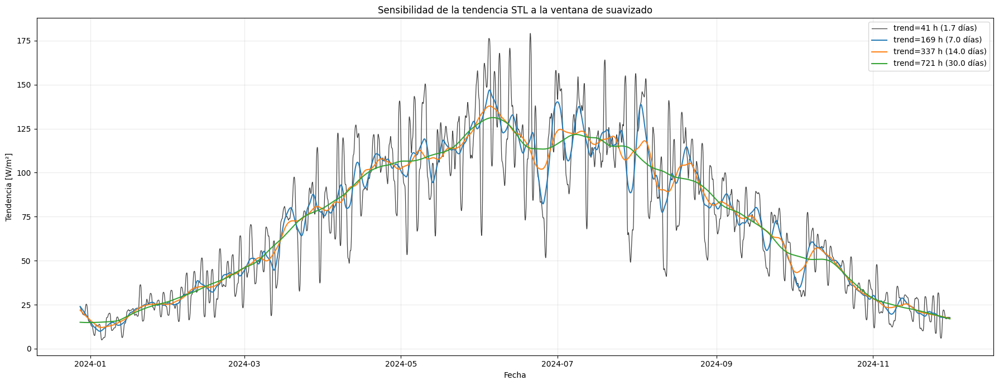

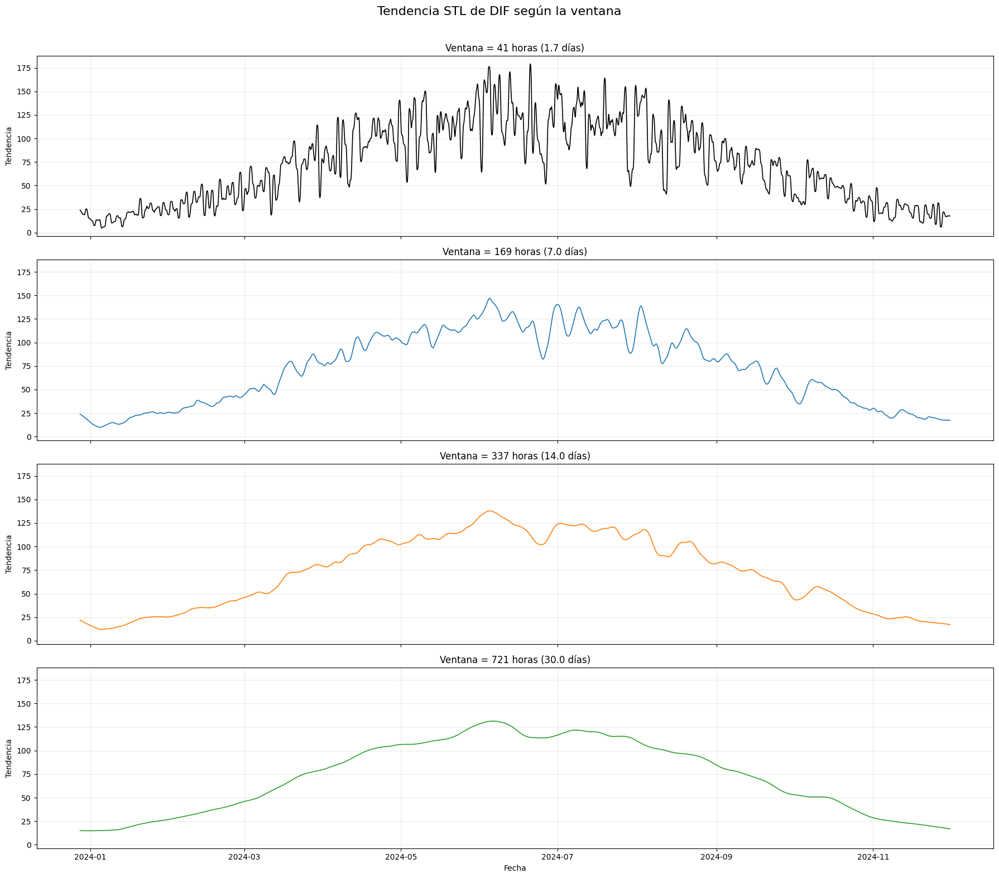

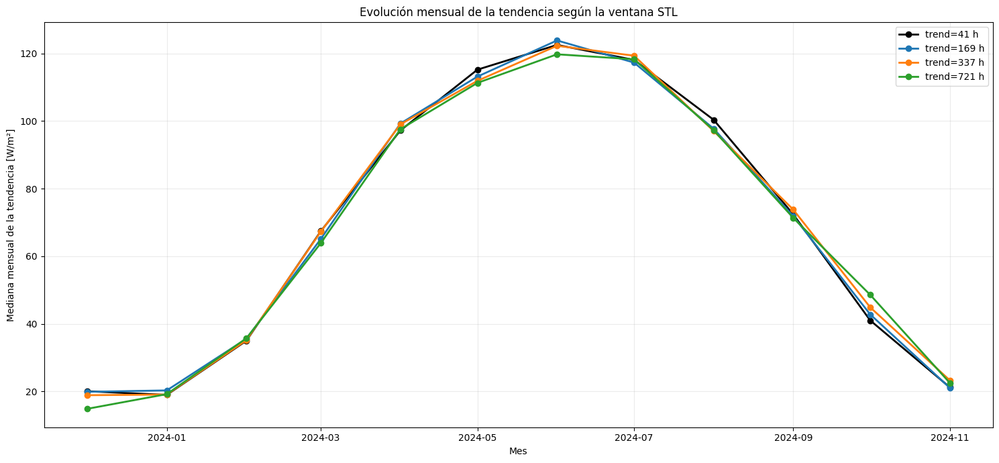

In [42]:
if "tendencias_sensibilidad_stl_dif" not in globals():
    raise NameError("Ejecuta primero la celda de sensibilidad.")

COLORES_TENDENCIA_SENSIBILIDAD = {41: "black", 169: "tab:blue", 337: "tab:orange", 721: "tab:green"}


# 1. Comparación conjunta
fig, eje = plt.subplots(figsize=(18, 7))
for ventana_tendencia in VENTANAS_TENDENCIA_STL_DIF:
    eje.plot(
        tendencias_sensibilidad_stl_dif.index,
        tendencias_sensibilidad_stl_dif[f"tendencia_{ventana_tendencia}h"],
        color=COLORES_TENDENCIA_SENSIBILIDAD[ventana_tendencia],
        linewidth=(0.9 if ventana_tendencia == 41 else 1.5),
        alpha=(0.75 if ventana_tendencia == 41 else 0.95),
        label=(f"trend={ventana_tendencia} h " f"({ventana_tendencia / 24:.1f} días)"),
    )

eje.set_xlabel("Fecha")
eje.set_ylabel("Tendencia [W/m²]")
eje.set_title("Sensibilidad de la tendencia STL " "a la ventana de suavizado")
eje.grid(alpha=0.25)
eje.legend()
plt.tight_layout()
plt.show()


# 2. Cada tendencia por separado con la misma escala
minimo_conjunto_tendencias = float(tendencias_sensibilidad_stl_dif.min().min())
maximo_conjunto_tendencias = float(tendencias_sensibilidad_stl_dif.max().max())
margen_tendencias = 0.05 * (maximo_conjunto_tendencias - minimo_conjunto_tendencias)
fig, ejes = plt.subplots(nrows=4, ncols=1, figsize=(18, 16), sharex=True, sharey=True)
for eje, ventana_tendencia in zip(ejes, VENTANAS_TENDENCIA_STL_DIF):
    eje.plot(
        tendencias_sensibilidad_stl_dif.index,
        tendencias_sensibilidad_stl_dif[f"tendencia_{ventana_tendencia}h"],
        color=COLORES_TENDENCIA_SENSIBILIDAD[ventana_tendencia],
        linewidth=1.2,
    )
    eje.set_ylabel("Tendencia")
    eje.set_title(f"Ventana = {ventana_tendencia} horas " f"({ventana_tendencia / 24:.1f} días)")
    eje.set_ylim(
        minimo_conjunto_tendencias - margen_tendencias,
        maximo_conjunto_tendencias + margen_tendencias,
    )
    eje.grid(alpha=0.25)

ejes[-1].set_xlabel("Fecha")
fig.suptitle("Tendencia STL de DIF según la ventana", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


# 3. Medianas mensuales
fig, eje = plt.subplots(figsize=(15, 7))
for ventana_tendencia in VENTANAS_TENDENCIA_STL_DIF:
    eje.plot(
        tendencias_mensuales_stl_dif.index,
        tendencias_mensuales_stl_dif[f"tendencia_{ventana_tendencia}h"],
        marker="o",
        linewidth=2,
        color=COLORES_TENDENCIA_SENSIBILIDAD[ventana_tendencia],
        label=f"trend={ventana_tendencia} h",
    )

eje.set_xlabel("Mes")
eje.set_ylabel("Mediana mensual de la tendencia [W/m²]")
eje.set_title("Evolución mensual de la tendencia " "según la ventana STL")
eje.grid(alpha=0.25)
eje.legend()
plt.tight_layout()
plt.show()

**Conclusión.**

El análisis de sensibilidad confirma que la estructura de baja frecuencia de DIF es estable frente a ventanas de tendencia de 7, 14 y 30 días. La serie presenta valores bajos en invierno, un crecimiento progresivo durante la primavera, un máximo o meseta alrededor de junio–julio y un descenso claro desde agosto hasta noviembre. Las fuertes oscilaciones observadas con la ventana automática de 41 horas corresponden principalmente a variabilidad de corto plazo y no deben interpretarse como cambios de la tendencia intraanual. La reducción entre junio y julio es pequeña y dependiente de la escala de suavizado, mientras que el descenso desde julio–agosto es más intenso y consistente.

## 10. ACF horaria de la serie original y del residuo STL

La ACF de la serie original mezcla varias causas de dependencia. Al compararla con la del residuo STL se comprueba si, una vez retirados el ciclo diario y la evolución lenta del año, las desviaciones restantes siguen relacionadas con sus valores pasados. El residuo procede de una STL con `robust=False` y ventana de tendencia de 721 horas.

### 10.1 Serie horaria original

Se reconstruye y valida la serie horaria utilizada en la STL.

,comprobacion,resultado
0,Primera hora,2023-12-28 00:00:00
1,Última hora,2024-11-30 23:00:00
2,Número de observaciones,8136
3,Valores ausentes,0
4,Timestamps duplicados,0
5,Frecuencia horaria regular,True
6,Mínimo,-3.216667
7,Media,72.437401
8,Mediana,9.125
9,Máximo,555.15


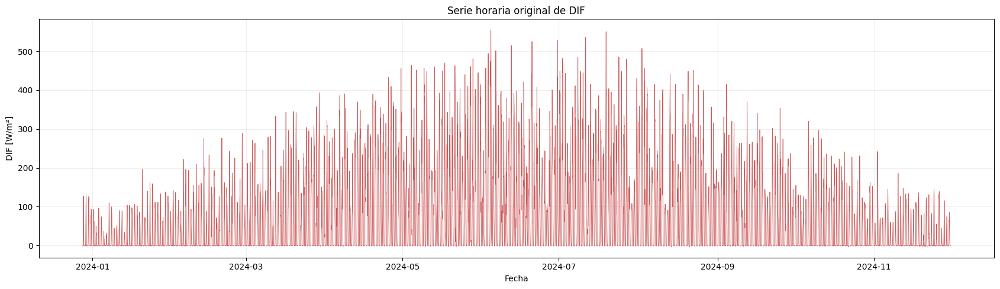

Directorio de resultados: /content/resultados_etapa2_acf_residuo_DIF_20261102_153806


In [43]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Comprobar los objetos de preparación
OBJETOS_REQUERIDOS_ETAPA2_DIF = ["df_stl_horario_media", "COL_DIF_STL"]


# Comprobar qué objetos requeridos no existen en memoria.
objetos_ausentes_etapa2_dif = [
    nombre for nombre in OBJETOS_REQUERIDOS_ETAPA2_DIF if nombre not in globals()
]
if objetos_ausentes_etapa2_dif:
    raise NameError("Faltan objetos de la preparación horaria: " f"{objetos_ausentes_etapa2_dif}")


# 2. Crear la carpeta general de resultados
marca_ejecucion_etapa2_dif = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
directorio_notebook_etapa2_dif = Path.cwd()
directorio_resultados_etapa2_dif = directorio_notebook_etapa2_dif / (
    "resultados_etapa2_acf_residuo_DIF_" f"{marca_ejecucion_etapa2_dif}"
)
directorio_resultados_etapa2_dif.mkdir(parents=True, exist_ok=True)
directorio_paso1_etapa2_dif = directorio_resultados_etapa2_dif / "01_serie_horaria_original"
directorio_paso1_etapa2_dif.mkdir(parents=True, exist_ok=True)


# 3. Recuperar la serie horaria
serie_horaria_original_etapa2_dif = df_stl_horario_media[COL_DIF_STL].copy().sort_index()
serie_horaria_original_etapa2_dif.name = "DIF_horaria_original"
if not isinstance(serie_horaria_original_etapa2_dif.index, pd.DatetimeIndex):

    # Detener la ejecución si no existe un índice temporal.
    raise TypeError("La serie horaria no tiene un DatetimeIndex.")

if serie_horaria_original_etapa2_dif.index.duplicated().any():
    raise ValueError("La serie horaria contiene timestamps duplicados.")

if not (serie_horaria_original_etapa2_dif.index.is_monotonic_increasing):

    # Detener la ejecución si el índice no está ordenado.
    raise ValueError("La serie horaria no está ordenada.")


# Colocar la serie sobre una cuadrícula horaria regular.
# Esta operación no calcula medias.
# La media ya estaba calculada en df_stl_horario_media.
serie_horaria_original_etapa2_dif = serie_horaria_original_etapa2_dif.asfreq("1h").astype(float)
if serie_horaria_original_etapa2_dif.isna().any():
    horas_ausentes_etapa2_dif = serie_horaria_original_etapa2_dif[
        serie_horaria_original_etapa2_dif.isna()
    ].index.tolist()

    # Detener la ejecución porque STL requiere una serie completa.
    raise ValueError(
        "La serie horaria contiene valores ausentes. "
        f"Primeras horas: {horas_ausentes_etapa2_dif[:10]}"
    )

if not np.isfinite(serie_horaria_original_etapa2_dif.to_numpy()).all():
    raise ValueError("La serie horaria contiene valores no finitos.")


# 4. Comprobar que la frecuencia es realmente horaria
diferencias_indice_etapa2_dif = serie_horaria_original_etapa2_dif.index.to_series().diff().dropna()
control_frecuencia_horaria_etapa2_dif = bool(
    (diferencias_indice_etapa2_dif == pd.Timedelta(hours=1)).all()
)


# Detener la ejecución si la frecuencia no es horaria.
if not control_frecuencia_horaria_etapa2_dif:
    raise ValueError("La separación entre observaciones " "no es siempre de una hora.")


# 5. Crear el resumen de la serie
resumen_serie_horaria_etapa2_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Primera hora",
            "Última hora",
            "Número de observaciones",
            "Valores ausentes",
            "Timestamps duplicados",
            "Frecuencia horaria regular",
            "Mínimo",
            "Media",
            "Mediana",
            "Máximo",
        ],
        "resultado": [
            serie_horaria_original_etapa2_dif.index.min(),
            serie_horaria_original_etapa2_dif.index.max(),
            len(serie_horaria_original_etapa2_dif),
            int(serie_horaria_original_etapa2_dif.isna().sum()),
            int(serie_horaria_original_etapa2_dif.index.duplicated().sum()),
            control_frecuencia_horaria_etapa2_dif,
            float(serie_horaria_original_etapa2_dif.min()),
            float(serie_horaria_original_etapa2_dif.mean()),
            float(serie_horaria_original_etapa2_dif.median()),
            float(serie_horaria_original_etapa2_dif.max()),
        ],
    }
)
display(resumen_serie_horaria_etapa2_dif)


# 6. Guardar la serie y su resumen
serie_horaria_original_etapa2_dif.to_csv(
    directorio_paso1_etapa2_dif / "serie_horaria_original_DIF.csv",
    sep=";",
    index=True,
    index_label="Date/Time",
    encoding="utf-8-sig",
)
resumen_serie_horaria_etapa2_dif.to_csv(
    directorio_paso1_etapa2_dif / "resumen_serie_horaria.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
)


# 7. Representar y guardar la serie horaria
fig_serie_etapa2_dif, eje_serie_etapa2_dif = plt.subplots(figsize=(17, 5))
eje_serie_etapa2_dif.plot(
    serie_horaria_original_etapa2_dif.index,
    serie_horaria_original_etapa2_dif,
    color="indianred",
    linewidth=0.65,
)
eje_serie_etapa2_dif.set_title("Serie horaria original de DIF")
eje_serie_etapa2_dif.set_xlabel("Fecha")
eje_serie_etapa2_dif.set_ylabel("DIF [W/m²]")
eje_serie_etapa2_dif.grid(alpha=0.20)
plt.tight_layout()
fig_serie_etapa2_dif.savefig(
    directorio_paso1_etapa2_dif / "serie_horaria_original_DIF.png", dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig_serie_etapa2_dif)


# 8. Guardar la configuración general
configuracion_general_etapa2_dif = {
    "marca_ejecucion": marca_ejecucion_etapa2_dif,
    "columna_DIF": COL_DIF_STL,
    "resolucion": "1 hora",
    "numero_observaciones": len(serie_horaria_original_etapa2_dif),
    "primera_hora": str(serie_horaria_original_etapa2_dif.index.min()),
    "ultima_hora": str(serie_horaria_original_etapa2_dif.index.max()),
}
with open(
    directorio_paso1_etapa2_dif / "configuracion_general.json", mode="w", encoding="utf-8"
) as archivo_configuracion_etapa2_dif:
    json.dump(
        configuracion_general_etapa2_dif,
        archivo_configuracion_etapa2_dif,
        ensure_ascii=False,
        indent=4,
    )

print("Directorio de resultados:", directorio_resultados_etapa2_dif)

### 10.2 Residuo STL

Se obtiene el residuo horario de una STL con `robust=False` y tendencia de 721 horas.

Configuración efectiva de STL:


,parametro,valor
0,period,24
1,seasonal,13
2,seasonal_deg,1
3,seasonal_jump,1
4,trend,721
5,trend_deg,1
6,trend_jump,1
7,low_pass,25
8,low_pass_deg,1
9,low_pass_jump,1


Control de la descomposición:


,comprobacion,resultado
0,Configuración robusta,False
1,Ventana de tendencia,721
2,Duración aproximada de tendencia,30.041667
3,Reconstrucción correcta,True
4,Error máximo de reconstrucción,0.0
5,Valores ausentes en el residuo,0


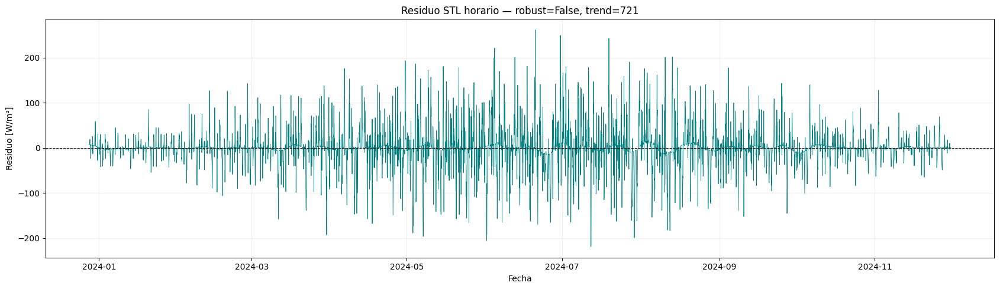

In [44]:
from statsmodels.tsa.seasonal import STL

# 1. Comprobar que existe la serie horaria
if "serie_horaria_original_etapa2_dif" not in globals():
    raise NameError("Primero debe ejecutarse la sección 10.1.")

directorio_paso2_etapa2_dif = directorio_resultados_etapa2_dif / "02_residuo_stl_principal"
directorio_paso2_etapa2_dif.mkdir(parents=True, exist_ok=True)


# 2. Definir la configuración STL elegida
PERIODO_STL_ETAPA2_DIF = 24
VENTANA_ESTACIONAL_STL_ETAPA2_DIF = 13
VENTANA_TENDENCIA_STL_ETAPA2_DIF = 721
VENTANA_LOWPASS_STL_ETAPA2_DIF = 25


# Indicar que no se utilizará el ajuste robusto.
ROBUST_STL_ETAPA2_DIF = False


# 3. Ajustar el modelo STL
modelo_stl_etapa2_dif = STL(
    endog=serie_horaria_original_etapa2_dif,
    period=PERIODO_STL_ETAPA2_DIF,
    seasonal=VENTANA_ESTACIONAL_STL_ETAPA2_DIF,
    trend=VENTANA_TENDENCIA_STL_ETAPA2_DIF,
    low_pass=VENTANA_LOWPASS_STL_ETAPA2_DIF,
    seasonal_deg=1,
    trend_deg=1,
    low_pass_deg=1,
    robust=ROBUST_STL_ETAPA2_DIF,
)
resultado_stl_etapa2_dif = modelo_stl_etapa2_dif.fit()


# 4. Guardar los componentes
componentes_stl_etapa2_dif = pd.DataFrame(
    {
        "DIF_observada": serie_horaria_original_etapa2_dif,
        "tendencia": np.asarray(resultado_stl_etapa2_dif.trend),
        "estacional": np.asarray(resultado_stl_etapa2_dif.seasonal),
        "residuo": np.asarray(resultado_stl_etapa2_dif.resid),
    },
    index=serie_horaria_original_etapa2_dif.index,
)
residuo_stl_horario_etapa2_dif = componentes_stl_etapa2_dif["residuo"].copy()
residuo_stl_horario_etapa2_dif.name = "residuo_STL_horario"


# 5. Comprobar la reconstrucción
reconstruccion_stl_etapa2_dif = (
    componentes_stl_etapa2_dif["tendencia"]
    + componentes_stl_etapa2_dif["estacional"]
    + componentes_stl_etapa2_dif["residuo"]
)
error_reconstruccion_stl_etapa2_dif = (
    componentes_stl_etapa2_dif["DIF_observada"] - reconstruccion_stl_etapa2_dif
)
max_error_reconstruccion_etapa2_dif = float(error_reconstruccion_stl_etapa2_dif.abs().max())
control_reconstruccion_etapa2_dif = bool(
    np.allclose(
        componentes_stl_etapa2_dif["DIF_observada"],
        reconstruccion_stl_etapa2_dif,
        rtol=1e-10,
        atol=1e-8,
    )
)


# Detener la ejecución si la reconstrucción no es correcta.
if not control_reconstruccion_etapa2_dif:
    raise ValueError("La reconstrucción STL no es correcta.")


# 6. Crear los resúmenes
configuracion_stl_etapa2_dif = pd.DataFrame(
    {
        "parametro": list(modelo_stl_etapa2_dif.config.keys()),
        "valor": list(modelo_stl_etapa2_dif.config.values()),
    }
)
resumen_componentes_stl_etapa2_dif = componentes_stl_etapa2_dif.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
control_stl_etapa2_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Configuración robusta",
            "Ventana de tendencia",
            "Duración aproximada de tendencia",
            "Reconstrucción correcta",
            "Error máximo de reconstrucción",
            "Valores ausentes en el residuo",
        ],
        "resultado": [
            ROBUST_STL_ETAPA2_DIF,
            VENTANA_TENDENCIA_STL_ETAPA2_DIF,
            (VENTANA_TENDENCIA_STL_ETAPA2_DIF / 24),
            control_reconstruccion_etapa2_dif,
            max_error_reconstruccion_etapa2_dif,
            int(residuo_stl_horario_etapa2_dif.isna().sum()),
        ],
    }
)
print("Configuración efectiva de STL:")
display(configuracion_stl_etapa2_dif)
print("Control de la descomposición:")
display(control_stl_etapa2_dif)


# 7. Guardar los resultados
componentes_stl_etapa2_dif.to_csv(
    directorio_paso2_etapa2_dif / "componentes_STL_principal.csv",
    sep=";",
    index=True,
    index_label="Date/Time",
    encoding="utf-8-sig",
)


# Guardar exclusivamente el residuo.
residuo_stl_horario_etapa2_dif.to_csv(
    directorio_paso2_etapa2_dif / "residuo_STL_horario.csv",
    sep=";",
    index=True,
    index_label="Date/Time",
    encoding="utf-8-sig",
)
configuracion_stl_etapa2_dif.to_csv(
    directorio_paso2_etapa2_dif / "configuracion_STL.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
)
resumen_componentes_stl_etapa2_dif.to_csv(
    directorio_paso2_etapa2_dif / "resumen_componentes_STL.csv",
    sep=";",
    index=True,
    encoding="utf-8-sig",
)
control_stl_etapa2_dif.to_csv(
    directorio_paso2_etapa2_dif / "control_STL.csv", sep=";", index=False, encoding="utf-8-sig"
)


# 8. Representar el residuo
fig_residuo_etapa2_dif, eje_residuo_etapa2_dif = plt.subplots(figsize=(17, 5))
eje_residuo_etapa2_dif.plot(
    residuo_stl_horario_etapa2_dif.index,
    residuo_stl_horario_etapa2_dif,
    color="teal",
    linewidth=0.60,
)
eje_residuo_etapa2_dif.axhline(y=0, color="black", linestyle="--", linewidth=0.8)
eje_residuo_etapa2_dif.set_title("Residuo STL horario — robust=False, trend=721")
eje_residuo_etapa2_dif.set_xlabel("Fecha")
eje_residuo_etapa2_dif.set_ylabel("Residuo [W/m²]")
eje_residuo_etapa2_dif.grid(alpha=0.20)
plt.tight_layout()
fig_residuo_etapa2_dif.savefig(
    directorio_paso2_etapa2_dif / "residuo_STL_horario.png", dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig_residuo_etapa2_dif)

### 10.3 Control de alineación

Se comprueba que la serie original y el residuo tienen las mismas fechas, frecuencia y longitud.

In [45]:
if (
    "serie_horaria_original_etapa2_dif" not in globals()
    or "residuo_stl_horario_etapa2_dif" not in globals()
):
    raise NameError("Deben ejecutarse antes las secciones 10.1 y 10.2.")

directorio_paso3_etapa2_dif = directorio_resultados_etapa2_dif / "03_control_alineacion"
directorio_paso3_etapa2_dif.mkdir(parents=True, exist_ok=True)
indices_iguales_etapa2_dif = bool(
    serie_horaria_original_etapa2_dif.index.equals(residuo_stl_horario_etapa2_dif.index)
)
longitudes_iguales_etapa2_dif = bool(
    len(serie_horaria_original_etapa2_dif) == len(residuo_stl_horario_etapa2_dif)
)
ausentes_original_etapa2_dif = int(serie_horaria_original_etapa2_dif.isna().sum())
ausentes_residuo_etapa2_dif = int(residuo_stl_horario_etapa2_dif.isna().sum())
datos_alineados_etapa2_dif = pd.concat(
    [serie_horaria_original_etapa2_dif, residuo_stl_horario_etapa2_dif], axis=1, join="inner"
)


# Comprobar que no se ha perdido ninguna observación.
alineacion_completa_etapa2_dif = bool(
    len(datos_alineados_etapa2_dif) == len(serie_horaria_original_etapa2_dif)
)
control_alineacion_etapa2_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Índices exactamente iguales",
            "Longitudes iguales",
            "Ausentes en serie original",
            "Ausentes en residuo",
            "Alineación completa",
            "Primera hora original",
            "Primera hora residuo",
            "Última hora original",
            "Última hora residuo",
        ],
        "resultado": [
            indices_iguales_etapa2_dif,
            longitudes_iguales_etapa2_dif,
            ausentes_original_etapa2_dif,
            ausentes_residuo_etapa2_dif,
            alineacion_completa_etapa2_dif,
            serie_horaria_original_etapa2_dif.index.min(),
            residuo_stl_horario_etapa2_dif.index.min(),
            serie_horaria_original_etapa2_dif.index.max(),
            residuo_stl_horario_etapa2_dif.index.max(),
        ],
    }
)
display(control_alineacion_etapa2_dif)


# Detener la ejecución si los índices no coinciden.
if not indices_iguales_etapa2_dif:
    raise ValueError("Los índices de la serie original " "y del residuo no coinciden.")


# Detener la ejecución si las longitudes no coinciden.
if not longitudes_iguales_etapa2_dif:
    raise ValueError("Las longitudes de las series no coinciden.")

control_alineacion_etapa2_dif.to_csv(
    directorio_paso3_etapa2_dif / "control_alineacion.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
)
datos_alineados_etapa2_dif.to_csv(
    directorio_paso3_etapa2_dif / "serie_original_y_residuo_alineados.csv",
    sep=";",
    index=True,
    index_label="Date/Time",
    encoding="utf-8-sig",
)

,comprobacion,resultado
0,Índices exactamente iguales,True
1,Longitudes iguales,True
2,Ausentes en serie original,0
3,Ausentes en residuo,0
4,Alineación completa,True
5,Primera hora original,2023-12-28 00:00:00
6,Primera hora residuo,2023-12-28 00:00:00
7,Última hora original,2024-11-30 23:00:00
8,Última hora residuo,2024-11-30 23:00:00


### 10.4 ACF de la serie original

ACF de referencia, que incluye tendencia, estacionalidad y residuo.

/tmp/ipykernel_1005/1172941627.py:5: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_acf_original_etapa2_dif = acf(


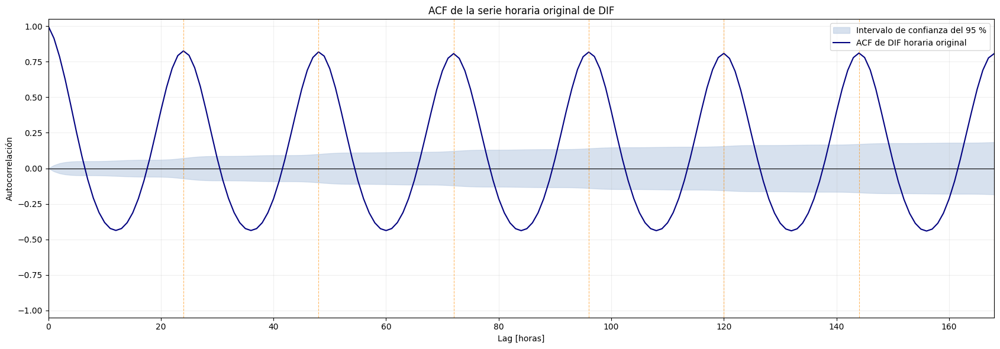

In [46]:
from statsmodels.tsa.stattools import acf
directorio_paso4_etapa2_dif = directorio_resultados_etapa2_dif / "04_acf_serie_original"
directorio_paso4_etapa2_dif.mkdir(parents=True, exist_ok=True)
MAX_LAG_HORARIO_ETAPA2_DIF = 168
resultado_acf_original_etapa2_dif = acf(
    serie_horaria_original_etapa2_dif.to_numpy(),
    nlags=MAX_LAG_HORARIO_ETAPA2_DIF,
    fft=True,
    alpha=0.05,
    adjusted=False,
    missing="raise",
)
valores_acf_original_etapa2_dif = resultado_acf_original_etapa2_dif[0]
intervalos_acf_original_etapa2_dif = resultado_acf_original_etapa2_dif[1]
lags_horarios_etapa2_dif = np.arange(MAX_LAG_HORARIO_ETAPA2_DIF + 1)
banda_inferior_original_etapa2_dif = (
    intervalos_acf_original_etapa2_dif[:, 0] - valores_acf_original_etapa2_dif
)
banda_superior_original_etapa2_dif = (
    intervalos_acf_original_etapa2_dif[:, 1] - valores_acf_original_etapa2_dif
)
tabla_acf_original_etapa2_dif = pd.DataFrame(
    {
        "lag_horas": lags_horarios_etapa2_dif,
        "autocorrelacion_original": valores_acf_original_etapa2_dif,
        "IC95_inferior_original": intervalos_acf_original_etapa2_dif[:, 0],
        "IC95_superior_original": intervalos_acf_original_etapa2_dif[:, 1],
        "parejas_teoricas": len(serie_horaria_original_etapa2_dif) - lags_horarios_etapa2_dif,
    }
)
tabla_acf_original_etapa2_dif.to_csv(
    directorio_paso4_etapa2_dif / "acf_serie_horaria_original.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
)
fig_acf_original_etapa2_dif, eje_acf_original_etapa2_dif = plt.subplots(figsize=(17, 6))
eje_acf_original_etapa2_dif.fill_between(
    lags_horarios_etapa2_dif,
    banda_inferior_original_etapa2_dif,
    banda_superior_original_etapa2_dif,
    color="lightsteelblue",
    alpha=0.50,
    label="Intervalo de confianza del 95 %",
)
eje_acf_original_etapa2_dif.axhline(y=0, color="black", linewidth=0.8)
eje_acf_original_etapa2_dif.plot(
    lags_horarios_etapa2_dif,
    valores_acf_original_etapa2_dif,
    color="navy",
    linewidth=1.5,
    label="ACF de DIF horaria original",
)
for lag_diario_etapa2_dif in range(24, MAX_LAG_HORARIO_ETAPA2_DIF + 1, 24):
    eje_acf_original_etapa2_dif.axvline(
        x=lag_diario_etapa2_dif, color="darkorange", linestyle="--", linewidth=0.8, alpha=0.60
    )

eje_acf_original_etapa2_dif.set_xlim(0, MAX_LAG_HORARIO_ETAPA2_DIF)
eje_acf_original_etapa2_dif.set_ylim(-1.05, 1.05)
eje_acf_original_etapa2_dif.set_xlabel("Lag [horas]")
eje_acf_original_etapa2_dif.set_ylabel("Autocorrelación")
eje_acf_original_etapa2_dif.set_title("ACF de la serie horaria original de DIF")
eje_acf_original_etapa2_dif.grid(alpha=0.20)
eje_acf_original_etapa2_dif.legend()
plt.tight_layout()
fig_acf_original_etapa2_dif.savefig(
    directorio_paso4_etapa2_dif / "acf_serie_horaria_original.png", dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig_acf_original_etapa2_dif)

### 10.5 ACF del residuo STL

Dependencia lineal que queda después de retirar la tendencia y el ciclo diario.

/tmp/ipykernel_1005/2711164475.py:3: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_acf_residuo_etapa2_dif = acf(


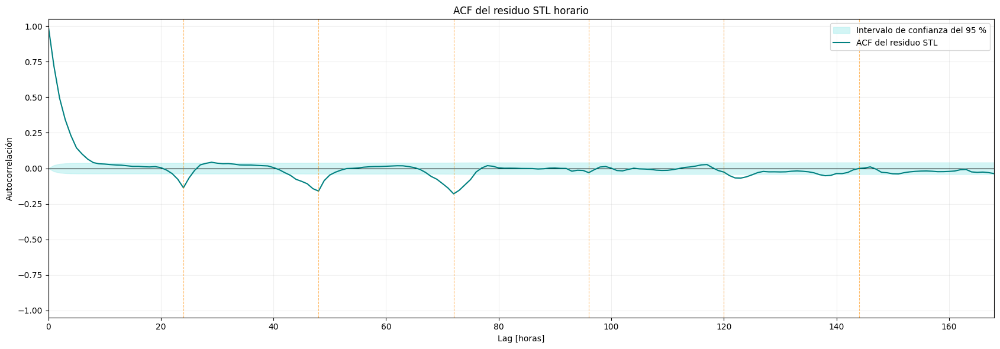

In [47]:
directorio_paso5_etapa2_dif = directorio_resultados_etapa2_dif / "05_acf_residuo"
directorio_paso5_etapa2_dif.mkdir(parents=True, exist_ok=True)
resultado_acf_residuo_etapa2_dif = acf(
    residuo_stl_horario_etapa2_dif.to_numpy(),
    nlags=MAX_LAG_HORARIO_ETAPA2_DIF,
    fft=True,
    alpha=0.05,
    adjusted=False,
    missing="raise",
)
valores_acf_residuo_etapa2_dif = resultado_acf_residuo_etapa2_dif[0]
intervalos_acf_residuo_etapa2_dif = resultado_acf_residuo_etapa2_dif[1]
banda_inferior_residuo_etapa2_dif = (
    intervalos_acf_residuo_etapa2_dif[:, 0] - valores_acf_residuo_etapa2_dif
)
banda_superior_residuo_etapa2_dif = (
    intervalos_acf_residuo_etapa2_dif[:, 1] - valores_acf_residuo_etapa2_dif
)
tabla_acf_residuo_etapa2_dif = pd.DataFrame(
    {
        "lag_horas": lags_horarios_etapa2_dif,
        "autocorrelacion_residuo": valores_acf_residuo_etapa2_dif,
        "IC95_inferior_residuo": intervalos_acf_residuo_etapa2_dif[:, 0],
        "IC95_superior_residuo": intervalos_acf_residuo_etapa2_dif[:, 1],
        "parejas_teoricas": len(residuo_stl_horario_etapa2_dif) - lags_horarios_etapa2_dif,
    }
)
tabla_acf_residuo_etapa2_dif.to_csv(
    directorio_paso5_etapa2_dif / "acf_residuo_STL_horario.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
)
fig_acf_residuo_etapa2_dif, eje_acf_residuo_etapa2_dif = plt.subplots(figsize=(17, 6))
eje_acf_residuo_etapa2_dif.fill_between(
    lags_horarios_etapa2_dif,
    banda_inferior_residuo_etapa2_dif,
    banda_superior_residuo_etapa2_dif,
    color="paleturquoise",
    alpha=0.55,
    label="Intervalo de confianza del 95 %",
)
eje_acf_residuo_etapa2_dif.axhline(y=0, color="black", linewidth=0.8)
eje_acf_residuo_etapa2_dif.plot(
    lags_horarios_etapa2_dif,
    valores_acf_residuo_etapa2_dif,
    color="teal",
    linewidth=1.5,
    label="ACF del residuo STL",
)
for lag_diario_etapa2_dif in range(24, MAX_LAG_HORARIO_ETAPA2_DIF + 1, 24):
    eje_acf_residuo_etapa2_dif.axvline(
        x=lag_diario_etapa2_dif, color="darkorange", linestyle="--", linewidth=0.8, alpha=0.60
    )

eje_acf_residuo_etapa2_dif.set_xlim(0, MAX_LAG_HORARIO_ETAPA2_DIF)
eje_acf_residuo_etapa2_dif.set_ylim(-1.05, 1.05)
eje_acf_residuo_etapa2_dif.set_xlabel("Lag [horas]")
eje_acf_residuo_etapa2_dif.set_ylabel("Autocorrelación")
eje_acf_residuo_etapa2_dif.set_title("ACF del residuo STL horario")
eje_acf_residuo_etapa2_dif.grid(alpha=0.20)
eje_acf_residuo_etapa2_dif.legend()
plt.tight_layout()
fig_acf_residuo_etapa2_dif.savefig(
    directorio_paso5_etapa2_dif / "acf_residuo_STL_horario.png", dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig_acf_residuo_etapa2_dif)

### 10.6 Comparación de ambas ACF

Qué estructura desaparece y cuál permanece.

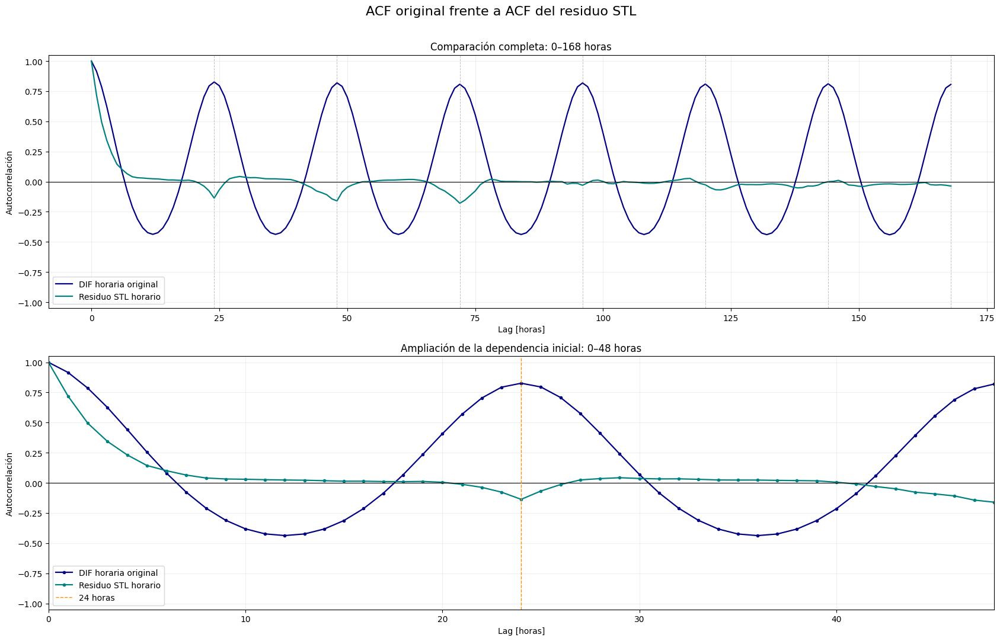

In [48]:
directorio_paso6_etapa2_dif = directorio_resultados_etapa2_dif / "06_comparacion_acf"
directorio_paso6_etapa2_dif.mkdir(parents=True, exist_ok=True)
comparacion_acf_etapa2_dif = pd.DataFrame(
    {
        "lag_horas": lags_horarios_etapa2_dif,
        "acf_original": valores_acf_original_etapa2_dif,
        "acf_residuo": valores_acf_residuo_etapa2_dif,
    }
)
comparacion_acf_etapa2_dif["diferencia_residuo_menos_original"] = (
    comparacion_acf_etapa2_dif["acf_residuo"] - comparacion_acf_etapa2_dif["acf_original"]
)
comparacion_acf_etapa2_dif.to_csv(
    directorio_paso6_etapa2_dif / "comparacion_acf_original_residuo.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
)
fig_comparacion_etapa2_dif, ejes_comparacion_etapa2_dif = plt.subplots(
    nrows=2, ncols=1, figsize=(17, 11)
)
eje_semana_comparacion_etapa2_dif = ejes_comparacion_etapa2_dif[0]
eje_corto_comparacion_etapa2_dif = ejes_comparacion_etapa2_dif[1]
eje_semana_comparacion_etapa2_dif.plot(
    lags_horarios_etapa2_dif,
    valores_acf_original_etapa2_dif,
    color="navy",
    linewidth=1.6,
    label="DIF horaria original",
)
eje_semana_comparacion_etapa2_dif.plot(
    lags_horarios_etapa2_dif,
    valores_acf_residuo_etapa2_dif,
    color="teal",
    linewidth=1.6,
    label="Residuo STL horario",
)
eje_semana_comparacion_etapa2_dif.axhline(y=0, color="black", linewidth=0.8)
for lag_diario_etapa2_dif in range(24, MAX_LAG_HORARIO_ETAPA2_DIF + 1, 24):
    eje_semana_comparacion_etapa2_dif.axvline(
        x=lag_diario_etapa2_dif, color="grey", linestyle="--", linewidth=0.7, alpha=0.50
    )

eje_semana_comparacion_etapa2_dif.set_title("Comparación completa: 0–168 horas")
eje_semana_comparacion_etapa2_dif.set_xlabel("Lag [horas]")
eje_semana_comparacion_etapa2_dif.set_ylabel("Autocorrelación")
eje_semana_comparacion_etapa2_dif.set_ylim(-1.05, 1.05)
eje_semana_comparacion_etapa2_dif.grid(alpha=0.20)
eje_semana_comparacion_etapa2_dif.legend()
eje_corto_comparacion_etapa2_dif.plot(
    lags_horarios_etapa2_dif[:49],
    valores_acf_original_etapa2_dif[:49],
    color="navy",
    marker="o",
    markersize=3,
    linewidth=1.6,
    label="DIF horaria original",
)
eje_corto_comparacion_etapa2_dif.plot(
    lags_horarios_etapa2_dif[:49],
    valores_acf_residuo_etapa2_dif[:49],
    color="teal",
    marker="o",
    markersize=3,
    linewidth=1.6,
    label="Residuo STL horario",
)
eje_corto_comparacion_etapa2_dif.axhline(y=0, color="black", linewidth=0.8)
eje_corto_comparacion_etapa2_dif.axvline(
    x=24, color="darkorange", linestyle="--", linewidth=1, label="24 horas"
)
eje_corto_comparacion_etapa2_dif.set_title("Ampliación de la dependencia inicial: 0–48 horas")
eje_corto_comparacion_etapa2_dif.set_xlabel("Lag [horas]")
eje_corto_comparacion_etapa2_dif.set_ylabel("Autocorrelación")
eje_corto_comparacion_etapa2_dif.set_xlim(0, 48)
eje_corto_comparacion_etapa2_dif.set_ylim(-1.05, 1.05)
eje_corto_comparacion_etapa2_dif.grid(alpha=0.20)
eje_corto_comparacion_etapa2_dif.legend()
fig_comparacion_etapa2_dif.suptitle("ACF original frente a ACF del residuo STL", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
fig_comparacion_etapa2_dif.savefig(
    directorio_paso6_etapa2_dif / "comparacion_acf_original_residuo.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig_comparacion_etapa2_dif)

### 10.7 Retardos clave

Comparación numérica de los retardos más relevantes.

,lag_horas,equivalencia,acf_original,acf_residuo,reduccion_magnitud,porcentaje_magnitud_restante,IC95_inferior_residuo,IC95_superior_residuo,parejas_teoricas
0,1,1 hora,0.9154,0.7186,0.1968,78.50 %,0.6968,0.7403,"8,135"
1,2,2 horas,0.7854,0.4942,0.2911,62.93 %,0.4633,0.5252,"8,134"
2,3,3 horas,0.6245,0.3433,0.2812,54.97 %,0.3088,0.3778,"8,133"
3,6,6 horas,0.0798,0.1005,-0.0206,125.85 %,0.0635,0.1375,"8,130"
4,12,12 horas,-0.4373,0.0235,0.4138,5.36 %,-0.0138,0.0607,"8,124"
5,24,1 día,0.8262,-0.1369,0.6893,16.57 %,-0.1743,-0.0995,"8,112"
6,48,2 días,0.8190,-0.1603,0.6587,19.58 %,-0.1988,-0.1219,"8,088"
7,168,1 semana,0.8066,-0.0369,0.7697,4.58 %,-0.0779,0.0040,"7,968"


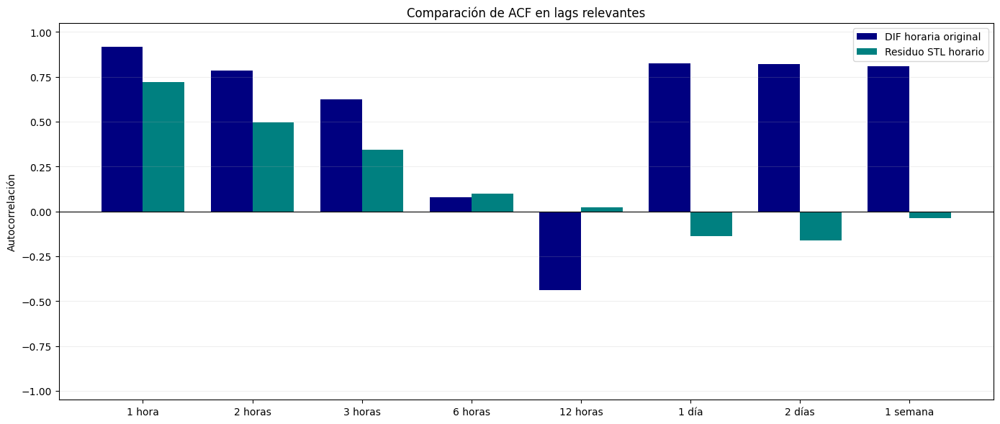

In [49]:
directorio_paso7_etapa2_dif = directorio_resultados_etapa2_dif / "07_lags_clave"
directorio_paso7_etapa2_dif.mkdir(parents=True, exist_ok=True)
lags_clave_etapa2_dif = [1, 2, 3, 6, 12, 24, 48, 168]


# Crear las equivalencias temporales.
equivalencias_lags_etapa2_dif = {
    1: "1 hora",
    2: "2 horas",
    3: "3 horas",
    6: "6 horas",
    12: "12 horas",
    24: "1 día",
    48: "2 días",
    168: "1 semana",
}
filas_lags_clave_etapa2_dif = []
for lag_etapa2_dif in lags_clave_etapa2_dif:
    acf_original_lag_etapa2_dif = float(valores_acf_original_etapa2_dif[lag_etapa2_dif])
    acf_residuo_lag_etapa2_dif = float(valores_acf_residuo_etapa2_dif[lag_etapa2_dif])
    reduccion_magnitud_etapa2_dif = abs(acf_original_lag_etapa2_dif) - abs(
        acf_residuo_lag_etapa2_dif
    )
    if abs(acf_original_lag_etapa2_dif) >= 0.05:
        porcentaje_restante_etapa2_dif = (
            100 * abs(acf_residuo_lag_etapa2_dif) / abs(acf_original_lag_etapa2_dif)
        )

    else:
        porcentaje_restante_etapa2_dif = np.nan

    filas_lags_clave_etapa2_dif.append(
        {
            "lag_horas": lag_etapa2_dif,
            "equivalencia": equivalencias_lags_etapa2_dif[lag_etapa2_dif],
            "acf_original": acf_original_lag_etapa2_dif,
            "acf_residuo": acf_residuo_lag_etapa2_dif,
            "reduccion_magnitud": reduccion_magnitud_etapa2_dif,
            "porcentaje_magnitud_restante": porcentaje_restante_etapa2_dif,
            "IC95_inferior_residuo": float(intervalos_acf_residuo_etapa2_dif[lag_etapa2_dif, 0]),
            "IC95_superior_residuo": float(intervalos_acf_residuo_etapa2_dif[lag_etapa2_dif, 1]),
            "parejas_teoricas": int(len(residuo_stl_horario_etapa2_dif) - lag_etapa2_dif),
        }
    )

tabla_lags_clave_etapa2_dif = pd.DataFrame(filas_lags_clave_etapa2_dif)
display(
    tabla_lags_clave_etapa2_dif.style.format(
        {
            "acf_original": "{:.4f}",
            "acf_residuo": "{:.4f}",
            "reduccion_magnitud": "{:.4f}",
            "porcentaje_magnitud_restante": "{:.2f} %",
            "IC95_inferior_residuo": "{:.4f}",
            "IC95_superior_residuo": "{:.4f}",
            "parejas_teoricas": "{:,}",
        }
    )
)
tabla_lags_clave_etapa2_dif.to_csv(
    directorio_paso7_etapa2_dif / "tabla_lags_clave.csv", sep=";", index=False, encoding="utf-8-sig"
)
fig_lags_clave_etapa2_dif, eje_lags_clave_etapa2_dif = plt.subplots(figsize=(14, 6))
posiciones_lags_etapa2_dif = np.arange(len(lags_clave_etapa2_dif))
anchura_barras_etapa2_dif = 0.38
eje_lags_clave_etapa2_dif.bar(
    posiciones_lags_etapa2_dif - anchura_barras_etapa2_dif / 2,
    tabla_lags_clave_etapa2_dif["acf_original"],
    width=anchura_barras_etapa2_dif,
    color="navy",
    label="DIF horaria original",
)
eje_lags_clave_etapa2_dif.bar(
    posiciones_lags_etapa2_dif + anchura_barras_etapa2_dif / 2,
    tabla_lags_clave_etapa2_dif["acf_residuo"],
    width=anchura_barras_etapa2_dif,
    color="teal",
    label="Residuo STL horario",
)
eje_lags_clave_etapa2_dif.axhline(y=0, color="black", linewidth=0.8)
eje_lags_clave_etapa2_dif.set_xticks(posiciones_lags_etapa2_dif)


# Utilizar las equivalencias como etiquetas.
eje_lags_clave_etapa2_dif.set_xticklabels(tabla_lags_clave_etapa2_dif["equivalencia"])
eje_lags_clave_etapa2_dif.set_ylabel("Autocorrelación")
eje_lags_clave_etapa2_dif.set_title("Comparación de ACF en lags relevantes")
eje_lags_clave_etapa2_dif.set_ylim(-1.05, 1.05)
eje_lags_clave_etapa2_dif.grid(axis="y", alpha=0.20)
eje_lags_clave_etapa2_dif.legend()
plt.tight_layout()
fig_lags_clave_etapa2_dif.savefig(
    directorio_paso7_etapa2_dif / "comparacion_lags_clave.png", dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig_lags_clave_etapa2_dif)

### Interpretación

Con el objetivo de diferenciar la dependencia asociada al ciclo solar de la persistencia temporal de las desviaciones de la irradiancia difusa, se comparó la función de autocorrelación de la serie horaria original con la correspondiente al residuo de una descomposición STL. La descomposición se configuró con periodo diario de 24 horas, ventana estacional de 13 observaciones, ventana de tendencia de 721 horas —aproximadamente 30 días— y estimación no robusta. La serie analizada estuvo formada por 8.136 observaciones horarias regulares, sin valores ausentes ni desalineaciones. La reconstrucción de la serie mediante la suma de tendencia, estacionalidad y residuo presentó un error máximo de $5{,}68 \times 10^{-14}$, por lo que se consideró numéricamente correcta.

La ACF de la serie original presentó una estructura periódica muy marcada, con una autocorrelación de 0,915 a una hora, −0,437 a doce horas y 0,826 a veinticuatro horas. Este comportamiento muestra la influencia del ciclo diario de la radiación: las observaciones próximas pertenecen normalmente a fases semejantes del ciclo solar, las separadas doce horas corresponden a fases opuestas y las separadas veinticuatro horas vuelven a situarse aproximadamente en la misma fase.

Después de retirar la tendencia y la componente estacional diaria, la ACF del residuo mostró un comportamiento diferente. La autocorrelación residual fue de 0,719 a una hora, 0,494 a dos horas y 0,343 a tres horas. A continuación disminuyó hasta 0,100 a seis horas y 0,040 a ocho horas. El primer retardo cuyo intervalo de confianza incluyó el cero fue el de nueve horas. Estos resultados indican que las desviaciones respecto al patrón temporal esperado presentan una persistencia lineal clara a corto plazo, especialmente durante las primeras tres horas, que se debilita progresivamente y resulta prácticamente despreciable a partir de ocho o nueve horas. Esta persistencia es compatible con la continuidad temporal de las condiciones atmosféricas, aunque la ACF no permite atribuir por sí sola una causa física concreta.

En el retardo de veinticuatro horas, la autocorrelación pasó de 0,826 en la serie original a −0,137 en el residuo. Por tanto, la fuerte asociación positiva diaria desapareció tras la descomposición, lo que confirma que procedía principalmente de la estacionalidad solar. No obstante, el valor residual fue significativamente negativo, por lo que no puede afirmarse que exista una independencia completa a veinticuatro horas. La magnitud de esta anticorrelación fue reducida y representó menos del 2 % de asociación lineal bivariada al considerar su valor cuadrático. También se observaron anticorrelaciones débiles a 48 y 72 horas, mientras que a partir de 96 horas los múltiplos diarios fueron compatibles con una autocorrelación nula. A una semana, la ACF residual fue −0,037 y su intervalo de confianza incluyó el cero, por lo que no se encontró evidencia de una dependencia lineal residual semanal.

En conjunto, el análisis permite distinguir dos mecanismos. La repetición observada cada veinticuatro horas en la serie original está dominada por el patrón diario de la radiación, mientras que el residuo conserva una memoria de corto plazo asociada a la continuidad de las desviaciones respecto a ese patrón. Para la predicción de la siguiente hora mediante N-BEATS, estos resultados respaldan la utilización de las observaciones más recientes y justifican la evaluación de ventanas de entrada de 6, 12, 24 y 48 horas. Una ventana de 24 horas puede resultar especialmente útil al contener tanto la memoria reciente como un ciclo diario completo, aunque su rendimiento deberá verificarse mediante validación cronológica y compararse con modelos de persistencia horaria y estacional. Los componentes obtenidos mediante STL se emplean únicamente con finalidad descriptiva y no se introducen directamente en el modelo predictivo, dado que fueron estimados utilizando la serie completa.

## 11. PACF horaria de la serie original y del residuo STL

La PACF mide la relación lineal directa con cada retardo, una vez descontada la influencia de los retardos intermedios.

### 11.1 Preparación y validación

In [50]:
# 1. Importar las librerías necesarias
from pathlib import Path
import json

# Importar ZIPFile para comprimir todos los resultados.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from IPython.display import display
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.stattools import pacf

# 2. Identificar la serie horaria utilizada anteriormente

# Guardar el nombre exacto de la serie horaria de la sección 10.
NOMBRE_OBJETO_ORIGEN_PACF_HOR = "serie_horaria_original_etapa2_dif"

# Comprobar que la serie horaria existe en la memoria del notebook.
if NOMBRE_OBJETO_ORIGEN_PACF_HOR not in globals():
    raise NameError(
        "No existe el objeto "
        "'serie_horaria_original_etapa2_dif'. "
        "Ejecuta primero la sección 10.1, "
        "donde se recupera y valida la serie horaria original."
    )

objeto_origen_pacf_hor_original = globals()[NOMBRE_OBJETO_ORIGEN_PACF_HOR]
if not isinstance(objeto_origen_pacf_hor_original, pd.Series):

    # Detener la ejecución si el objeto no es una serie.
    raise TypeError("'serie_horaria_original_etapa2_dif' " "debe ser una pd.Series.")


# 3. Crear una copia exclusiva para la PACF horaria

# Copiar la serie para no modificar el objeto utilizado anteriormente.
serie_dif_horaria_pacf_original = objeto_origen_pacf_hor_original.copy(deep=True)
serie_dif_horaria_pacf_original = serie_dif_horaria_pacf_original.astype(float)
serie_dif_horaria_pacf_original.name = "DIF_horaria_PACF_original"


# 4. Validar el índice temporal
if not isinstance(serie_dif_horaria_pacf_original.index, pd.DatetimeIndex):

    # Detener la ejecución si el índice no es temporal.
    raise TypeError("La serie horaria no tiene un DatetimeIndex.")

n_duplicados_pacf_hor_original = int(serie_dif_horaria_pacf_original.index.duplicated().sum())
if n_duplicados_pacf_hor_original > 0:
    raise ValueError(
        "La serie horaria contiene " f"{n_duplicados_pacf_hor_original} timestamps duplicados."
    )

if not (serie_dif_horaria_pacf_original.index.is_monotonic_increasing):

    # Detener la ejecución si la serie no está ordenada.
    raise ValueError("La serie horaria no está ordenada cronológicamente.")

diferencias_indice_pacf_hor_original = (
    serie_dif_horaria_pacf_original.index.to_series().diff().dropna()
)
control_frecuencia_pacf_hor_original = bool(
    (diferencias_indice_pacf_hor_original == pd.Timedelta(hours=1)).all()
)

# Detener la ejecución si la cuadrícula no es horaria.
if not control_frecuencia_pacf_hor_original:

    # Informar de que los retardos no podrían interpretarse como horas.
    raise ValueError("La separación entre observaciones " "no es siempre de una hora.")


# 5. Validar los valores de la serie
n_total_pacf_hor_original = int(len(serie_dif_horaria_pacf_original))

# Contar las observaciones horarias no ausentes.
n_validos_pacf_hor_original = int(serie_dif_horaria_pacf_original.notna().sum())
n_ausentes_pacf_hor_original = int(serie_dif_horaria_pacf_original.isna().sum())
if n_ausentes_pacf_hor_original > 0:
    primeras_ausencias_pacf_hor_original = serie_dif_horaria_pacf_original[
        serie_dif_horaria_pacf_original.isna()
    ].index.tolist()[:10]
    raise ValueError(
        "La serie horaria contiene valores ausentes. "
        "La PACF estándar no se calculará hasta resolverlos. "
        f"Primeras horas ausentes: "
        f"{primeras_ausencias_pacf_hor_original}"
    )

valores_dif_horaria_pacf_original = serie_dif_horaria_pacf_original.to_numpy(dtype=float)
if not np.isfinite(valores_dif_horaria_pacf_original).all():
    raise ValueError("La serie horaria contiene valores no finitos.")


# 6. Comprobar que la copia coincide con la serie original
control_indices_iguales_pacf_hor_original = bool(
    serie_dif_horaria_pacf_original.index.equals(objeto_origen_pacf_hor_original.index)
)
control_valores_iguales_pacf_hor_original = bool(
    np.array_equal(
        serie_dif_horaria_pacf_original.to_numpy(dtype=float),
        objeto_origen_pacf_hor_original.to_numpy(dtype=float),
        equal_nan=True,
    )
)
control_identidad_pacf_hor_original = bool(
    control_indices_iguales_pacf_hor_original and control_valores_iguales_pacf_hor_original
)

# Detener la ejecución si la copia no coincide con el origen.
if not control_identidad_pacf_hor_original:
    raise RuntimeError(
        "La serie preparada para la PACF no coincide "
        "con la serie horaria utilizada en la sección 10."
    )


# 7. Definir la configuración de la PACF
MAX_LAG_PACF_HOR_ORIGINAL = 168
ALPHA_PACF_HOR_ORIGINAL = 0.05
LAGS_CLAVE_PACF_HOR_ORIGINAL = [1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168]

# Comprobar que el máximo lag es inferior a la mitad de la muestra.
if MAX_LAG_PACF_HOR_ORIGINAL >= (n_validos_pacf_hor_original // 2):

    # Detener la ejecución porque Statsmodels no admitiría el cálculo.
    raise ValueError("El máximo lag debe ser inferior a la mitad " "del número de observaciones.")


# 8. Crear un directorio exclusivo para los resultados
marca_ejecucion_pacf_hor_original = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
directorio_notebook_pacf_hor_original = Path.cwd()
directorio_resultados_pacf_hor_original = directorio_notebook_pacf_hor_original / (
    "resultados_pacf_horaria_original_DIF_" f"{marca_ejecucion_pacf_hor_original}"
)
directorio_resultados_pacf_hor_original.mkdir(parents=True, exist_ok=True)


# 9. Crear una tabla de control de la serie
control_serie_pacf_hor_original = pd.DataFrame(
    {
        "comprobacion": [
            "Objeto de origen",
            "Tipo del objeto",
            "Primera hora",
            "Última hora",
            "Resolución",
            "Número de observaciones",
            "Valores ausentes",
            "Valores no finitos",
            "Timestamps duplicados",
            "Frecuencia horaria regular",
            "Copia idéntica al objeto de origen",
            "Agregación realizada en esta sección",
            "Interpolación realizada en esta sección",
            "Observaciones eliminadas en esta sección",
        ],
        "resultado": [
            NOMBRE_OBJETO_ORIGEN_PACF_HOR,
            type(objeto_origen_pacf_hor_original).__name__,
            serie_dif_horaria_pacf_original.index.min(),
            serie_dif_horaria_pacf_original.index.max(),
            "1 hora",
            n_total_pacf_hor_original,
            n_ausentes_pacf_hor_original,
            int((~np.isfinite(valores_dif_horaria_pacf_original)).sum()),
            n_duplicados_pacf_hor_original,
            control_frecuencia_pacf_hor_original,
            control_identidad_pacf_hor_original,
            False,
            False,
            False,
        ],
    }
)
print("Control de la serie utilizada en la PACF horaria:")

# Visualizar la tabla.
display(control_serie_pacf_hor_original)
print("\nDirectorio de resultados:", directorio_resultados_pacf_hor_original)

Control de la serie utilizada en la PACF horaria:


,comprobacion,resultado
0,Objeto de origen,serie_horaria_original_etapa2_dif
1,Tipo del objeto,Series
2,Primera hora,2023-12-28 00:00:00
3,Última hora,2024-11-30 23:00:00
4,Resolución,1 hora
5,Número de observaciones,8136
6,Valores ausentes,0
7,Valores no finitos,0
8,Timestamps duplicados,0
9,Frecuencia horaria regular,True



Directorio de resultados: /content/resultados_pacf_horaria_original_DIF_20261102_153940


### 11.2 Cálculo

In [51]:
# 1. Comprobar los objetos de la celda anterior
OBJETOS_REQUERIDOS_CALCULO_PACF_HOR = [
    "serie_dif_horaria_pacf_original",
    "valores_dif_horaria_pacf_original",
    "MAX_LAG_PACF_HOR_ORIGINAL",
    "ALPHA_PACF_HOR_ORIGINAL",
    "LAGS_CLAVE_PACF_HOR_ORIGINAL",
    "n_validos_pacf_hor_original",
]

# Localizar los objetos que no existen.
objetos_ausentes_calculo_pacf_hor = [
    nombre for nombre in OBJETOS_REQUERIDOS_CALCULO_PACF_HOR if nombre not in globals()
]
if objetos_ausentes_calculo_pacf_hor:
    raise NameError(
        "Faltan objetos de la celda de preparación: " f"{objetos_ausentes_calculo_pacf_hor}"
    )


# 2. Calcular la PACF mediante Yule-Walker
resultado_pacf_hor_original = pacf(
    valores_dif_horaria_pacf_original,
    nlags=MAX_LAG_PACF_HOR_ORIGINAL,
    method="ywmle",
    alpha=ALPHA_PACF_HOR_ORIGINAL,
)
valores_pacf_hor_original = np.asarray(resultado_pacf_hor_original[0], dtype=float)
intervalos_pacf_hor_original = np.asarray(resultado_pacf_hor_original[1], dtype=float)


# 3. Calcular también la ACF para facilitar la comparación

# Calcular la ACF sobre la misma serie y los mismos retardos.
valores_acf_base_pacf_hor_original = np.asarray(
    acf(
        valores_dif_horaria_pacf_original,
        nlags=MAX_LAG_PACF_HOR_ORIGINAL,
        fft=True,
        adjusted=False,
        missing="raise",
    ),
    dtype=float,
)


# 4. Validar los resultados numéricos
longitud_esperada_pacf_hor_original = MAX_LAG_PACF_HOR_ORIGINAL + 1
if len(valores_pacf_hor_original) != longitud_esperada_pacf_hor_original:
    raise RuntimeError("El número de valores PACF no es el esperado.")

if len(valores_acf_base_pacf_hor_original) != longitud_esperada_pacf_hor_original:
    raise RuntimeError("El número de valores ACF no es el esperado.")

if intervalos_pacf_hor_original.shape != (longitud_esperada_pacf_hor_original, 2):
    raise RuntimeError("La matriz de intervalos PACF " "no tiene la forma esperada.")

if not np.isfinite(valores_pacf_hor_original).all():

    # Detener la ejecución si aparece un valor no finito.
    raise RuntimeError("La PACF ha producido valores no finitos.")

if not np.isfinite(intervalos_pacf_hor_original).all():

    # Detener la ejecución si aparece un intervalo no finito.
    raise RuntimeError("Los intervalos PACF contienen valores no finitos.")

# Comprobar que la PACF del lag 0 es igual a uno.
if not np.isclose(valores_pacf_hor_original[0], 1.0, rtol=1e-10, atol=1e-10):

    # Detener la ejecución si el lag 0 no es correcto.
    raise RuntimeError("La PACF correspondiente al lag 0 no es igual a 1.")

control_rango_pacf_hor_original = bool((np.abs(valores_pacf_hor_original) <= 1.0 + 1e-10).all())
if not control_rango_pacf_hor_original:
    raise RuntimeError("La PACF contiene valores fuera del intervalo [-1, 1].")


# 5. Preparar los retardos y los intervalos
lags_pacf_hor_original = np.arange(MAX_LAG_PACF_HOR_ORIGINAL + 1)
banda_inferior_pacf_hor_original = intervalos_pacf_hor_original[:, 0] - valores_pacf_hor_original
banda_superior_pacf_hor_original = intervalos_pacf_hor_original[:, 1] - valores_pacf_hor_original
semianchos_ic95_pacf_hor_original = (
    intervalos_pacf_hor_original[:, 1] - intervalos_pacf_hor_original[:, 0]
) / 2
semiancho_referencia_pacf_hor_original = float(np.median(semianchos_ic95_pacf_hor_original[1:]))


# 6. Crear una función descriptiva para los retardos
def describir_lag_pacf_hor_original(lag_horas):
    if lag_horas == 0:
        return "Instante actual"

    if lag_horas == 1:
        return "1 hora"

    if lag_horas < 24:
        return f"{lag_horas} horas"

    dias_completos_pacf_hor = lag_horas // 24
    horas_restantes_pacf_hor = lag_horas % 24

    # Devolver únicamente días cuando no sobren horas.
    if horas_restantes_pacf_hor == 0:
        if dias_completos_pacf_hor == 1:
            return "1 día"

        return f"{dias_completos_pacf_hor} días"

    texto_dias_pacf_hor = (
        "1 día" if dias_completos_pacf_hor == 1 else f"{dias_completos_pacf_hor} días"
    )
    texto_horas_pacf_hor = (
        "1 hora" if horas_restantes_pacf_hor == 1 else f"{horas_restantes_pacf_hor} horas"
    )

    # Devolver la equivalencia completa.
    return f"{texto_dias_pacf_hor} " f"y {texto_horas_pacf_hor}"


# 7. Crear la tabla completa
tabla_completa_pacf_hor_original = pd.DataFrame(
    {
        "lag_horas": lags_pacf_hor_original,
        "equivalencia_temporal": [
            describir_lag_pacf_hor_original(lag) for lag in lags_pacf_hor_original
        ],
        "acf_original": (valores_acf_base_pacf_hor_original),
        "pacf_original": (valores_pacf_hor_original),
        "pacf_absoluta": np.abs(valores_pacf_hor_original),
        "IC95_inferior": (intervalos_pacf_hor_original[:, 0]),
        "IC95_superior": (intervalos_pacf_hor_original[:, 1]),
        "significativo_95": (
            (intervalos_pacf_hor_original[:, 0] > 0) | (intervalos_pacf_hor_original[:, 1] < 0)
        ),
        "parejas_teoricas": (n_validos_pacf_hor_original - lags_pacf_hor_original),
    }
)
tabla_lags_clave_pacf_hor_original = (
    tabla_completa_pacf_hor_original[
        tabla_completa_pacf_hor_original["lag_horas"].isin(LAGS_CLAVE_PACF_HOR_ORIGINAL)
    ]
    .copy()
    .sort_values("lag_horas")
    .reset_index(drop=True)
)
tabla_lags_diarios_pacf_hor_original = (
    tabla_completa_pacf_hor_original[
        (tabla_completa_pacf_hor_original["lag_horas"] > 0)
        & (tabla_completa_pacf_hor_original["lag_horas"] % 24 == 0)
    ]
    .copy()
    .reset_index(drop=True)
)
tabla_mayores_pacf_hor_original = (
    tabla_completa_pacf_hor_original[tabla_completa_pacf_hor_original["lag_horas"] > 0]
    .nlargest(20, "pacf_absoluta")
    .reset_index(drop=True)
)


# 8. Localizar el primer retardo no significativo
lags_no_significativos_pacf_hor_original = tabla_completa_pacf_hor_original[
    (tabla_completa_pacf_hor_original["lag_horas"] > 0)
    & (~tabla_completa_pacf_hor_original["significativo_95"])
]

# Comprobar si existe algún retardo no significativo.
if len(lags_no_significativos_pacf_hor_original) > 0:

    # Recuperar el primer retardo no significativo.
    primer_lag_no_significativo_pacf_hor_original = int(
        lags_no_significativos_pacf_hor_original.iloc[0]["lag_horas"]
    )

else:

    # Indicar que no se encontró ningún retardo.
    primer_lag_no_significativo_pacf_hor_original = np.nan


# 9. Crear el resumen del cálculo
resumen_calculo_pacf_hor_original = pd.DataFrame(
    {
        "comprobacion": [
            "Serie utilizada",
            "Resolución",
            "Método PACF",
            "Máximo lag analizado",
            "Duración máxima analizada",
            "Número de observaciones",
            "Valores ausentes",
            "Nivel de confianza",
            "Semiancho aproximado del IC95",
            "PACF en 1 hora",
            "PACF en 2 horas",
            "PACF en 3 horas",
            "PACF en 6 horas",
            "PACF en 12 horas",
            "PACF en 24 horas",
            "PACF en 48 horas",
            "PACF en 168 horas",
            "Primer lag cuyo IC95 incluye cero",
            "Lags significativos entre 1 y 168",
            "PACF dentro de [-1, 1]",
            "Agregación realizada ahora",
            "Interpolación realizada ahora",
            "Observaciones eliminadas ahora",
        ],
        "resultado": [
            NOMBRE_OBJETO_ORIGEN_PACF_HOR,
            "1 hora",
            "Yule-Walker MLE (ywmle)",
            MAX_LAG_PACF_HOR_ORIGINAL,
            "7 días",
            n_validos_pacf_hor_original,
            n_ausentes_pacf_hor_original,
            1 - ALPHA_PACF_HOR_ORIGINAL,
            semiancho_referencia_pacf_hor_original,
            valores_pacf_hor_original[1],
            valores_pacf_hor_original[2],
            valores_pacf_hor_original[3],
            valores_pacf_hor_original[6],
            valores_pacf_hor_original[12],
            valores_pacf_hor_original[24],
            valores_pacf_hor_original[48],
            valores_pacf_hor_original[168],
            primer_lag_no_significativo_pacf_hor_original,
            int(
                tabla_completa_pacf_hor_original.loc[
                    tabla_completa_pacf_hor_original["lag_horas"] > 0, "significativo_95"
                ].sum()
            ),
            control_rango_pacf_hor_original,
            False,
            False,
            False,
        ],
    }
)


# 10. Mostrar los resultados
print("Resumen del cálculo de la PACF horaria original:")

# Visualizar el resumen.
display(resumen_calculo_pacf_hor_original.style.format(precision=6))
print("\nPACF horaria en retardos relevantes:")

# Visualizar los retardos relevantes.
display(
    tabla_lags_clave_pacf_hor_original.style.format(
        {
            "acf_original": "{:.6f}",
            "pacf_original": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
        }
    )
)
print("\nPACF en múltiplos exactos de 24 horas:")

# Visualizar la tabla de retardos diarios.
display(
    tabla_lags_diarios_pacf_hor_original.style.format(
        {
            "acf_original": "{:.6f}",
            "pacf_original": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
        }
    )
)
print("\nVeinte retardos con mayor PACF absoluta:")

# Visualizar los veinte mayores coeficientes.
display(
    tabla_mayores_pacf_hor_original.style.format(
        {
            "acf_original": "{:.6f}",
            "pacf_original": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
        }
    )
)

# Recordar que significación no equivale a importancia predictiva.
print(
    "\nImportante: con 8.136 observaciones, "
    "un efecto pequeño puede resultar significativo. "
    "La magnitud debe interpretarse junto con el intervalo."
)

Resumen del cálculo de la PACF horaria original:


,comprobacion,resultado
0,Serie utilizada,serie_horaria_original_etapa2_dif
1,Resolución,1 hora
2,Método PACF,Yule-Walker MLE (ywmle)
3,Máximo lag analizado,168
4,Duración máxima analizada,7 días
5,Número de observaciones,8136
6,Valores ausentes,0
7,Nivel de confianza,0.950000
8,Semiancho aproximado del IC95,0.021729
9,PACF en 1 hora,0.915378



PACF horaria en retardos relevantes:


,lag_horas,equivalencia_temporal,acf_original,pacf_original,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_teoricas
0,1,1 hora,0.915378,0.915378,0.915378,0.893649,0.937107,True,8135
1,2,2 horas,0.785381,-0.324132,0.324132,-0.345861,-0.302403,True,8134
2,3,3 horas,0.624464,-0.212189,0.212189,-0.233918,-0.190460,True,8133
3,6,6 horas,0.079848,-0.045030,0.045030,-0.066759,-0.023301,True,8130
4,12,12 horas,-0.437258,-0.027631,0.027631,-0.049360,-0.005902,True,8124
5,24,1 día,0.826172,0.055756,0.055756,0.034027,0.077485,True,8112
6,48,2 días,0.819045,0.077430,0.077430,0.055701,0.099160,True,8088
7,72,3 días,0.807482,0.007570,0.007570,-0.014159,0.029299,False,8064
8,96,4 días,0.818099,0.009151,0.009151,-0.012578,0.030881,False,8040
9,120,5 días,0.809124,0.008237,0.008237,-0.013492,0.029966,False,8016



PACF en múltiplos exactos de 24 horas:


,lag_horas,equivalencia_temporal,acf_original,pacf_original,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_teoricas
0,24,1 día,0.826172,0.055756,0.055756,0.034027,0.077485,True,8112
1,48,2 días,0.819045,0.077430,0.077430,0.055701,0.099160,True,8088
2,72,3 días,0.807482,0.007570,0.007570,-0.014159,0.029299,False,8064
3,96,4 días,0.818099,0.009151,0.009151,-0.012578,0.030881,False,8040
4,120,5 días,0.809124,0.008237,0.008237,-0.013492,0.029966,False,8016
5,144,6 días,0.811328,0.008758,0.008758,-0.012971,0.030488,False,7992
6,168,7 días,0.806634,-0.000934,0.000934,-0.022663,0.020795,False,7968



Veinte retardos con mayor PACF absoluta:


,lag_horas,equivalencia_temporal,acf_original,pacf_original,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_teoricas
0,1,1 hora,0.915378,0.915378,0.915378,0.893649,0.937107,True,8135
1,2,2 horas,0.785381,-0.324132,0.324132,-0.345861,-0.302403,True,8134
2,3,3 horas,0.624464,-0.212189,0.212189,-0.233918,-0.190460,True,8133
3,19,19 horas,0.234618,0.194495,0.194495,0.172766,0.216224,True,8117
4,21,21 horas,0.569334,0.192057,0.192057,0.170327,0.213786,True,8115
5,20,20 horas,0.407133,0.190365,0.190365,0.168636,0.212094,True,8116
6,4,4 horas,0.442521,-0.177757,0.177757,-0.199486,-0.156027,True,8132
7,18,18 horas,0.065816,0.175895,0.175895,0.154166,0.197624,True,8118
8,22,22 horas,0.703366,0.159393,0.159393,0.137664,0.181122,True,8114
9,17,17 horas,-0.086112,0.144703,0.144703,0.122973,0.166432,True,8119



Importante: con 8.136 observaciones, un efecto pequeño puede resultar significativo. La magnitud debe interpretarse junto con el intervalo.


### 11.3 Visualización

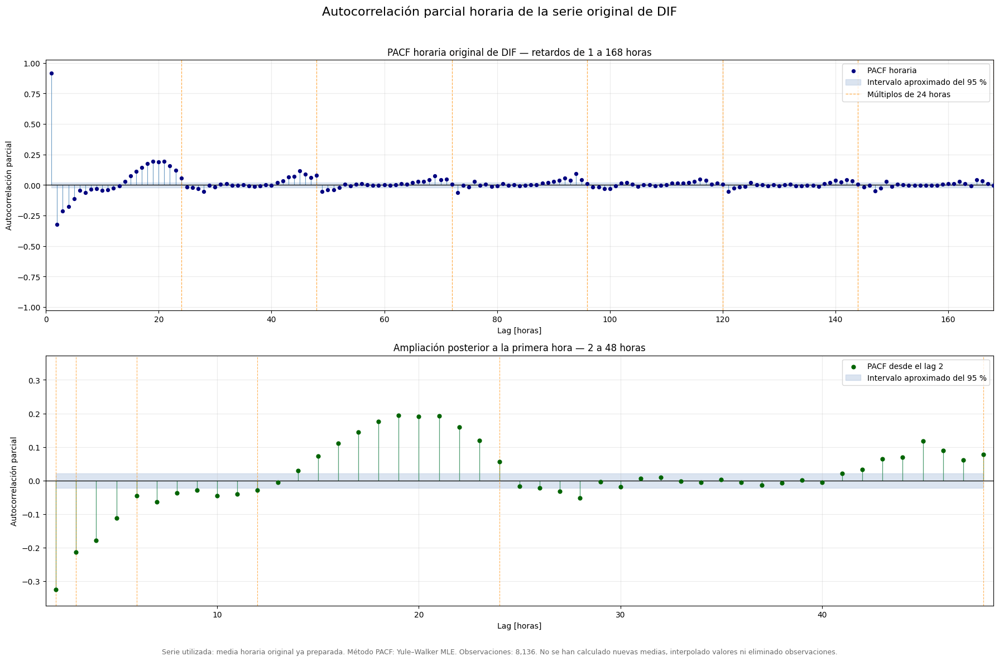

,comprobacion,resultado
0,Archivo gráfico creado,True
1,Nombre del archivo,pacf_horaria_original_DIF.png
2,Lag mínimo mostrado,1
3,Lag máximo mostrado,168
4,Ampliación,2–48 horas
5,Múltiplos diarios señalados,"24, 48, 72, 96, 120, 144 y 168 horas"


In [52]:
# 1. Comprobar los resultados de la celda anterior
OBJETOS_REQUERIDOS_GRAFICO_PACF_HOR = [
    "lags_pacf_hor_original",
    "valores_pacf_hor_original",
    "intervalos_pacf_hor_original",
    "banda_inferior_pacf_hor_original",
    "banda_superior_pacf_hor_original",
    "MAX_LAG_PACF_HOR_ORIGINAL",
    "LAGS_CLAVE_PACF_HOR_ORIGINAL",
    "directorio_resultados_pacf_hor_original",
]

# Localizar los objetos que no existen.
objetos_ausentes_grafico_pacf_hor = [
    nombre for nombre in OBJETOS_REQUERIDOS_GRAFICO_PACF_HOR if nombre not in globals()
]
if objetos_ausentes_grafico_pacf_hor:
    raise NameError(
        "Faltan objetos del cálculo de la PACF horaria: " f"{objetos_ausentes_grafico_pacf_hor}"
    )


# 2. Preparar la figura
figura_pacf_hor_original, ejes_pacf_hor_original = plt.subplots(nrows=2, ncols=1, figsize=(18, 12))
eje_completo_pacf_hor_original = ejes_pacf_hor_original[0]
eje_ampliado_pacf_hor_original = ejes_pacf_hor_original[1]


# 3. Dibujar la PACF completa de 1 a 168 horas

# Excluir el lag 0 porque siempre es igual a uno.
mascara_completa_pacf_hor_original = lags_pacf_hor_original >= 1
eje_completo_pacf_hor_original.vlines(
    lags_pacf_hor_original[mascara_completa_pacf_hor_original],
    0,
    valores_pacf_hor_original[mascara_completa_pacf_hor_original],
    color="steelblue",
    linewidth=0.8,
    alpha=0.8,
)
eje_completo_pacf_hor_original.scatter(
    lags_pacf_hor_original[mascara_completa_pacf_hor_original],
    valores_pacf_hor_original[mascara_completa_pacf_hor_original],
    color="navy",
    s=18,
    zorder=3,
    label="PACF horaria",
)
eje_completo_pacf_hor_original.fill_between(
    lags_pacf_hor_original[mascara_completa_pacf_hor_original],
    banda_inferior_pacf_hor_original[mascara_completa_pacf_hor_original],
    banda_superior_pacf_hor_original[mascara_completa_pacf_hor_original],
    color="lightsteelblue",
    alpha=0.45,
    label="Intervalo aproximado del 95 %",
)
eje_completo_pacf_hor_original.axhline(0, color="black", linewidth=0.9)
for lag_diario_pacf_hor_original in range(24, MAX_LAG_PACF_HOR_ORIGINAL + 1, 24):

    # Etiquetar únicamente la primera línea diaria.
    etiqueta_diaria_pacf_hor_original = (
        "Múltiplos de 24 horas" if lag_diario_pacf_hor_original == 24 else None
    )
    eje_completo_pacf_hor_original.axvline(
        lag_diario_pacf_hor_original,
        color="darkorange",
        linestyle="--",
        linewidth=0.9,
        alpha=0.70,
        label=etiqueta_diaria_pacf_hor_original,
    )

maximo_absoluto_pacf_hor_original = float(
    np.abs(valores_pacf_hor_original[1 : MAX_LAG_PACF_HOR_ORIGINAL + 1]).max()
)
limite_vertical_completo_pacf_hor_original = min(
    1.05, max(0.10, maximo_absoluto_pacf_hor_original * 1.12)
)
eje_completo_pacf_hor_original.set_ylim(
    -limite_vertical_completo_pacf_hor_original, limite_vertical_completo_pacf_hor_original
)
eje_completo_pacf_hor_original.set_xlim(0, MAX_LAG_PACF_HOR_ORIGINAL)
eje_completo_pacf_hor_original.set_title("PACF horaria original de DIF — retardos de 1 a 168 horas")
eje_completo_pacf_hor_original.set_xlabel("Lag [horas]")
eje_completo_pacf_hor_original.set_ylabel("Autocorrelación parcial")
eje_completo_pacf_hor_original.grid(alpha=0.25)
eje_completo_pacf_hor_original.legend(loc="best")


# 4. Ampliar los retardos de 2 a 48 horas
mascara_ampliada_pacf_hor_original = (lags_pacf_hor_original >= 2) & (lags_pacf_hor_original <= 48)
eje_ampliado_pacf_hor_original.vlines(
    lags_pacf_hor_original[mascara_ampliada_pacf_hor_original],
    0,
    valores_pacf_hor_original[mascara_ampliada_pacf_hor_original],
    color="seagreen",
    linewidth=0.9,
    alpha=0.85,
)
eje_ampliado_pacf_hor_original.scatter(
    lags_pacf_hor_original[mascara_ampliada_pacf_hor_original],
    valores_pacf_hor_original[mascara_ampliada_pacf_hor_original],
    color="darkgreen",
    s=24,
    zorder=3,
    label="PACF desde el lag 2",
)
eje_ampliado_pacf_hor_original.fill_between(
    lags_pacf_hor_original[mascara_ampliada_pacf_hor_original],
    banda_inferior_pacf_hor_original[mascara_ampliada_pacf_hor_original],
    banda_superior_pacf_hor_original[mascara_ampliada_pacf_hor_original],
    color="lightsteelblue",
    alpha=0.45,
    label="Intervalo aproximado del 95 %",
)
eje_ampliado_pacf_hor_original.axhline(0, color="black", linewidth=0.9)
for lag_clave_pacf_hor_original in LAGS_CLAVE_PACF_HOR_ORIGINAL:
    if 2 <= lag_clave_pacf_hor_original <= 48:
        eje_ampliado_pacf_hor_original.axvline(
            lag_clave_pacf_hor_original,
            color="darkorange",
            linestyle="--",
            linewidth=0.8,
            alpha=0.65,
        )

maximo_ampliado_pacf_hor_original = float(np.abs(valores_pacf_hor_original[2:49]).max())
maximo_banda_pacf_hor_original = float(
    max(
        np.abs(banda_inferior_pacf_hor_original[2:49]).max(),
        np.abs(banda_superior_pacf_hor_original[2:49]).max(),
    )
)
limite_vertical_ampliado_pacf_hor_original = min(
    1.0, max(0.05, 1.15 * maximo_ampliado_pacf_hor_original, 2.0 * maximo_banda_pacf_hor_original)
)
eje_ampliado_pacf_hor_original.set_ylim(
    -limite_vertical_ampliado_pacf_hor_original, limite_vertical_ampliado_pacf_hor_original
)
eje_ampliado_pacf_hor_original.set_xlim(1.5, 48.5)
eje_ampliado_pacf_hor_original.set_title("Ampliación posterior a la primera hora — 2 a 48 horas")
eje_ampliado_pacf_hor_original.set_xlabel("Lag [horas]")
eje_ampliado_pacf_hor_original.set_ylabel("Autocorrelación parcial")
eje_ampliado_pacf_hor_original.grid(alpha=0.25)
eje_ampliado_pacf_hor_original.legend(loc="best")


# 5. Terminar y guardar la figura
figura_pacf_hor_original.suptitle(
    "Autocorrelación parcial horaria de la serie original de DIF", fontsize=16
)
figura_pacf_hor_original.text(
    0.5,
    0.012,
    (
        "Serie utilizada: media horaria original ya preparada. "
        "Método PACF: Yule–Walker MLE. "
        f"Observaciones: {n_validos_pacf_hor_original:,}. "
        "No se han calculado nuevas medias, interpolado valores "
        "ni eliminado observaciones."
    ),
    ha="center",
    fontsize=9,
    color="dimgray",
)
figura_pacf_hor_original.tight_layout(rect=[0, 0.035, 1, 0.96])
ruta_grafico_pacf_hor_original = (
    directorio_resultados_pacf_hor_original / "pacf_horaria_original_DIF.png"
)
figura_pacf_hor_original.savefig(ruta_grafico_pacf_hor_original, dpi=200, bbox_inches="tight")
plt.show()
plt.close(figura_pacf_hor_original)
if not ruta_grafico_pacf_hor_original.is_file():

    # Detener la ejecución si la imagen no existe.
    raise RuntimeError("No se ha guardado la gráfica de la PACF horaria.")

control_grafico_pacf_hor_original = pd.DataFrame(
    {
        "comprobacion": [
            "Archivo gráfico creado",
            "Nombre del archivo",
            "Lag mínimo mostrado",
            "Lag máximo mostrado",
            "Ampliación",
            "Múltiplos diarios señalados",
        ],
        "resultado": [
            ruta_grafico_pacf_hor_original.is_file(),
            ruta_grafico_pacf_hor_original.name,
            1,
            MAX_LAG_PACF_HOR_ORIGINAL,
            "2–48 horas",
            "24, 48, 72, 96, 120, 144 y 168 horas",
        ],
    }
)
display(control_grafico_pacf_hor_original)

### Interpretación: serie original

La función de autocorrelación parcial de la serie horaria original mostró que la dependencia lineal directa se encuentra dominada por el retardo de una hora, cuya PACF fue 0,9154. Los retardos de dos y tres horas presentaron coeficientes parciales de −0,3241 y −0,2122, respectivamente. Estos valores negativos no implican una relación total inversa, ya que sus autocorrelaciones simples fueron positivas, sino que representan correcciones condicionadas a la información aportada por las horas intermedias.

La PACF mostró asimismo una estructura oscilatoria asociada al ciclo diario. Los coeficientes volvieron a aumentar al aproximarse a las 24 horas, alcanzando valores próximos a 0,19 entre los retardos 19 y 21. En el retardo exacto de 24 horas, la ACF fue 0,8262, mientras que la PACF descendió hasta 0,0558. Esta diferencia indica que la elevada semejanza entre la misma hora de días consecutivos se explica principalmente por la continuidad horaria y por la estacionalidad diaria, aunque el día anterior conserva una contribución lineal directa pequeña pero estadísticamente significativa.

El retardo de 48 horas presentó una PACF de 0,0774. En cambio, los múltiplos diarios comprendidos entre 72 y 168 horas no fueron significativos, a pesar de mantener autocorrelaciones simples superiores a 0,80. Por consiguiente, la persistencia observada a varios días no constituye una memoria lineal directa de largo alcance, sino que refleja fundamentalmente la repetición del ciclo solar y la propagación de la dependencia a través de retardos más próximos.

Estos resultados justifican la evaluación de ventanas de entrada de 24 y 48 horas para N-BEATS. Una ventana semanal podrá considerarse como análisis de sensibilidad, pero su utilización no queda respaldada por una dependencia parcial directa en el retardo de 168 horas. La longitud definitiva de la ventana deberá establecerse mediante validación cronológica, dado que la PACF mide exclusivamente relaciones lineales y no representa por completo las dependencias no lineales que puede aprender una red neuronal.

### 11.4 Recuperación y validación del residuo

In [53]:
# 1. Importar las librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

# Importar herramientas para crear el archivo ZIP final.
import statsmodels
from pathlib import Path
from datetime import datetime
from IPython.display import display
from statsmodels.tsa.stattools import pacf

# 2. Definir los nombres reales utilizados en el notebook

# Guardar el nombre del DataFrame que contiene la descomposición STL
# principal de la sección 10.
NOMBRE_COMPONENTES_STL_PACF_RESIDUO = "componentes_stl_etapa2_dif"

# Guardar el nombre de la serie residual creada en la sección 10.
NOMBRE_RESIDUO_STL_PACF_RESIDUO = "residuo_stl_horario_etapa2_dif"

# Guardar el nombre de la serie horaria original utilizada por STL.
NOMBRE_SERIE_ORIGINAL_PACF_RESIDUO = "serie_horaria_original_etapa2_dif"
NOMBRE_MODELO_STL_PACF_RESIDUO = "modelo_stl_etapa2_dif"


# 3. Comprobar que existen todos los objetos necesarios

# Crear la lista de objetos que deben existir antes de continuar.
OBJETOS_REQUERIDOS_PACF_RESIDUO = [
    NOMBRE_COMPONENTES_STL_PACF_RESIDUO,
    NOMBRE_RESIDUO_STL_PACF_RESIDUO,
    NOMBRE_SERIE_ORIGINAL_PACF_RESIDUO,
    NOMBRE_MODELO_STL_PACF_RESIDUO,
    "tabla_completa_pacf_hor_original",
    "PERIODO_STL_ETAPA2_DIF",
    "VENTANA_ESTACIONAL_STL_ETAPA2_DIF",
    "VENTANA_TENDENCIA_STL_ETAPA2_DIF",
    "VENTANA_LOWPASS_STL_ETAPA2_DIF",
    "ROBUST_STL_ETAPA2_DIF",
]

# Localizar los objetos requeridos que no estén actualmente en memoria.
objetos_ausentes_pacf_residuo = [
    nombre for nombre in OBJETOS_REQUERIDOS_PACF_RESIDUO if nombre not in globals()
]
if objetos_ausentes_pacf_residuo:
    raise NameError(
        "Faltan objetos necesarios para calcular la PACF del "
        f"residuo STL: {objetos_ausentes_pacf_residuo}. "
        "Ejecuta previamente la sección 10 "
        "correspondientes al residuo STL y a la PACF horaria original."
    )


# 4. Recuperar los objetos exactos de la sección 10
componentes_origen_pacf_residuo = componentes_stl_etapa2_dif
residuo_origen_pacf_residuo = residuo_stl_horario_etapa2_dif
serie_original_pacf_residuo = serie_horaria_original_etapa2_dif
modelo_origen_pacf_residuo = modelo_stl_etapa2_dif


# 5. Comprobar el tipo y contenido de los objetos
if not isinstance(componentes_origen_pacf_residuo, pd.DataFrame):
    raise TypeError("'componentes_stl_etapa2_dif' debe ser un DataFrame.")

# Comprobar que el residuo está guardado como una Serie de pandas.
if not isinstance(residuo_origen_pacf_residuo, pd.Series):
    raise TypeError("'residuo_stl_horario_etapa2_dif' debe ser una Serie.")

# Comprobar que la serie original también es una Serie de pandas.
if not isinstance(serie_original_pacf_residuo, pd.Series):
    raise TypeError("'serie_horaria_original_etapa2_dif' debe ser una Serie.")

COLUMNAS_REQUERIDAS_COMPONENTES_PACF_RESIDUO = [
    "DIF_observada",
    "tendencia",
    "estacional",
    "residuo",
]
columnas_ausentes_pacf_residuo = [
    columna
    for columna in COLUMNAS_REQUERIDAS_COMPONENTES_PACF_RESIDUO
    if columna not in componentes_origen_pacf_residuo.columns
]
if columnas_ausentes_pacf_residuo:
    raise KeyError(
        "Faltan columnas en 'componentes_stl_etapa2_dif': " f"{columnas_ausentes_pacf_residuo}"
    )


# 6. Crear una copia independiente del residuo

# Copiar el residuo para que el análisis PACF no modifique el objeto
# creado anteriormente.
serie_residuo_stl_pacf_hor = residuo_origen_pacf_residuo.copy(deep=True).astype(float)
serie_residuo_stl_pacf_hor.name = "residuo_STL_horario_para_PACF"
residuo_desde_componentes_pacf = componentes_origen_pacf_residuo["residuo"].copy().astype(float)
control_indices_residuo_pacf = serie_residuo_stl_pacf_hor.index.equals(
    residuo_desde_componentes_pacf.index
)
control_valores_residuo_pacf = bool(
    np.allclose(
        serie_residuo_stl_pacf_hor.to_numpy(),
        residuo_desde_componentes_pacf.to_numpy(),
        rtol=1e-12,
        atol=1e-10,
        equal_nan=True,
    )
)

# Detener la ejecución si las dos versiones del residuo no coinciden.
if not (control_indices_residuo_pacf and control_valores_residuo_pacf):
    raise RuntimeError(
        "El objeto 'residuo_stl_horario_etapa2_dif' no coincide "
        "con la columna 'residuo' de "
        "'componentes_stl_etapa2_dif'."
    )


# 7. Comprobar el índice temporal
if not isinstance(serie_residuo_stl_pacf_hor.index, pd.DatetimeIndex):
    raise TypeError("El residuo STL debe tener un índice temporal DatetimeIndex.")

n_duplicados_pacf_residuo = int(serie_residuo_stl_pacf_hor.index.duplicated().sum())
if n_duplicados_pacf_residuo > 0:
    raise ValueError("La serie residual STL contiene timestamps duplicados.")

if not serie_residuo_stl_pacf_hor.index.is_monotonic_increasing:
    raise ValueError("El índice del residuo STL no está ordenado.")

diferencias_temporales_pacf_residuo = serie_residuo_stl_pacf_hor.index.to_series().diff().dropna()
control_frecuencia_pacf_residuo = bool(
    (diferencias_temporales_pacf_residuo == pd.Timedelta(hours=1)).all()
)

# Detener la ejecución si la cuadrícula no es horaria y regular.
if not control_frecuencia_pacf_residuo:
    raise ValueError("El residuo STL no está organizado sobre una cuadrícula " "horaria completa.")


# 8. Comprobar la alineación con la serie horaria original

# Comprobar que el residuo y la serie original tienen el mismo índice.
control_indices_pacf_residuo = serie_residuo_stl_pacf_hor.index.equals(
    serie_original_pacf_residuo.index
)

# Detener la ejecución si los índices no coinciden.
if not control_indices_pacf_residuo:
    raise ValueError(
        "El residuo STL y la serie horaria original no están " "alineados temporalmente."
    )

# Comprobar que la columna observada de STL coincide con la serie original.
control_observada_pacf_residuo = bool(
    np.allclose(
        componentes_origen_pacf_residuo["DIF_observada"].to_numpy(dtype=float),
        serie_original_pacf_residuo.to_numpy(dtype=float),
        rtol=1e-12,
        atol=1e-10,
        equal_nan=True,
    )
)

# Detener la ejecución si la serie observada de STL no coincide.
if not control_observada_pacf_residuo:
    raise RuntimeError(
        "La columna 'DIF_observada' de los componentes STL no "
        "coincide con la serie horaria original."
    )


# 9. Comprobar la reconstrucción STL
reconstruccion_pacf_residuo = (
    componentes_origen_pacf_residuo["tendencia"]
    + componentes_origen_pacf_residuo["estacional"]
    + componentes_origen_pacf_residuo["residuo"]
)
error_reconstruccion_pacf_residuo = (
    componentes_origen_pacf_residuo["DIF_observada"] - reconstruccion_pacf_residuo
)
max_error_reconstruccion_pacf_residuo = float(error_reconstruccion_pacf_residuo.abs().max())
control_reconstruccion_pacf_residuo = bool(
    np.allclose(
        componentes_origen_pacf_residuo["DIF_observada"],
        reconstruccion_pacf_residuo,
        rtol=1e-10,
        atol=1e-8,
    )
)

# Detener la ejecución si la reconstrucción no es correcta.
if not control_reconstruccion_pacf_residuo:
    raise RuntimeError("La reconstrucción de la descomposición STL no es correcta.")


# 10. Verificar la configuración STL realmente utilizada
CONFIGURACION_STL_ESPERADA_PACF_RESIDUO = {
    "period": int(PERIODO_STL_ETAPA2_DIF),
    "seasonal": int(VENTANA_ESTACIONAL_STL_ETAPA2_DIF),
    "trend": int(VENTANA_TENDENCIA_STL_ETAPA2_DIF),
    "low_pass": int(VENTANA_LOWPASS_STL_ETAPA2_DIF),
    "robust": bool(ROBUST_STL_ETAPA2_DIF),
}
configuracion_stl_encontrada_pacf_residuo = dict(modelo_origen_pacf_residuo.config)
configuracion_stl_verificada_pacf_residuo = bool(
    all(
        configuracion_stl_encontrada_pacf_residuo.get(parametro) == valor_esperado
        for parametro, valor_esperado in CONFIGURACION_STL_ESPERADA_PACF_RESIDUO.items()
    )
)

# Detener la ejecución si la configuración no es la esperada.
if not configuracion_stl_verificada_pacf_residuo:
    raise RuntimeError(
        "La configuración del STL encontrado no coincide con la "
        "configuración principal esperada. "
        f"Esperada: {CONFIGURACION_STL_ESPERADA_PACF_RESIDUO}. "
        f"Encontrada: {configuracion_stl_encontrada_pacf_residuo}."
    )


# 11. Comprobar valores ausentes y finitos
n_total_pacf_residuo = len(serie_residuo_stl_pacf_hor)
n_ausentes_pacf_residuo = int(serie_residuo_stl_pacf_hor.isna().sum())
n_validos_pacf_residuo = int(serie_residuo_stl_pacf_hor.notna().sum())
if n_ausentes_pacf_residuo > 0:
    raise ValueError("El residuo STL contiene valores ausentes.")

valores_residuo_stl_pacf_hor = serie_residuo_stl_pacf_hor.to_numpy(dtype=float)
if not np.isfinite(valores_residuo_stl_pacf_hor).all():
    raise ValueError("El residuo STL contiene valores no finitos.")


# 12. Definir la configuración de la PACF residual
MAX_LAG_PACF_RESIDUO_HOR = 168
ALPHA_PACF_RESIDUO_HOR = 0.05
LAGS_CLAVE_PACF_RESIDUO_HOR = [1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168]
if n_validos_pacf_residuo <= MAX_LAG_PACF_RESIDUO_HOR:
    raise ValueError(
        "No existen observaciones suficientes para calcular " "la PACF hasta 168 horas."
    )


# 13. Crear el directorio de resultados
marca_ejecucion_pacf_residuo = datetime.now().strftime("%Y%m%d_%H%M%S")
directorio_resultados_pacf_residuo = Path(
    f"resultados_pacf_residuo_STL_DIF_" f"{marca_ejecucion_pacf_residuo}"
)

# Crear el directorio si todavía no existe.
directorio_resultados_pacf_residuo.mkdir(parents=True, exist_ok=True)


# 14. Crear la tabla de control
control_serie_pacf_residuo = pd.DataFrame(
    {
        "comprobacion": [
            "DataFrame de componentes utilizado",
            "Serie residual utilizada",
            "Serie horaria original utilizada",
            "Primera observación",
            "Última observación",
            "Número total de horas",
            "Observaciones válidas",
            "Valores ausentes",
            "Timestamps duplicados",
            "Frecuencia horaria regular",
            "Índice alineado con la serie original",
            "DIF observada coincide con la original",
            "Residuo directo coincide con componentes",
            "Reconstrucción STL correcta",
            "Error máximo de reconstrucción",
            "Configuración STL verificada",
            "Periodo STL",
            "Ventana estacional STL",
            "Ventana de tendencia STL",
            "Ventana low-pass STL",
            "Configuración robusta STL",
            "Máximo lag PACF",
        ],
        "resultado": [
            NOMBRE_COMPONENTES_STL_PACF_RESIDUO,
            NOMBRE_RESIDUO_STL_PACF_RESIDUO,
            NOMBRE_SERIE_ORIGINAL_PACF_RESIDUO,
            serie_residuo_stl_pacf_hor.index.min(),
            serie_residuo_stl_pacf_hor.index.max(),
            n_total_pacf_residuo,
            n_validos_pacf_residuo,
            n_ausentes_pacf_residuo,
            n_duplicados_pacf_residuo,
            control_frecuencia_pacf_residuo,
            control_indices_pacf_residuo,
            control_observada_pacf_residuo,
            control_valores_residuo_pacf,
            control_reconstruccion_pacf_residuo,
            max_error_reconstruccion_pacf_residuo,
            configuracion_stl_verificada_pacf_residuo,
            CONFIGURACION_STL_ESPERADA_PACF_RESIDUO["period"],
            CONFIGURACION_STL_ESPERADA_PACF_RESIDUO["seasonal"],
            CONFIGURACION_STL_ESPERADA_PACF_RESIDUO["trend"],
            CONFIGURACION_STL_ESPERADA_PACF_RESIDUO["low_pass"],
            CONFIGURACION_STL_ESPERADA_PACF_RESIDUO["robust"],
            MAX_LAG_PACF_RESIDUO_HOR,
        ],
    }
)


# 15. Mostrar los controles
print("Preparación de la PACF del residuo STL completada.")
display(control_serie_pacf_residuo)
print("\nSerie preparada para la PACF:")
print("serie_residuo_stl_pacf_hor")
print("\nConfiguración STL verificada:")
display(
    pd.DataFrame(
        {
            "parametro": (list(CONFIGURACION_STL_ESPERADA_PACF_RESIDUO.keys())),
            "valor_esperado": (list(CONFIGURACION_STL_ESPERADA_PACF_RESIDUO.values())),
            "valor_encontrado": [
                configuracion_stl_encontrada_pacf_residuo[parametro]
                for parametro in CONFIGURACION_STL_ESPERADA_PACF_RESIDUO
            ],
        }
    )
)

Preparación de la PACF del residuo STL completada.


,comprobacion,resultado
0,DataFrame de componentes utilizado,componentes_stl_etapa2_dif
1,Serie residual utilizada,residuo_stl_horario_etapa2_dif
2,Serie horaria original utilizada,serie_horaria_original_etapa2_dif
3,Primera observación,2023-12-28 00:00:00
4,Última observación,2024-11-30 23:00:00
5,Número total de horas,8136
6,Observaciones válidas,8136
7,Valores ausentes,0
8,Timestamps duplicados,0
9,Frecuencia horaria regular,True



Serie preparada para la PACF:
serie_residuo_stl_pacf_hor

Configuración STL verificada:


,parametro,valor_esperado,valor_encontrado
0,period,24,24
1,seasonal,13,13
2,trend,721,721
3,low_pass,25,25
4,robust,False,False


### 11.5 Cálculo y comparación con la serie original

In [54]:
# 1. Comprobar los objetos de la preparación
OBJETOS_REQUERIDOS_CALCULO_PACF_RESIDUO = [
    "serie_residuo_stl_pacf_hor",
    "valores_residuo_stl_pacf_hor",
    "MAX_LAG_PACF_RESIDUO_HOR",
    "ALPHA_PACF_RESIDUO_HOR",
    "LAGS_CLAVE_PACF_RESIDUO_HOR",
    "n_validos_pacf_residuo",
    "tabla_completa_pacf_hor_original",
]
objetos_ausentes_calculo_pacf_residuo = [
    nombre for nombre in (OBJETOS_REQUERIDOS_CALCULO_PACF_RESIDUO) if nombre not in globals()
]
if objetos_ausentes_calculo_pacf_residuo:
    raise NameError(
        "Faltan objetos para calcular la PACF residual: " f"{objetos_ausentes_calculo_pacf_residuo}"
    )


# 2. Calcular la PACF residual

# Calcular la PACF mediante el mismo método que la serie original.
resultado_pacf_residuo_hor = pacf(
    valores_residuo_stl_pacf_hor,
    nlags=MAX_LAG_PACF_RESIDUO_HOR,
    method="ywmle",
    alpha=ALPHA_PACF_RESIDUO_HOR,
)
valores_pacf_residuo_hor = np.asarray(resultado_pacf_residuo_hor[0], dtype=float)
intervalos_pacf_residuo_hor = np.asarray(resultado_pacf_residuo_hor[1], dtype=float)


# 3. Calcular la ACF residual sobre la misma serie
valores_acf_residuo_hor = np.asarray(
    acf(
        valores_residuo_stl_pacf_hor,
        nlags=MAX_LAG_PACF_RESIDUO_HOR,
        fft=True,
        adjusted=False,
        missing="raise",
    ),
    dtype=float,
)


# 4. Validar los resultados
longitud_esperada_pacf_residuo = MAX_LAG_PACF_RESIDUO_HOR + 1
if len(valores_pacf_residuo_hor) != longitud_esperada_pacf_residuo:
    raise RuntimeError("El número de valores PACF residuales " "no es el esperado.")

if len(valores_acf_residuo_hor) != longitud_esperada_pacf_residuo:
    raise RuntimeError("El número de valores ACF residuales " "no es el esperado.")

if intervalos_pacf_residuo_hor.shape != (longitud_esperada_pacf_residuo, 2):
    raise RuntimeError("La matriz de intervalos PACF " "no tiene la forma esperada.")

if not np.isfinite(valores_pacf_residuo_hor).all():

    # Detener la ejecución si aparece un valor no finito.
    raise RuntimeError("La PACF residual ha producido valores no finitos.")

# Comprobar que la PACF del lag 0 es igual a uno.
if not np.isclose(valores_pacf_residuo_hor[0], 1.0, rtol=1e-10, atol=1e-10):
    raise RuntimeError("La PACF residual del lag 0 no es igual a 1.")

control_rango_pacf_residuo = bool((np.abs(valores_pacf_residuo_hor) <= 1.0 + 1e-10).all())
if not control_rango_pacf_residuo:
    raise RuntimeError("La PACF residual contiene valores fuera de [-1, 1].")


# 5. Preparar retardos e intervalos
lags_pacf_residuo_hor = np.arange(MAX_LAG_PACF_RESIDUO_HOR + 1)
banda_inferior_pacf_residuo_hor = intervalos_pacf_residuo_hor[:, 0] - valores_pacf_residuo_hor
banda_superior_pacf_residuo_hor = intervalos_pacf_residuo_hor[:, 1] - valores_pacf_residuo_hor
semianchos_ic95_pacf_residuo_hor = (
    intervalos_pacf_residuo_hor[:, 1] - intervalos_pacf_residuo_hor[:, 0]
) / 2
semiancho_referencia_pacf_residuo_hor = float(np.median(semianchos_ic95_pacf_residuo_hor[1:]))


# 6. Crear una función para describir los retardos
def describir_lag_pacf_residuo_hor(lag_horas):
    if lag_horas == 0:
        return "Instante actual"

    if lag_horas == 1:
        return "1 hora"

    if lag_horas < 24:
        return f"{lag_horas} horas"

    dias_pacf_residuo = lag_horas // 24
    horas_pacf_residuo = lag_horas % 24

    # Devolver solamente los días si no sobran horas.
    if horas_pacf_residuo == 0:
        if dias_pacf_residuo == 1:
            return "1 día"

        return f"{dias_pacf_residuo} días"

    texto_dias_pacf_residuo = "1 día" if dias_pacf_residuo == 1 else f"{dias_pacf_residuo} días"
    texto_horas_pacf_residuo = (
        "1 hora" if horas_pacf_residuo == 1 else f"{horas_pacf_residuo} horas"
    )

    # Devolver la equivalencia completa.
    return f"{texto_dias_pacf_residuo} " f"y {texto_horas_pacf_residuo}"


# 7. Crear la tabla completa del residuo
tabla_completa_pacf_residuo_hor = pd.DataFrame(
    {
        "lag_horas": lags_pacf_residuo_hor,
        "equivalencia_temporal": [
            describir_lag_pacf_residuo_hor(lag) for lag in lags_pacf_residuo_hor
        ],
        "acf_residuo": valores_acf_residuo_hor,
        "pacf_residuo": valores_pacf_residuo_hor,
        "pacf_absoluta": np.abs(valores_pacf_residuo_hor),
        "IC95_inferior": (intervalos_pacf_residuo_hor[:, 0]),
        "IC95_superior": (intervalos_pacf_residuo_hor[:, 1]),
        "significativo_95": (
            (intervalos_pacf_residuo_hor[:, 0] > 0) | (intervalos_pacf_residuo_hor[:, 1] < 0)
        ),
        "parejas_teoricas": (n_validos_pacf_residuo - lags_pacf_residuo_hor),
    }
)
tabla_lags_clave_pacf_residuo_hor = (
    tabla_completa_pacf_residuo_hor[
        tabla_completa_pacf_residuo_hor["lag_horas"].isin(LAGS_CLAVE_PACF_RESIDUO_HOR)
    ]
    .copy()
    .sort_values("lag_horas")
    .reset_index(drop=True)
)
tabla_lags_diarios_pacf_residuo_hor = (
    tabla_completa_pacf_residuo_hor[
        (tabla_completa_pacf_residuo_hor["lag_horas"] > 0)
        & (tabla_completa_pacf_residuo_hor["lag_horas"] % 24 == 0)
    ]
    .copy()
    .reset_index(drop=True)
)
tabla_mayores_pacf_residuo_hor = (
    tabla_completa_pacf_residuo_hor[tabla_completa_pacf_residuo_hor["lag_horas"] > 0]
    .nlargest(20, "pacf_absoluta")
    .reset_index(drop=True)
)


# 8. Comparar PACF original y residual
tabla_original_para_comparacion_pacf = tabla_completa_pacf_hor_original[
    ["lag_horas", "acf_original", "pacf_original"]
].rename(columns={"acf_original": "acf_serie_original", "pacf_original": "pacf_serie_original"})
tabla_residuo_para_comparacion_pacf = tabla_completa_pacf_residuo_hor[
    ["lag_horas", "equivalencia_temporal", "acf_residuo", "pacf_residuo"]
]
tabla_comparacion_pacf_original_residuo = tabla_original_para_comparacion_pacf.merge(
    tabla_residuo_para_comparacion_pacf, on="lag_horas", how="inner", validate="one_to_one"
)
tabla_comparacion_pacf_original_residuo["reduccion_magnitud_pacf"] = np.abs(
    tabla_comparacion_pacf_original_residuo["pacf_serie_original"]
) - np.abs(tabla_comparacion_pacf_original_residuo["pacf_residuo"])
tabla_comparacion_pacf_original_residuo["porcentaje_magnitud_restante"] = np.where(
    np.abs(tabla_comparacion_pacf_original_residuo["pacf_serie_original"]) > 0,
    (
        100
        * np.abs(tabla_comparacion_pacf_original_residuo["pacf_residuo"])
        / np.abs(tabla_comparacion_pacf_original_residuo["pacf_serie_original"])
    ),
    np.nan,
)
tabla_lags_clave_comparacion_pacf = (
    tabla_comparacion_pacf_original_residuo[
        tabla_comparacion_pacf_original_residuo["lag_horas"].isin(LAGS_CLAVE_PACF_RESIDUO_HOR)
    ]
    .copy()
    .sort_values("lag_horas")
    .reset_index(drop=True)
)


# 9. Localizar el primer lag no significativo
lags_no_significativos_pacf_residuo = tabla_completa_pacf_residuo_hor[
    (tabla_completa_pacf_residuo_hor["lag_horas"] > 0)
    & (~tabla_completa_pacf_residuo_hor["significativo_95"])
]

# Comprobar si existe algún retardo no significativo.
if len(lags_no_significativos_pacf_residuo) > 0:
    primer_lag_no_significativo_pacf_residuo = int(
        lags_no_significativos_pacf_residuo.iloc[0]["lag_horas"]
    )

else:

    # Indicar que no se encontró ninguno.
    primer_lag_no_significativo_pacf_residuo = np.nan


# 10. Crear el resumen
resumen_calculo_pacf_residuo = pd.DataFrame(
    {
        "comprobacion": [
            "Serie utilizada",
            "Resolución",
            "Método PACF",
            "Máximo lag analizado",
            "Duración máxima analizada",
            "Número de residuos",
            "Valores ausentes",
            "Nivel de confianza",
            "Semiancho aproximado del IC95",
            "PACF residual en 1 hora",
            "PACF residual en 2 horas",
            "PACF residual en 3 horas",
            "PACF residual en 6 horas",
            "PACF residual en 12 horas",
            "PACF residual en 24 horas",
            "PACF residual en 48 horas",
            "PACF residual en 168 horas",
            "Primer lag cuyo IC95 incluye cero",
            "Lags significativos entre 1 y 168",
            "PACF dentro de [-1, 1]",
            "STL recalculado ahora",
        ],
        "resultado": [
            "componentes_stl_principal_etapa2_dif['residuo']",
            "1 hora",
            "Yule-Walker MLE (ywmle)",
            MAX_LAG_PACF_RESIDUO_HOR,
            "7 días",
            n_validos_pacf_residuo,
            n_ausentes_pacf_residuo,
            1 - ALPHA_PACF_RESIDUO_HOR,
            semiancho_referencia_pacf_residuo_hor,
            valores_pacf_residuo_hor[1],
            valores_pacf_residuo_hor[2],
            valores_pacf_residuo_hor[3],
            valores_pacf_residuo_hor[6],
            valores_pacf_residuo_hor[12],
            valores_pacf_residuo_hor[24],
            valores_pacf_residuo_hor[48],
            valores_pacf_residuo_hor[168],
            primer_lag_no_significativo_pacf_residuo,
            int(
                tabla_completa_pacf_residuo_hor.loc[
                    tabla_completa_pacf_residuo_hor["lag_horas"] > 0, "significativo_95"
                ].sum()
            ),
            control_rango_pacf_residuo,
            False,
        ],
    }
)


# 11. Mostrar los resultados
print("Resumen del cálculo de la PACF residual:")

# Visualizar el resumen.
display(resumen_calculo_pacf_residuo.style.format(precision=6))
print("\nPACF residual en retardos relevantes:")

# Visualizar los retardos clave.
display(
    tabla_lags_clave_pacf_residuo_hor.style.format(
        {
            "acf_residuo": "{:.6f}",
            "pacf_residuo": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
        }
    )
)
print("\nPACF residual en múltiplos de 24 horas:")

# Visualizar los retardos diarios.
display(
    tabla_lags_diarios_pacf_residuo_hor.style.format(
        {
            "acf_residuo": "{:.6f}",
            "pacf_residuo": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
        }
    )
)
print("\nComparación PACF original frente a PACF residual:")

# Visualizar los retardos comparados.
display(
    tabla_lags_clave_comparacion_pacf.style.format(
        {
            "acf_serie_original": "{:.6f}",
            "pacf_serie_original": "{:.6f}",
            "acf_residuo": "{:.6f}",
            "pacf_residuo": "{:.6f}",
            "reduccion_magnitud_pacf": "{:.6f}",
            "porcentaje_magnitud_restante": "{:.2f} %",
        }
    )
)
print("\nVeinte retardos con mayor PACF residual absoluta:")

# Visualizar la tabla.
display(
    tabla_mayores_pacf_residuo_hor.style.format(
        {
            "acf_residuo": "{:.6f}",
            "pacf_residuo": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
        }
    )
)
print(
    "\nLa PACF del residuo es descriptiva. "
    "El residuo STL no se introducirá como entrada del modelo "
    "porque fue calculado utilizando toda la serie."
)

Resumen del cálculo de la PACF residual:


,comprobacion,resultado
0,Serie utilizada,componentes_stl_principal_etapa2_dif['residuo']
1,Resolución,1 hora
2,Método PACF,Yule-Walker MLE (ywmle)
3,Máximo lag analizado,168
4,Duración máxima analizada,7 días
5,Número de residuos,8136
6,Valores ausentes,0
7,Nivel de confianza,0.950000
8,Semiancho aproximado del IC95,0.021729
9,PACF residual en 1 hora,0.718562



PACF residual en retardos relevantes:


,lag_horas,equivalencia_temporal,acf_residuo,pacf_residuo,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_teoricas
0,1,1 hora,0.718562,0.718562,0.718562,0.696833,0.740291,True,8135
1,2,2 horas,0.494233,-0.045689,0.045689,-0.067418,-0.023960,True,8134
2,3,3 horas,0.343275,0.009827,0.009827,-0.011902,0.031556,False,8133
3,6,6 horas,0.100491,0.028087,0.028087,0.006358,0.049816,True,8130
4,12,12 horas,0.023459,0.002011,0.002011,-0.019718,0.023740,False,8124
5,24,1 día,-0.136874,-0.092431,0.092431,-0.114160,-0.070701,True,8112
6,48,2 días,-0.160332,-0.045323,0.045323,-0.067052,-0.023594,True,8088
7,72,3 días,-0.179651,-0.100506,0.100506,-0.122235,-0.078777,True,8064
8,96,4 días,-0.030618,-0.083214,0.083214,-0.104943,-0.061485,True,8040
9,120,5 días,-0.026427,-0.065143,0.065143,-0.086872,-0.043413,True,8016



PACF residual en múltiplos de 24 horas:


,lag_horas,equivalencia_temporal,acf_residuo,pacf_residuo,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_teoricas
0,24,1 día,-0.136874,-0.092431,0.092431,-0.114160,-0.070701,True,8112
1,48,2 días,-0.160332,-0.045323,0.045323,-0.067052,-0.023594,True,8088
2,72,3 días,-0.179651,-0.100506,0.100506,-0.122235,-0.078777,True,8064
3,96,4 días,-0.030618,-0.083214,0.083214,-0.104943,-0.061485,True,8040
4,120,5 días,-0.026427,-0.065143,0.065143,-0.086872,-0.043413,True,8016
5,144,6 días,-0.000564,-0.062125,0.062125,-0.083855,-0.040396,True,7992
6,168,7 días,-0.036933,-0.083254,0.083254,-0.104984,-0.061525,True,7968



Comparación PACF original frente a PACF residual:


,lag_horas,acf_serie_original,pacf_serie_original,equivalencia_temporal,acf_residuo,pacf_residuo,reduccion_magnitud_pacf,porcentaje_magnitud_restante
0,1,0.915378,0.915378,1 hora,0.718562,0.718562,0.196816,78.50 %
1,2,0.785381,-0.324132,2 horas,0.494233,-0.045689,0.278443,14.10 %
2,3,0.624464,-0.212189,3 horas,0.343275,0.009827,0.202362,4.63 %
3,6,0.079848,-0.045030,6 horas,0.100491,0.028087,0.016943,62.37 %
4,12,-0.437258,-0.027631,12 horas,0.023459,0.002011,0.025620,7.28 %
5,24,0.826172,0.055756,1 día,-0.136874,-0.092431,-0.036674,165.78 %
6,48,0.819045,0.077430,2 días,-0.160332,-0.045323,0.032107,58.53 %
7,72,0.807482,0.007570,3 días,-0.179651,-0.100506,-0.092937,1327.74 %
8,96,0.818099,0.009151,4 días,-0.030618,-0.083214,-0.074063,909.30 %
9,120,0.809124,0.008237,5 días,-0.026427,-0.065143,-0.056906,790.88 %



Veinte retardos con mayor PACF residual absoluta:


,lag_horas,equivalencia_temporal,acf_residuo,pacf_residuo,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_teoricas
0,1,1 hora,0.718562,0.718562,0.718562,0.696833,0.740291,True,8135
1,97,4 días y 1 hora,-0.009370,0.207165,0.207165,0.185436,0.228894,True,8039
2,49,2 días y 1 hora,-0.086934,0.194340,0.194340,0.172611,0.216069,True,8087
3,25,1 día y 1 hora,-0.067726,0.187964,0.187964,0.166235,0.209693,True,8111
4,73,3 días y 1 hora,-0.154294,0.178549,0.178549,0.156820,0.200278,True,8063
5,145,6 días y 1 hora,0.001896,0.152891,0.152891,0.131161,0.174620,True,7991
6,121,5 días y 1 hora,-0.051337,0.134641,0.134641,0.112912,0.156371,True,8015
7,72,3 días,-0.179651,-0.100506,0.100506,-0.122235,-0.078777,True,8064
8,24,1 día,-0.136874,-0.092431,0.092431,-0.114160,-0.070701,True,8112
9,47,1 día y 23 horas,-0.143146,-0.086677,0.086677,-0.108406,-0.064948,True,8089



La PACF del residuo es descriptiva. El residuo STL no se introducirá como entrada del modelo porque fue calculado utilizando toda la serie.


### 11.6 Visualización

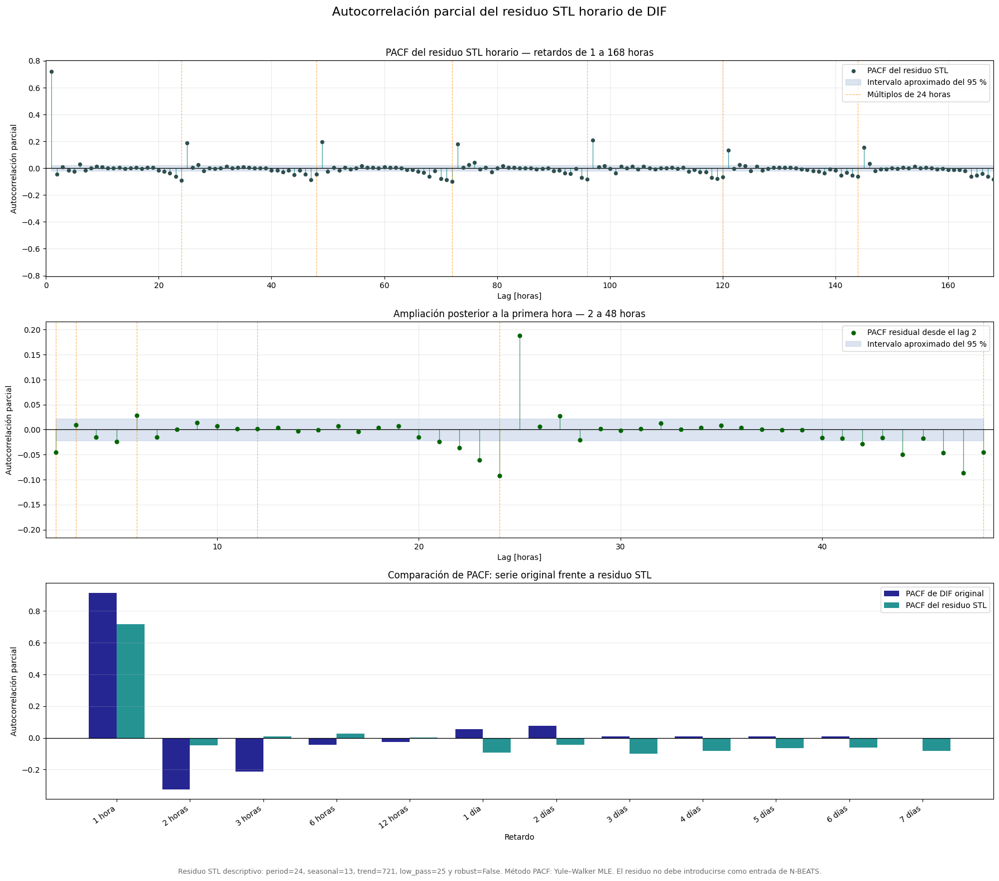

,comprobacion,resultado
0,Archivo gráfico creado,True
1,Nombre del archivo,pacf_residuo_STL_horario_DIF.png
2,Lag mínimo mostrado,1
3,Lag máximo mostrado,168
4,Ampliación,2–48 horas
5,Comparación con la PACF original,True


In [55]:
# 1. Comprobar los objetos necesarios
OBJETOS_REQUERIDOS_GRAFICO_PACF_RESIDUO = [
    "lags_pacf_residuo_hor",
    "valores_pacf_residuo_hor",
    "banda_inferior_pacf_residuo_hor",
    "banda_superior_pacf_residuo_hor",
    "tabla_lags_clave_comparacion_pacf",
    "LAGS_CLAVE_PACF_RESIDUO_HOR",
    "directorio_resultados_pacf_residuo",
]
objetos_ausentes_grafico_pacf_residuo = [
    nombre for nombre in (OBJETOS_REQUERIDOS_GRAFICO_PACF_RESIDUO) if nombre not in globals()
]
if objetos_ausentes_grafico_pacf_residuo:
    raise NameError(
        "Faltan objetos del cálculo PACF residual: " f"{objetos_ausentes_grafico_pacf_residuo}"
    )


# 2. Crear la figura
figura_pacf_residuo, ejes_pacf_residuo = plt.subplots(nrows=3, ncols=1, figsize=(18, 16))
eje_completo_pacf_residuo = ejes_pacf_residuo[0]
eje_ampliado_pacf_residuo = ejes_pacf_residuo[1]
eje_comparacion_pacf_residuo = ejes_pacf_residuo[2]


# 3. Dibujar la PACF residual completa
mascara_completa_pacf_residuo = lags_pacf_residuo_hor >= 1
eje_completo_pacf_residuo.vlines(
    lags_pacf_residuo_hor[mascara_completa_pacf_residuo],
    0,
    valores_pacf_residuo_hor[mascara_completa_pacf_residuo],
    color="teal",
    linewidth=0.8,
    alpha=0.8,
)
eje_completo_pacf_residuo.scatter(
    lags_pacf_residuo_hor[mascara_completa_pacf_residuo],
    valores_pacf_residuo_hor[mascara_completa_pacf_residuo],
    color="darkslategray",
    s=18,
    zorder=3,
    label="PACF del residuo STL",
)
eje_completo_pacf_residuo.fill_between(
    lags_pacf_residuo_hor[mascara_completa_pacf_residuo],
    banda_inferior_pacf_residuo_hor[mascara_completa_pacf_residuo],
    banda_superior_pacf_residuo_hor[mascara_completa_pacf_residuo],
    color="lightsteelblue",
    alpha=0.45,
    label="Intervalo aproximado del 95 %",
)
eje_completo_pacf_residuo.axhline(0, color="black", linewidth=0.9)
for lag_diario_pacf_residuo in range(24, MAX_LAG_PACF_RESIDUO_HOR + 1, 24):

    # Etiquetar únicamente la primera línea diaria.
    etiqueta_diaria_pacf_residuo = (
        "Múltiplos de 24 horas" if lag_diario_pacf_residuo == 24 else None
    )
    eje_completo_pacf_residuo.axvline(
        lag_diario_pacf_residuo,
        color="darkorange",
        linestyle="--",
        linewidth=0.8,
        alpha=0.65,
        label=etiqueta_diaria_pacf_residuo,
    )

maximo_completo_pacf_residuo = float(
    np.abs(valores_pacf_residuo_hor[1 : MAX_LAG_PACF_RESIDUO_HOR + 1]).max()
)
limite_completo_pacf_residuo = min(1.05, max(0.10, maximo_completo_pacf_residuo * 1.12))
eje_completo_pacf_residuo.set_ylim(-limite_completo_pacf_residuo, limite_completo_pacf_residuo)
eje_completo_pacf_residuo.set_xlim(0, MAX_LAG_PACF_RESIDUO_HOR)
eje_completo_pacf_residuo.set_title("PACF del residuo STL horario — retardos de 1 a 168 horas")
eje_completo_pacf_residuo.set_xlabel("Lag [horas]")
eje_completo_pacf_residuo.set_ylabel("Autocorrelación parcial")
eje_completo_pacf_residuo.grid(alpha=0.25)
eje_completo_pacf_residuo.legend(loc="best")


# 4. Dibujar la ampliación de 2 a 48 horas
mascara_ampliada_pacf_residuo = (lags_pacf_residuo_hor >= 2) & (lags_pacf_residuo_hor <= 48)
eje_ampliado_pacf_residuo.vlines(
    lags_pacf_residuo_hor[mascara_ampliada_pacf_residuo],
    0,
    valores_pacf_residuo_hor[mascara_ampliada_pacf_residuo],
    color="seagreen",
    linewidth=0.9,
    alpha=0.85,
)
eje_ampliado_pacf_residuo.scatter(
    lags_pacf_residuo_hor[mascara_ampliada_pacf_residuo],
    valores_pacf_residuo_hor[mascara_ampliada_pacf_residuo],
    color="darkgreen",
    s=24,
    zorder=3,
    label="PACF residual desde el lag 2",
)
eje_ampliado_pacf_residuo.fill_between(
    lags_pacf_residuo_hor[mascara_ampliada_pacf_residuo],
    banda_inferior_pacf_residuo_hor[mascara_ampliada_pacf_residuo],
    banda_superior_pacf_residuo_hor[mascara_ampliada_pacf_residuo],
    color="lightsteelblue",
    alpha=0.45,
    label="Intervalo aproximado del 95 %",
)
eje_ampliado_pacf_residuo.axhline(0, color="black", linewidth=0.9)
for lag_clave_pacf_residuo in LAGS_CLAVE_PACF_RESIDUO_HOR:
    if 2 <= lag_clave_pacf_residuo <= 48:
        eje_ampliado_pacf_residuo.axvline(
            lag_clave_pacf_residuo, color="darkorange", linestyle="--", linewidth=0.8, alpha=0.65
        )

maximo_ampliado_pacf_residuo = float(np.abs(valores_pacf_residuo_hor[2:49]).max())
maximo_banda_pacf_residuo = float(
    max(
        np.abs(banda_inferior_pacf_residuo_hor[2:49]).max(),
        np.abs(banda_superior_pacf_residuo_hor[2:49]).max(),
    )
)
limite_ampliado_pacf_residuo = min(
    1.0, max(0.05, 1.15 * maximo_ampliado_pacf_residuo, 2.0 * maximo_banda_pacf_residuo)
)
eje_ampliado_pacf_residuo.set_ylim(-limite_ampliado_pacf_residuo, limite_ampliado_pacf_residuo)
eje_ampliado_pacf_residuo.set_xlim(1.5, 48.5)
eje_ampliado_pacf_residuo.set_title("Ampliación posterior a la primera hora — 2 a 48 horas")
eje_ampliado_pacf_residuo.set_xlabel("Lag [horas]")
eje_ampliado_pacf_residuo.set_ylabel("Autocorrelación parcial")
eje_ampliado_pacf_residuo.grid(alpha=0.25)
eje_ampliado_pacf_residuo.legend(loc="best")


# 5. Comparar PACF original y PACF residual
posiciones_comparacion_pacf = np.arange(len(tabla_lags_clave_comparacion_pacf))
ancho_barras_pacf = 0.38
eje_comparacion_pacf_residuo.bar(
    posiciones_comparacion_pacf - ancho_barras_pacf / 2,
    tabla_lags_clave_comparacion_pacf["pacf_serie_original"],
    width=ancho_barras_pacf,
    color="navy",
    alpha=0.85,
    label="PACF de DIF original",
)
eje_comparacion_pacf_residuo.bar(
    posiciones_comparacion_pacf + ancho_barras_pacf / 2,
    tabla_lags_clave_comparacion_pacf["pacf_residuo"],
    width=ancho_barras_pacf,
    color="teal",
    alpha=0.85,
    label="PACF del residuo STL",
)
eje_comparacion_pacf_residuo.axhline(0, color="black", linewidth=0.9)
eje_comparacion_pacf_residuo.set_xticks(posiciones_comparacion_pacf)

# Utilizar la equivalencia temporal como etiqueta.
eje_comparacion_pacf_residuo.set_xticklabels(
    tabla_lags_clave_comparacion_pacf["equivalencia_temporal"], rotation=35, ha="right"
)
eje_comparacion_pacf_residuo.set_title("Comparación de PACF: serie original frente a residuo STL")
eje_comparacion_pacf_residuo.set_xlabel("Retardo")
eje_comparacion_pacf_residuo.set_ylabel("Autocorrelación parcial")
eje_comparacion_pacf_residuo.grid(axis="y", alpha=0.25)
eje_comparacion_pacf_residuo.legend(loc="best")


# 6. Terminar y guardar la figura
figura_pacf_residuo.suptitle("Autocorrelación parcial del residuo STL horario de DIF", fontsize=16)
figura_pacf_residuo.text(
    0.5,
    0.008,
    (
        "Residuo STL descriptivo: period=24, seasonal=13, "
        "trend=721, low_pass=25 y robust=False. "
        "Método PACF: Yule–Walker MLE. "
        "El residuo no debe introducirse como entrada de N-BEATS."
    ),
    ha="center",
    fontsize=9,
    color="dimgray",
)
figura_pacf_residuo.tight_layout(rect=[0, 0.035, 1, 0.965])
ruta_grafico_pacf_residuo = directorio_resultados_pacf_residuo / "pacf_residuo_STL_horario_DIF.png"
figura_pacf_residuo.savefig(ruta_grafico_pacf_residuo, dpi=200, bbox_inches="tight")
plt.show()
plt.close(figura_pacf_residuo)
if not ruta_grafico_pacf_residuo.is_file():

    # Detener la ejecución si no se ha guardado.
    raise RuntimeError("No se ha guardado la gráfica PACF residual.")

control_grafico_pacf_residuo = pd.DataFrame(
    {
        "comprobacion": [
            "Archivo gráfico creado",
            "Nombre del archivo",
            "Lag mínimo mostrado",
            "Lag máximo mostrado",
            "Ampliación",
            "Comparación con la PACF original",
        ],
        "resultado": [
            ruta_grafico_pacf_residuo.is_file(),
            ruta_grafico_pacf_residuo.name,
            1,
            MAX_LAG_PACF_RESIDUO_HOR,
            "2–48 horas",
            True,
        ],
    }
)
display(control_grafico_pacf_residuo)

### Interpretación: residuo STL

Con el objetivo de determinar si la dependencia temporal observada en la serie horaria de radiación difusa correspondía a relaciones directas entre retardos o era consecuencia de la tendencia y la estacionalidad, se calculó la función de autocorrelación parcial (PACF) del residuo obtenido mediante la descomposición STL. Se utilizó la configuración `period=24`, `seasonal=13`, `trend=721`, `low_pass=25` y `robust=False`. El análisis comprendió 8.136 observaciones horarias, sin valores ausentes, y retardos de hasta 168 horas. La PACF se estimó mediante Yule–Walker MLE, con un intervalo aproximado de confianza del 95 %, cuyo semiancho fue de 0,0217.

El resultado principal fue una autocorrelación parcial elevada en el primer retardo horario, con un valor de 0,719 y un intervalo de confianza comprendido entre 0,697 y 0,740. Por tanto, incluso después de retirar la tendencia y el patrón estacional diario estimados mediante STL, una desviación de DIF respecto a su comportamiento esperado tiende a persistir durante la hora siguiente. Esta dependencia puede estar relacionada con la continuidad temporal de las condiciones atmosféricas y, especialmente, con la persistencia de situaciones de nubosidad que no desaparecen instantáneamente entre dos observaciones consecutivas.

La PACF de la serie original en el retardo de una hora era de 0,915, mientras que en el residuo disminuyó hasta 0,719. La descomposición STL redujo, por tanto, la magnitud de esta relación en aproximadamente 0,197, aunque el residuo conservó alrededor del 78,5 % de la PACF original. Esto indica que una parte de la continuidad horaria de DIF estaba asociada con la tendencia y la estacionalidad, pero también que una proporción considerable corresponde a variaciones de corto plazo no explicadas por dichos componentes.

La diferencia entre la ACF y la PACF resulta especialmente relevante en los retardos siguientes. La ACF residual alcanzó valores de 0,494 y 0,343 en dos y tres horas, respectivamente. Sin embargo, al controlar los retardos intermedios, la PACF se redujo a −0,046 en dos horas y a 0,010 en tres horas, siendo este último valor no significativo. En consecuencia, la correlación observada a dos y tres horas no representa una relación directa intensa, sino que se transmite principalmente a través del residuo de la hora inmediatamente anterior. Este resultado sugiere una estructura de memoria corta dominada por el primer retardo.

Aunque se detectaron 54 retardos estadísticamente significativos entre 1 y 168 horas, su significación debe interpretarse con cautela debido al elevado tamaño de la muestra. La mayoría presentó magnitudes reducidas y, por tanto, una relevancia práctica muy inferior a la del primer retardo. Por ejemplo, la PACF fue de 0,028 en seis horas y prácticamente nula en doce horas. En este contexto, que un valor quede fuera del intervalo de confianza no implica necesariamente que aporte una capacidad predictiva sustancial.

También se identificó una estructura secundaria alrededor del ciclo diario. Los retardos correspondientes a múltiplos exactos de 24 horas presentaron PACF negativas y de magnitud moderada o reducida: −0,092 en 24 horas, −0,045 en 48 horas, −0,101 en 72 horas y valores comprendidos aproximadamente entre −0,06 y −0,08 para varios retardos diarios posteriores. Asimismo, aparecieron máximos positivos en los retardos situados una hora después de algunos múltiplos diarios: 0,188 en 25 horas, 0,194 en 49 horas, 0,179 en 73 horas y 0,207 en 97 horas. Este patrón indica que el residuo no constituye ruido blanco y que conserva una débil estructura temporal relacionada con el ciclo diario. No obstante, esta estructura puede proceder tanto de regularidades atmosféricas no capturadas completamente como del propio filtrado estacional realizado por STL, por lo que no debe interpretarse de forma aislada como una relación causal.

En conjunto, la PACF residual confirma que la principal dependencia lineal directa de las desviaciones de DIF se concentra en la hora inmediatamente anterior. Las correlaciones residuales de dos y tres horas observadas mediante la ACF están explicadas en gran medida por esa persistencia de primer orden. Para el posterior desarrollo predictivo, este resultado respalda la inclusión de información reciente en la ventana de entrada, aunque no permite determinar por sí solo la longitud óptima del backcast de N-BEATS. La selección definitiva deberá realizarse mediante validación temporal y comparación con modelos de referencia. Además, el residuo STL se emplea únicamente como herramienta diagnóstica y no debe introducirse directamente como variable predictora, ya que el modelo se entrenará sobre la serie original de DIF.

## 12. Comparación ACF–PACF

### 12.1 Preparación y controles

In [56]:
# 1. Importar las librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
import json

# Importar ZIPFile para comprimir los resultados finales.
import statsmodels
from IPython.display import display

# 2. Definir los objetos que deben existir
OBJETOS_REQUERIDOS_CIERRE_ETAPA2_DIF = [
    "tabla_acf_original_etapa2_dif",
    "tabla_acf_residuo_etapa2_dif",
    "tabla_completa_pacf_hor_original",
    "directorio_resultados_pacf_residuo",
    "serie_horaria_original_etapa2_dif",
    "residuo_stl_horario_etapa2_dif",
]

# Localizar los objetos que no están actualmente en memoria.
objetos_ausentes_cierre_etapa2_dif = [
    nombre for nombre in OBJETOS_REQUERIDOS_CIERRE_ETAPA2_DIF if nombre not in globals()
]
if objetos_ausentes_cierre_etapa2_dif:
    raise NameError(
        "Faltan objetos necesarios para la comparación ACF-PACF: "
        f"{objetos_ausentes_cierre_etapa2_dif}. "
        "Ejecuta previamente la ACF horaria original, la ACF "
        "residual, la PACF horaria original y la PACF residual."
    )


# 3. Definir los retardos de la comparación
MAX_LAG_CIERRE_ETAPA2_DIF = 168

# Crear la secuencia completa desde el lag 0 hasta el lag 168.
LAGS_ESPERADOS_CIERRE_ETAPA2_DIF = np.arange(MAX_LAG_CIERRE_ETAPA2_DIF + 1)
LAGS_CLAVE_CIERRE_ETAPA2_DIF = [
    1,
    2,
    3,
    6,
    12,
    24,
    25,
    48,
    49,
    72,
    73,
    96,
    97,
    120,
    121,
    144,
    145,
    168,
]
LAGS_DIARIOS_CIERRE_ETAPA2_DIF = [24, 48, 72, 96, 120, 144, 168]
LAGS_DIARIOS_MAS_UNA_CIERRE_ETAPA2_DIF = [25, 49, 73, 97, 121, 145]


# 4. Tabla completa de la PACF residual (calculada en la sección 11.5)
tabla_pacf_residuo_cierre_etapa2_dif = tabla_completa_pacf_residuo_hor.copy()


# 5. Comprobar las columnas necesarias
COLUMNAS_ACF_ORIGINAL_CIERRE = [
    "lag_horas",
    "autocorrelacion_original",
    "IC95_inferior_original",
    "IC95_superior_original",
]
COLUMNAS_ACF_RESIDUO_CIERRE = [
    "lag_horas",
    "autocorrelacion_residuo",
    "IC95_inferior_residuo",
    "IC95_superior_residuo",
]
COLUMNAS_PACF_ORIGINAL_CIERRE = [
    "lag_horas",
    "acf_original",
    "pacf_original",
    "IC95_inferior",
    "IC95_superior",
    "significativo_95",
]
COLUMNAS_PACF_RESIDUO_CIERRE = [
    "lag_horas",
    "acf_residuo",
    "pacf_residuo",
    "IC95_inferior",
    "IC95_superior",
    "significativo_95",
]

def comprobar_columnas_cierre_etapa2(tabla, columnas_requeridas, nombre_tabla):
    columnas_ausentes = [columna for columna in columnas_requeridas if columna not in tabla.columns]
    if columnas_ausentes:
        raise KeyError(
            f"Faltan columnas en {nombre_tabla}: "
            f"{columnas_ausentes}. "
            f"Columnas disponibles: {tabla.columns.tolist()}"
        )

comprobar_columnas_cierre_etapa2(
    tabla_acf_original_etapa2_dif, COLUMNAS_ACF_ORIGINAL_CIERRE, "tabla_acf_original_etapa2_dif"
)
comprobar_columnas_cierre_etapa2(
    tabla_acf_residuo_etapa2_dif, COLUMNAS_ACF_RESIDUO_CIERRE, "tabla_acf_residuo_etapa2_dif"
)
comprobar_columnas_cierre_etapa2(
    tabla_completa_pacf_hor_original,
    COLUMNAS_PACF_ORIGINAL_CIERRE,
    "tabla_completa_pacf_hor_original",
)
comprobar_columnas_cierre_etapa2(
    tabla_pacf_residuo_cierre_etapa2_dif,
    COLUMNAS_PACF_RESIDUO_CIERRE,
    "tabla_pacf_residuo_cierre_etapa2_dif",
)


# 6. Crear una función para normalizar booleanos
def normalizar_booleanos_cierre_etapa2(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.astype(bool)

    serie_texto = serie.astype(str).str.strip().str.lower()
    serie_booleana = serie_texto.map({"true": True, "false": False})
    if serie_booleana.isna().any():
        raise ValueError(
            "No se han podido interpretar todos los valores " "de significación estadística."
        )

    return serie_booleana.astype(bool)


# 7. Preparar las cuatro tablas de origen
base_acf_original_cierre_etapa2 = (
    tabla_acf_original_etapa2_dif[COLUMNAS_ACF_ORIGINAL_CIERRE]
    .copy()
    .rename(
        columns={
            "autocorrelacion_original": "acf_original",
            "IC95_inferior_original": "acf_original_IC95_inferior",
            "IC95_superior_original": "acf_original_IC95_superior",
        }
    )
)
base_acf_residuo_cierre_etapa2 = (
    tabla_acf_residuo_etapa2_dif[COLUMNAS_ACF_RESIDUO_CIERRE]
    .copy()
    .rename(
        columns={
            "autocorrelacion_residuo": "acf_residuo",
            "IC95_inferior_residuo": "acf_residuo_IC95_inferior",
            "IC95_superior_residuo": "acf_residuo_IC95_superior",
        }
    )
)
base_pacf_original_cierre_etapa2 = (
    tabla_completa_pacf_hor_original[COLUMNAS_PACF_ORIGINAL_CIERRE]
    .copy()
    .rename(
        columns={
            "acf_original": "acf_original_registrada_en_pacf",
            "IC95_inferior": "pacf_original_IC95_inferior",
            "IC95_superior": "pacf_original_IC95_superior",
            "significativo_95": "pacf_original_significativa_95",
        }
    )
)
base_pacf_residuo_cierre_etapa2 = (
    tabla_pacf_residuo_cierre_etapa2_dif[COLUMNAS_PACF_RESIDUO_CIERRE]
    .copy()
    .rename(
        columns={
            "acf_residuo": "acf_residuo_registrada_en_pacf",
            "IC95_inferior": "pacf_residuo_IC95_inferior",
            "IC95_superior": "pacf_residuo_IC95_superior",
            "significativo_95": "pacf_residuo_significativa_95",
        }
    )
)
base_pacf_original_cierre_etapa2["pacf_original_significativa_95"] = (
    normalizar_booleanos_cierre_etapa2(
        base_pacf_original_cierre_etapa2["pacf_original_significativa_95"]
    )
)
base_pacf_residuo_cierre_etapa2["pacf_residuo_significativa_95"] = (
    normalizar_booleanos_cierre_etapa2(
        base_pacf_residuo_cierre_etapa2["pacf_residuo_significativa_95"]
    )
)


# 8. Unir los cuatro resultados mediante el lag horario
tabla_comparacion_cierre_etapa2_dif = base_acf_original_cierre_etapa2.merge(
    base_acf_residuo_cierre_etapa2, on="lag_horas", how="inner", validate="one_to_one"
)
tabla_comparacion_cierre_etapa2_dif = tabla_comparacion_cierre_etapa2_dif.merge(
    base_pacf_original_cierre_etapa2, on="lag_horas", how="inner", validate="one_to_one"
)
tabla_comparacion_cierre_etapa2_dif = tabla_comparacion_cierre_etapa2_dif.merge(
    base_pacf_residuo_cierre_etapa2, on="lag_horas", how="inner", validate="one_to_one"
)
tabla_comparacion_cierre_etapa2_dif = tabla_comparacion_cierre_etapa2_dif.sort_values(
    "lag_horas"
).reset_index(drop=True)


# 9. Validar la alineación de los resultados
control_lags_completos_cierre_etapa2 = bool(
    np.array_equal(
        tabla_comparacion_cierre_etapa2_dif["lag_horas"].to_numpy(),
        LAGS_ESPERADOS_CIERRE_ETAPA2_DIF,
    )
)
if not control_lags_completos_cierre_etapa2:
    raise RuntimeError(
        "Los resultados ACF y PACF no contienen exactamente "
        "los mismos retardos entre 0 y 168 horas."
    )

# Comprobar que la tabla conjunta no contiene valores ausentes.
control_sin_ausencias_cierre_etapa2 = bool(
    not tabla_comparacion_cierre_etapa2_dif.isna().any().any()
)
if not control_sin_ausencias_cierre_etapa2:
    raise RuntimeError("La tabla conjunta ACF-PACF contiene valores ausentes.")

# Comprobar que la ACF original coincide con la guardada por la PACF.
control_acf_original_coincidente_cierre = bool(
    np.allclose(
        tabla_comparacion_cierre_etapa2_dif["acf_original"],
        tabla_comparacion_cierre_etapa2_dif["acf_original_registrada_en_pacf"],
        rtol=1e-12,
        atol=1e-10,
    )
)

# Comprobar que la ACF residual coincide con la guardada por la PACF.
control_acf_residuo_coincidente_cierre = bool(
    np.allclose(
        tabla_comparacion_cierre_etapa2_dif["acf_residuo"],
        tabla_comparacion_cierre_etapa2_dif["acf_residuo_registrada_en_pacf"],
        rtol=1e-12,
        atol=1e-10,
    )
)

# Detener la ejecución si las ACF no coinciden.
if not (control_acf_original_coincidente_cierre and control_acf_residuo_coincidente_cierre):
    raise RuntimeError(
        "Las ACF empleadas en los cálculos PACF no coinciden "
        "con las ACF originales de la sección 10."
    )


# 10. Crear el directorio del cierre
marca_ejecucion_cierre_etapa2_dif = datetime.now().strftime("%Y%m%d_%H%M%S")
directorio_resultados_cierre_etapa2_dif = Path(
    "resultados_cierre_etapa2_ACF_PACF_DIF_" f"{marca_ejecucion_cierre_etapa2_dif}"
)
directorio_resultados_cierre_etapa2_dif.mkdir(parents=True, exist_ok=True)


# 11. Crear y mostrar la tabla de control
control_preparacion_cierre_etapa2_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Máximo lag común",
            "Número de retardos, incluido lag 0",
            "Lags completos y alineados",
            "Tabla conjunta sin ausencias",
            "ACF original coincidente",
            "ACF residual coincidente",
            "Serie original modificada ahora",
            "Residuo STL modificado ahora",
            "ACF recalculada ahora",
            "PACF recalculada ahora",
        ],
        "resultado": [
            MAX_LAG_CIERRE_ETAPA2_DIF,
            len(tabla_comparacion_cierre_etapa2_dif),
            control_lags_completos_cierre_etapa2,
            control_sin_ausencias_cierre_etapa2,
            control_acf_original_coincidente_cierre,
            control_acf_residuo_coincidente_cierre,
            False,
            False,
            False,
            False,
        ],
    }
)
print("Preparación de la comparación ACF-PACF completada.")
display(control_preparacion_cierre_etapa2_dif)
print("\nDirectorio de resultados:", directorio_resultados_cierre_etapa2_dif)

Preparación de la comparación ACF-PACF completada.


,comprobacion,resultado
0,Máximo lag común,168
1,"Número de retardos, incluido lag 0",169
2,Lags completos y alineados,True
3,Tabla conjunta sin ausencias,True
4,ACF original coincidente,True
5,ACF residual coincidente,True
6,Serie original modificada ahora,False
7,Residuo STL modificado ahora,False
8,ACF recalculada ahora,False
9,PACF recalculada ahora,False



Directorio de resultados: resultados_cierre_etapa2_ACF_PACF_DIF_20261102_154208


### 12.2 Comparación numérica

In [57]:
# 1. Comprobar los objetos de la celda anterior
OBJETOS_REQUERIDOS_COMPARACION_CIERRE = [
    "tabla_comparacion_cierre_etapa2_dif",
    "LAGS_CLAVE_CIERRE_ETAPA2_DIF",
    "LAGS_DIARIOS_CIERRE_ETAPA2_DIF",
    "LAGS_DIARIOS_MAS_UNA_CIERRE_ETAPA2_DIF",
    "directorio_resultados_cierre_etapa2_dif",
]
objetos_ausentes_comparacion_cierre = [
    nombre for nombre in OBJETOS_REQUERIDOS_COMPARACION_CIERRE if nombre not in globals()
]
if objetos_ausentes_comparacion_cierre:
    raise NameError(
        "Faltan objetos de la celda anterior: " f"{objetos_ausentes_comparacion_cierre}"
    )


# 2. Calcular las magnitudes absolutas
tabla_comparacion_cierre_etapa2_dif["acf_original_absoluta"] = np.abs(
    tabla_comparacion_cierre_etapa2_dif["acf_original"]
)
tabla_comparacion_cierre_etapa2_dif["pacf_original_absoluta"] = np.abs(
    tabla_comparacion_cierre_etapa2_dif["pacf_original"]
)
tabla_comparacion_cierre_etapa2_dif["acf_residuo_absoluta"] = np.abs(
    tabla_comparacion_cierre_etapa2_dif["acf_residuo"]
)
tabla_comparacion_cierre_etapa2_dif["pacf_residuo_absoluta"] = np.abs(
    tabla_comparacion_cierre_etapa2_dif["pacf_residuo"]
)


# 3. Comparar ACF y PACF
tabla_comparacion_cierre_etapa2_dif["diferencia_magnitud_acf_pacf_original"] = (
    tabla_comparacion_cierre_etapa2_dif["acf_original_absoluta"]
    - tabla_comparacion_cierre_etapa2_dif["pacf_original_absoluta"]
)
tabla_comparacion_cierre_etapa2_dif["diferencia_magnitud_acf_pacf_residuo"] = (
    tabla_comparacion_cierre_etapa2_dif["acf_residuo_absoluta"]
    - tabla_comparacion_cierre_etapa2_dif["pacf_residuo_absoluta"]
)

# Calcular el cambio de magnitud de la ACF tras retirar STL.
tabla_comparacion_cierre_etapa2_dif["cambio_magnitud_acf_original_menos_residuo"] = (
    tabla_comparacion_cierre_etapa2_dif["acf_original_absoluta"]
    - tabla_comparacion_cierre_etapa2_dif["acf_residuo_absoluta"]
)

# Calcular el cambio de magnitud de la PACF tras retirar STL.
tabla_comparacion_cierre_etapa2_dif["cambio_magnitud_pacf_original_menos_residuo"] = (
    tabla_comparacion_cierre_etapa2_dif["pacf_original_absoluta"]
    - tabla_comparacion_cierre_etapa2_dif["pacf_residuo_absoluta"]
)


# 4. Calcular la proporción PACF/ACF de forma segura
def calcular_porcentaje_pacf_sobre_acf(valores_acf, valores_pacf):
    denominador = np.abs(np.asarray(valores_acf, dtype=float))
    numerador = 100 * np.abs(np.asarray(valores_pacf, dtype=float))
    resultado = np.full(len(denominador), np.nan, dtype=float)

    # Dividir solamente cuando la ACF no sea prácticamente cero.
    np.divide(numerador, denominador, out=resultado, where=denominador > 1e-12)
    return resultado

tabla_comparacion_cierre_etapa2_dif["porcentaje_pacf_sobre_acf_original"] = (
    calcular_porcentaje_pacf_sobre_acf(
        tabla_comparacion_cierre_etapa2_dif["acf_original"],
        tabla_comparacion_cierre_etapa2_dif["pacf_original"],
    )
)
tabla_comparacion_cierre_etapa2_dif["porcentaje_pacf_sobre_acf_residuo"] = (
    calcular_porcentaje_pacf_sobre_acf(
        tabla_comparacion_cierre_etapa2_dif["acf_residuo"],
        tabla_comparacion_cierre_etapa2_dif["pacf_residuo"],
    )
)


# 5. Seleccionar los retardos principales
tabla_lags_clave_cierre_etapa2_dif = (
    tabla_comparacion_cierre_etapa2_dif[
        tabla_comparacion_cierre_etapa2_dif["lag_horas"].isin(LAGS_CLAVE_CIERRE_ETAPA2_DIF)
    ]
    .copy()
    .sort_values("lag_horas")
    .reset_index(drop=True)
)
tabla_lags_diarios_cierre_etapa2_dif = (
    tabla_comparacion_cierre_etapa2_dif[
        tabla_comparacion_cierre_etapa2_dif["lag_horas"].isin(LAGS_DIARIOS_CIERRE_ETAPA2_DIF)
    ]
    .copy()
    .sort_values("lag_horas")
    .reset_index(drop=True)
)
tabla_lags_diarios_mas_una_cierre_etapa2_dif = (
    tabla_comparacion_cierre_etapa2_dif[
        tabla_comparacion_cierre_etapa2_dif["lag_horas"].isin(
            LAGS_DIARIOS_MAS_UNA_CIERRE_ETAPA2_DIF
        )
    ]
    .copy()
    .sort_values("lag_horas")
    .reset_index(drop=True)
)


# 6. Comparar cada múltiplo diario con la hora posterior
registros_pares_diarios_cierre = []
for lag_diario in [24, 48, 72, 96, 120, 144]:
    fila_diaria = tabla_comparacion_cierre_etapa2_dif[
        tabla_comparacion_cierre_etapa2_dif["lag_horas"] == lag_diario
    ].iloc[0]
    fila_diaria_mas_una = tabla_comparacion_cierre_etapa2_dif[
        tabla_comparacion_cierre_etapa2_dif["lag_horas"] == lag_diario + 1
    ].iloc[0]
    registros_pares_diarios_cierre.append(
        {
            "dia": lag_diario // 24,
            "lag_diario": lag_diario,
            "lag_diario_mas_una": lag_diario + 1,
            "pacf_original_lag_diario": fila_diaria["pacf_original"],
            "pacf_original_lag_diario_mas_una": fila_diaria_mas_una["pacf_original"],
            "pacf_residuo_lag_diario": fila_diaria["pacf_residuo"],
            "pacf_residuo_lag_diario_mas_una": fila_diaria_mas_una["pacf_residuo"],
        }
    )

tabla_pares_diarios_cierre_etapa2_dif = pd.DataFrame(registros_pares_diarios_cierre)


# 7. Crear una función para recuperar valores concretos


# Definir una función que devuelva un valor para un lag y columna.
def obtener_valor_cierre_etapa2(lag_horas, columna):
    return float(
        tabla_comparacion_cierre_etapa2_dif.loc[
            tabla_comparacion_cierre_etapa2_dif["lag_horas"] == lag_horas, columna
        ].iloc[0]
    )


# 8. Localizar la mayor PACF residual posterior a la primera hora
tabla_pacf_residual_posterior_h1 = tabla_comparacion_cierre_etapa2_dif[
    tabla_comparacion_cierre_etapa2_dif["lag_horas"] > 1
]
indice_max_pacf_residuo_secundaria = tabla_pacf_residual_posterior_h1[
    "pacf_residuo_absoluta"
].idxmax()
fila_max_pacf_residuo_secundaria = tabla_comparacion_cierre_etapa2_dif.loc[
    indice_max_pacf_residuo_secundaria
]
lag_max_pacf_residuo_secundaria = int(fila_max_pacf_residuo_secundaria["lag_horas"])
valor_max_pacf_residuo_secundaria = float(fila_max_pacf_residuo_secundaria["pacf_residuo"])


# 9. Crear el resumen numérico del cierre
n_lags_significativos_pacf_original_cierre = int(
    tabla_comparacion_cierre_etapa2_dif.loc[
        tabla_comparacion_cierre_etapa2_dif["lag_horas"] > 0, "pacf_original_significativa_95"
    ].sum()
)
n_lags_significativos_pacf_residuo_cierre = int(
    tabla_comparacion_cierre_etapa2_dif.loc[
        tabla_comparacion_cierre_etapa2_dif["lag_horas"] > 0, "pacf_residuo_significativa_95"
    ].sum()
)
resumen_cierre_etapa2_dif = pd.DataFrame(
    {
        "indicador": [
            "ACF original en 1 hora",
            "PACF original en 1 hora",
            "ACF residual en 1 hora",
            "PACF residual en 1 hora",
            "ACF residual en 2 horas",
            "PACF residual en 2 horas",
            "ACF residual en 3 horas",
            "PACF residual en 3 horas",
            "ACF original en 24 horas",
            "PACF original en 24 horas",
            "ACF residual en 24 horas",
            "PACF residual en 24 horas",
            "Mayor PACF residual posterior a 1 hora: lag",
            "Mayor PACF residual posterior a 1 hora: valor",
            "Lags PACF original significativos",
            "Lags PACF residual significativos",
        ],
        "resultado": [
            obtener_valor_cierre_etapa2(1, "acf_original"),
            obtener_valor_cierre_etapa2(1, "pacf_original"),
            obtener_valor_cierre_etapa2(1, "acf_residuo"),
            obtener_valor_cierre_etapa2(1, "pacf_residuo"),
            obtener_valor_cierre_etapa2(2, "acf_residuo"),
            obtener_valor_cierre_etapa2(2, "pacf_residuo"),
            obtener_valor_cierre_etapa2(3, "acf_residuo"),
            obtener_valor_cierre_etapa2(3, "pacf_residuo"),
            obtener_valor_cierre_etapa2(24, "acf_original"),
            obtener_valor_cierre_etapa2(24, "pacf_original"),
            obtener_valor_cierre_etapa2(24, "acf_residuo"),
            obtener_valor_cierre_etapa2(24, "pacf_residuo"),
            lag_max_pacf_residuo_secundaria,
            valor_max_pacf_residuo_secundaria,
            n_lags_significativos_pacf_original_cierre,
            n_lags_significativos_pacf_residuo_cierre,
        ],
    }
)


# 10. Generar unas conclusiones numéricas reproducibles
texto_conclusiones_cierre_etapa2_dif = f"""
COMPARACIÓN ACF-PACF

La ACF horaria de la serie original alcanza
{obtener_valor_cierre_etapa2(1, "acf_original"):.4f}
en el retardo de una hora, mientras que su PACF alcanza
{obtener_valor_cierre_etapa2(1, "pacf_original"):.4f}.
Esto confirma una relación lineal directa muy intensa con la
hora inmediatamente anterior.

En el residuo STL, la ACF y la PACF del primer retardo son
{obtener_valor_cierre_etapa2(1, "acf_residuo"):.4f} y
{obtener_valor_cierre_etapa2(1, "pacf_residuo"):.4f},
respectivamente. Por tanto, la persistencia horaria continúa
siendo importante después de retirar la tendencia y el patrón
estacional estimado.

En dos horas, la ACF residual es
{obtener_valor_cierre_etapa2(2, "acf_residuo"):.4f},
pero la PACF residual se reduce a
{obtener_valor_cierre_etapa2(2, "pacf_residuo"):.4f}.
En tres horas, la ACF residual es
{obtener_valor_cierre_etapa2(3, "acf_residuo"):.4f}
y la PACF residual es
{obtener_valor_cierre_etapa2(3, "pacf_residuo"):.4f}.
La dependencia acumulada de dos y tres horas se transmite,
por tanto, principalmente a través de la hora anterior.

En 24 horas, la serie original presenta una ACF de
{obtener_valor_cierre_etapa2(24, "acf_original"):.4f}
y una PACF de
{obtener_valor_cierre_etapa2(24, "pacf_original"):.4f}.
La elevada correlación diaria de la serie original no representa
íntegramente una relación directa con el día anterior, porque
gran parte queda explicada por los retardos horarios intermedios
y por la estacionalidad diaria.

El mayor coeficiente PACF residual posterior a la primera hora
aparece en el lag {lag_max_pacf_residuo_secundaria} horas, con
un valor de {valor_max_pacf_residuo_secundaria:.4f}. La estructura
secundaria alrededor de múltiplos diarios debe interpretarse
como una dependencia condicional débil o moderada, y no como una
segunda relación comparable a la persistencia de una hora.

La PACF mide únicamente dependencia lineal directa. Por tanto,
estos resultados no descartan relaciones no lineales aprovechables
por N-BEATS. El residuo STL se utiliza exclusivamente con finalidad
diagnóstica y no debe introducirse como predictor del modelo.
""".strip()


# 11. Mostrar los resultados
print("Resumen numérico de la comparación ACF-PACF:")

# Visualizar la tabla resumen.
display(resumen_cierre_etapa2_dif.style.format(precision=6))
print("\nComparación ACF-PACF en retardos clave:")

# Visualizar la tabla de retardos clave.
display(
    tabla_lags_clave_cierre_etapa2_dif[
        [
            "lag_horas",
            "acf_original",
            "pacf_original",
            "acf_residuo",
            "pacf_residuo",
            "pacf_original_significativa_95",
            "pacf_residuo_significativa_95",
        ]
    ].style.format(
        {
            "acf_original": "{:.6f}",
            "pacf_original": "{:.6f}",
            "acf_residuo": "{:.6f}",
            "pacf_residuo": "{:.6f}",
        }
    )
)
print("\nEstructura PACF en los retardos diarios y diarios + 1 hora:")

# Visualizar la tabla de pares diarios.
display(tabla_pares_diarios_cierre_etapa2_dif.style.format(precision=6))
print("\n" + texto_conclusiones_cierre_etapa2_dif)

Resumen numérico de la comparación ACF-PACF:


,indicador,resultado
0,ACF original en 1 hora,0.915378
1,PACF original en 1 hora,0.915378
2,ACF residual en 1 hora,0.718562
3,PACF residual en 1 hora,0.718562
4,ACF residual en 2 horas,0.494233
5,PACF residual en 2 horas,-0.045689
6,ACF residual en 3 horas,0.343275
7,PACF residual en 3 horas,0.009827
8,ACF original en 24 horas,0.826172
9,PACF original en 24 horas,0.055756



Comparación ACF-PACF en retardos clave:


,lag_horas,acf_original,pacf_original,acf_residuo,pacf_residuo,pacf_original_significativa_95,pacf_residuo_significativa_95
0,1,0.915378,0.915378,0.718562,0.718562,True,True
1,2,0.785381,-0.324132,0.494233,-0.045689,True,True
2,3,0.624464,-0.212189,0.343275,0.009827,True,False
3,6,0.079848,-0.045030,0.100491,0.028087,True,True
4,12,-0.437258,-0.027631,0.023459,0.002011,True,False
5,24,0.826172,0.055756,-0.136874,-0.092431,True,True
6,25,0.795121,-0.016630,-0.067726,0.187964,False,True
7,48,0.819045,0.077430,-0.160332,-0.045323,True,True
8,49,0.789866,-0.051430,-0.086934,0.194340,True,True
9,72,0.807482,0.007570,-0.179651,-0.100506,False,True



Estructura PACF en los retardos diarios y diarios + 1 hora:


,dia,lag_diario,lag_diario_mas_una,pacf_original_lag_diario,pacf_original_lag_diario_mas_una,pacf_residuo_lag_diario,pacf_residuo_lag_diario_mas_una
0,1,24,25,0.055756,-0.016630,-0.092431,0.187964
1,2,48,49,0.077430,-0.051430,-0.045323,0.194340
2,3,72,73,0.007570,-0.061833,-0.100506,0.178549
3,4,96,97,0.009151,-0.016618,-0.083214,0.207165
4,5,120,121,0.008237,-0.053083,-0.065143,0.134641
5,6,144,145,0.008758,-0.014867,-0.062125,0.152891



COMPARACIÓN ACF-PACF

La ACF horaria de la serie original alcanza
0.9154
en el retardo de una hora, mientras que su PACF alcanza
0.9154.
Esto confirma una relación lineal directa muy intensa con la
hora inmediatamente anterior.

En el residuo STL, la ACF y la PACF del primer retardo son
0.7186 y
0.7186,
respectivamente. Por tanto, la persistencia horaria continúa
siendo importante después de retirar la tendencia y el patrón
estacional estimado.

En dos horas, la ACF residual es
0.4942,
pero la PACF residual se reduce a
-0.0457.
En tres horas, la ACF residual es
0.3433
y la PACF residual es
0.0098.
La dependencia acumulada de dos y tres horas se transmite,
por tanto, principalmente a través de la hora anterior.

En 24 horas, la serie original presenta una ACF de
0.8262
y una PACF de
0.0558.
La elevada correlación diaria de la serie original no representa
íntegramente una relación directa con el día anterior, porque
gran parte queda explicada por los retardos horarios intermedios
y por 

### 12.3 Visualización comparativa

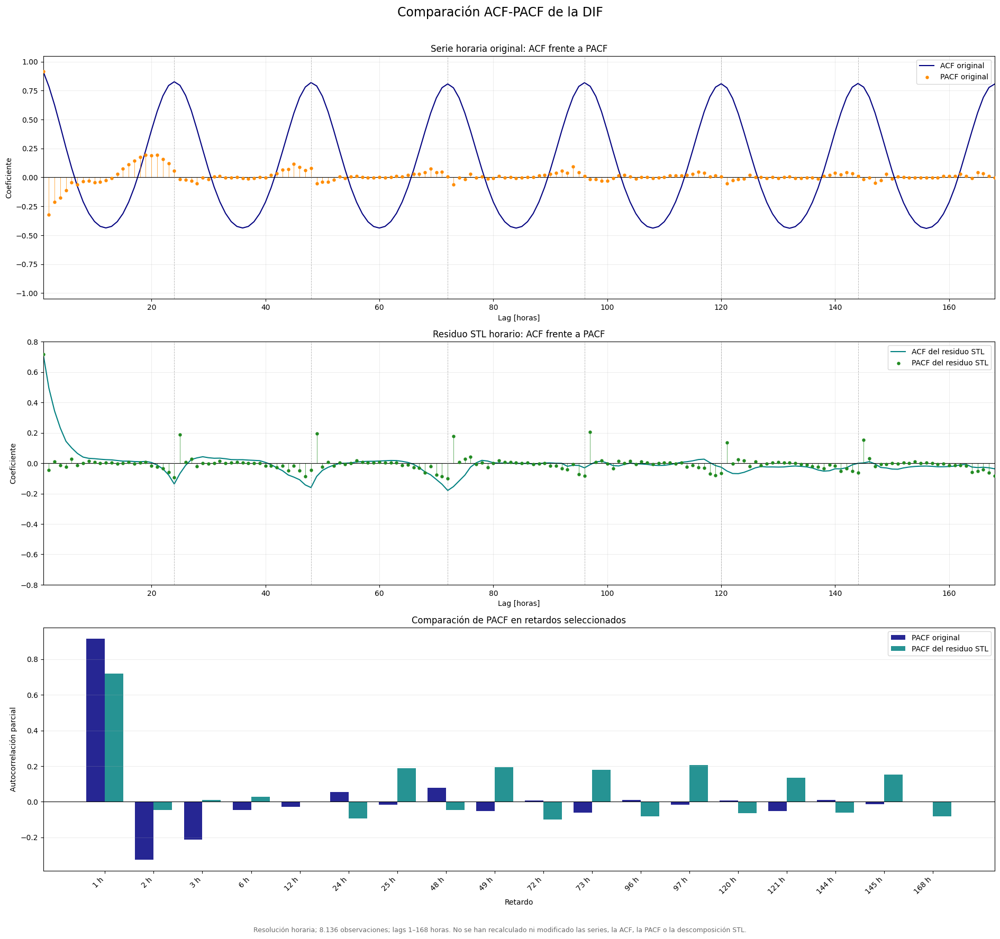

,comprobacion,resultado
0,Archivo gráfico creado,True
1,Nombre del archivo,comparacion_ACF_PACF_cierre_etapa2_DIF.png
2,Número de paneles,3
3,Lag mínimo mostrado,1
4,Lag máximo mostrado,168


In [58]:
# 1. Preparar los datos gráficos

# Excluir el lag 0 porque siempre vale uno.
tabla_grafico_cierre_etapa2 = tabla_comparacion_cierre_etapa2_dif[
    tabla_comparacion_cierre_etapa2_dif["lag_horas"] >= 1
]
lags_grafico_cierre = tabla_grafico_cierre_etapa2["lag_horas"].to_numpy()


# 2. Crear la figura principal
figura_cierre_etapa2, ejes_cierre_etapa2 = plt.subplots(nrows=3, ncols=1, figsize=(19, 18))
eje_original_cierre = ejes_cierre_etapa2[0]
eje_residuo_cierre = ejes_cierre_etapa2[1]
eje_barras_cierre = ejes_cierre_etapa2[2]


# 3. Comparar ACF y PACF de la serie original
eje_original_cierre.plot(
    lags_grafico_cierre,
    tabla_grafico_cierre_etapa2["acf_original"],
    color="navy",
    linewidth=1.5,
    label="ACF original",
)
eje_original_cierre.vlines(
    lags_grafico_cierre,
    0,
    tabla_grafico_cierre_etapa2["pacf_original"],
    color="darkorange",
    linewidth=0.7,
    alpha=0.70,
)
eje_original_cierre.scatter(
    lags_grafico_cierre,
    tabla_grafico_cierre_etapa2["pacf_original"],
    color="darkorange",
    s=13,
    zorder=3,
    label="PACF original",
)
eje_original_cierre.axhline(0, color="black", linewidth=0.8)
for lag_diario in LAGS_DIARIOS_CIERRE_ETAPA2_DIF:
    eje_original_cierre.axvline(lag_diario, color="grey", linestyle="--", linewidth=0.7, alpha=0.55)

eje_original_cierre.set_xlim(1, MAX_LAG_CIERRE_ETAPA2_DIF)
eje_original_cierre.set_ylim(-1.05, 1.05)
eje_original_cierre.set_title("Serie horaria original: ACF frente a PACF")
eje_original_cierre.set_xlabel("Lag [horas]")
eje_original_cierre.set_ylabel("Coeficiente")
eje_original_cierre.grid(alpha=0.22)
eje_original_cierre.legend(loc="best")


# 4. Comparar ACF y PACF del residuo STL
eje_residuo_cierre.plot(
    lags_grafico_cierre,
    tabla_grafico_cierre_etapa2["acf_residuo"],
    color="teal",
    linewidth=1.5,
    label="ACF del residuo STL",
)
eje_residuo_cierre.vlines(
    lags_grafico_cierre,
    0,
    tabla_grafico_cierre_etapa2["pacf_residuo"],
    color="forestgreen",
    linewidth=0.7,
    alpha=0.70,
)
eje_residuo_cierre.scatter(
    lags_grafico_cierre,
    tabla_grafico_cierre_etapa2["pacf_residuo"],
    color="forestgreen",
    s=13,
    zorder=3,
    label="PACF del residuo STL",
)
eje_residuo_cierre.axhline(0, color="black", linewidth=0.8)
for lag_diario in LAGS_DIARIOS_CIERRE_ETAPA2_DIF:
    eje_residuo_cierre.axvline(lag_diario, color="grey", linestyle="--", linewidth=0.7, alpha=0.55)

eje_residuo_cierre.set_xlim(1, MAX_LAG_CIERRE_ETAPA2_DIF)
eje_residuo_cierre.set_ylim(-0.80, 0.80)
eje_residuo_cierre.set_title("Residuo STL horario: ACF frente a PACF")
eje_residuo_cierre.set_xlabel("Lag [horas]")
eje_residuo_cierre.set_ylabel("Coeficiente")
eje_residuo_cierre.grid(alpha=0.22)
eje_residuo_cierre.legend(loc="best")


# 5. Comparar las PACF en retardos seleccionados

# Seleccionar únicamente las columnas necesarias.
tabla_barras_cierre = tabla_lags_clave_cierre_etapa2_dif[
    ["lag_horas", "pacf_original", "pacf_residuo"]
].copy()
posiciones_barras_cierre = np.arange(len(tabla_barras_cierre))
anchura_barras_cierre = 0.38
eje_barras_cierre.bar(
    posiciones_barras_cierre - anchura_barras_cierre / 2,
    tabla_barras_cierre["pacf_original"],
    width=anchura_barras_cierre,
    color="navy",
    alpha=0.85,
    label="PACF original",
)
eje_barras_cierre.bar(
    posiciones_barras_cierre + anchura_barras_cierre / 2,
    tabla_barras_cierre["pacf_residuo"],
    width=anchura_barras_cierre,
    color="teal",
    alpha=0.85,
    label="PACF del residuo STL",
)
eje_barras_cierre.axhline(0, color="black", linewidth=0.8)
eje_barras_cierre.set_xticks(posiciones_barras_cierre)
eje_barras_cierre.set_xticklabels(
    [f"{lag} h" for lag in tabla_barras_cierre["lag_horas"]], rotation=45, ha="right"
)
eje_barras_cierre.set_title("Comparación de PACF en retardos seleccionados")
eje_barras_cierre.set_xlabel("Retardo")
eje_barras_cierre.set_ylabel("Autocorrelación parcial")
eje_barras_cierre.grid(axis="y", alpha=0.22)
eje_barras_cierre.legend(loc="best")


# 6. Finalizar y guardar la figura
figura_cierre_etapa2.suptitle("Comparación ACF-PACF de la DIF", fontsize=17)
figura_cierre_etapa2.text(
    0.5,
    0.006,
    (
        "Resolución horaria; 8.136 observaciones; "
        "lags 1–168 horas. No se han recalculado ni modificado "
        "las series, la ACF, la PACF o la descomposición STL."
    ),
    ha="center",
    fontsize=9,
    color="dimgray",
)
figura_cierre_etapa2.tight_layout(rect=[0, 0.025, 1, 0.97])
ruta_grafico_cierre_etapa2_dif = (
    directorio_resultados_cierre_etapa2_dif / "comparacion_ACF_PACF_cierre_etapa2_DIF.png"
)
figura_cierre_etapa2.savefig(ruta_grafico_cierre_etapa2_dif, dpi=200, bbox_inches="tight")
plt.show()
plt.close(figura_cierre_etapa2)


# 7. Crear el control gráfico
control_archivo_grafico_cierre = bool(ruta_grafico_cierre_etapa2_dif.exists())
control_grafico_cierre_etapa2_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Archivo gráfico creado",
            "Nombre del archivo",
            "Número de paneles",
            "Lag mínimo mostrado",
            "Lag máximo mostrado",
        ],
        "resultado": [
            control_archivo_grafico_cierre,
            ruta_grafico_cierre_etapa2_dif.name,
            3,
            1,
            MAX_LAG_CIERRE_ETAPA2_DIF,
        ],
    }
)
display(control_grafico_cierre_etapa2_dif)

### Interpretación

La comparación entre las funciones ACF y PACF permitió distinguir la dependencia temporal total de la dependencia lineal directa de la radiación difusa. En la serie horaria original, tanto la ACF como la PACF del primer retardo alcanzaron un valor de 0,915, confirmando una persistencia muy elevada entre horas consecutivas. Después de eliminar mediante STL la tendencia y el componente estacional diario, la PACF del residuo permaneció elevada en una hora, con un valor de 0,719. Por tanto, una parte sustancial de la continuidad horaria no se debe exclusivamente al ciclo solar, sino también a la persistencia de las desviaciones de corto plazo, posiblemente asociadas con la evolución de las condiciones atmosféricas.

En cambio, la dependencia observada mediante la ACF residual en dos y tres horas, con coeficientes de 0,494 y 0,343, se redujo en la PACF a −0,046 y 0,010, respectivamente. Esto indica que dicha correlación se transmite principalmente a través de la hora inmediatamente anterior y no representa información lineal directa adicional de magnitud relevante. Asimismo, aunque la ACF original mostró una fuerte repetición en 24 horas, con un coeficiente de 0,826, la PACF correspondiente fue únicamente de 0,056. La elevada autocorrelación diaria se explica, por tanto, principalmente por la repetición del perfil diario y por la cadena de dependencias horarias intermedias.

En conjunto, los resultados identifican la hora inmediatamente anterior como la principal fuente de información lineal directa. El ciclo diario continúa siendo relevante como estructura global, pero no como un único retardo independiente. Estos resultados justifican evaluar para N-BEATS ventanas continuas que incluyan tanto la historia reciente como, al menos, un ciclo diario completo. No obstante, la longitud definitiva del backcast deberá seleccionarse mediante validación temporal fuera de muestra. La ACF y la PACF únicamente evalúan dependencia lineal, por lo que no excluyen la existencia de relaciones no lineales aprovechables por el modelo.

**Implicaciones para la N-BEATS**

El análisis respalda:

- Utilizar una ventana continua que incluya las horas más recientes.
- Considerar 24 horas como una longitud mínima candidata de backcast.
- Comparar experimentalmente ventanas de 24, 48 y posiblemente 168 horas.
- Incorporar un modelo ingenuo de persistencia de una hora como baseline obligatorio.
- Incorporar también un baseline estacional que utilice el valor de 24 horas antes.

## 13. Primera diferencia horaria

Una vez estudiada la dependencia temporal de los niveles de radiación difusa mediante las funciones ACF y PACF, se planteó el análisis de la primera diferencia horaria. Esta transformación se definió como $\Delta DIF_t=DIF_t-DIF_{t-1}$, de modo que cada observación representa el incremento o disminución de la radiación difusa respecto a la hora inmediatamente anterior. A diferencia de la serie original, la primera diferencia no describe el nivel alcanzado por la variable, sino su evolución entre dos horas consecutivas.

El objetivo de este análisis es distinguir entre la memoria del nivel y la memoria de los cambios. Una serie puede presentar una autocorrelación elevada porque sus valores evolucionan lentamente, porque contiene una tendencia o porque reproduce un ciclo diario, sin que sus incrementos sean necesariamente predecibles. Por ello, la elevada autocorrelación detectada en la serie original no permite concluir por sí sola que las subidas y bajadas de DIF mantengan una estructura temporal persistente.

El análisis de la ACF de la primera diferencia permitirá comprobar si los incrementos horarios tienden a continuar, a revertirse o a comportarse de forma aproximadamente independiente. Una autocorrelación positiva en los primeros retardos sería compatible con la continuidad de los cambios, mientras que una autocorrelación negativa podría indicar alternancia o corrección. No obstante, esta última situación deberá interpretarse con cautela, ya que la propia operación de diferenciación puede inducir autocorrelaciones negativas entre incrementos consecutivos al compartir una observación intermedia con signo opuesto.

También se estudiarán los retardos próximos a 24 horas para determinar si la dinámica horaria se repite diariamente. En este caso no se analizaría si el nivel de DIF de un día se parece al del día anterior, sino si los incrementos producidos en intervalos horarios equivalentes presentan un comportamiento semejante. La primera diferencia atenúa la persistencia asociada al nivel y a los movimientos lentos de la serie, aunque no elimina necesariamente la estacionalidad diaria.

Este análisis tendrá una finalidad diagnóstica y no implica que N-BEATS vaya a entrenarse sobre la serie diferenciada. El objetivo predictivo continuará siendo la radiación difusa expresada en niveles. Los resultados servirán para determinar si la capacidad predictiva de la historia reciente procede únicamente de la persistencia del nivel y del ciclo solar o si los propios cambios horarios contienen información temporal adicional aprovechable por el modelo.

### 13.1 Construcción de la primera diferencia

In [59]:
# 1. Importar las librerías necesarias

# NumPy permite realizar comprobaciones y cálculos numéricos.
import numpy as np

# pandas permite trabajar con series temporales y tablas.
import pandas as pd

# Matplotlib permite crear los gráficos.
import matplotlib.pyplot as plt

# Path permite gestionar carpetas y archivos.
from pathlib import Path

# datetime permite crear una marca temporal para los resultados.
from datetime import datetime

# JSON permite guardar la configuración del análisis.
import json

# statsmodels permite registrar su versión.
import statsmodels

# ACF calcula la función de autocorrelación.
from statsmodels.tsa.stattools import acf

# display muestra tablas formateadas en el notebook.
from IPython.display import display

# 2. Comprobar la serie horaria preparada anteriormente
NOMBRE_SERIE_ORIGEN_ETAPA3_DIF = "serie_horaria_original_etapa2_dif"
if NOMBRE_SERIE_ORIGEN_ETAPA3_DIF not in globals():
    raise NameError(
        "No existe 'serie_horaria_original_etapa2_dif'. "
        "Ejecuta previamente la preparación horaria "
        "realizada en la sección 10."
    )

serie_horaria_etapa3_dif = serie_horaria_original_etapa2_dif.copy(deep=True).astype(float)
serie_horaria_etapa3_dif.name = "DIF_horaria_original_etapa3"
if not isinstance(serie_horaria_etapa3_dif.index, pd.DatetimeIndex):
    raise TypeError("La serie horaria debe tener un DatetimeIndex.")

# Comprobar que no existan timestamps duplicados.
if serie_horaria_etapa3_dif.index.duplicated().any():
    raise ValueError("La serie horaria contiene timestamps duplicados.")

if not serie_horaria_etapa3_dif.index.is_monotonic_increasing:
    raise ValueError("La serie horaria no está ordenada.")

# Comprobar que no existan valores ausentes.
if serie_horaria_etapa3_dif.isna().any():
    raise ValueError("La serie horaria contiene valores ausentes.")

if not np.isfinite(serie_horaria_etapa3_dif.to_numpy()).all():
    raise ValueError("La serie horaria contiene valores no finitos.")

intervalos_etapa3_dif = serie_horaria_etapa3_dif.index.to_series().diff().dropna()
control_frecuencia_etapa3_dif = bool(intervalos_etapa3_dif.eq(pd.Timedelta(hours=1)).all())

# Detener el análisis si la frecuencia no es exactamente horaria.
if not control_frecuencia_etapa3_dif:
    raise ValueError("La separación entre observaciones no es siempre " "de una hora.")


# 3. Construir la primera diferencia
diferencia_con_inicial_ausente_etapa3_dif = serie_horaria_etapa3_dif.diff(periods=1)
if diferencia_con_inicial_ausente_etapa3_dif.isna().sum() != 1:
    raise RuntimeError(
        "La primera diferencia ha generado un número " "inesperado de valores ausentes."
    )

serie_diferencia_horaria_etapa3_dif = diferencia_con_inicial_ausente_etapa3_dif.dropna().copy()
serie_diferencia_horaria_etapa3_dif.name = "Delta_DIF_horaria"

# Calcular la magnitud del cambio sin tener en cuenta su signo.
serie_diferencia_absoluta_etapa3_dif = serie_diferencia_horaria_etapa3_dif.abs()
serie_diferencia_absoluta_etapa3_dif.name = "Delta_DIF_horaria_absoluta"


# 4. Comprobar la transformación
diferencia_manual_etapa3_dif = (
    serie_horaria_etapa3_dif.iloc[1:].to_numpy() - serie_horaria_etapa3_dif.iloc[:-1].to_numpy()
)
control_diferencia_etapa3_dif = bool(
    np.allclose(
        serie_diferencia_horaria_etapa3_dif.to_numpy(),
        diferencia_manual_etapa3_dif,
        rtol=1e-12,
        atol=1e-10,
    )
)
if not control_diferencia_etapa3_dif:
    raise RuntimeError(
        "La primera diferencia no coincide con la resta " "manual entre horas consecutivas."
    )


# 5. Crear el directorio general de resultados
marca_ejecucion_etapa3_dif = datetime.now().strftime("%Y%m%d_%H%M%S")
directorio_resultados_etapa3_dif = Path(
    "resultados_etapa3_dinamica_cambios_DIF_" f"{marca_ejecucion_etapa3_dif}"
)
directorio_resultados_etapa3_dif.mkdir(parents=True, exist_ok=True)


# 6. Resumir y mostrar los resultados
control_preparacion_etapa3_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Serie utilizada",
            "Primera hora original",
            "Última hora original",
            "Observaciones originales",
            "Diferencias obtenidas",
            "Ausencias en las diferencias",
            "Frecuencia horaria regular",
            "Diferencia comprobada manualmente",
            "Media horaria recalculada ahora",
            "Valores interpolados ahora",
        ],
        "resultado": [
            NOMBRE_SERIE_ORIGEN_ETAPA3_DIF,
            serie_horaria_etapa3_dif.index.min(),
            serie_horaria_etapa3_dif.index.max(),
            len(serie_horaria_etapa3_dif),
            len(serie_diferencia_horaria_etapa3_dif),
            int(serie_diferencia_horaria_etapa3_dif.isna().sum()),
            control_frecuencia_etapa3_dif,
            control_diferencia_etapa3_dif,
            False,
            False,
        ],
    }
)
print("Control de la primera diferencia horaria:")
display(control_preparacion_etapa3_dif)
print("\nΔDIF > 0: DIF aumentó respecto a la hora anterior.")
print("ΔDIF < 0: DIF disminuyó respecto a la hora anterior.")
print("ΔDIF = 0: DIF no cambió respecto a la hora anterior.")

Control de la primera diferencia horaria:


,comprobacion,resultado
0,Serie utilizada,serie_horaria_original_etapa2_dif
1,Primera hora original,2023-12-28 00:00:00
2,Última hora original,2024-11-30 23:00:00
3,Observaciones originales,8136
4,Diferencias obtenidas,8135
5,Ausencias en las diferencias,0
6,Frecuencia horaria regular,True
7,Diferencia comprobada manualmente,True
8,Media horaria recalculada ahora,False
9,Valores interpolados ahora,False



ΔDIF > 0: DIF aumentó respecto a la hora anterior.
ΔDIF < 0: DIF disminuyó respecto a la hora anterior.
ΔDIF = 0: DIF no cambió respecto a la hora anterior.


### 13.2 Distribución y rampas

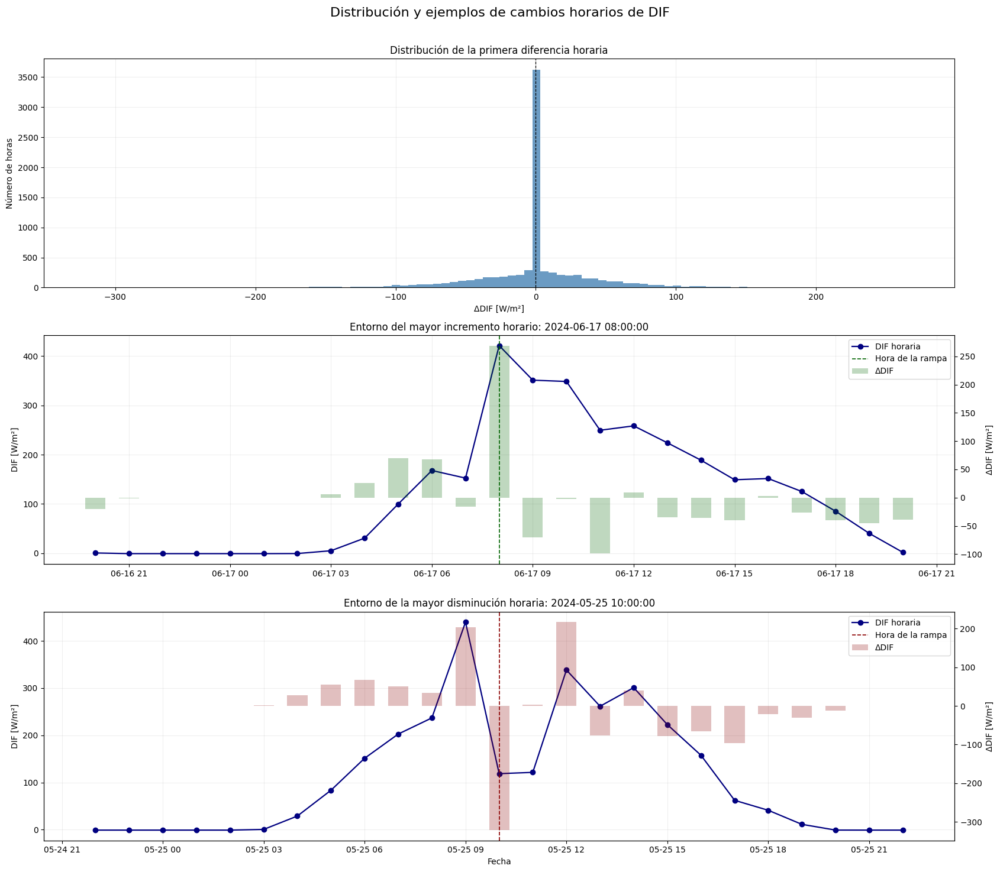

Resumen estadístico de los cambios:


,Delta_DIF,Delta_DIF_absoluta
count,8135.0000,8135.0000
mean,0.0001,24.4228
std,43.1680,35.5940
min,-321.2500,0.0000
1%,-132.5387,0.0000
5%,-71.9233,0.0000
25%,-6.6417,0.0667
50%,0.0000,7.4500
75%,8.5807,37.7250
95%,69.6017,96.4917



Distribución de los signos:


,tipo_cambio,porcentaje
0,Incremento,39.68 %
1,Disminución,38.18 %
2,Sin cambio,22.14 %



Rampas horarias extremas:


,Date/Time,Delta_DIF,tipo
0,2024-06-17 08:00:00,269.000,Incremento
1,2024-08-10 11:00:00,261.667,Incremento
2,2024-07-11 11:00:00,256.767,Incremento
3,2024-06-04 07:00:00,251.583,Incremento
4,2024-06-03 09:00:00,221.500,Incremento
5,2024-07-02 12:00:00,218.000,Incremento
6,2024-06-06 08:00:00,217.200,Incremento
7,2024-05-25 12:00:00,216.950,Incremento
8,2024-08-10 14:00:00,207.300,Incremento
9,2024-07-07 07:00:00,204.133,Incremento


In [60]:
# 1. Calcular el resumen estadístico
resumen_diferencia_etapa3_dif = (
    serie_diferencia_horaria_etapa3_dif.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .rename("Delta_DIF")
    .to_frame()
)
resumen_diferencia_etapa3_dif["Delta_DIF_absoluta"] = serie_diferencia_absoluta_etapa3_dif.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)
porcentaje_incrementos_etapa3_dif = float(100 * serie_diferencia_horaria_etapa3_dif.gt(0).mean())
porcentaje_disminuciones_etapa3_dif = float(100 * serie_diferencia_horaria_etapa3_dif.lt(0).mean())
porcentaje_sin_cambio_etapa3_dif = float(100 * serie_diferencia_horaria_etapa3_dif.eq(0).mean())
resumen_signos_etapa3_dif = pd.DataFrame(
    {
        "tipo_cambio": ["Incremento", "Disminución", "Sin cambio"],
        "porcentaje": [
            porcentaje_incrementos_etapa3_dif,
            porcentaje_disminuciones_etapa3_dif,
            porcentaje_sin_cambio_etapa3_dif,
        ],
    }
)


# 2. Localizar las rampas más intensas
rampas_positivas_etapa3_dif = (
    serie_diferencia_horaria_etapa3_dif.nlargest(10)
    .rename("Delta_DIF")
    .reset_index()
    .rename(columns={"index": "Date/Time"})
)
rampas_positivas_etapa3_dif["tipo"] = "Incremento"
rampas_negativas_etapa3_dif = (
    serie_diferencia_horaria_etapa3_dif.nsmallest(10)
    .rename("Delta_DIF")
    .reset_index()
    .rename(columns={"index": "Date/Time"})
)
rampas_negativas_etapa3_dif["tipo"] = "Disminución"
tabla_rampas_extremas_etapa3_dif = pd.concat(
    [rampas_positivas_etapa3_dif, rampas_negativas_etapa3_dif], ignore_index=True
)
fecha_max_incremento_etapa3_dif = serie_diferencia_horaria_etapa3_dif.idxmax()
fecha_max_disminucion_etapa3_dif = serie_diferencia_horaria_etapa3_dif.idxmin()


# 3. Crear la figura
figura_rampas_etapa3_dif, ejes_rampas_etapa3_dif = plt.subplots(nrows=3, ncols=1, figsize=(17, 15))
ejes_rampas_etapa3_dif[0].hist(
    serie_diferencia_horaria_etapa3_dif, bins=100, color="steelblue", alpha=0.80
)
ejes_rampas_etapa3_dif[0].axvline(0, color="black", linestyle="--", linewidth=0.9)
ejes_rampas_etapa3_dif[0].set_title("Distribución de la primera diferencia horaria")
ejes_rampas_etapa3_dif[0].set_xlabel("ΔDIF [W/m²]")
ejes_rampas_etapa3_dif[0].set_ylabel("Número de horas")
ejes_rampas_etapa3_dif[0].grid(alpha=0.20)


# 4. Representar las dos rampas extremas
eventos_rampas_etapa3_dif = [
    (fecha_max_incremento_etapa3_dif, "Entorno del mayor incremento horario", "darkgreen"),
    (fecha_max_disminucion_etapa3_dif, "Entorno de la mayor disminución horaria", "darkred"),
]
for eje, evento in zip(ejes_rampas_etapa3_dif[1:], eventos_rampas_etapa3_dif):
    fecha_evento, titulo_evento, color_evento = evento
    inicio_ventana = fecha_evento - pd.Timedelta(hours=12)
    fin_ventana = fecha_evento + pd.Timedelta(hours=12)
    ventana_nivel = serie_horaria_etapa3_dif.loc[inicio_ventana:fin_ventana]
    ventana_cambios = serie_diferencia_horaria_etapa3_dif.reindex(ventana_nivel.index)
    eje.plot(
        ventana_nivel.index,
        ventana_nivel,
        color="navy",
        marker="o",
        linewidth=1.6,
        label="DIF horaria",
    )
    eje.axvline(
        fecha_evento, color=color_evento, linestyle="--", linewidth=1.2, label="Hora de la rampa"
    )
    eje_cambio = eje.twinx()
    eje_cambio.bar(
        ventana_cambios.index,
        ventana_cambios,
        width=0.025,
        color=color_evento,
        alpha=0.25,
        label="ΔDIF",
    )
    eje.set_title(f"{titulo_evento}: {fecha_evento}")
    eje.set_ylabel("DIF [W/m²]")
    eje_cambio.set_ylabel("ΔDIF [W/m²]")
    eje.grid(alpha=0.20)
    lineas_1, etiquetas_1 = eje.get_legend_handles_labels()
    lineas_2, etiquetas_2 = eje_cambio.get_legend_handles_labels()
    eje.legend(lineas_1 + lineas_2, etiquetas_1 + etiquetas_2, loc="best")

ejes_rampas_etapa3_dif[2].set_xlabel("Fecha")
figura_rampas_etapa3_dif.suptitle("Distribución y ejemplos de cambios horarios de DIF", fontsize=16)
figura_rampas_etapa3_dif.tight_layout(rect=[0, 0, 1, 0.97])
ruta_grafico_rampas_etapa3_dif = (
    directorio_resultados_etapa3_dif / "01_distribucion_y_rampas_Delta_DIF.png"
)
figura_rampas_etapa3_dif.savefig(ruta_grafico_rampas_etapa3_dif, dpi=200, bbox_inches="tight")
plt.show()
plt.close(figura_rampas_etapa3_dif)


# 5. Mostrar las tablas
print("Resumen estadístico de los cambios:")
display(resumen_diferencia_etapa3_dif.style.format(precision=4))
print("\nDistribución de los signos:")
display(resumen_signos_etapa3_dif.style.format({"porcentaje": "{:.2f} %"}))
print("\nRampas horarias extremas:")
display(tabla_rampas_extremas_etapa3_dif.style.format({"Delta_DIF": "{:.3f}"}))

### 13.3 ACF de la primera diferencia

/tmp/ipykernel_1005/2691664008.py:12: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = acf(


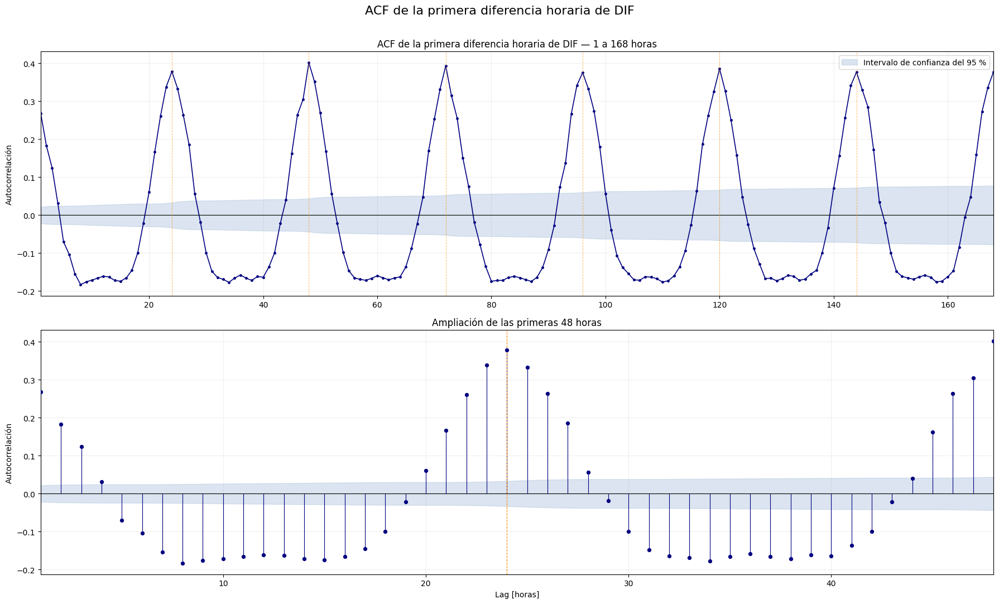

ACF de ΔDIF en retardos relevantes:


,lag_horas,acf,IC95_inferior,IC95_superior,banda_inferior_cero,banda_superior_cero,significativo_95,parejas_teoricas
0,1,0.268295,0.246565,0.290026,-0.021730,0.021730,True,8134
1,2,0.182825,0.159583,0.206067,-0.023242,0.023242,True,8133
2,3,0.124320,0.100408,0.148231,-0.023912,0.023912,True,8132
3,6,-0.103515,-0.127845,-0.079185,-0.024330,0.024330,True,8129
4,12,-0.160887,-0.188076,-0.133698,-0.027189,0.027189,True,8123
5,24,0.377826,0.344620,0.411032,-0.033206,0.033206,True,8111
6,48,0.401317,0.357542,0.445092,-0.043775,0.043775,True,8087
7,72,0.392871,0.340275,0.445467,-0.052596,0.052596,True,8063
8,96,0.375059,0.315182,0.434935,-0.059877,0.059877,True,8039
9,120,0.385058,0.318568,0.451547,-0.066489,0.066489,True,8015


In [61]:
# 1. Configuración
MAX_LAG_ACF_ETAPA3_DIF = 168
ALPHA_ACF_ETAPA3_DIF = 0.05
LAGS_CLAVE_ACF_ETAPA3_DIF = [1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168]


# 2. Crear una función común de cálculo


# Esta función se utilizará para ΔDIF y posteriormente para |ΔDIF|.
def calcular_acf_etapa3_dif(serie, max_lag, alpha):
    resultado = acf(
        serie.to_numpy(dtype=float),
        nlags=max_lag,
        fft=True,
        alpha=alpha,
        adjusted=False,
        missing="raise",
    )
    valores = np.asarray(resultado[0], dtype=float)
    intervalos = np.asarray(resultado[1], dtype=float)
    lags = np.arange(max_lag + 1)
    tabla = pd.DataFrame(
        {
            "lag_horas": lags,
            "acf": valores,
            "IC95_inferior": intervalos[:, 0],
            "IC95_superior": intervalos[:, 1],
            "banda_inferior_cero": (intervalos[:, 0] - valores),
            "banda_superior_cero": (intervalos[:, 1] - valores),
            "significativo_95": ((intervalos[:, 0] > 0) | (intervalos[:, 1] < 0)),
            "parejas_teoricas": (len(serie) - lags),
        }
    )
    return tabla


# 3. Crear una función gráfica común
def representar_acf_etapa3_dif(tabla, titulo, color, ruta_salida):
    figura, ejes = plt.subplots(nrows=2, ncols=1, figsize=(18, 11))
    tabla_sin_cero = tabla[tabla["lag_horas"] >= 1]
    ejes[0].plot(
        tabla_sin_cero["lag_horas"],
        tabla_sin_cero["acf"],
        color=color,
        marker="o",
        markersize=2.5,
        linewidth=1.2,
    )
    ejes[0].fill_between(
        tabla_sin_cero["lag_horas"],
        tabla_sin_cero["banda_inferior_cero"],
        tabla_sin_cero["banda_superior_cero"],
        color="lightsteelblue",
        alpha=0.45,
        label="Intervalo de confianza del 95 %",
    )
    ejes[0].axhline(0, color="black", linewidth=0.8)
    for lag_diario in range(24, MAX_LAG_ACF_ETAPA3_DIF + 1, 24):
        ejes[0].axvline(lag_diario, color="darkorange", linestyle="--", linewidth=0.7, alpha=0.60)

    ejes[0].set_xlim(1, MAX_LAG_ACF_ETAPA3_DIF)
    ejes[0].set_ylabel("Autocorrelación")
    ejes[0].set_title(f"{titulo} — 1 a 168 horas")
    ejes[0].grid(alpha=0.20)
    ejes[0].legend()
    tabla_48h = tabla[tabla["lag_horas"].between(1, 48)]
    ejes[1].vlines(tabla_48h["lag_horas"], 0, tabla_48h["acf"], color=color, linewidth=0.8)
    ejes[1].scatter(tabla_48h["lag_horas"], tabla_48h["acf"], color=color, s=18, zorder=3)
    ejes[1].fill_between(
        tabla_48h["lag_horas"],
        tabla_48h["banda_inferior_cero"],
        tabla_48h["banda_superior_cero"],
        color="lightsteelblue",
        alpha=0.45,
    )
    ejes[1].axhline(0, color="black", linewidth=0.8)
    for lag_diario in [24, 48]:
        ejes[1].axvline(lag_diario, color="darkorange", linestyle="--", linewidth=0.8)

    ejes[1].set_xlim(1, 48)
    ejes[1].set_xlabel("Lag [horas]")
    ejes[1].set_ylabel("Autocorrelación")
    ejes[1].set_title("Ampliación de las primeras 48 horas")
    ejes[1].grid(alpha=0.20)
    figura.suptitle(titulo, fontsize=16)
    figura.tight_layout(rect=[0, 0, 1, 0.97])
    figura.savefig(ruta_salida, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(figura)


# 4. Calcular la ACF de ΔDIF
tabla_acf_diferencia_etapa3_dif = calcular_acf_etapa3_dif(
    serie_diferencia_horaria_etapa3_dif, MAX_LAG_ACF_ETAPA3_DIF, ALPHA_ACF_ETAPA3_DIF
)
tabla_acf_diferencia_lags_clave_etapa3_dif = (
    tabla_acf_diferencia_etapa3_dif[
        tabla_acf_diferencia_etapa3_dif["lag_horas"].isin(LAGS_CLAVE_ACF_ETAPA3_DIF)
    ]
    .copy()
    .reset_index(drop=True)
)
ruta_grafico_acf_diferencia_etapa3_dif = directorio_resultados_etapa3_dif / "02_ACF_Delta_DIF.png"
representar_acf_etapa3_dif(
    tabla_acf_diferencia_etapa3_dif,
    "ACF de la primera diferencia horaria de DIF",
    "navy",
    ruta_grafico_acf_diferencia_etapa3_dif,
)
print("ACF de ΔDIF en retardos relevantes:")
display(
    tabla_acf_diferencia_lags_clave_etapa3_dif.style.format(
        {"acf": "{:.6f}", "IC95_inferior": "{:.6f}", "IC95_superior": "{:.6f}"}
    )
)

### 13.4 ACF de la magnitud de los cambios

/tmp/ipykernel_1005/2691664008.py:12: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = acf(


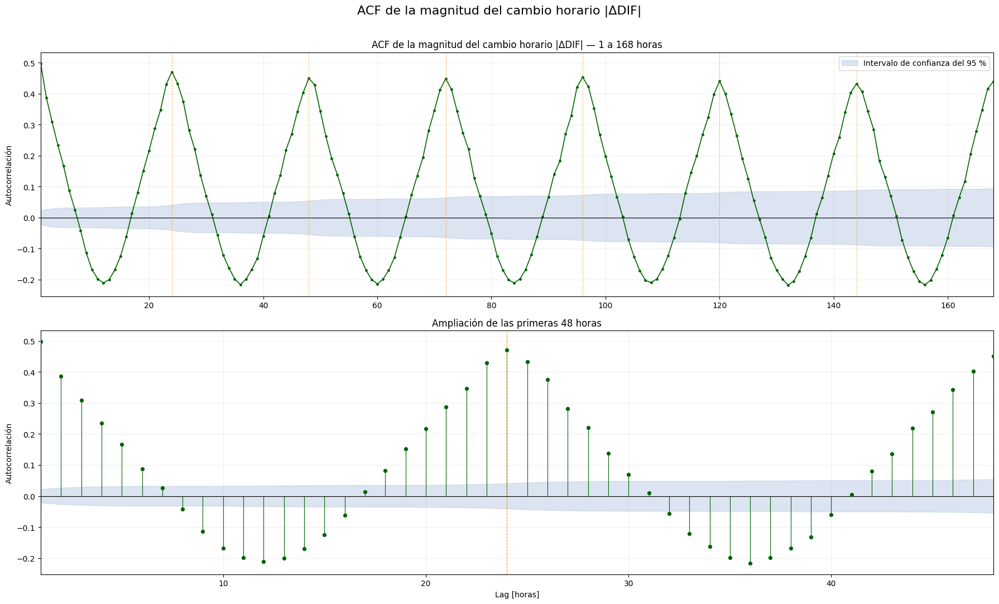

ACF de |ΔDIF| en retardos relevantes:


,lag_horas,acf,IC95_inferior,IC95_superior,banda_inferior_cero,banda_superior_cero,significativo_95,parejas_teoricas
0,1,0.497640,0.475910,0.519371,-0.021730,0.021730,True,8134
1,2,0.386805,0.360233,0.413378,-0.026572,0.026572,True,8133
2,3,0.308664,0.279554,0.337774,-0.029110,0.029110,True,8132
3,6,0.087556,0.055685,0.119427,-0.031871,0.031871,True,8129
4,12,-0.211423,-0.244616,-0.178230,-0.033193,0.033193,True,8123
5,24,0.470709,0.429899,0.511519,-0.040810,0.040810,True,8111
6,48,0.449931,0.395746,0.504115,-0.054184,0.054184,True,8087
7,72,0.448342,0.383898,0.512787,-0.064444,0.064444,True,8063
8,96,0.453721,0.380575,0.526867,-0.073146,0.073146,True,8039
9,120,0.440585,0.359685,0.521485,-0.080900,0.080900,True,8015



Esta ACF no estudia la dirección del cambio. Estudia si las horas con cambios intensos tienden a aparecer agrupadas.


In [62]:
# 1. Calcular la ACF de |ΔDIF|
tabla_acf_diferencia_absoluta_etapa3_dif = calcular_acf_etapa3_dif(
    serie_diferencia_absoluta_etapa3_dif, MAX_LAG_ACF_ETAPA3_DIF, ALPHA_ACF_ETAPA3_DIF
)
tabla_acf_diferencia_absoluta_lags_clave_etapa3_dif = (
    tabla_acf_diferencia_absoluta_etapa3_dif[
        tabla_acf_diferencia_absoluta_etapa3_dif["lag_horas"].isin(LAGS_CLAVE_ACF_ETAPA3_DIF)
    ]
    .copy()
    .reset_index(drop=True)
)
ruta_grafico_acf_diferencia_absoluta_etapa3_dif = (
    directorio_resultados_etapa3_dif / "03_ACF_magnitud_Delta_DIF.png"
)
representar_acf_etapa3_dif(
    tabla_acf_diferencia_absoluta_etapa3_dif,
    "ACF de la magnitud del cambio horario |ΔDIF|",
    "darkgreen",
    ruta_grafico_acf_diferencia_absoluta_etapa3_dif,
)
print("ACF de |ΔDIF| en retardos relevantes:")
display(
    tabla_acf_diferencia_absoluta_lags_clave_etapa3_dif.style.format(
        {"acf": "{:.6f}", "IC95_inferior": "{:.6f}", "IC95_superior": "{:.6f}"}
    )
)
print(
    "\nEsta ACF no estudia la dirección del cambio. "
    "Estudia si las horas con cambios intensos tienden "
    "a aparecer agrupadas."
)

### 13.5 Comparación con y sin radiación

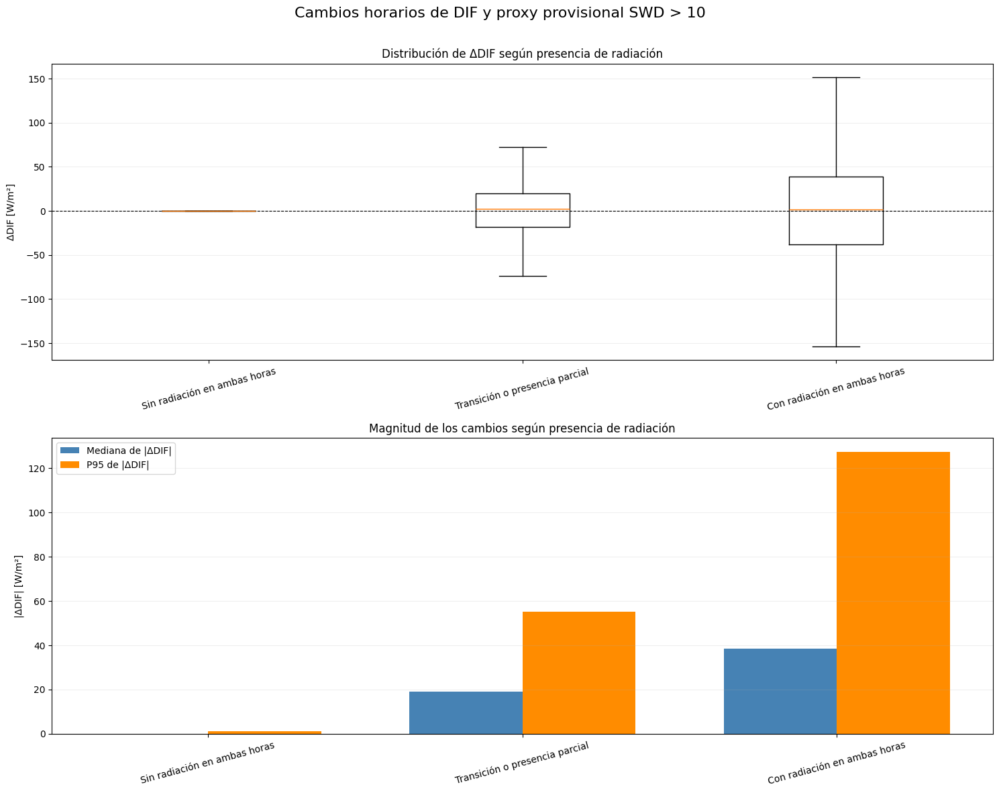

Cambios según la proxy provisional de radiación:


,grupo_radiacion_proxy,n_cambios,media_Delta_DIF,mediana_Delta_DIF,desviacion_Delta_DIF,p05_Delta_DIF,p95_Delta_DIF,media_abs_Delta_DIF,mediana_abs_Delta_DIF,p95_abs_Delta_DIF,porcentaje_incrementos,porcentaje_disminuciones,porcentaje_sin_cambio
0,Sin radiación en ambas horas,3467,0.016,0.000,0.580,-0.633,0.700,0.240,0.000,1.062,24.488,23.565,51.947
1,Transición o presencia parcial,1040,-0.140,2.658,28.219,-45.824,44.155,22.749,19.183,55.313,50.673,49.327,0.000
2,Con radiación en ambas horas,3628,0.025,1.250,62.854,-99.498,99.658,48.012,38.442,127.384,51.047,48.953,0.000



No se ha calculado una ACF eliminando las horas sin radiación, porque eso alteraría el significado temporal de los retardos.


In [63]:
# 1. Comprobar los datos minutales de SWD
COL_SWD_ETAPA3_DIF = "SWD [W/m**2]"
OBJETOS_REQUERIDOS_SWD_ETAPA3_DIF = ["df_t2", "COL_FECHA"]
objetos_ausentes_swd_etapa3_dif = [
    nombre for nombre in OBJETOS_REQUERIDOS_SWD_ETAPA3_DIF if nombre not in globals()
]
if objetos_ausentes_swd_etapa3_dif:
    raise NameError("Faltan objetos necesarios para SWD: " f"{objetos_ausentes_swd_etapa3_dif}")

if COL_SWD_ETAPA3_DIF not in df_t2.columns:
    raise KeyError(f"No existe la columna '{COL_SWD_ETAPA3_DIF}'.")


# 2. Preparar SWD sin modificar df_t2
tabla_swd_minutal_etapa3_dif = df_t2[[COL_FECHA, COL_SWD_ETAPA3_DIF]].copy(deep=True)
tabla_swd_minutal_etapa3_dif[COL_FECHA] = pd.to_datetime(
    tabla_swd_minutal_etapa3_dif[COL_FECHA], errors="coerce"
)
if tabla_swd_minutal_etapa3_dif[COL_FECHA].isna().any():
    raise ValueError("Se han detectado fechas no válidas en SWD.")

tabla_swd_minutal_etapa3_dif[COL_SWD_ETAPA3_DIF] = pd.to_numeric(
    tabla_swd_minutal_etapa3_dif[COL_SWD_ETAPA3_DIF], errors="coerce"
)
tabla_swd_minutal_etapa3_dif = tabla_swd_minutal_etapa3_dif.sort_values(COL_FECHA).set_index(
    COL_FECHA
)
tabla_swd_minutal_etapa3_dif = tabla_swd_minutal_etapa3_dif.loc[
    serie_horaria_etapa3_dif.index.min() : serie_horaria_etapa3_dif.index.max()
]


# 3. Calcular la presencia horaria de SWD > 10
def proporcion_swd_superior_10_etapa3(serie):
    valores_validos = serie.dropna()

    # Devolver ausencia si no existe ningún minuto válido.
    if len(valores_validos) == 0:
        return np.nan

    return float(valores_validos.gt(10).mean())

serie_swd_minutal_etapa3_dif = tabla_swd_minutal_etapa3_dif[COL_SWD_ETAPA3_DIF]
tabla_swd_horaria_etapa3_dif = pd.DataFrame(
    {
        "SWD_media_horaria": (serie_swd_minutal_etapa3_dif.resample("1h").mean()),
        "n_minutos_SWD_validos": (serie_swd_minutal_etapa3_dif.resample("1h").count()),
        "proporcion_minutos_SWD_superior_10": (
            serie_swd_minutal_etapa3_dif.resample("1h").apply(proporcion_swd_superior_10_etapa3)
        ),
    }
)


# 4. Asociar cada cambio con sus dos horas
tabla_cambios_radiacion_etapa3_dif = pd.DataFrame(
    {
        "DIF_actual": (serie_horaria_etapa3_dif.reindex(serie_diferencia_horaria_etapa3_dif.index)),
        "Delta_DIF": (serie_diferencia_horaria_etapa3_dif),
        "Delta_DIF_absoluta": (serie_diferencia_absoluta_etapa3_dif),
    }
)
tabla_cambios_radiacion_etapa3_dif["proporcion_SWD_actual"] = tabla_swd_horaria_etapa3_dif[
    "proporcion_minutos_SWD_superior_10"
].reindex(tabla_cambios_radiacion_etapa3_dif.index)
tabla_cambios_radiacion_etapa3_dif["proporcion_SWD_anterior"] = (
    tabla_swd_horaria_etapa3_dif["proporcion_minutos_SWD_superior_10"]
    .shift(1)
    .reindex(tabla_cambios_radiacion_etapa3_dif.index)
)
swd_actual = tabla_cambios_radiacion_etapa3_dif["proporcion_SWD_actual"]
swd_anterior = tabla_cambios_radiacion_etapa3_dif["proporcion_SWD_anterior"]
mascara_no_evaluable = swd_actual.isna() | swd_anterior.isna()
mascara_sin_radiacion = swd_actual.eq(0) & swd_anterior.eq(0)
mascara_con_radiacion = swd_actual.ge(0.50) & swd_anterior.ge(0.50)
tabla_cambios_radiacion_etapa3_dif["grupo_radiacion_proxy"] = np.select(
    [mascara_no_evaluable, mascara_sin_radiacion, mascara_con_radiacion],
    ["SWD no evaluable", "Sin radiación en ambas horas", "Con radiación en ambas horas"],
    default=("Transición o presencia parcial"),
)
ORDEN_GRUPOS_RADIACION_ETAPA3 = [
    "Sin radiación en ambas horas",
    "Transición o presencia parcial",
    "Con radiación en ambas horas",
    "SWD no evaluable",
]
tabla_cambios_radiacion_etapa3_dif["grupo_radiacion_proxy"] = pd.Categorical(
    tabla_cambios_radiacion_etapa3_dif["grupo_radiacion_proxy"],
    categories=ORDEN_GRUPOS_RADIACION_ETAPA3,
    ordered=True,
)


# 5. Crear el resumen por grupo
registros_resumen_radiacion_etapa3 = []
for grupo in ORDEN_GRUPOS_RADIACION_ETAPA3:
    datos_grupo = tabla_cambios_radiacion_etapa3_dif.loc[
        tabla_cambios_radiacion_etapa3_dif["grupo_radiacion_proxy"] == grupo, "Delta_DIF"
    ].dropna()
    if len(datos_grupo) == 0:
        continue

    registros_resumen_radiacion_etapa3.append(
        {
            "grupo_radiacion_proxy": grupo,
            "n_cambios": len(datos_grupo),
            "media_Delta_DIF": datos_grupo.mean(),
            "mediana_Delta_DIF": datos_grupo.median(),
            "desviacion_Delta_DIF": datos_grupo.std(),
            "p05_Delta_DIF": datos_grupo.quantile(0.05),
            "p95_Delta_DIF": datos_grupo.quantile(0.95),
            "media_abs_Delta_DIF": datos_grupo.abs().mean(),
            "mediana_abs_Delta_DIF": datos_grupo.abs().median(),
            "p95_abs_Delta_DIF": datos_grupo.abs().quantile(0.95),
            "porcentaje_incrementos": 100 * datos_grupo.gt(0).mean(),
            "porcentaje_disminuciones": 100 * datos_grupo.lt(0).mean(),
            "porcentaje_sin_cambio": 100 * datos_grupo.eq(0).mean(),
        }
    )

resumen_cambios_radiacion_etapa3_dif = pd.DataFrame(registros_resumen_radiacion_etapa3)


# 6. Crear la figura comparativa

# Excluir solamente el grupo no evaluable del gráfico.
grupos_grafico_etapa3 = [
    grupo
    for grupo in ORDEN_GRUPOS_RADIACION_ETAPA3
    if (
        grupo != "SWD no evaluable"
        and grupo in (resumen_cambios_radiacion_etapa3_dif["grupo_radiacion_proxy"].tolist())
    )
]
datos_boxplot_etapa3 = [
    tabla_cambios_radiacion_etapa3_dif.loc[
        tabla_cambios_radiacion_etapa3_dif["grupo_radiacion_proxy"] == grupo, "Delta_DIF"
    ].dropna()
    for grupo in grupos_grafico_etapa3
]
figura_radiacion_etapa3_dif, ejes_radiacion_etapa3_dif = plt.subplots(
    nrows=2, ncols=1, figsize=(15, 12)
)
ejes_radiacion_etapa3_dif[0].boxplot(
    datos_boxplot_etapa3, tick_labels=grupos_grafico_etapa3, showfliers=False
)
ejes_radiacion_etapa3_dif[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
ejes_radiacion_etapa3_dif[0].set_title("Distribución de ΔDIF según presencia de radiación")
ejes_radiacion_etapa3_dif[0].set_ylabel("ΔDIF [W/m²]")
ejes_radiacion_etapa3_dif[0].tick_params(axis="x", rotation=15)
ejes_radiacion_etapa3_dif[0].grid(axis="y", alpha=0.20)
resumen_grafico_etapa3 = (
    resumen_cambios_radiacion_etapa3_dif[
        resumen_cambios_radiacion_etapa3_dif["grupo_radiacion_proxy"].isin(grupos_grafico_etapa3)
    ]
    .set_index("grupo_radiacion_proxy")
    .reindex(grupos_grafico_etapa3)
)
posiciones_radiacion_etapa3 = np.arange(len(grupos_grafico_etapa3))
ejes_radiacion_etapa3_dif[1].bar(
    posiciones_radiacion_etapa3 - 0.18,
    resumen_grafico_etapa3["mediana_abs_Delta_DIF"],
    width=0.36,
    label="Mediana de |ΔDIF|",
    color="steelblue",
)
ejes_radiacion_etapa3_dif[1].bar(
    posiciones_radiacion_etapa3 + 0.18,
    resumen_grafico_etapa3["p95_abs_Delta_DIF"],
    width=0.36,
    label="P95 de |ΔDIF|",
    color="darkorange",
)
ejes_radiacion_etapa3_dif[1].set_xticks(posiciones_radiacion_etapa3)
ejes_radiacion_etapa3_dif[1].set_xticklabels(grupos_grafico_etapa3, rotation=15)
ejes_radiacion_etapa3_dif[1].set_ylabel("|ΔDIF| [W/m²]")
ejes_radiacion_etapa3_dif[1].set_title("Magnitud de los cambios según presencia de radiación")
ejes_radiacion_etapa3_dif[1].grid(axis="y", alpha=0.20)
ejes_radiacion_etapa3_dif[1].legend()
figura_radiacion_etapa3_dif.suptitle(
    "Cambios horarios de DIF y proxy provisional SWD > 10", fontsize=16
)
figura_radiacion_etapa3_dif.tight_layout(rect=[0, 0, 1, 0.97])
ruta_grafico_radiacion_etapa3_dif = (
    directorio_resultados_etapa3_dif / "04_cambios_segun_presencia_radiacion.png"
)
figura_radiacion_etapa3_dif.savefig(ruta_grafico_radiacion_etapa3_dif, dpi=200, bbox_inches="tight")
plt.show()
plt.close(figura_radiacion_etapa3_dif)
print("Cambios según la proxy provisional de radiación:")
display(
    resumen_cambios_radiacion_etapa3_dif.style.format(
        {
            columna: "{:.3f}"
            for columna in resumen_cambios_radiacion_etapa3_dif.columns
            if columna not in ["grupo_radiacion_proxy", "n_cambios"]
        }
    )
)
print(
    "\nNo se ha calculado una ACF eliminando las horas "
    "sin radiación, porque eso alteraría el significado "
    "temporal de los retardos."
)

### Interpretación

Con el objetivo de estudiar la dinámica temporal de la radiación difusa más allá de la persistencia de sus niveles, se calculó la primera diferencia de la serie horaria, definida como $\Delta DIF_t=DIF_t-DIF_{t-1}$. El análisis se efectuó sobre 8.136 observaciones horarias regulares, obteniéndose 8.135 diferencias consecutivas sin valores ausentes. En este análisis no se recalcularon las medias horarias, no se interpolaron observaciones y no se utilizó la descomposición STL.

La distribución de la primera diferencia presentó una media prácticamente nula, de 0,0001 W/m², y una mediana igual a cero. Este resultado no implica ausencia de variabilidad, puesto que el valor medio de las primeras diferencias depende esencialmente de la diferencia entre los extremos de la serie. La magnitud media del cambio fue de 24,42 W/m² y su mediana de 7,45 W/m², mientras que los percentiles 95 y 99 alcanzaron 96,49 y 160,16 W/m², respectivamente. El cambio más intenso fue una disminución de 321,25 W/m². La elevada concentración de observaciones alrededor de cero, combinada con la presencia de rampas extremas, muestra que la distribución de los cambios no puede considerarse gaussiana y presenta colas largas.

Los incrementos representaron el 39,68 % de las observaciones, las disminuciones el 38,18 % y las horas sin cambio el 22,14 %. El equilibrio entre incrementos y disminuciones es coherente con una serie anual dominada por ciclos diarios de ascenso y descenso. La elevada proporción de valores nulos se relacionó principalmente con las horas nocturnas, durante las cuales la radiación difusa permanece aproximadamente constante y próxima a cero.

La función de autocorrelación de $\Delta DIF$ presentó valores de 0,268, 0,183 y 0,124 para retardos de una, dos y tres horas. Estos resultados indican una persistencia direccional positiva a corto plazo: los incrementos o disminuciones tienden a prolongarse durante varias horas, aunque la intensidad de esta relación disminuye rápidamente. A seis y doce horas las autocorrelaciones fueron negativas, con valores de −0,104 y −0,161, respectivamente. Esta inversión se asoció con las fases opuestas del ciclo diario, de manera que los incrementos matinales quedan contrapuestos a las disminuciones registradas posteriormente.

En los múltiplos de 24 horas, la ACF de la primera diferencia recuperó valores positivos comprendidos aproximadamente entre 0,38 y 0,40. La repetición de estos máximos hasta una semana demuestra que la diferenciación reduce la persistencia del nivel, pero no elimina la organización diaria de los cambios. Las pendientes horarias de la radiación presentan, por tanto, una fase temporal que se repite de un día a otro.

Para analizar la persistencia de la intensidad de los cambios se calculó también la ACF de $|\Delta DIF|$. La autocorrelación a una hora fue de 0,498, superior a la obtenida para la diferencia con signo. A dos y tres horas alcanzó 0,387 y 0,309, respectivamente. Esto indica que la magnitud del cambio presenta más persistencia que su dirección: las horas con elevada variabilidad tienden a aparecer agrupadas, aunque dentro de esos episodios puedan alternarse incrementos y disminuciones. Los múltiplos diarios presentaron autocorrelaciones comprendidas aproximadamente entre 0,43 y 0,47, confirmando la repetición diaria de los periodos con mayor y menor variabilidad.

La comparación mediante la proxy de presencia de radiación SWD > 10 W/m² permitió identificar el origen físico de buena parte de esta estructura. Cuando no existía radiación en ninguna de las dos horas consideradas, la mediana de $|\Delta DIF|$ fue cero y su percentil 95 fue de solo 1,06 W/m². En las situaciones de transición o presencia parcial de radiación, la mediana aumentó hasta 19,18 W/m² y el percentil 95 hasta 55,31 W/m². Cuando ambas horas contenían radiación, la mediana alcanzó 38,44 W/m² y el percentil 95 llegó a 127,38 W/m². Estos resultados confirman que la variabilidad relevante de DIF se concentra durante el periodo diurno, mientras que la noche constituye un régimen estable.

En conjunto, el análisis demuestra que los cambios horarios de DIF no se comportan como ruido temporalmente independiente. Existe una memoria direccional moderada durante las primeras horas, una persistencia más intensa en la magnitud y una marcada organización diaria de ambos componentes. No obstante, esta estructura no debe atribuirse exclusivamente a la evolución meteorológica, ya que una parte sustancial procede de la alternancia entre las fases diurnas y nocturnas del ciclo solar.

Desde el punto de vista predictivo, los resultados respaldan la utilización de las horas inmediatamente anteriores y de una ventana que cubra, como mínimo, un ciclo diario completo. No obstante, la primera diferencia se empleó con finalidad diagnóstica y no implica que el modelo N-BEATS deba entrenarse sobre una serie diferenciada. Asimismo, debido a la estabilidad de las observaciones nocturnas y a la concentración de las rampas durante el periodo radiativo, la evaluación del modelo deberá incluir métricas específicas para horas con radiación, transiciones y episodios de cambio intenso, además de las métricas globales.

## 14. Información mutua

La información mutua se utilizó para investigar la existencia de dependencias temporales que no pudieran ser detectadas completamente mediante las funciones ACF y PACF. A diferencia de la correlación de Pearson, que cuantifica únicamente asociaciones lineales, la información mutua permite identificar cualquier relación estadística entre dos variables, incluidas relaciones curvadas, cambios de régimen y dependencias asociadas a la dispersión condicional.

Para cada retardo se calculó, en primer lugar, la información mutua total entre $DIF_{t-k}$ y $DIF_t$. Posteriormente se ajustó una regresión lineal entre ambas variables y se calculó la información mutua existente entre $DIF_{t-k}$ y el error de dicha regresión. Este segundo cálculo permitió evaluar si el valor retrasado conservaba información una vez retirada la mejor relación lineal posible. Los resultados observados se compararon con una referencia obtenida mediante permutaciones aleatorias, destinadas a representar un escenario de independencia estadística.

El análisis se aplicó tanto a la serie horaria original como al residuo de la descomposición STL. De esta manera fue posible distinguir la dependencia asociada al nivel y al ciclo diario de aquella que permanecía después de retirar la tendencia y la componente estacional. La información mutua se empleó con finalidad descriptiva y diagnóstica y no implicó la introducción del residuo STL como variable de entrada del modelo predictivo.

### 14.1 Preparación

In [64]:
# 1. Importar las librerías
from pathlib import Path
import json

# Importar ZIP para comprimir los resultados.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_selection import mutual_info_regression
from IPython.display import display

# 2. Comprobar los objetos de las etapas anteriores
OBJETOS_REQUERIDOS_MI_ETAPA3B_DIF = [
    "serie_horaria_original_etapa2_dif",
    "residuo_stl_horario_etapa2_dif",
    "modelo_stl_etapa2_dif",
]
objetos_ausentes_mi_etapa3b_dif = [
    nombre for nombre in OBJETOS_REQUERIDOS_MI_ETAPA3B_DIF if nombre not in globals()
]
if objetos_ausentes_mi_etapa3b_dif:
    raise NameError(
        "Faltan objetos de la sección 10: "
        f"{objetos_ausentes_mi_etapa3b_dif}. "
        "Ejecuta las secciones 10.1 y 10.2."
    )

if not isinstance(serie_horaria_original_etapa2_dif, pd.Series):
    raise TypeError("'serie_horaria_original_etapa2_dif' " "debe ser una pd.Series.")

if not isinstance(residuo_stl_horario_etapa2_dif, pd.Series):
    raise TypeError("'residuo_stl_horario_etapa2_dif' " "debe ser una pd.Series.")


# 3. Comprobar la configuración del STL
configuracion_modelo_stl_mi_etapa3b_dif = modelo_stl_etapa2_dif.config
control_periodo_stl_mi_etapa3b_dif = bool(configuracion_modelo_stl_mi_etapa3b_dif["period"] == 24)
control_tendencia_stl_mi_etapa3b_dif = bool(configuracion_modelo_stl_mi_etapa3b_dif["trend"] == 721)

# Comprobar que el STL no sea robusto.
control_robust_stl_mi_etapa3b_dif = bool(configuracion_modelo_stl_mi_etapa3b_dif["robust"] is False)

# Detener la ejecución si no es el STL principal elegido.
if not (
    control_periodo_stl_mi_etapa3b_dif
    and control_tendencia_stl_mi_etapa3b_dif
    and control_robust_stl_mi_etapa3b_dif
):
    raise ValueError(
        "El modelo STL no coincide con la configuración "
        "principal: period=24, trend=721 y robust=False."
    )


# 4. Alinear la serie original y el residuo
datos_alineados_mi_etapa3b_dif = pd.concat(
    [
        serie_horaria_original_etapa2_dif.rename("DIF_original"),
        residuo_stl_horario_etapa2_dif.rename("Residuo_STL"),
    ],
    axis=1,
    join="inner",
)

# Comprobar que no se perdió ninguna observación.
if len(datos_alineados_mi_etapa3b_dif) != len(serie_horaria_original_etapa2_dif):
    raise RuntimeError("La alineación entre la serie original " "y el residuo STL no es completa.")

# Comprobar que no existen valores ausentes.
if datos_alineados_mi_etapa3b_dif.isna().any().any():
    raise ValueError("Las series alineadas contienen valores ausentes.")

if not np.isfinite(datos_alineados_mi_etapa3b_dif.to_numpy(dtype=float)).all():
    raise ValueError("Las series alineadas contienen valores no finitos.")

if not (serie_horaria_original_etapa2_dif.index.equals(residuo_stl_horario_etapa2_dif.index)):
    raise ValueError("La serie original y el residuo " "no tienen el mismo índice temporal.")

separaciones_mi_etapa3b_dif = datos_alineados_mi_etapa3b_dif.index.to_series().diff().dropna()
frecuencia_regular_mi_etapa3b_dif = bool(
    (separaciones_mi_etapa3b_dif == pd.Timedelta(hours=1)).all()
)

# Detener la ejecución si la frecuencia no es regular.
if not frecuencia_regular_mi_etapa3b_dif:
    raise ValueError("Las series no presentan frecuencia horaria regular.")


# 5. Crear las copias utilizadas en esta etapa
series_mi_etapa3b_dif = {
    "Serie original": (
        datos_alineados_mi_etapa3b_dif["DIF_original"].copy(deep=True).astype(float)
    ),
    "Residuo STL": (datos_alineados_mi_etapa3b_dif["Residuo_STL"].copy(deep=True).astype(float)),
}


# 6. Definir la configuración de información mutua
MAX_LAG_MI_ETAPA3B_DIF = 168
LAGS_CLAVE_MI_ETAPA3B_DIF = (1, 2, 3, 6, 12, 24, 48, 72, 168)
NUMERO_VECINOS_MI_ETAPA3B_DIF = 5
NUMERO_PERMUTACIONES_MI_ETAPA3B_DIF = 50
CUANTIL_NULO_MI_ETAPA3B_DIF = 0.95

# Definir una semilla para que el resultado sea reproducible.
SEMILLA_MI_ETAPA3B_DIF = 20260822


# 7. Crear el directorio de resultados
marca_ejecucion_mi_etapa3b_dif = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
directorio_resultados_mi_etapa3b_dif = Path.cwd() / (
    "resultados_etapa3b_informacion_mutua_DIF_" f"{marca_ejecucion_mi_etapa3b_dif}"
)
directorio_resultados_mi_etapa3b_dif.mkdir(parents=True, exist_ok=True)


# 8. Crear el resumen de preparación
control_preparacion_mi_etapa3b_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Serie horaria original",
            "Residuo utilizado",
            "Configuración STL",
            "Número de observaciones",
            "Frecuencia",
            "Valores ausentes",
            "Máximo lag",
            "Número de vecinos k-NN",
            "Número de permutaciones",
            "Semilla aleatoria",
            "Media horaria recalculada ahora",
            "Valores interpolados ahora",
            "STL recalculado ahora",
        ],
        "resultado": [
            "serie_horaria_original_etapa2_dif",
            "residuo_stl_horario_etapa2_dif",
            "period=24, trend=721, robust=False",
            len(datos_alineados_mi_etapa3b_dif),
            "1 hora",
            int(datos_alineados_mi_etapa3b_dif.isna().sum().sum()),
            MAX_LAG_MI_ETAPA3B_DIF,
            NUMERO_VECINOS_MI_ETAPA3B_DIF,
            NUMERO_PERMUTACIONES_MI_ETAPA3B_DIF,
            SEMILLA_MI_ETAPA3B_DIF,
            False,
            False,
            False,
        ],
    }
)
print("Control de preparación de la información mutua:")

# Visualizar la tabla.
display(control_preparacion_mi_etapa3b_dif)
print("\nDirectorio de resultados:", directorio_resultados_mi_etapa3b_dif)

Control de preparación de la información mutua:


,comprobacion,resultado
0,Serie horaria original,serie_horaria_original_etapa2_dif
1,Residuo utilizado,residuo_stl_horario_etapa2_dif
2,Configuración STL,"period=24, trend=721, robust=False"
3,Número de observaciones,8136
4,Frecuencia,1 hora
5,Valores ausentes,0
6,Máximo lag,168
7,Número de vecinos k-NN,5
8,Número de permutaciones,50
9,Semilla aleatoria,20260822



Directorio de resultados: /content/resultados_etapa3b_informacion_mutua_DIF_20261102_154413


### 14.2 Cálculo

In [65]:
# 1. Crear las funciones auxiliares
def estandarizar_variable_mi_etapa3b_dif(valores):
    valores = np.asarray(valores, dtype=float)
    desviacion = valores.std(ddof=0)
    if desviacion == 0:
        raise ValueError("No se puede calcular información mutua " "sobre una variable constante.")

    return (valores - valores.mean()) / desviacion

def calcular_mi_continua_etapa3b_dif(valores_x, valores_y, semilla):
    x_estandarizada = estandarizar_variable_mi_etapa3b_dif(valores_x)
    y_estandarizada = estandarizar_variable_mi_etapa3b_dif(valores_y)
    matriz_x = x_estandarizada.reshape(-1, 1)
    valor_mi = mutual_info_regression(
        X=matriz_x,
        y=y_estandarizada,
        discrete_features=False,
        n_neighbors=(NUMERO_VECINOS_MI_ETAPA3B_DIF),
        random_state=semilla,
    )[0]
    return float(valor_mi)

def retirar_relacion_lineal_mi_etapa3b_dif(valores_x, valores_y):
    valores_x = np.asarray(valores_x, dtype=float)
    valores_y = np.asarray(valores_y, dtype=float)
    pendiente, intercepto = np.polyfit(valores_x, valores_y, deg=1)
    prediccion_lineal = pendiente * valores_x + intercepto
    errores_lineales = valores_y - prediccion_lineal
    suma_errores_cuadrados = float(np.sum(errores_lineales**2))
    suma_total_cuadrados = float(np.sum((valores_y - valores_y.mean()) ** 2))
    r2_lineal = float(1 - (suma_errores_cuadrados / suma_total_cuadrados))
    return (errores_lineales, float(pendiente), float(intercepto), r2_lineal)


# 2. Calcular la MI completa entre 1 y 168 horas
registros_mi_completa_etapa3b_dif = []
for indice_serie_mi, (nombre_serie_mi, serie_actual_mi) in enumerate(series_mi_etapa3b_dif.items()):
    print("Calculando información mutua:", nombre_serie_mi)
    valores_serie_mi = serie_actual_mi.to_numpy(dtype=float)
    for lag_horas_mi in range(1, MAX_LAG_MI_ETAPA3B_DIF + 1):
        valores_x_mi = valores_serie_mi[:-lag_horas_mi]
        valores_y_mi = valores_serie_mi[lag_horas_mi:]
        correlacion_pearson_mi = float(np.corrcoef(valores_x_mi, valores_y_mi)[0, 1])
        errores_lineales_mi, pendiente_lineal_mi, intercepto_lineal_mi, r2_lineal_mi = (
            retirar_relacion_lineal_mi_etapa3b_dif(valores_x_mi, valores_y_mi)
        )
        semilla_mi_total = SEMILLA_MI_ETAPA3B_DIF + 1000 * indice_serie_mi + lag_horas_mi
        mi_total_mi = calcular_mi_continua_etapa3b_dif(
            valores_x_mi, valores_y_mi, semilla=semilla_mi_total
        )
        semilla_mi_error = SEMILLA_MI_ETAPA3B_DIF + 5000 + 1000 * indice_serie_mi + lag_horas_mi

        # Calcular la MI no explicada por la recta.
        mi_error_lineal_mi = calcular_mi_continua_etapa3b_dif(
            valores_x_mi, errores_lineales_mi, semilla=semilla_mi_error
        )
        registros_mi_completa_etapa3b_dif.append(
            {
                "serie": nombre_serie_mi,
                "lag_horas": lag_horas_mi,
                "numero_parejas": len(valores_x_mi),
                "correlacion_Pearson": correlacion_pearson_mi,
                "R2_lineal": r2_lineal_mi,
                "pendiente_lineal": pendiente_lineal_mi,
                "intercepto_lineal": intercepto_lineal_mi,
                "MI_total_nats": mi_total_mi,
                "MI_error_lineal_nats": mi_error_lineal_mi,
            }
        )

tabla_mi_completa_etapa3b_dif = pd.DataFrame(registros_mi_completa_etapa3b_dif)
print("Cálculo de la MI completa terminado.")


# 3. Crear las referencias permutadas
registros_permutacion_mi_etapa3b_dif = []
for indice_serie_mi, (nombre_serie_mi, serie_actual_mi) in enumerate(series_mi_etapa3b_dif.items()):
    print("Calculando referencia permutada:", nombre_serie_mi)
    valores_serie_mi = serie_actual_mi.to_numpy(dtype=float)

    # Recorrer únicamente los retardos clave.
    for lag_horas_mi in LAGS_CLAVE_MI_ETAPA3B_DIF:
        valores_x_mi = valores_serie_mi[:-lag_horas_mi]
        valores_y_mi = valores_serie_mi[lag_horas_mi:]
        resultado_observado_mi = tabla_mi_completa_etapa3b_dif.loc[
            (tabla_mi_completa_etapa3b_dif["serie"] == nombre_serie_mi)
            & (tabla_mi_completa_etapa3b_dif["lag_horas"] == lag_horas_mi)
        ].iloc[0]
        generador_permutaciones_mi = np.random.default_rng(
            SEMILLA_MI_ETAPA3B_DIF + 10000 * indice_serie_mi + lag_horas_mi
        )
        valores_nulos_mi_total = []
        valores_nulos_mi_error_lineal = []
        for numero_permutacion_mi in range(NUMERO_PERMUTACIONES_MI_ETAPA3B_DIF):
            valores_y_permutados_mi = generador_permutaciones_mi.permutation(valores_y_mi)
            mi_total_permutada = calcular_mi_continua_etapa3b_dif(
                valores_x_mi,
                valores_y_permutados_mi,
                semilla=(
                    SEMILLA_MI_ETAPA3B_DIF + 20000 + 100 * lag_horas_mi + numero_permutacion_mi
                ),
            )
            errores_permutados_mi, _, _, _ = retirar_relacion_lineal_mi_etapa3b_dif(
                valores_x_mi, valores_y_permutados_mi
            )
            mi_error_permutada = calcular_mi_continua_etapa3b_dif(
                valores_x_mi,
                errores_permutados_mi,
                semilla=(
                    SEMILLA_MI_ETAPA3B_DIF + 30000 + 100 * lag_horas_mi + numero_permutacion_mi
                ),
            )
            valores_nulos_mi_total.append(mi_total_permutada)
            valores_nulos_mi_error_lineal.append(mi_error_permutada)

        valores_nulos_mi_total = np.asarray(valores_nulos_mi_total, dtype=float)
        valores_nulos_mi_error_lineal = np.asarray(valores_nulos_mi_error_lineal, dtype=float)
        mi_total_observada = float(resultado_observado_mi["MI_total_nats"])
        mi_error_observada = float(resultado_observado_mi["MI_error_lineal_nats"])
        p95_nulo_mi_total = float(np.quantile(valores_nulos_mi_total, CUANTIL_NULO_MI_ETAPA3B_DIF))
        p95_nulo_mi_error = float(
            np.quantile(valores_nulos_mi_error_lineal, CUANTIL_NULO_MI_ETAPA3B_DIF)
        )
        pvalor_empirico_mi_total = float(
            (1 + np.sum(valores_nulos_mi_total >= mi_total_observada))
            / (NUMERO_PERMUTACIONES_MI_ETAPA3B_DIF + 1)
        )
        pvalor_empirico_mi_error = float(
            (1 + np.sum(valores_nulos_mi_error_lineal >= mi_error_observada))
            / (NUMERO_PERMUTACIONES_MI_ETAPA3B_DIF + 1)
        )
        registros_permutacion_mi_etapa3b_dif.append(
            {
                "serie": nombre_serie_mi,
                "lag_horas": lag_horas_mi,
                "numero_parejas": int(resultado_observado_mi["numero_parejas"]),
                "correlacion_Pearson": float(resultado_observado_mi["correlacion_Pearson"]),
                "R2_lineal": float(resultado_observado_mi["R2_lineal"]),
                "MI_total_observada_nats": mi_total_observada,
                "media_nula_MI_total": float(valores_nulos_mi_total.mean()),
                "p95_nulo_MI_total": p95_nulo_mi_total,
                "pvalor_empirico_MI_total": pvalor_empirico_mi_total,
                "MI_total_supera_p95_nulo": bool(mi_total_observada > p95_nulo_mi_total),
                "MI_error_lineal_observada_nats": mi_error_observada,
                "media_nula_MI_error_lineal": float(valores_nulos_mi_error_lineal.mean()),
                "p95_nulo_MI_error_lineal": p95_nulo_mi_error,
                "pvalor_empirico_MI_error_lineal": pvalor_empirico_mi_error,
                "MI_error_lineal_supera_p95_nulo": bool(mi_error_observada > p95_nulo_mi_error),
                "exceso_MI_error_sobre_p95_nulo": float(mi_error_observada - p95_nulo_mi_error),
            }
        )

tabla_mi_lags_clave_etapa3b_dif = pd.DataFrame(registros_permutacion_mi_etapa3b_dif)
print("Información mutua y permutaciones calculadas correctamente.")

Calculando información mutua: Serie original
Calculando información mutua: Residuo STL
Cálculo de la MI completa terminado.
Calculando referencia permutada: Serie original
Calculando referencia permutada: Residuo STL
Información mutua y permutaciones calculadas correctamente.


### 14.3 Visualización y tablas

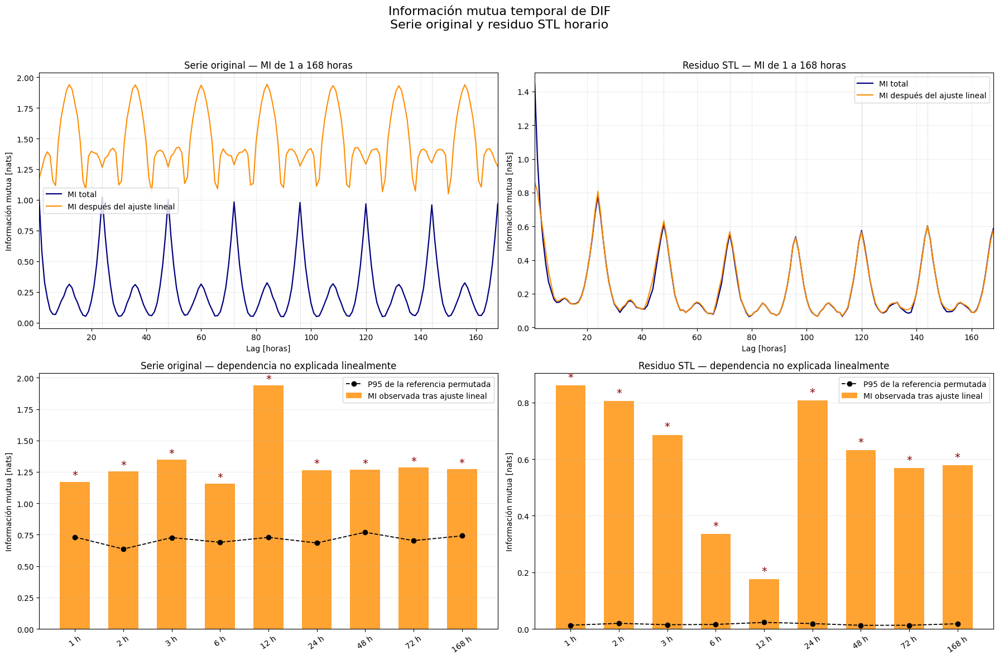

Información mutua en retardos clave:


,serie,lag_horas,numero_parejas,correlacion_Pearson,R2_lineal,MI_total_observada_nats,media_nula_MI_total,p95_nulo_MI_total,pvalor_empirico_MI_total,MI_total_supera_p95_nulo,MI_error_lineal_observada_nats,media_nula_MI_error_lineal,p95_nulo_MI_error_lineal,pvalor_empirico_MI_error_lineal,MI_error_lineal_supera_p95_nulo,exceso_MI_error_sobre_p95_nulo
0,Serie original,1,8135,0.915433,0.838017,1.017049,0.001915,0.009576,0.019608,True,1.171824,0.465265,0.731089,0.019608,True,0.440735
1,Serie original,2,8134,0.785474,0.616970,0.581059,0.002308,0.009676,0.019608,True,1.253935,0.425055,0.635790,0.019608,True,0.618144
2,Serie original,3,8133,0.624575,0.390094,0.327186,0.001965,0.007872,0.019608,True,1.345566,0.465410,0.726755,0.019608,True,0.618811
3,Serie original,6,8130,0.079877,0.006380,0.068186,0.002136,0.009037,0.019608,True,1.155036,0.452670,0.689449,0.019608,True,0.465588
4,Serie original,12,8124,-0.437499,0.191405,0.311915,0.001948,0.006258,0.019608,True,1.938690,0.469443,0.728728,0.019608,True,1.209963
5,Serie original,24,8112,0.827073,0.684049,1.023014,0.002429,0.009840,0.019608,True,1.264637,0.480089,0.683907,0.019608,True,0.580730
6,Serie original,48,8088,0.820826,0.673755,1.002521,0.001843,0.007509,0.019608,True,1.268269,0.502422,0.769362,0.019608,True,0.498907
7,Serie original,72,8064,0.810110,0.656279,0.983790,0.002966,0.009918,0.019608,True,1.285660,0.447919,0.702758,0.019608,True,0.582903
8,Serie original,168,7968,0.813002,0.660973,0.967396,0.003033,0.009312,0.019608,True,1.272385,0.448436,0.740672,0.019608,True,0.531713
9,Residuo STL,1,8135,0.718563,0.516333,1.443500,0.002384,0.010675,0.019608,True,0.860349,0.004122,0.012832,0.019608,True,0.847517



Un asterisco indica que la MI observada después del ajuste lineal supera el percentil 95 de la referencia permutada.

La MI del error lineal puede reflejar curvatura, heterocedasticidad o mezcla de regímenes. No demuestra causalidad.


In [66]:
# 1. Comprobar los resultados
if (
    "tabla_mi_completa_etapa3b_dif" not in globals()
    or "tabla_mi_lags_clave_etapa3b_dif" not in globals()
):
    raise NameError("Ejecuta primero la sección 14.2.")


# 2. Preparar la figura
figura_mi_etapa3b_dif, ejes_mi_etapa3b_dif = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
NOMBRES_SERIES_MI_ETAPA3B_DIF = ["Serie original", "Residuo STL"]


# 3. Dibujar la evolución completa de la MI
for columna_mi, nombre_serie_mi in enumerate(NOMBRES_SERIES_MI_ETAPA3B_DIF):
    eje_completo_mi = ejes_mi_etapa3b_dif[0, columna_mi]
    datos_serie_mi = tabla_mi_completa_etapa3b_dif.loc[
        tabla_mi_completa_etapa3b_dif["serie"] == nombre_serie_mi
    ].sort_values("lag_horas")
    eje_completo_mi.plot(
        datos_serie_mi["lag_horas"],
        datos_serie_mi["MI_total_nats"],
        color="navy",
        linewidth=1.6,
        label="MI total",
    )
    eje_completo_mi.plot(
        datos_serie_mi["lag_horas"],
        datos_serie_mi["MI_error_lineal_nats"],
        color="darkorange",
        linewidth=1.5,
        label="MI después del ajuste lineal",
    )
    for lag_diario_mi in range(24, MAX_LAG_MI_ETAPA3B_DIF + 1, 24):
        eje_completo_mi.axvline(
            lag_diario_mi, color="grey", linestyle=":", linewidth=0.7, alpha=0.6
        )

    eje_completo_mi.set_title(f"{nombre_serie_mi} — MI de 1 a 168 horas")
    eje_completo_mi.set_xlabel("Lag [horas]")
    eje_completo_mi.set_ylabel("Información mutua [nats]")
    eje_completo_mi.set_xlim(1, MAX_LAG_MI_ETAPA3B_DIF)
    eje_completo_mi.grid(alpha=0.22)
    eje_completo_mi.legend()


# 4. Comparar el error lineal con la referencia permutada
for columna_mi, nombre_serie_mi in enumerate(NOMBRES_SERIES_MI_ETAPA3B_DIF):
    eje_claves_mi = ejes_mi_etapa3b_dif[1, columna_mi]
    datos_clave_mi = (
        tabla_mi_lags_clave_etapa3b_dif.loc[
            tabla_mi_lags_clave_etapa3b_dif["serie"] == nombre_serie_mi
        ]
        .sort_values("lag_horas")
        .reset_index(drop=True)
    )
    posiciones_mi = np.arange(len(datos_clave_mi))
    eje_claves_mi.bar(
        posiciones_mi,
        datos_clave_mi["MI_error_lineal_observada_nats"],
        width=0.62,
        color="darkorange",
        alpha=0.80,
        label="MI observada tras ajuste lineal",
    )
    eje_claves_mi.plot(
        posiciones_mi,
        datos_clave_mi["p95_nulo_MI_error_lineal"],
        color="black",
        marker="o",
        linestyle="--",
        linewidth=1.3,
        label="P95 de la referencia permutada",
    )
    for posicion_mi, fila_mi in datos_clave_mi.iterrows():
        if fila_mi["MI_error_lineal_supera_p95_nulo"]:
            eje_claves_mi.text(
                posicion_mi,
                (fila_mi["MI_error_lineal_observada_nats"] + 0.01),
                "*",
                ha="center",
                va="bottom",
                fontsize=14,
                color="darkred",
            )

    eje_claves_mi.set_xticks(posiciones_mi)
    eje_claves_mi.set_xticklabels([f"{lag} h" for lag in datos_clave_mi["lag_horas"]], rotation=35)
    eje_claves_mi.set_title((f"{nombre_serie_mi} — dependencia " "no explicada linealmente"))
    eje_claves_mi.set_ylabel("Información mutua [nats]")
    eje_claves_mi.grid(axis="y", alpha=0.22)
    eje_claves_mi.legend()


# 5. Terminar y guardar la figura
figura_mi_etapa3b_dif.suptitle(
    ("Información mutua temporal de DIF\n" "Serie original y residuo STL horario"), fontsize=16
)
figura_mi_etapa3b_dif.tight_layout(rect=[0, 0, 1, 0.96])
ruta_grafico_mi_etapa3b_dif = (
    directorio_resultados_mi_etapa3b_dif / "informacion_mutua_DIF_original_residuo_STL.png"
)
figura_mi_etapa3b_dif.savefig(ruta_grafico_mi_etapa3b_dif, dpi=220, bbox_inches="tight")
plt.show()
plt.close(figura_mi_etapa3b_dif)


# 6. Mostrar las tablas
print("Información mutua en retardos clave:")

# Visualizar la tabla principal.
display(
    tabla_mi_lags_clave_etapa3b_dif.style.format(
        {
            "correlacion_Pearson": "{:.6f}",
            "R2_lineal": "{:.6f}",
            "MI_total_observada_nats": "{:.6f}",
            "media_nula_MI_total": "{:.6f}",
            "p95_nulo_MI_total": "{:.6f}",
            "pvalor_empirico_MI_total": "{:.6f}",
            "MI_error_lineal_observada_nats": "{:.6f}",
            "media_nula_MI_error_lineal": "{:.6f}",
            "p95_nulo_MI_error_lineal": "{:.6f}",
            "pvalor_empirico_MI_error_lineal": "{:.6f}",
            "exceso_MI_error_sobre_p95_nulo": "{:.6f}",
        }
    )
)
print(
    "\nUn asterisco indica que la MI observada después "
    "del ajuste lineal supera el percentil 95 de la "
    "referencia permutada."
)
print(
    "\nLa MI del error lineal puede reflejar curvatura, "
    "heterocedasticidad o mezcla de regímenes. "
    "No demuestra causalidad."
)

### Interpretación

Con el objetivo de complementar los resultados obtenidos mediante la ACF, la PACF y los diagramas de retardo (A.4), se estimó la información mutua entre la DIF horaria presente y sus valores retrasados entre 1 y 168 horas. A diferencia del coeficiente de Pearson, la información mutua permite detectar cualquier tipo de dependencia estadística, incluyendo relaciones curvadas, no monótonas, heterocedásticas o asociadas a la coexistencia de distintos regímenes. La estimación se realizó mediante un procedimiento basado en los cinco vecinos más próximos y se expresó en nats, unidad correspondiente al uso del logaritmo natural.

Para diferenciar la dependencia total de la estructura no descrita por una relación lineal, se ajustó, para cada retardo, una regresión de la forma $DIF_t=a+bDIF_{t-k}$. Posteriormente se calculó la información mutua entre $DIF_{t-k}$ y el error de dicha regresión. Este segundo valor no constituye una resta de la información mutua total ni puede interpretarse como un porcentaje de información restante. Su función es comprobar si la distribución de los errores continúa dependiendo del valor pasado después de aplicar la mejor recta.

En la serie original se confirmó una dependencia inmediata muy elevada. Para el retardo de una hora se obtuvo un coeficiente de Pearson de 0,915, un $R^2$ de 0,838 y una información mutua total de 1,017 nats. También se identificó un máximo diario en 24 horas, con una información mutua de 1,023 nats, frente a 0,732 nats en 23 horas. Este resultado confirma que la repetición del ciclo diario alcanza su mayor intensidad cuando se comparan horas equivalentes de días consecutivos.

La relación correspondiente a doce horas mostró un comportamiento diferente. Aunque Pearson fue de −0,437 y la información mutua total de 0,312 nats, la información mutua entre el valor retrasado y el error lineal alcanzó su máximo, con 1,939 nats. Este resultado es coherente con la estructura en forma de “L” observada en el diagrama de retardo de doce horas. Dicho retardo relaciona frecuentemente fases solares opuestas, de modo que los valores diurnos se emparejan con valores nocturnos y viceversa. Esta mezcla de regímenes no puede describirse adecuadamente mediante una única recta.

El residuo de la descomposición STL conservó una dependencia inmediata importante. A una hora se obtuvo Pearson = 0,719, $R^2=0{,}516$, una información mutua total de 1,444 nats y una información mutua del error lineal de 0,860 nats. Por tanto, la persistencia residual tiene una componente lineal considerable, aunque existe también estructura adicional en la distribución de los errores.

El resultado más relevante apareció en los retardos diarios del residuo. A 24 horas, Pearson fue únicamente −0,137 y el $R^2$ de 0,019, mientras que la información mutua total alcanzó 0,781 nats. A una semana, Pearson descendió a −0,037 y el $R^2$ a 0,001, pero la información mutua permaneció en 0,587 nats. Esto indica que, después de retirar la tendencia y el perfil estacional medio, sigue existiendo una dependencia temporal que no adopta una forma lineal. Esta dependencia puede estar relacionada con la variación diaria de la dispersión, la heterocedasticidad entre periodos diurnos y nocturnos, la persistencia de regímenes meteorológicos o la repetición de distribuciones residuales características de cada fase solar.

La significación exploratoria se evaluó mediante 50 permutaciones aleatorias. Para cada retardo seleccionado se comparó la información mutua observada con el percentil 95 de la distribución permutada. Los asteriscos de la representación señalan aquellos valores que superaron dicha referencia. Esta comparación no demuestra causalidad ni garantiza utilidad predictiva; únicamente indica que la dependencia observada fue mayor que la obtenida después de destruir artificialmente el orden temporal. Además, al utilizar solo 50 permutaciones, el menor p-valor empírico posible fue 0,0196.

Debe señalarse una limitación específica en el análisis de la serie original. Mientras que la referencia permutada de la información mutua total permaneció próxima a cero, el percentil 95 de la información mutua del error lineal alcanzó valores comprendidos aproximadamente entre 0,64 y 0,77 nats. Este comportamiento puede estar asociado a la elevada concentración de valores nocturnos repetidos y al uso de un estimador continuo basado en vecinos próximos. En consecuencia, los valores absolutos de la información mutua del error lineal de la serie original deben considerarse exploratorios y no como una cuantificación definitiva de la dependencia no lineal.

En conjunto, el análisis demuestra que la DIF horaria presenta una fuerte persistencia inmediata y una repetición diaria clara. También aporta evidencia de dependencias distributivas que no quedan completamente descritas por Pearson ni por una regresión lineal, especialmente en el residuo STL. Estos resultados justifican evaluar, durante la fase predictiva, ventanas de entrada que incluyan tanto las horas inmediatamente anteriores como al menos un ciclo completo de 24 horas. No obstante, la utilidad real de estas dependencias deberá validarse fuera de muestra mediante la comparación de N-BEATS con baselines de persistencia inmediata y persistencia diaria.

## Análisis complementarios

Análisis realizados durante la exploración que no se utilizan en la memoria. Se conservan como contexto de las decisiones del análisis principal.

### A.1 STL robusto

Descomposición STL horaria con `robust=True` y la ventana de tendencia por defecto. Se conserva porque motivó la elección de la descomposición no robusta del análisis principal.

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.seasonal import STL

# 1. Comprobar objetos de la preparación
OBJETOS_REQUERIDOS_STL_DIF = ["df_stl_horario_media", "cobertura_horaria_stl", "COL_DIF_STL"]
objetos_ausentes_stl_dif = [
    nombre for nombre in OBJETOS_REQUERIDOS_STL_DIF if nombre not in globals()
]
if objetos_ausentes_stl_dif:
    raise NameError("Faltan objetos de la preparación horaria: " f"{objetos_ausentes_stl_dif}")


# 2. Preparar la serie horaria
serie_dif_horaria_stl = df_stl_horario_media[COL_DIF_STL].copy().sort_index().asfreq("1h")
serie_dif_horaria_stl.name = "DIF horaria media [W/m²]"
if serie_dif_horaria_stl.index.duplicated().any():
    raise ValueError("La serie horaria contiene timestamps duplicados.")

if not serie_dif_horaria_stl.index.is_monotonic_increasing:
    raise ValueError("La serie horaria no está ordenada.")

if serie_dif_horaria_stl.isna().any():
    fechas_ausentes = serie_dif_horaria_stl[serie_dif_horaria_stl.isna()].index.tolist()
    raise ValueError(
        "La serie contiene horas sin media calculable. " f"Primeras fechas: {fechas_ausentes[:10]}"
    )

if not np.isfinite(serie_dif_horaria_stl.to_numpy(dtype=float)).all():
    raise ValueError("La serie contiene valores no finitos.")


# 3. Configuración inicial
PERIODO_DIARIO_STL = 24
VENTANA_ESTACIONAL_STL = 13
VENTANA_LOW_PASS_STL = 25
modelo_stl_dif = STL(
    endog=serie_dif_horaria_stl,
    period=PERIODO_DIARIO_STL,
    seasonal=VENTANA_ESTACIONAL_STL,
    trend=None,
    low_pass=VENTANA_LOW_PASS_STL,
    seasonal_deg=1,
    trend_deg=1,
    low_pass_deg=1,
    robust=True,
)
resultado_stl_dif = modelo_stl_dif.fit()


# 4. Guardar componentes
componentes_stl_dif = pd.DataFrame(
    {
        "DIF_observada": (serie_dif_horaria_stl),
        "tendencia": (resultado_stl_dif.trend),
        "estacional": (resultado_stl_dif.seasonal),
        "residuo": (resultado_stl_dif.resid),
        "peso_robusto": pd.Series(resultado_stl_dif.weights, index=serie_dif_horaria_stl.index),
    }
)
componentes_stl_dif["minutos_validos"] = cobertura_horaria_stl["n_validos_familia_DIF"].reindex(
    componentes_stl_dif.index
)


# 5. Comprobar reconstrucción
reconstruccion_stl_dif = (
    componentes_stl_dif["tendencia"]
    + componentes_stl_dif["estacional"]
    + componentes_stl_dif["residuo"]
)
error_reconstruccion_stl_dif = componentes_stl_dif["DIF_observada"] - reconstruccion_stl_dif
max_error_reconstruccion = float(error_reconstruccion_stl_dif.abs().max())
control_reconstruccion_stl_dif = bool(
    np.allclose(componentes_stl_dif["DIF_observada"], reconstruccion_stl_dif, rtol=1e-10, atol=1e-8)
)


# 6. Configuración realmente utilizada
configuracion_stl_dif = pd.DataFrame(
    {"parámetro": list(modelo_stl_dif.config.keys()), "valor": list(modelo_stl_dif.config.values())}
)
print("Configuración utilizada por STL:")
display(configuracion_stl_dif)


# 7. Resumen de ejecución
resumen_ejecucion_stl_dif = pd.DataFrame(
    {
        "comprobación": [
            "Primera hora",
            "Última hora",
            "Número de observaciones",
            "Valores ausentes",
            "Periodo diario",
            "Ventana estacional",
            "Ventana low-pass",
            "Configuración robusta",
            "Reconstrucción correcta",
            "Error máximo de reconstrucción",
            "Horas con peso robusto menor que 1",
            "Horas con peso robusto menor que 0,5",
            "Horas con menos de 60 minutos válidos",
            "Mínimo de minutos válidos",
        ],
        "resultado": [
            serie_dif_horaria_stl.index.min(),
            serie_dif_horaria_stl.index.max(),
            len(serie_dif_horaria_stl),
            int(serie_dif_horaria_stl.isna().sum()),
            PERIODO_DIARIO_STL,
            VENTANA_ESTACIONAL_STL,
            VENTANA_LOW_PASS_STL,
            True,
            control_reconstruccion_stl_dif,
            max_error_reconstruccion,
            int((componentes_stl_dif["peso_robusto"] < 1).sum()),
            int((componentes_stl_dif["peso_robusto"] < 0.5).sum()),
            int((componentes_stl_dif["minutos_validos"] < 60).sum()),
            int(componentes_stl_dif["minutos_validos"].min()),
        ],
    }
)
print("Resumen de la ejecución:")
display(resumen_ejecucion_stl_dif)


# 8. Estadísticos de los componentes
resumen_componentes_stl_dif = (
    componentes_stl_dif[["DIF_observada", "tendencia", "estacional", "residuo"]]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)
print("Resumen estadístico de los componentes:")
display(resumen_componentes_stl_dif.style.format(precision=4))
print("\nNo se ha modificado ni interpolado " "la serie horaria original.")

Configuración utilizada por STL:


,parámetro,valor
0,period,24
1,seasonal,13
2,seasonal_deg,1
3,seasonal_jump,1
4,trend,41
5,trend_deg,1
6,trend_jump,1
7,low_pass,25
8,low_pass_deg,1
9,low_pass_jump,1


Resumen de la ejecución:


,comprobación,resultado
0,Primera hora,2023-12-28 00:00:00
1,Última hora,2024-11-30 23:00:00
2,Número de observaciones,8136
3,Valores ausentes,0
4,Periodo diario,24
5,Ventana estacional,13
6,Ventana low-pass,25
7,Configuración robusta,True
8,Reconstrucción correcta,True
9,Error máximo de reconstrucción,0.0


Resumen estadístico de los componentes:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
DIF_observada,8136.0000,72.4374,104.9619,-3.2167,-1.3275,-1.0000,-1.0000,9.1250,118.6292,305.3542,410.8983,555.1500
tendencia,8136.0000,71.5032,37.5407,11.0635,11.3689,19.0532,34.1234,75.9256,105.7344,125.3547,137.3705,138.9387
estacional,8136.0000,-0.0004,87.4315,-139.1304,-130.0444,-114.0288,-66.6769,-22.7956,64.3776,162.8226,215.5286,285.1977
residuo,8136.0000,0.9347,43.8179,-246.5392,-141.7139,-68.2920,-0.6993,-0.0183,0.6565,77.0166,153.9633,284.2940



No se ha modificado ni interpolado la serie horaria original.


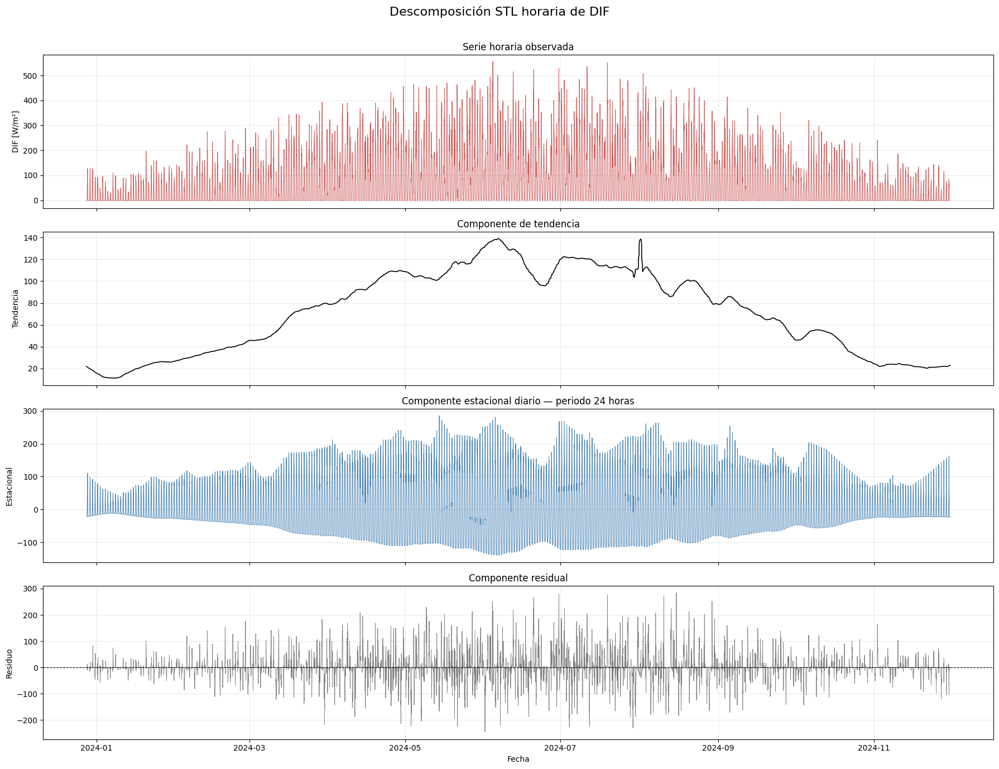

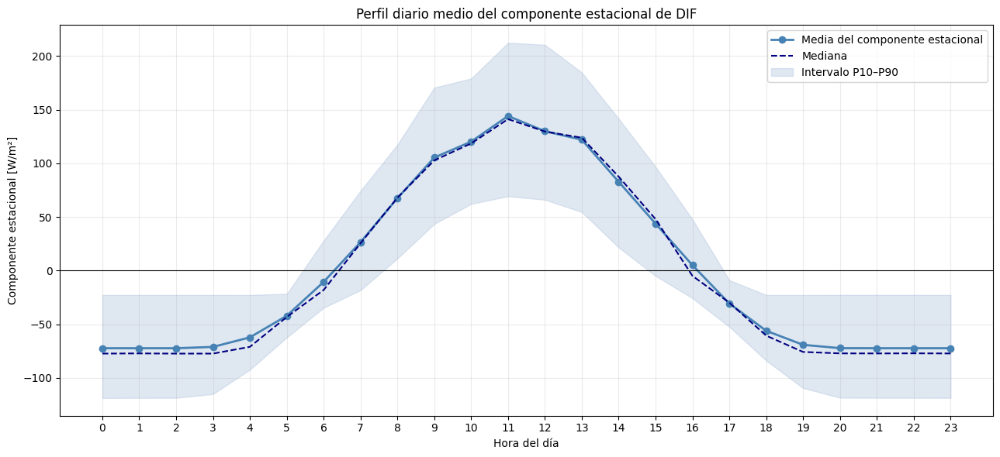

Perfil horario del componente estacional:


,hora,media,mediana,p10,p90
0,0,-72.302,-77.297,-118.673,-22.709
1,1,-72.312,-77.134,-118.635,-22.669
2,2,-72.303,-77.320,-118.592,-22.681
3,3,-71.078,-77.305,-115.002,-22.697
4,4,-62.186,-71.012,-92.332,-22.711
5,5,-42.049,-43.197,-62.287,-21.631
6,6,-10.492,-18.021,-34.641,27.976
7,7,26.548,25.511,-18.178,74.446
8,8,67.526,68.009,11.343,117.422
9,9,105.415,102.779,43.505,170.623


In [68]:
# 1. Descomposición completa
fig, ejes = plt.subplots(nrows=4, ncols=1, figsize=(18, 14), sharex=True)
ejes[0].plot(
    componentes_stl_dif.index,
    componentes_stl_dif["DIF_observada"],
    color="indianred",
    linewidth=0.7,
)
ejes[0].set_ylabel("DIF [W/m²]")
ejes[0].set_title("Serie horaria observada")
ejes[0].grid(alpha=0.25)
ejes[1].plot(
    componentes_stl_dif.index, componentes_stl_dif["tendencia"], color="black", linewidth=1.2
)
ejes[1].set_ylabel("Tendencia")
ejes[1].set_title("Componente de tendencia")
ejes[1].grid(alpha=0.25)
ejes[2].plot(
    componentes_stl_dif.index, componentes_stl_dif["estacional"], color="steelblue", linewidth=0.7
)
ejes[2].set_ylabel("Estacional")
ejes[2].set_title("Componente estacional diario — periodo 24 horas")
ejes[2].grid(alpha=0.25)
ejes[3].plot(componentes_stl_dif.index, componentes_stl_dif["residuo"], color="grey", linewidth=0.6)
ejes[3].axhline(0, color="black", linestyle="--", linewidth=0.8)
ejes[3].set_ylabel("Residuo")
ejes[3].set_xlabel("Fecha")
ejes[3].set_title("Componente residual")
ejes[3].grid(alpha=0.25)
fig.suptitle("Descomposición STL horaria de DIF", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


# 2. Perfil estacional medio según la hora
tabla_perfil_stl_dif = (
    componentes_stl_dif[["estacional"]]
    .assign(hora=lambda tabla: tabla.index.hour)
    .groupby("hora", sort=True)["estacional"]
    .agg(
        media="mean",
        mediana="median",
        p10=lambda serie: serie.quantile(0.10),
        p90=lambda serie: serie.quantile(0.90),
    )
    .reset_index()
)
fig, eje = plt.subplots(figsize=(13, 6))
eje.plot(
    tabla_perfil_stl_dif["hora"],
    tabla_perfil_stl_dif["media"],
    color="steelblue",
    marker="o",
    linewidth=2,
    label="Media del componente estacional",
)
eje.plot(
    tabla_perfil_stl_dif["hora"],
    tabla_perfil_stl_dif["mediana"],
    color="navy",
    linestyle="--",
    linewidth=1.5,
    label="Mediana",
)
eje.fill_between(
    tabla_perfil_stl_dif["hora"],
    tabla_perfil_stl_dif["p10"],
    tabla_perfil_stl_dif["p90"],
    color="lightsteelblue",
    alpha=0.4,
    label="Intervalo P10–P90",
)
eje.axhline(0, color="black", linewidth=0.8)
eje.set_xticks(np.arange(0, 24, 1))
eje.set_xlabel("Hora del día")
eje.set_ylabel("Componente estacional [W/m²]")
eje.set_title("Perfil diario medio del componente estacional de DIF")
eje.grid(alpha=0.25)
eje.legend()
plt.tight_layout()
plt.show()
print("Perfil horario del componente estacional:")
display(
    tabla_perfil_stl_dif.style.format(
        {"media": "{:.3f}", "mediana": "{:.3f}", "p10": "{:.3f}", "p90": "{:.3f}"}
    )
)

DIF presenta una estructura intradiaria muy marcada cuyo contraste aumenta durante primavera y verano. El nivel suavizado también evoluciona a lo largo del año, pero contiene tanto la modulación solar de baja frecuencia como variabilidad meteorológica de varios días. El residuo está centrado cerca de cero, aunque presenta colas amplias y una variabilidad mucho mayor durante las horas diurnas, por lo que no puede interpretarse como ruido blanco homogéneo.

#### Pesos robustos por hora y presencia de radiación

Distribución global de los pesos robustos:


,criterio,n_horas,porcentaje
0,Peso aproximadamente igual a 1,54,0.66 %
1,"Peso menor que 0,99",5249,64.52 %
2,"Peso menor que 0,90",3794,46.63 %
3,"Peso menor que 0,50",3371,41.43 %
4,"Peso menor que 0,10",3263,40.11 %
5,Peso aproximadamente igual a 0,3222,39.60 %


Estadísticos globales de los pesos:


,estadístico,peso_robusto
0,Mínimo,0.000000
1,P10,0.000000
2,P25,0.000000
3,Mediana,0.945216
4,Media,0.570772
5,P75,0.996643
6,P90,0.999542
7,Máximo,1.000000


Diagnóstico de pesos por hora del día:


,hora,n_horas,peso_medio,peso_mediano,peso_p10,peso_p90,residuo_abs_mediano,residuo_abs_p95,DIF_observada_mediana,porcentaje_peso_menor_0_50,porcentaje_peso_menor_0_10,porcentaje_peso_cero
0,0,339,0.9816,0.9972,0.9731,0.9999,0.153,0.666,-1.000,0.88 %,0.88 %,0.88 %
1,1,339,0.9808,0.9972,0.9640,0.9999,0.150,0.711,-1.000,0.88 %,0.88 %,0.88 %
2,2,339,0.9791,0.9961,0.9652,0.9998,0.177,0.670,-1.000,0.88 %,0.88 %,0.88 %
3,3,339,0.9274,0.9952,0.8507,0.9999,0.196,2.460,-0.933,5.31 %,3.24 %,2.95 %
4,4,339,0.7435,0.9891,0.0000,0.9996,0.302,15.699,-0.217,23.89 %,22.12 %,20.65 %
5,5,339,0.5674,0.9081,0.0000,0.9995,0.846,37.706,8.967,41.00 %,39.23 %,37.76 %
6,6,339,0.4452,0.1030,0.0000,0.9981,3.469,75.454,48.317,52.80 %,49.85 %,48.67 %
7,7,339,0.2729,0.0000,0.0000,0.9773,14.511,107.716,89.500,70.21 %,67.55 %,66.08 %
8,8,339,0.1882,0.0000,0.0000,0.9510,25.637,134.442,126.167,79.65 %,78.17 %,78.17 %
9,9,339,0.1797,0.0000,0.0000,0.9559,36.819,151.685,158.237,80.53 %,79.94 %,79.65 %


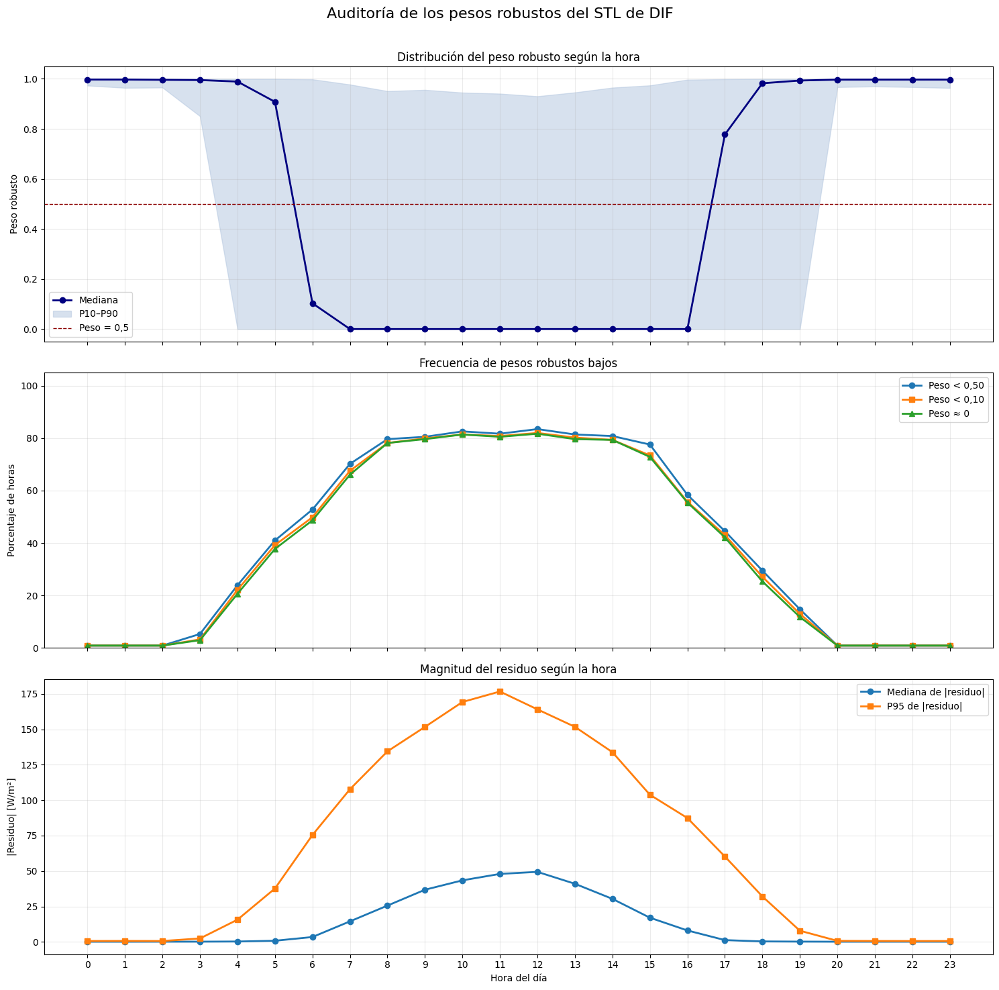


Pesos robustos según la proxy SWD > 10:


,grupo_presencia_radiacion,n_horas,peso_medio,peso_mediano,residuo_abs_mediano,residuo_abs_p95,DIF_observada_mediana,proporcion_SWD_mediana,porcentaje_peso_menor_0_50,porcentaje_peso_menor_0_10
0,0 % de minutos con SWD > 10,3807,0.9642,0.9965,0.168,0.826,-1.000,0.00%,2.31 %,2.05 %
1,Entre 0 % y 50 % con SWD > 10,359,0.5530,0.7669,1.465,27.979,6.733,26.67%,40.39 %,35.10 %
2,Al menos 50 % de minutos con SWD > 10,3970,0.1951,0.0000,25.338,141.309,122.275,100.00%,79.04 %,77.05 %



No se ha modificado la descomposición STL ni ninguna variable original.


In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Comprobar objetos necesarios
if "componentes_stl_dif" not in globals():
    raise NameError(
        "No existe 'componentes_stl_dif'. " "Ejecuta primero la descomposición STL de DIF."
    )

COLUMNAS_REQUERIDAS_PESOS = ["DIF_observada", "residuo", "peso_robusto"]
columnas_ausentes_pesos = [
    columna for columna in COLUMNAS_REQUERIDAS_PESOS if columna not in componentes_stl_dif.columns
]
if columnas_ausentes_pesos:
    raise KeyError("Faltan columnas en 'componentes_stl_dif': " f"{columnas_ausentes_pesos}")


# 2. Preparar tabla de diagnóstico
diagnostico_pesos_stl_dif = componentes_stl_dif[COLUMNAS_REQUERIDAS_PESOS].copy().sort_index()
if not isinstance(diagnostico_pesos_stl_dif.index, pd.DatetimeIndex):
    raise TypeError("El índice de componentes_stl_dif " "debe ser un DatetimeIndex.")

if diagnostico_pesos_stl_dif.isna().any().any():
    raise ValueError("Hay valores ausentes en las columnas " "necesarias para el diagnóstico.")

if not np.isfinite(diagnostico_pesos_stl_dif.to_numpy(dtype=float)).all():
    raise ValueError("Hay valores no finitos en el diagnóstico.")

TOLERANCIA_PESO_CERO = 1e-12
TOLERANCIA_PESO_UNO = 1e-12
pesos = diagnostico_pesos_stl_dif["peso_robusto"]
if ((pesos < -TOLERANCIA_PESO_CERO) | (pesos > 1 + TOLERANCIA_PESO_UNO)).any():
    raise ValueError("Se han encontrado pesos robustos fuera de [0, 1].")

diagnostico_pesos_stl_dif["hora"] = diagnostico_pesos_stl_dif.index.hour
diagnostico_pesos_stl_dif["mes"] = diagnostico_pesos_stl_dif.index.month
diagnostico_pesos_stl_dif["residuo_absoluto"] = diagnostico_pesos_stl_dif["residuo"].abs()


# 3. Resumen global de los pesos
# No usaremos simplemente peso < 1 porque cualquier diferencia
# numérica diminuta respecto a 1 entraría en ese recuento.
criterios_pesos = {
    "Peso aproximadamente igual a 1": np.isclose(pesos, 1.0, rtol=0, atol=TOLERANCIA_PESO_UNO),
    "Peso menor que 0,99": pesos < 0.99,
    "Peso menor que 0,90": pesos < 0.90,
    "Peso menor que 0,50": pesos < 0.50,
    "Peso menor que 0,10": pesos < 0.10,
    "Peso aproximadamente igual a 0": np.isclose(pesos, 0.0, rtol=0, atol=TOLERANCIA_PESO_CERO),
}
resumen_global_pesos_stl_dif = pd.DataFrame(
    {
        "criterio": list(criterios_pesos.keys()),
        "n_horas": [int(mascara.sum()) for mascara in criterios_pesos.values()],
        "porcentaje": [float(mascara.mean() * 100) for mascara in criterios_pesos.values()],
    }
)
estadisticos_globales_pesos = pd.DataFrame(
    {
        "estadístico": ["Mínimo", "P10", "P25", "Mediana", "Media", "P75", "P90", "Máximo"],
        "peso_robusto": [
            pesos.min(),
            pesos.quantile(0.10),
            pesos.quantile(0.25),
            pesos.median(),
            pesos.mean(),
            pesos.quantile(0.75),
            pesos.quantile(0.90),
            pesos.max(),
        ],
    }
)
print("Distribución global de los pesos robustos:")
display(resumen_global_pesos_stl_dif.style.format({"porcentaje": "{:.2f} %"}))
print("Estadísticos globales de los pesos:")
display(estadisticos_globales_pesos.style.format({"peso_robusto": "{:.6f}"}))


# 4. Resumen por hora del día
grupo_hora_pesos = diagnostico_pesos_stl_dif.groupby("hora", sort=True)
tabla_pesos_por_hora_stl_dif = grupo_hora_pesos.agg(
    n_horas=("peso_robusto", "size"),
    peso_medio=("peso_robusto", "mean"),
    peso_mediano=("peso_robusto", "median"),
    peso_p10=("peso_robusto", lambda serie: serie.quantile(0.10)),
    peso_p90=("peso_robusto", lambda serie: serie.quantile(0.90)),
    residuo_abs_mediano=("residuo_absoluto", "median"),
    residuo_abs_p95=("residuo_absoluto", lambda serie: serie.quantile(0.95)),
    DIF_observada_mediana=("DIF_observada", "median"),
)
tabla_pesos_por_hora_stl_dif["porcentaje_peso_menor_0_50"] = grupo_hora_pesos["peso_robusto"].apply(
    lambda serie: 100 * serie.lt(0.50).mean()
)
tabla_pesos_por_hora_stl_dif["porcentaje_peso_menor_0_10"] = grupo_hora_pesos["peso_robusto"].apply(
    lambda serie: 100 * serie.lt(0.10).mean()
)
tabla_pesos_por_hora_stl_dif["porcentaje_peso_cero"] = grupo_hora_pesos["peso_robusto"].apply(
    lambda serie: 100 * np.isclose(serie, 0.0, rtol=0, atol=TOLERANCIA_PESO_CERO).mean()
)
tabla_pesos_por_hora_stl_dif = tabla_pesos_por_hora_stl_dif.reset_index()
print("Diagnóstico de pesos por hora del día:")
display(
    tabla_pesos_por_hora_stl_dif.style.format(
        {
            "peso_medio": "{:.4f}",
            "peso_mediano": "{:.4f}",
            "peso_p10": "{:.4f}",
            "peso_p90": "{:.4f}",
            "residuo_abs_mediano": "{:.3f}",
            "residuo_abs_p95": "{:.3f}",
            "DIF_observada_mediana": "{:.3f}",
            "porcentaje_peso_menor_0_50": "{:.2f} %",
            "porcentaje_peso_menor_0_10": "{:.2f} %",
            "porcentaje_peso_cero": "{:.2f} %",
        }
    )
)


# 5. Gráficos por hora
horas = tabla_pesos_por_hora_stl_dif["hora"].to_numpy()
fig, ejes = plt.subplots(nrows=3, ncols=1, figsize=(15, 15), sharex=True)


# Panel 1: nivel de los pesos
ejes[0].plot(
    horas,
    tabla_pesos_por_hora_stl_dif["peso_mediano"].to_numpy(),
    marker="o",
    linewidth=2,
    color="navy",
    label="Mediana",
)
ejes[0].fill_between(
    horas,
    tabla_pesos_por_hora_stl_dif["peso_p10"].to_numpy(),
    tabla_pesos_por_hora_stl_dif["peso_p90"].to_numpy(),
    color="lightsteelblue",
    alpha=0.5,
    label="P10–P90",
)
ejes[0].axhline(0.5, color="darkred", linestyle="--", linewidth=1, label="Peso = 0,5")
ejes[0].set_ylabel("Peso robusto")
ejes[0].set_title("Distribución del peso robusto según la hora")
ejes[0].set_ylim(-0.05, 1.05)
ejes[0].grid(alpha=0.25)
ejes[0].legend()


# Panel 2: proporción de pesos bajos
ejes[1].plot(
    horas,
    tabla_pesos_por_hora_stl_dif["porcentaje_peso_menor_0_50"].to_numpy(),
    marker="o",
    linewidth=2,
    label="Peso < 0,50",
)
ejes[1].plot(
    horas,
    tabla_pesos_por_hora_stl_dif["porcentaje_peso_menor_0_10"].to_numpy(),
    marker="s",
    linewidth=2,
    label="Peso < 0,10",
)
ejes[1].plot(
    horas,
    tabla_pesos_por_hora_stl_dif["porcentaje_peso_cero"].to_numpy(),
    marker="^",
    linewidth=2,
    label="Peso ≈ 0",
)
ejes[1].set_ylabel("Porcentaje de horas")
ejes[1].set_title("Frecuencia de pesos robustos bajos")
ejes[1].set_ylim(0, 105)
ejes[1].grid(alpha=0.25)
ejes[1].legend()


# Panel 3: magnitud del residuo
ejes[2].plot(
    horas,
    tabla_pesos_por_hora_stl_dif["residuo_abs_mediano"].to_numpy(),
    marker="o",
    linewidth=2,
    label="Mediana de |residuo|",
)
ejes[2].plot(
    horas,
    tabla_pesos_por_hora_stl_dif["residuo_abs_p95"].to_numpy(),
    marker="s",
    linewidth=2,
    label="P95 de |residuo|",
)
ejes[2].set_xlabel("Hora del día")
ejes[2].set_ylabel("|Residuo| [W/m²]")
ejes[2].set_title("Magnitud del residuo según la hora")
ejes[2].set_xticks(np.arange(0, 24, 1))
ejes[2].grid(alpha=0.25)
ejes[2].legend()
fig.suptitle("Auditoría de los pesos robustos del STL de DIF", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


# 6. Comprobación opcional mediante SWD > 10
# Se utiliza exclusivamente como proxy provisional de
# presencia de radiación, no como definición física definitiva
# de día y noche.
COL_SWD_DIAGNOSTICO = "SWD [W/m**2]"
objetos_swd_disponibles = (
    "df_t2" in globals() and "COL_FECHA" in globals() and COL_SWD_DIAGNOSTICO in df_t2.columns
)
if objetos_swd_disponibles:
    df_swd_diagnostico = df_t2[[COL_FECHA, COL_SWD_DIAGNOSTICO]].copy()
    df_swd_diagnostico[COL_FECHA] = pd.to_datetime(df_swd_diagnostico[COL_FECHA], errors="coerce")
    if df_swd_diagnostico[COL_FECHA].isna().any():
        raise ValueError("Se han detectado fechas no válidas " "al preparar SWD.")

    df_swd_diagnostico[COL_SWD_DIAGNOSTICO] = pd.to_numeric(
        df_swd_diagnostico[COL_SWD_DIAGNOSTICO], errors="coerce"
    )
    df_swd_diagnostico = (
        df_swd_diagnostico.sort_values(COL_FECHA)
        .set_index(COL_FECHA)
        .loc[diagnostico_pesos_stl_dif.index.min() : diagnostico_pesos_stl_dif.index.max()]
    )
    serie_swd_minuto = df_swd_diagnostico[COL_SWD_DIAGNOSTICO]

    def proporcion_swd_superior_10(serie):
        validos = serie.dropna()
        if len(validos) == 0:
            return np.nan

        return float(validos.gt(10).mean())

    swd_horaria_diagnostico = pd.DataFrame(
        {
            "SWD_media_horaria": (serie_swd_minuto.resample("1h").mean()),
            "n_SWD_validos": (serie_swd_minuto.resample("1h").count()),
            "proporcion_minutos_SWD_superior_10": (
                serie_swd_minuto.resample("1h").apply(proporcion_swd_superior_10)
            ),
        }
    )
    diagnostico_pesos_stl_dif = diagnostico_pesos_stl_dif.join(swd_horaria_diagnostico, how="left")
    proporcion_swd = diagnostico_pesos_stl_dif["proporcion_minutos_SWD_superior_10"]
    diagnostico_pesos_stl_dif["grupo_presencia_radiacion"] = np.select(
        [
            proporcion_swd.isna(),
            proporcion_swd.eq(0),
            proporcion_swd.gt(0) & proporcion_swd.lt(0.50),
        ],
        ["SWD no evaluable", "0 % de minutos con SWD > 10", "Entre 0 % y 50 % con SWD > 10"],
        default=("Al menos 50 % de minutos con SWD > 10"),
    )
    orden_grupos_swd = [
        "0 % de minutos con SWD > 10",
        "Entre 0 % y 50 % con SWD > 10",
        "Al menos 50 % de minutos con SWD > 10",
        "SWD no evaluable",
    ]
    diagnostico_pesos_stl_dif["grupo_presencia_radiacion"] = pd.Categorical(
        diagnostico_pesos_stl_dif["grupo_presencia_radiacion"],
        categories=orden_grupos_swd,
        ordered=True,
    )
    grupo_swd_pesos = diagnostico_pesos_stl_dif.groupby(
        "grupo_presencia_radiacion", observed=True, sort=True
    )
    tabla_pesos_segun_swd_stl_dif = grupo_swd_pesos.agg(
        n_horas=("peso_robusto", "size"),
        peso_medio=("peso_robusto", "mean"),
        peso_mediano=("peso_robusto", "median"),
        residuo_abs_mediano=("residuo_absoluto", "median"),
        residuo_abs_p95=("residuo_absoluto", lambda serie: serie.quantile(0.95)),
        DIF_observada_mediana=("DIF_observada", "median"),
        proporcion_SWD_mediana=("proporcion_minutos_SWD_superior_10", "median"),
    )
    tabla_pesos_segun_swd_stl_dif["porcentaje_peso_menor_0_50"] = grupo_swd_pesos[
        "peso_robusto"
    ].apply(lambda serie: 100 * serie.lt(0.50).mean())
    tabla_pesos_segun_swd_stl_dif["porcentaje_peso_menor_0_10"] = grupo_swd_pesos[
        "peso_robusto"
    ].apply(lambda serie: 100 * serie.lt(0.10).mean())
    tabla_pesos_segun_swd_stl_dif = tabla_pesos_segun_swd_stl_dif.reset_index()
    print("\nPesos robustos según la proxy SWD > 10:")
    display(
        tabla_pesos_segun_swd_stl_dif.style.format(
            {
                "peso_medio": "{:.4f}",
                "peso_mediano": "{:.4f}",
                "residuo_abs_mediano": "{:.3f}",
                "residuo_abs_p95": "{:.3f}",
                "DIF_observada_mediana": "{:.3f}",
                "proporcion_SWD_mediana": "{:.2%}",
                "porcentaje_peso_menor_0_50": "{:.2f} %",
                "porcentaje_peso_menor_0_10": "{:.2f} %",
            }
        )
    )

else:
    print(
        "\nNo se ejecutó el contraste con SWD porque "
        "df_t2, COL_FECHA o la columna SWD no están "
        "disponibles. El análisis por hora sí está completo."
    )

print("\nNo se ha modificado la descomposición STL " "ni ninguna variable original.")

**Conclusión.** El ajuste robusto asigna sistemáticamente pesos muy bajos a las horas con radiación: el 79,04 % de las horas con presencia mayoritaria de SWD > 10 tiene un peso inferior a 0,5, frente al 2,31 % de las horas sin radiación. El procedimiento confunde parte de la variabilidad diurna normal con observaciones extremas, por la fuerte diferencia de variabilidad entre el día y la noche.

La descomposición sigue siendo exacta, pero con `robust=True` las horas diurnas apenas influyen en la tendencia y la estacionalidad, la variabilidad diurna normal se desplaza al residuo y los pesos robustos no sirven como indicador de anomalías. Por eso el análisis principal usa `robust=False`.

### A.2 ACF de la serie minutal

Se estudia durante cuántos minutos la DIF sigue relacionada linealmente con sus valores anteriores, primero hasta 180 minutos y después con ventanas de dos y siete días.

In [70]:
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Indicar el nombre del dataframe minutal


# Escribir entre comillas el nombre del dataframe minutal
# que ya está cargado en la memoria del notebook.
NOMBRE_DF_MINUTAL_ACF_DIF = "df_fuente"
COLUMNA_FECHA_ACF_DIF = "Date/Time"
COLUMNA_DIF_ACF_DIF = "DIF [W/m**2]"


# 2. Comprobar que el dataframe existe


# Comprobar si el nombre escrito corresponde a un objeto
# que existe actualmente en la memoria del notebook.
if NOMBRE_DF_MINUTAL_ACF_DIF not in globals():

    # Detener la ejecución si el dataframe no existe.
    raise NameError(
        "No existe ningún objeto llamado "
        f"'{NOMBRE_DF_MINUTAL_ACF_DIF}'. "
        "Debes escribir el nombre del dataframe minutal."
    )

df_origen_acf_minutal_dif = globals()[NOMBRE_DF_MINUTAL_ACF_DIF]
if not isinstance(df_origen_acf_minutal_dif, pd.DataFrame):

    # Detener la ejecución si el objeto no es un dataframe.
    raise TypeError(f"'{NOMBRE_DF_MINUTAL_ACF_DIF}' " "no es un DataFrame de pandas.")


# Crear una copia para no modificar el dataframe original.
df_preparacion_acf_minutal_dif = df_origen_acf_minutal_dif.copy()


# 3. Preparar el índice temporal
if COLUMNA_FECHA_ACF_DIF in df_preparacion_acf_minutal_dif.columns:
    df_preparacion_acf_minutal_dif[COLUMNA_FECHA_ACF_DIF] = pd.to_datetime(
        df_preparacion_acf_minutal_dif[COLUMNA_FECHA_ACF_DIF], errors="raise"
    )
    df_preparacion_acf_minutal_dif = df_preparacion_acf_minutal_dif.set_index(COLUMNA_FECHA_ACF_DIF)

elif isinstance(df_preparacion_acf_minutal_dif.index, pd.DatetimeIndex):
    df_preparacion_acf_minutal_dif.index = pd.DatetimeIndex(df_preparacion_acf_minutal_dif.index)


# Ejecutar este bloque si no se encuentra información temporal.
else:

    # Detener la ejecución porque una ACF necesita
    # conocer el orden temporal real de las observaciones.
    raise ValueError("No se encuentra Date/Time ni existe " "un DatetimeIndex en el dataframe.")

df_preparacion_acf_minutal_dif = df_preparacion_acf_minutal_dif.sort_index()


# 4. Comprobar duplicados
n_duplicados_acf_minutal_dif = int(df_preparacion_acf_minutal_dif.index.duplicated().sum())
if n_duplicados_acf_minutal_dif > 0:
    raise ValueError(
        "La serie contiene " f"{n_duplicados_acf_minutal_dif} " "timestamps duplicados."
    )


# 5. Comprobar la columna DIF
if COLUMNA_DIF_ACF_DIF not in df_preparacion_acf_minutal_dif.columns:

    # Detener la ejecución si no se encuentra la columna.
    raise KeyError("No se encuentra la columna " f"'{COLUMNA_DIF_ACF_DIF}'.")

if not pd.api.types.is_numeric_dtype(df_preparacion_acf_minutal_dif[COLUMNA_DIF_ACF_DIF]):

    # Detener la ejecución si DIF no es numérica.
    raise TypeError(f"'{COLUMNA_DIF_ACF_DIF}' " "no contiene datos numéricos.")


# Extraer únicamente la variable DIF.
serie_observada_acf_minutal_dif = (
    df_preparacion_acf_minutal_dif[COLUMNA_DIF_ACF_DIF].copy().astype(float)
)
serie_observada_acf_minutal_dif.name = "DIF minutal observada [W/m²]"


# 6. Comprobar la separación real entre timestamps


# Calcular el tiempo transcurrido entre cada fila
# y la fila inmediatamente anterior.
diferencias_temporales_acf_minutal_dif = serie_observada_acf_minutal_dif.index.to_series().diff()
n_intervalos_1min_acf_dif = int(
    (diferencias_temporales_acf_minutal_dif == pd.Timedelta(minutes=1)).sum()
)
n_saltos_mayores_1min_acf_dif = int(
    (diferencias_temporales_acf_minutal_dif > pd.Timedelta(minutes=1)).sum()
)
frecuencia_modal_acf_minutal_dif = diferencias_temporales_acf_minutal_dif.dropna().mode().iloc[0]


# 7. Construir una cuadrícula minutal regular


# Crear todas las marcas temporales que deberían existir
# entre la primera y la última fecha, minuto a minuto.
indice_regular_acf_minutal_dif = pd.date_range(
    start=serie_observada_acf_minutal_dif.index.min(),
    end=serie_observada_acf_minutal_dif.index.max(),
    freq="1min",
)


# Reindexar la serie utilizando la cuadrícula minutal completa.
# Los minutos ausentes aparecerán como NaN.
# No se interpola ni se inventa ningún valor.
serie_regular_acf_minutal_dif = serie_observada_acf_minutal_dif.reindex(
    indice_regular_acf_minutal_dif
)
serie_regular_acf_minutal_dif.name = "DIF minutal regular [W/m²]"


# 8. Comprobar valores válidos y ausentes
n_minutos_totales_acf_dif = int(len(serie_regular_acf_minutal_dif))
n_minutos_validos_acf_dif = int(serie_regular_acf_minutal_dif.notna().sum())
n_minutos_ausentes_acf_dif = int(serie_regular_acf_minutal_dif.isna().sum())
porcentaje_ausentes_acf_dif = 100 * n_minutos_ausentes_acf_dif / n_minutos_totales_acf_dif


# Extraer únicamente los valores no ausentes.
valores_validos_acf_minutal_dif = serie_regular_acf_minutal_dif.dropna()
if not np.isfinite(valores_validos_acf_minutal_dif.to_numpy()).all():
    raise ValueError("La serie DIF contiene valores no finitos.")


# 9. Crear el resumen de comprobación
resumen_preparacion_acf_minutal_dif = pd.DataFrame(
    {
        "comprobación": [
            "Dataframe utilizado",
            "Primera observación",
            "Última observación",
            "Frecuencia temporal más frecuente",
            "Intervalos exactamente de 1 minuto",
            "Saltos superiores a 1 minuto",
            "Minutos de la cuadrícula completa",
            "Minutos con DIF válida",
            "Minutos ausentes",
            "Porcentaje de minutos ausentes",
            "Se ha interpolado",
            "Se ha calculado una media",
        ],
        "resultado": [
            NOMBRE_DF_MINUTAL_ACF_DIF,
            serie_regular_acf_minutal_dif.index.min(),
            serie_regular_acf_minutal_dif.index.max(),
            frecuencia_modal_acf_minutal_dif,
            n_intervalos_1min_acf_dif,
            n_saltos_mayores_1min_acf_dif,
            n_minutos_totales_acf_dif,
            n_minutos_validos_acf_dif,
            n_minutos_ausentes_acf_dif,
            porcentaje_ausentes_acf_dif,
            False,
            False,
        ],
    }
)
print("Comprobación de la serie minutal para la ACF:")
display(resumen_preparacion_acf_minutal_dif)
print("\nLa serie conserva resolución minutal.")


# Aclarar que reindexar no significa interpolar.
print("Los minutos ausentes se conservan como NaN.")


# Aclarar que no se ha realizado ninguna agregación.
print("No se ha calculado ninguna media horaria.")

Comprobación de la serie minutal para la ACF:


,comprobación,resultado
0,Dataframe utilizado,df_fuente
1,Primera observación,2023-11-01 00:00:00
2,Última observación,2024-11-30 23:59:00
3,Frecuencia temporal más frecuente,0 days 00:01:00
4,Intervalos exactamente de 1 minuto,570239
5,Saltos superiores a 1 minuto,0
6,Minutos de la cuadrícula completa,570240
7,Minutos con DIF válida,558635
8,Minutos ausentes,11605
9,Porcentaje de minutos ausentes,2.035108



La serie conserva resolución minutal.
Los minutos ausentes se conservan como NaN.
No se ha calculado ninguna media horaria.


/tmp/ipykernel_1005/1011554841.py:23: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_acf_minutal_dif = acf(


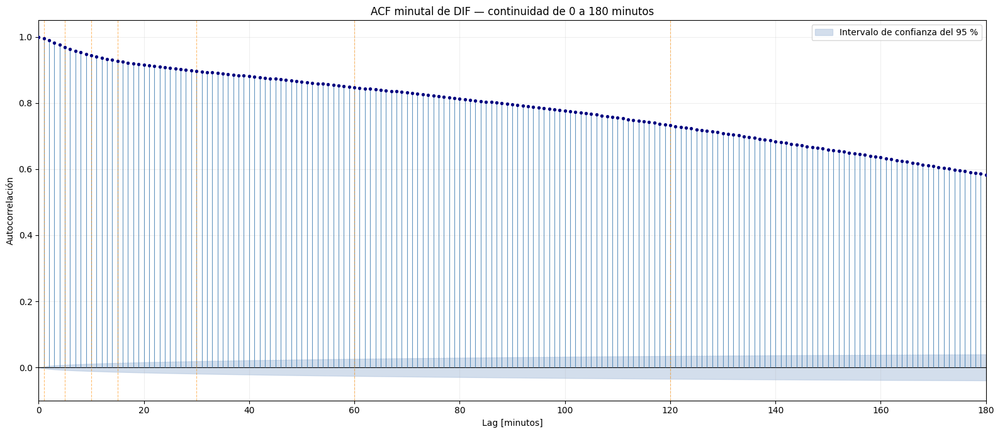

In [71]:
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# 1. Comprobar que se ejecutó la celda anterior
if "serie_regular_acf_minutal_dif" not in globals():
    raise NameError("Primero debes ejecutar la celda " "de preparación de la serie minutal.")


# 2. Definir el rango temporal que queremos analizar


# Definir el retraso máximo de la ACF.
# Como la serie es minutal, 180 lags equivalen a 180 minutos.
MAX_LAG_MINUTAL_ACF_DIF = 180
if serie_regular_acf_minutal_dif.notna().sum() <= MAX_LAG_MINUTAL_ACF_DIF:
    raise ValueError("No hay suficientes observaciones " "para calcular 180 lags.")


# 3. Calcular la función de autocorrelación


# Calcular la ACF desde el lag 0 hasta el lag 180.
resultado_acf_minutal_dif = acf(
    serie_regular_acf_minutal_dif.to_numpy(),
    nlags=MAX_LAG_MINUTAL_ACF_DIF,
    fft=True,
    alpha=0.05,
    adjusted=False,
    missing="conservative",
)
valores_acf_minutal_dif = resultado_acf_minutal_dif[0]
intervalos_acf_minutal_dif = resultado_acf_minutal_dif[1]
lags_minutales_acf_dif = np.arange(MAX_LAG_MINUTAL_ACF_DIF + 1)


# 4. Preparar el intervalo de confianza
limite_inferior_acf_minutal_dif = intervalos_acf_minutal_dif[:, 0] - valores_acf_minutal_dif
limite_superior_acf_minutal_dif = intervalos_acf_minutal_dif[:, 1] - valores_acf_minutal_dif


# 5. Representar la ACF
fig_acf_minutal_dif, eje_acf_minutal_dif = plt.subplots(figsize=(16, 7))
eje_acf_minutal_dif.fill_between(
    lags_minutales_acf_dif,
    limite_inferior_acf_minutal_dif,
    limite_superior_acf_minutal_dif,
    color="lightsteelblue",
    alpha=0.55,
    label="Intervalo de confianza del 95 %",
)
eje_acf_minutal_dif.axhline(y=0, color="black", linewidth=0.8)
eje_acf_minutal_dif.vlines(
    x=lags_minutales_acf_dif,
    ymin=0,
    ymax=valores_acf_minutal_dif,
    color="steelblue",
    linewidth=0.8,
    alpha=0.85,
)
eje_acf_minutal_dif.scatter(
    lags_minutales_acf_dif, valores_acf_minutal_dif, color="navy", s=8, zorder=3
)


# 6. Marcar retrasos relevantes
lags_referencia_acf_minutal_dif = [1, 5, 10, 15, 30, 60, 120, 180]
for lag_referencia in lags_referencia_acf_minutal_dif:
    eje_acf_minutal_dif.axvline(
        x=lag_referencia, color="darkorange", linestyle="--", linewidth=0.8, alpha=0.55
    )


# 7. Configurar títulos y ejes
eje_acf_minutal_dif.set_xlabel("Lag [minutos]")
eje_acf_minutal_dif.set_ylabel("Autocorrelación")
eje_acf_minutal_dif.set_title("ACF minutal de DIF — continuidad de 0 a 180 minutos")
eje_acf_minutal_dif.set_xlim(0, MAX_LAG_MINUTAL_ACF_DIF)


# Calcular un límite inferior que no recorte
# posibles autocorrelaciones negativas.
limite_y_inferior_acf_dif = min(-0.10, float(valores_acf_minutal_dif.min()) - 0.05)
eje_acf_minutal_dif.set_ylim(limite_y_inferior_acf_dif, 1.05)
eje_acf_minutal_dif.grid(alpha=0.20)
eje_acf_minutal_dif.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [72]:
# Crear las equivalencias temporales de los lags elegidos.
equivalencias_lags_acf_minutal_dif = {
    1: "1 minuto",
    5: "5 minutos",
    10: "10 minutos",
    15: "15 minutos",
    30: "30 minutos",
    60: "1 hora",
    120: "2 horas",
    180: "3 horas",
}
filas_tabla_acf_minutal_dif = []
for lag_acf_dif, equivalencia_acf_dif in equivalencias_lags_acf_minutal_dif.items():
    serie_desplazada_acf_minutal_dif = serie_regular_acf_minutal_dif.shift(lag_acf_dif)
    mascara_parejas_validas_acf_dif = (
        serie_regular_acf_minutal_dif.notna() & serie_desplazada_acf_minutal_dif.notna()
    )
    n_parejas_validas_acf_dif = int(mascara_parejas_validas_acf_dif.sum())
    valor_lag_acf_minutal_dif = float(valores_acf_minutal_dif[lag_acf_dif])
    filas_tabla_acf_minutal_dif.append(
        {
            "lag": lag_acf_dif,
            "equivalencia_temporal": equivalencia_acf_dif,
            "autocorrelacion": valor_lag_acf_minutal_dif,
            "parejas_validas": n_parejas_validas_acf_dif,
        }
    )

tabla_lags_acf_minutal_dif = pd.DataFrame(filas_tabla_acf_minutal_dif)
print("Autocorrelación minutal en lags relevantes:")
display(
    tabla_lags_acf_minutal_dif.style.format(
        {"autocorrelacion": "{:.4f}", "parejas_validas": "{:,}"}
    )
)

Autocorrelación minutal en lags relevantes:


,lag,equivalencia_temporal,autocorrelacion,parejas_validas
0,1,1 minuto,0.9962,"558,408"
1,5,5 minutos,0.9694,"558,195"
2,10,10 minutos,0.9444,"558,144"
3,15,15 minutos,0.9274,"558,121"
4,30,30 minutos,0.8966,"558,061"
5,60,1 hora,0.8473,"557,988"
6,120,2 horas,0.7323,"557,870"
7,180,3 horas,0.5830,"557,748"


**Resultado hasta 180 minutos.** La autocorrelación es muy elevada y desciende lentamente: 0,847 a una hora, 0,732 a dos horas y 0,583 a tres horas, con una continuidad prácticamente total entre minutos consecutivos. Al calcularse sobre toda la serie, la ACF mezcla noche, ciclo solar, evolución estacional y meteorología: demuestra continuidad temporal, pero no permite atribuirla a la persistencia meteorológica. Aunque la incertidumbre de la estimación crece con el retardo, las correlaciones siguen siendo claramente distintas de cero.

#### Ventana de dos días

Un máximo alrededor del retardo de 1.440 minutos indicaría que la DIF de un minuto se parece a la del mismo minuto del día anterior (por ejemplo, martes a las 12:30 frente a lunes a las 12:30). Sería una señal del ciclo diario, no una prueba de que la meteorología de un día permita predecir la del siguiente.

In [73]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf
from IPython.display import display

# 1. Comprobar que existe la serie minutal
if "serie_regular_acf_minutal_dif" not in globals():

    # Detener la ejecución si no existe la serie necesaria.
    raise NameError("Primero debes ejecutar la celda " "de preparación de la serie minutal.")


# 2. Definir el rango máximo de lags
MINUTOS_POR_HORA_ACF_DIF = 60
HORAS_POR_DIA_ACF_DIF = 24
MINUTOS_POR_DIA_ACF_DIF = MINUTOS_POR_HORA_ACF_DIF * HORAS_POR_DIA_ACF_DIF
MAX_LAG_2DIAS_ACF_DIF = 2 * MINUTOS_POR_DIA_ACF_DIF
print("Lag máximo analizado:", MAX_LAG_2DIAS_ACF_DIF, "minutos")


# Mostrar su equivalencia temporal.
print("Equivalencia:", MAX_LAG_2DIAS_ACF_DIF / 60, "horas")


# 3. Comprobar que hay suficientes observaciones
n_validos_acf_2dias_dif = int(serie_regular_acf_minutal_dif.notna().sum())
if n_validos_acf_2dias_dif <= MAX_LAG_2DIAS_ACF_DIF:
    raise ValueError(
        "No hay suficientes observaciones válidas " "para calcular una ACF hasta dos días."
    )


# 4. Calcular la ACF


# Calcular las autocorrelaciones desde el lag 0
# hasta el lag 2.880.
resultado_acf_2dias_minutal_dif = acf(
    serie_regular_acf_minutal_dif.to_numpy(),
    nlags=MAX_LAG_2DIAS_ACF_DIF,
    fft=True,
    alpha=0.05,
    adjusted=False,
    missing="conservative",
)
valores_acf_2dias_minutal_dif = resultado_acf_2dias_minutal_dif[0]
intervalos_acf_2dias_minutal_dif = resultado_acf_2dias_minutal_dif[1]


# Crear una secuencia que contiene todos los lags
# desde 0 hasta 2.880 minutos.
lags_acf_2dias_minutal_dif = np.arange(MAX_LAG_2DIAS_ACF_DIF + 1)


# 5. Preparar las bandas de confianza


# Restar la ACF al límite inferior del intervalo.
# De este modo, la banda se representa alrededor de cero.
limite_inferior_acf_2dias_dif = (
    intervalos_acf_2dias_minutal_dif[:, 0] - valores_acf_2dias_minutal_dif
)


# Restar la ACF al límite superior del intervalo.
# De este modo, la banda se representa alrededor de cero.
limite_superior_acf_2dias_dif = (
    intervalos_acf_2dias_minutal_dif[:, 1] - valores_acf_2dias_minutal_dif
)


# 6. Confirmar la configuración
resumen_calculo_acf_2dias_dif = pd.DataFrame(
    {
        "comprobación": [
            "Resolución de la serie",
            "Lag mínimo",
            "Lag máximo",
            "Equivalencia del lag máximo",
            "Observaciones válidas",
            "Nivel de confianza",
            "Tratamiento de ausencias",
            "Se ha calculado una media",
            "Se ha utilizado STL",
        ],
        "resultado": [
            "1 minuto",
            0,
            MAX_LAG_2DIAS_ACF_DIF,
            "48 horas",
            n_validos_acf_2dias_dif,
            "95 %",
            "Conservador, sin eliminar huecos",
            False,
            False,
        ],
    }
)
print("Configuración de la ACF minutal hasta dos días:")
display(resumen_calculo_acf_2dias_dif)

Lag máximo analizado: 2880 minutos
Equivalencia: 48.0 horas
Configuración de la ACF minutal hasta dos días:


/tmp/ipykernel_1005/3815640561.py:38: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_acf_2dias_minutal_dif = acf(


,comprobación,resultado
0,Resolución de la serie,1 minuto
1,Lag mínimo,0
2,Lag máximo,2880
3,Equivalencia del lag máximo,48 horas
4,Observaciones válidas,558635
5,Nivel de confianza,95 %
6,Tratamiento de ausencias,"Conservador, sin eliminar huecos"
7,Se ha calculado una media,False
8,Se ha utilizado STL,False


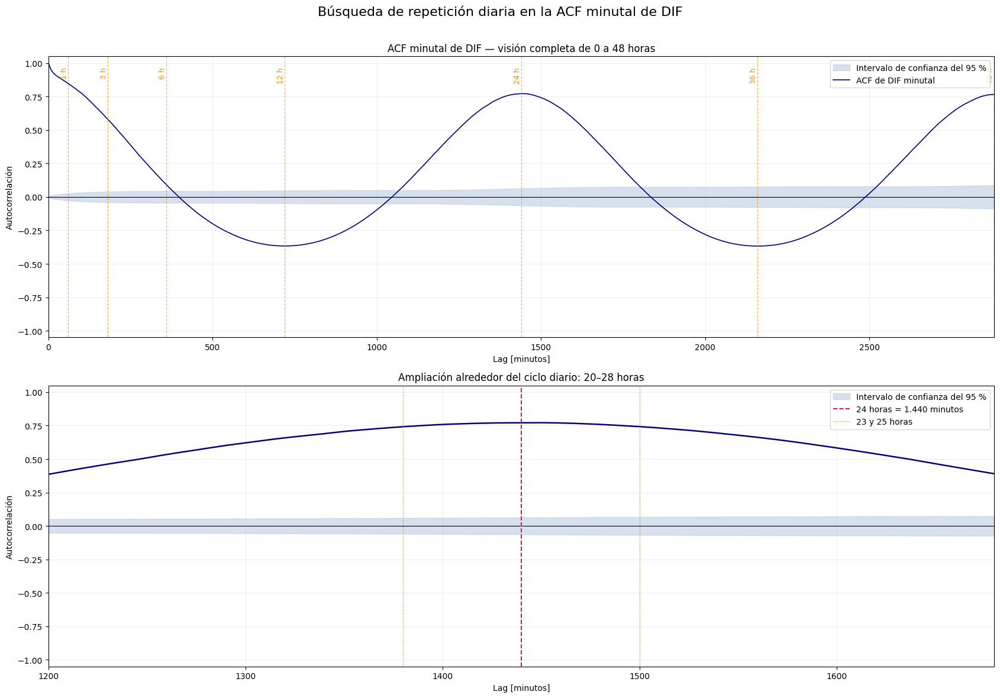

In [74]:
import matplotlib.pyplot as plt

# 1. Comprobar que se ha calculado la ACF
if "valores_acf_2dias_minutal_dif" not in globals():
    raise NameError("Primero debes ejecutar la celda " "de cálculo de la ACF hasta dos días.")


# 2. Definir lags temporales de referencia
LAG_1H_ACF_DIF = 60
LAG_3H_ACF_DIF = 180
LAG_6H_ACF_DIF = 360
LAG_12H_ACF_DIF = 720
LAG_24H_ACF_DIF = 1440
LAG_36H_ACF_DIF = 2160
LAG_48H_ACF_DIF = 2880


# 3. Crear la figura
fig_acf_2dias_dif, ejes_acf_2dias_dif = plt.subplots(nrows=2, ncols=1, figsize=(17, 12))
eje_general_acf_2dias_dif = ejes_acf_2dias_dif[0]
eje_zoom_acf_2dias_dif = ejes_acf_2dias_dif[1]


# 4. Gráfica general de 0 a 48 horas
eje_general_acf_2dias_dif.fill_between(
    lags_acf_2dias_minutal_dif,
    limite_inferior_acf_2dias_dif,
    limite_superior_acf_2dias_dif,
    color="lightsteelblue",
    alpha=0.50,
    label="Intervalo de confianza del 95 %",
)
eje_general_acf_2dias_dif.axhline(y=0, color="black", linewidth=0.8)


# Dibujar la evolución completa de la ACF.
# Se utiliza una línea porque 2.881 barras serían poco legibles.
eje_general_acf_2dias_dif.plot(
    lags_acf_2dias_minutal_dif,
    valores_acf_2dias_minutal_dif,
    color="navy",
    linewidth=1.2,
    label="ACF de DIF minutal",
)


# Crear un diccionario con lags importantes.
lags_referencia_general_acf_dif = {
    LAG_1H_ACF_DIF: "1 h",
    LAG_3H_ACF_DIF: "3 h",
    LAG_6H_ACF_DIF: "6 h",
    LAG_12H_ACF_DIF: "12 h",
    LAG_24H_ACF_DIF: "24 h",
    LAG_36H_ACF_DIF: "36 h",
    LAG_48H_ACF_DIF: "48 h",
}
for lag_referencia, etiqueta_referencia in lags_referencia_general_acf_dif.items():
    eje_general_acf_2dias_dif.axvline(
        x=lag_referencia, color="darkorange", linestyle="--", linewidth=0.9, alpha=0.70
    )

    # Escribir la equivalencia temporal junto a la línea.
    eje_general_acf_2dias_dif.text(
        x=lag_referencia,
        y=0.97,
        s=etiqueta_referencia,
        rotation=90,
        verticalalignment="top",
        horizontalalignment="right",
        color="darkorange",
        fontsize=9,
    )

eje_general_acf_2dias_dif.set_xlim(0, MAX_LAG_2DIAS_ACF_DIF)
eje_general_acf_2dias_dif.set_ylim(-1.05, 1.05)
eje_general_acf_2dias_dif.set_xlabel("Lag [minutos]")
eje_general_acf_2dias_dif.set_ylabel("Autocorrelación")
eje_general_acf_2dias_dif.set_title("ACF minutal de DIF — visión completa de 0 a 48 horas")
eje_general_acf_2dias_dif.grid(alpha=0.20)
eje_general_acf_2dias_dif.legend(loc="upper right")


# 5. Definir el entorno de las 24 horas


# Definir el principio de la ampliación:
# cuatro horas antes de las 24 horas.
INICIO_ZOOM_ACF_DIF = LAG_24H_ACF_DIF - 240


# Definir el final de la ampliación:
# cuatro horas después de las 24 horas.
FIN_ZOOM_ACF_DIF = LAG_24H_ACF_DIF + 240


# Crear una máscara para seleccionar solo los lags
# comprendidos entre 20 y 28 horas.
mascara_zoom_acf_dif = (lags_acf_2dias_minutal_dif >= INICIO_ZOOM_ACF_DIF) & (
    lags_acf_2dias_minutal_dif <= FIN_ZOOM_ACF_DIF
)


# 6. Gráfica ampliada alrededor de las 24 horas
eje_zoom_acf_2dias_dif.fill_between(
    lags_acf_2dias_minutal_dif[mascara_zoom_acf_dif],
    limite_inferior_acf_2dias_dif[mascara_zoom_acf_dif],
    limite_superior_acf_2dias_dif[mascara_zoom_acf_dif],
    color="lightsteelblue",
    alpha=0.50,
    label="Intervalo de confianza del 95 %",
)
eje_zoom_acf_2dias_dif.axhline(y=0, color="black", linewidth=0.8)
eje_zoom_acf_2dias_dif.plot(
    lags_acf_2dias_minutal_dif[mascara_zoom_acf_dif],
    valores_acf_2dias_minutal_dif[mascara_zoom_acf_dif],
    color="navy",
    linewidth=1.8,
)
eje_zoom_acf_2dias_dif.axvline(
    x=LAG_24H_ACF_DIF,
    color="crimson",
    linestyle="--",
    linewidth=1.4,
    label="24 horas = 1.440 minutos",
)
eje_zoom_acf_2dias_dif.axvline(
    x=1380, color="darkorange", linestyle=":", linewidth=1, label="23 y 25 horas"
)
eje_zoom_acf_2dias_dif.axvline(x=1500, color="darkorange", linestyle=":", linewidth=1)
eje_zoom_acf_2dias_dif.set_xlim(INICIO_ZOOM_ACF_DIF, FIN_ZOOM_ACF_DIF)
eje_zoom_acf_2dias_dif.set_ylim(-1.05, 1.05)
eje_zoom_acf_2dias_dif.set_xlabel("Lag [minutos]")
eje_zoom_acf_2dias_dif.set_ylabel("Autocorrelación")
eje_zoom_acf_2dias_dif.set_title("Ampliación alrededor del ciclo diario: 20–28 horas")
eje_zoom_acf_2dias_dif.grid(alpha=0.20)
eje_zoom_acf_2dias_dif.legend(loc="upper right")


# 7. Finalizar la figura
fig_acf_2dias_dif.suptitle("Búsqueda de repetición diaria en la ACF minutal de DIF", fontsize=16)


# Ajustar los márgenes para evitar solapamientos.
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [75]:
equivalencias_lags_2dias_acf_dif = {
    60: "1 hora",
    180: "3 horas",
    360: "6 horas",
    720: "12 horas",
    1080: "18 horas",
    1380: "23 horas",
    1410: "23 horas y 30 minutos",
    1440: "24 horas",
    1470: "24 horas y 30 minutos",
    1500: "25 horas",
    2160: "36 horas",
    2880: "48 horas",
}
filas_tabla_acf_2dias_dif = []
for lag_acf_dif, equivalencia_acf_dif in equivalencias_lags_2dias_acf_dif.items():
    serie_desplazada_acf_2dias_dif = serie_regular_acf_minutal_dif.shift(lag_acf_dif)
    mascara_parejas_validas_2dias_dif = (
        serie_regular_acf_minutal_dif.notna() & serie_desplazada_acf_2dias_dif.notna()
    )
    n_parejas_validas_2dias_dif = int(mascara_parejas_validas_2dias_dif.sum())
    valor_acf_lag_2dias_dif = float(valores_acf_2dias_minutal_dif[lag_acf_dif])
    filas_tabla_acf_2dias_dif.append(
        {
            "lag_minutos": lag_acf_dif,
            "equivalencia_temporal": equivalencia_acf_dif,
            "autocorrelacion": valor_acf_lag_2dias_dif,
            "parejas_validas": n_parejas_validas_2dias_dif,
        }
    )

tabla_lags_acf_2dias_dif = pd.DataFrame(filas_tabla_acf_2dias_dif)
print("Autocorrelación en lags de hasta dos días:")
display(
    tabla_lags_acf_2dias_dif.style.format({"autocorrelacion": "{:.4f}", "parejas_validas": "{:,}"})
)

Autocorrelación en lags de hasta dos días:


,lag_minutos,equivalencia_temporal,autocorrelacion,parejas_validas
0,60,1 hora,0.8473,"557,988"
1,180,3 horas,0.5830,"557,748"
2,360,6 horas,0.0900,"557,387"
3,720,12 horas,-0.3667,"556,667"
4,1080,18 horas,0.0774,"555,948"
5,1380,23 horas,0.7415,"555,348"
6,1410,23 horas y 30 minutos,0.7636,"555,288"
7,1440,24 horas,0.7711,"555,230"
8,1470,24 horas y 30 minutos,0.7648,"555,168"
9,1500,25 horas,0.7423,"555,109"


**Resultado.**

- Periodicidad diaria clara: 0,7711 a 24 horas y 0,7656 a 48 horas, de modo que el patrón diario se mantiene estable durante al menos dos días.
- La continuidad inmediata supera a la repetición diaria: 0,8473 a una hora frente a 0,7711 a 24 horas.
- Las autocorrelaciones negativas a 12 y 36 horas (−0,3667 y −0,3673) reflejan fases opuestas del ciclo, no una relación meteorológica inversa: una separación de 12 horas compara a menudo el mediodía con la medianoche.
- Los valores próximos a cero a 6 y 18 horas (0,0900 y 0,0774) indican desalineación del ciclo.
- El pico de 24 horas es ancho (0,7415 a 23 h, 0,7636 a 23 h 30 min, 0,7711 a 24 h, 0,7648 a 24 h 30 min y 0,7423 a 25 h), lo que puede relacionarse con la suavidad de la curva solar, la duración de las noches y los cambios estacionales del amanecer y el atardecer.

#### Ventana de siete días

In [76]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf
from IPython.display import display

# 1. Comprobar que existe la serie minutal
if "serie_regular_acf_minutal_dif" not in globals():

    # Detener la ejecución si no existe la serie necesaria.
    raise NameError("Primero debes ejecutar la celda " "de preparación de la serie minutal.")


# 2. Definir las equivalencias temporales
MINUTOS_HORA_ACF_SEMANA_DIF = 60
HORAS_DIA_ACF_SEMANA_DIF = 24
MINUTOS_DIA_ACF_SEMANA_DIF = MINUTOS_HORA_ACF_SEMANA_DIF * HORAS_DIA_ACF_SEMANA_DIF
NUMERO_DIAS_ACF_SEMANA_DIF = 7
MAX_LAG_SEMANA_ACF_DIF = NUMERO_DIAS_ACF_SEMANA_DIF * MINUTOS_DIA_ACF_SEMANA_DIF
print("Minutos de un día:", MINUTOS_DIA_ACF_SEMANA_DIF)
print("Lag máximo:", MAX_LAG_SEMANA_ACF_DIF, "minutos")


# Mostrar la equivalencia del lag máximo en días.
print("Equivalencia:", MAX_LAG_SEMANA_ACF_DIF / MINUTOS_DIA_ACF_SEMANA_DIF, "días")


# 3. Comprobar la cantidad de datos válidos
n_validos_acf_semana_dif = int(serie_regular_acf_minutal_dif.notna().sum())
if n_validos_acf_semana_dif <= MAX_LAG_SEMANA_ACF_DIF:
    raise ValueError(
        "No hay suficientes observaciones válidas " "para calcular una ACF hasta siete días."
    )


# 4. Calcular la ACF hasta siete días


# Calcular las autocorrelaciones desde el lag 0
# hasta el lag 10.080.
resultado_acf_semana_minutal_dif = acf(
    serie_regular_acf_minutal_dif.to_numpy(),
    nlags=MAX_LAG_SEMANA_ACF_DIF,
    fft=True,
    alpha=0.05,
    adjusted=False,
    missing="conservative",
)
valores_acf_semana_minutal_dif = resultado_acf_semana_minutal_dif[0]
intervalos_acf_semana_minutal_dif = resultado_acf_semana_minutal_dif[1]
lags_acf_semana_minutal_dif = np.arange(MAX_LAG_SEMANA_ACF_DIF + 1)


# 5. Convertir los lags de minutos a días


# Dividir cada lag entre 1.440 para expresarlo en días.
# Esta conversión solo afecta a la representación gráfica.
# La serie sigue siendo minutal y no se ha agregado.
lags_dias_acf_semana_dif = lags_acf_semana_minutal_dif / MINUTOS_DIA_ACF_SEMANA_DIF


# 6. Preparar la banda de confianza alrededor de cero
limite_inferior_cero_acf_semana_dif = (
    intervalos_acf_semana_minutal_dif[:, 0] - valores_acf_semana_minutal_dif
)
limite_superior_cero_acf_semana_dif = (
    intervalos_acf_semana_minutal_dif[:, 1] - valores_acf_semana_minutal_dif
)


# 7. Crear el resumen del cálculo
resumen_calculo_acf_semana_dif = pd.DataFrame(
    {
        "comprobación": [
            "Resolución original",
            "Lag mínimo",
            "Lag máximo",
            "Equivalencia del lag máximo",
            "Observaciones válidas",
            "Nivel de confianza",
            "Tratamiento de ausencias",
            "Se ha calculado una media",
            "Se ha utilizado STL",
        ],
        "resultado": [
            "1 minuto",
            0,
            MAX_LAG_SEMANA_ACF_DIF,
            "7 días",
            n_validos_acf_semana_dif,
            "95 %",
            "Conservador, sin comprimir los huecos",
            False,
            False,
        ],
    }
)
print("Configuración de la ACF minutal hasta siete días:")
display(resumen_calculo_acf_semana_dif)

Minutos de un día: 1440
Lag máximo: 10080 minutos
Equivalencia: 7.0 días
Configuración de la ACF minutal hasta siete días:


/tmp/ipykernel_1005/3387820570.py:40: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_acf_semana_minutal_dif = acf(


,comprobación,resultado
0,Resolución original,1 minuto
1,Lag mínimo,0
2,Lag máximo,10080
3,Equivalencia del lag máximo,7 días
4,Observaciones válidas,558635
5,Nivel de confianza,95 %
6,Tratamiento de ausencias,"Conservador, sin comprimir los huecos"
7,Se ha calculado una media,False
8,Se ha utilizado STL,False


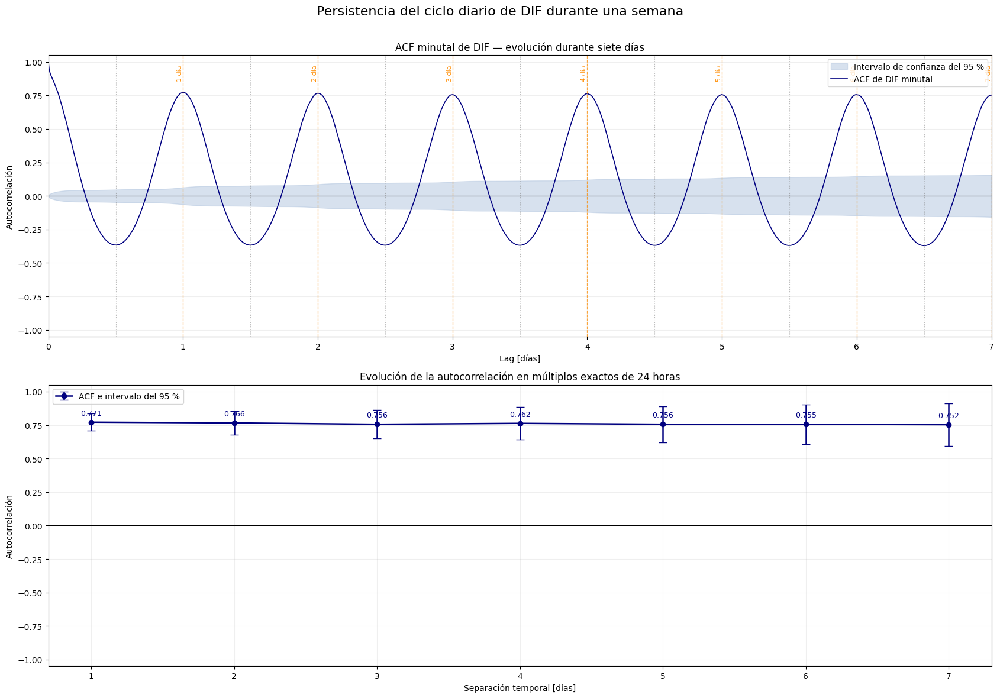

In [77]:
import matplotlib.pyplot as plt

# 1. Comprobar que se ejecutó la celda anterior
if "valores_acf_semana_minutal_dif" not in globals():
    raise NameError("Primero debes ejecutar la celda " "de cálculo de la ACF hasta siete días.")


# 2. Crear los lags diarios
dias_referencia_acf_semana_dif = np.arange(1, NUMERO_DIAS_ACF_SEMANA_DIF + 1)
lags_diarios_acf_semana_dif = dias_referencia_acf_semana_dif * MINUTOS_DIA_ACF_SEMANA_DIF
acf_picos_diarios_semana_dif = valores_acf_semana_minutal_dif[lags_diarios_acf_semana_dif]


# Extraer los límites inferiores de los intervalos
# correspondientes a los picos diarios.
ic_inferior_picos_diarios_dif = intervalos_acf_semana_minutal_dif[lags_diarios_acf_semana_dif, 0]


# Extraer los límites superiores de los intervalos
# correspondientes a los picos diarios.
ic_superior_picos_diarios_dif = intervalos_acf_semana_minutal_dif[lags_diarios_acf_semana_dif, 1]
error_inferior_picos_diarios_dif = acf_picos_diarios_semana_dif - ic_inferior_picos_diarios_dif
error_superior_picos_diarios_dif = ic_superior_picos_diarios_dif - acf_picos_diarios_semana_dif


# Agrupar los errores inferior y superior
# en el formato que necesita Matplotlib.
errores_picos_diarios_acf_dif = np.vstack(
    [error_inferior_picos_diarios_dif, error_superior_picos_diarios_dif]
)


# 3. Crear la figura
fig_acf_semana_dif, ejes_acf_semana_dif = plt.subplots(nrows=2, ncols=1, figsize=(17, 12))
eje_general_acf_semana_dif = ejes_acf_semana_dif[0]
eje_picos_acf_semana_dif = ejes_acf_semana_dif[1]


# 4. Dibujar la ACF completa
eje_general_acf_semana_dif.fill_between(
    lags_dias_acf_semana_dif,
    limite_inferior_cero_acf_semana_dif,
    limite_superior_cero_acf_semana_dif,
    color="lightsteelblue",
    alpha=0.50,
    label="Intervalo de confianza del 95 %",
)
eje_general_acf_semana_dif.axhline(y=0, color="black", linewidth=0.8)
eje_general_acf_semana_dif.plot(
    lags_dias_acf_semana_dif,
    valores_acf_semana_minutal_dif,
    color="navy",
    linewidth=1.2,
    label="ACF de DIF minutal",
)


# 5. Marcar cada día completo
for dia_acf_dif in dias_referencia_acf_semana_dif:
    eje_general_acf_semana_dif.axvline(
        x=dia_acf_dif, color="darkorange", linestyle="--", linewidth=0.9, alpha=0.75
    )
    eje_general_acf_semana_dif.text(
        x=dia_acf_dif,
        y=0.98,
        s=f"{dia_acf_dif} día",
        rotation=90,
        verticalalignment="top",
        horizontalalignment="right",
        color="darkorange",
        fontsize=8,
    )


# 6. Marcar las fases opuestas de medio día
medios_dias_acf_semana_dif = np.arange(0, NUMERO_DIAS_ACF_SEMANA_DIF) + 0.5
for medio_dia_acf_dif in medios_dias_acf_semana_dif:

    # Dibujar una línea vertical tenue
    # en cada fase opuesta del ciclo.
    eje_general_acf_semana_dif.axvline(
        x=medio_dia_acf_dif, color="grey", linestyle=":", linewidth=0.8, alpha=0.55
    )


# 7. Configurar el gráfico general
eje_general_acf_semana_dif.set_xlim(0, NUMERO_DIAS_ACF_SEMANA_DIF)
eje_general_acf_semana_dif.set_ylim(-1.05, 1.05)
eje_general_acf_semana_dif.set_xlabel("Lag [días]")
eje_general_acf_semana_dif.set_ylabel("Autocorrelación")
eje_general_acf_semana_dif.set_title("ACF minutal de DIF — evolución durante siete días")
eje_general_acf_semana_dif.grid(alpha=0.20)
eje_general_acf_semana_dif.legend(loc="upper right")


# 8. Dibujar la evolución de los picos diarios
eje_picos_acf_semana_dif.errorbar(
    dias_referencia_acf_semana_dif,
    acf_picos_diarios_semana_dif,
    yerr=errores_picos_diarios_acf_dif,
    color="navy",
    marker="o",
    markersize=6,
    linewidth=1.8,
    capsize=5,
    label="ACF e intervalo del 95 %",
)
eje_picos_acf_semana_dif.axhline(y=0, color="black", linewidth=0.8)


# 9. Escribir el valor de cada pico
for dia_acf_dif, valor_acf_dif in zip(dias_referencia_acf_semana_dif, acf_picos_diarios_semana_dif):
    eje_picos_acf_semana_dif.text(
        x=dia_acf_dif,
        y=valor_acf_dif + 0.04,
        s=f"{valor_acf_dif:.3f}",
        horizontalalignment="center",
        verticalalignment="bottom",
        fontsize=9,
        color="navy",
    )


# 10. Configurar el gráfico de picos
eje_picos_acf_semana_dif.set_xticks(dias_referencia_acf_semana_dif)
eje_picos_acf_semana_dif.set_xlim(0.7, 7.3)
eje_picos_acf_semana_dif.set_ylim(-1.05, 1.05)
eje_picos_acf_semana_dif.set_xlabel("Separación temporal [días]")
eje_picos_acf_semana_dif.set_ylabel("Autocorrelación")
eje_picos_acf_semana_dif.set_title(
    "Evolución de la autocorrelación " "en múltiplos exactos de 24 horas"
)
eje_picos_acf_semana_dif.grid(alpha=0.20)
eje_picos_acf_semana_dif.legend(loc="best")


# 11. Finalizar la figura
fig_acf_semana_dif.suptitle("Persistencia del ciclo diario de DIF durante una semana", fontsize=16)


# Ajustar los márgenes para evitar solapamientos.
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [78]:
filas_picos_diarios_acf_dif = []
acf_primer_dia_referencia_dif = float(valores_acf_semana_minutal_dif[MINUTOS_DIA_ACF_SEMANA_DIF])
for dia_acf_dif in dias_referencia_acf_semana_dif:
    lag_diario_acf_dif = int(dia_acf_dif * MINUTOS_DIA_ACF_SEMANA_DIF)
    serie_desplazada_diaria_acf_dif = serie_regular_acf_minutal_dif.shift(lag_diario_acf_dif)
    mascara_parejas_diarias_acf_dif = (
        serie_regular_acf_minutal_dif.notna() & serie_desplazada_diaria_acf_dif.notna()
    )
    n_parejas_diarias_acf_dif = int(mascara_parejas_diarias_acf_dif.sum())
    valor_pico_diario_acf_dif = float(valores_acf_semana_minutal_dif[lag_diario_acf_dif])
    ic_inferior_diario_acf_dif = float(intervalos_acf_semana_minutal_dif[lag_diario_acf_dif, 0])
    ic_superior_diario_acf_dif = float(intervalos_acf_semana_minutal_dif[lag_diario_acf_dif, 1])
    semianchura_ic_diario_acf_dif = (ic_superior_diario_acf_dif - ic_inferior_diario_acf_dif) / 2
    diferencia_respecto_dia_1_acf_dif = valor_pico_diario_acf_dif - acf_primer_dia_referencia_dif
    filas_picos_diarios_acf_dif.append(
        {
            "dia": int(dia_acf_dif),
            "lag_minutos": lag_diario_acf_dif,
            "autocorrelacion": valor_pico_diario_acf_dif,
            "IC_95_inferior": ic_inferior_diario_acf_dif,
            "IC_95_superior": ic_superior_diario_acf_dif,
            "semianchura_IC_95": semianchura_ic_diario_acf_dif,
            "diferencia_respecto_dia_1": diferencia_respecto_dia_1_acf_dif,
            "parejas_validas": n_parejas_diarias_acf_dif,
        }
    )

tabla_picos_diarios_acf_semana_dif = pd.DataFrame(filas_picos_diarios_acf_dif)
print("Evolución de los picos diarios de autocorrelación:")
display(
    tabla_picos_diarios_acf_semana_dif.style.format(
        {
            "autocorrelacion": "{:.4f}",
            "IC_95_inferior": "{:.4f}",
            "IC_95_superior": "{:.4f}",
            "semianchura_IC_95": "{:.4f}",
            "diferencia_respecto_dia_1": "{:+.4f}",
            "parejas_validas": "{:,}",
        }
    )
)

Evolución de los picos diarios de autocorrelación:


,dia,lag_minutos,autocorrelacion,IC_95_inferior,IC_95_superior,semianchura_IC_95,diferencia_respecto_dia_1,parejas_validas
0,1,1440,0.7711,0.7080,0.8343,0.0632,+0.0000,"555,230"
1,2,2880,0.7656,0.6789,0.8524,0.0868,-0.0055,"552,353"
2,3,4320,0.7556,0.6506,0.8606,0.1050,-0.0155,"549,478"
3,4,5760,0.7624,0.6420,0.8829,0.1204,-0.0087,"546,601"
4,5,7200,0.7557,0.6215,0.8899,0.1342,-0.0154,"543,723"
5,6,8640,0.7549,0.6085,0.9014,0.1464,-0.0162,"540,845"
6,7,10080,0.7524,0.5946,0.9101,0.1578,-0.0188,"537,966"


In [79]:
filas_fases_opuestas_acf_dif = []
for medio_dia_acf_dif in medios_dias_acf_semana_dif:
    lag_fase_opuesta_acf_dif = int(medio_dia_acf_dif * MINUTOS_DIA_ACF_SEMANA_DIF)
    valor_fase_opuesta_acf_dif = float(valores_acf_semana_minutal_dif[lag_fase_opuesta_acf_dif])
    serie_desplazada_fase_opuesta_dif = serie_regular_acf_minutal_dif.shift(
        lag_fase_opuesta_acf_dif
    )
    mascara_fase_opuesta_acf_dif = (
        serie_regular_acf_minutal_dif.notna() & serie_desplazada_fase_opuesta_dif.notna()
    )
    n_parejas_fase_opuesta_acf_dif = int(mascara_fase_opuesta_acf_dif.sum())
    filas_fases_opuestas_acf_dif.append(
        {
            "separacion_dias": medio_dia_acf_dif,
            "lag_minutos": lag_fase_opuesta_acf_dif,
            "autocorrelacion": valor_fase_opuesta_acf_dif,
            "parejas_validas": n_parejas_fase_opuesta_acf_dif,
        }
    )

tabla_fases_opuestas_acf_semana_dif = pd.DataFrame(filas_fases_opuestas_acf_dif)
print("Autocorrelación en las fases opuestas de medio día:")
display(
    tabla_fases_opuestas_acf_semana_dif.style.format(
        {"separacion_dias": "{:.1f}", "autocorrelacion": "{:.4f}", "parejas_validas": "{:,}"}
    )
)

Autocorrelación en las fases opuestas de medio día:


,separacion_dias,lag_minutos,autocorrelacion,parejas_validas
0,0.5,720,-0.3667,"556,667"
1,1.5,2160,-0.3673,"553,789"
2,2.5,3600,-0.3677,"550,920"
3,3.5,5040,-0.3684,"548,040"
4,4.5,6480,-0.3689,"545,159"
5,5.5,7920,-0.3699,"542,284"
6,6.5,9360,-0.3713,"539,405"


**Conclusión.**

- Continuidad lineal muy elevada: 0,9962 a un minuto, 0,8473 a una hora y 0,5830 a tres horas.
- Los máximos diarios se mantienen alrededor de 0,75 hasta siete días, y las fases opuestas de medio día, alrededor de −0,37.
- No aparece un comportamiento especial en el séptimo día: se observan siete repeticiones del ciclo diario, no una estacionalidad semanal.

La forma aproximadamente sinusoidal (máximos cada 24 horas, mínimos entre ellos y repetición casi constante durante siete días) es la firma de la estacionalidad diaria. La ACF no distingue entre persistencia meteorológica, tendencia, estacionalidad diaria y largas secuencias nocturnas próximas a cero. Por eso el máximo de 24 horas no indica que la meteorología de ayer permita predecir la de hoy: el mismo minuto del día anterior se parece al actual sobre todo porque ocupa una fase solar semejante, y la parte debida a la persistencia meteorológica queda sin aislar. Los retardos de una hora y de un día son candidatos razonables para la ventana de entrada, pero este análisis no demuestra que sean los óptimos.

### A.3 PACF de la serie minutal

La PACF minutal mide la relación lineal directa entre la DIF actual y la de hace $k$ minutos, descontada la influencia de los minutos intermedios. Por ejemplo, la ACF a 60 minutos es 0,8473, pero esa asociación podría transmitirse a través de la cadena $DIF_{t-60} \to DIF_{t-59} \to \dots \to DIF_t$; la PACF a 60 minutos indica si $DIF_{t-60}$ aporta información lineal adicional una vez controlados los 59 minutos intermedios.

Se calcula hasta 180 minutos, con autocovarianzas mediante FFT y la recursión de Levinson–Durbin. Los intervalos del 95 % siguen la aproximación $1/\sqrt{N}$ de statsmodels. Se parte de la misma serie regular que la ACF minutal (A.2).

#### Preparación y validación

In [80]:
# 0. Importar las librerías necesarias
import json
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importar norm para calcular el valor crítico
# de los intervalos de confianza.
from scipy.stats import norm
from IPython.display import display

# Importar acf porque la PACF se obtendrá a partir
# de una ACF con tratamiento conservador de ausencias.
from statsmodels.tsa.stattools import acf

# Importar Levinson-Durbin para convertir
# la secuencia de autocorrelaciones en una PACF.
from statsmodels.tsa.stattools import levinson_durbin

# Importar statsmodels para guardar su versión
# en la configuración de resultados.
import statsmodels

# 1. Configuración general de la PACF minutal

# Indicar el nombre exacto de la serie regular
# utilizada anteriormente en la ACF minutal.
NOMBRE_OBJETO_ORIGEN_PACF_MIN = "serie_regular_acf_minutal_dif"

# Definir el retardo máximo que se estudiará.
# Como la serie es minutal, 180 lags son 180 minutos.
MAX_LAG_PACF_MIN = 180

# Definir alpha=0,05 para obtener
# intervalos de confianza aproximados del 95 %.
ALPHA_PACF_MIN = 0.05

# Definir los retardos que se mostrarán
# posteriormente en la tabla principal.
LAGS_CLAVE_PACF_MIN = [1, 5, 10, 15, 30, 60, 120, 180]


# 2. Comprobar que existe la serie de la ACF minutal

# Comprobar que se ha ejecutado previamente
# la celda de preparación de la ACF minutal.
if NOMBRE_OBJETO_ORIGEN_PACF_MIN not in globals():

    # Detener la ejecución si la serie no está en memoria.
    raise NameError(
        "No existe la serie "
        f"'{NOMBRE_OBJETO_ORIGEN_PACF_MIN}'. "
        "Primero debes ejecutar la celda "
        "'ACF MINUTAL — CELDA 1: "
        "Preparación y comprobación de la serie'."
    )

objeto_origen_pacf_min = globals()[NOMBRE_OBJETO_ORIGEN_PACF_MIN]


# 3. Comprobar el tipo de objeto
if not isinstance(objeto_origen_pacf_min, pd.Series):

    # Detener la ejecución si el objeto no es una serie.
    raise TypeError(
        f"'{NOMBRE_OBJETO_ORIGEN_PACF_MIN}' "
        "debe ser una Series de pandas. "
        f"Tipo encontrado: {type(objeto_origen_pacf_min)}"
    )

# Crear una copia independiente para que la PACF
# no modifique la serie utilizada en la ACF.
serie_dif_minutal_pacf = objeto_origen_pacf_min.copy()

# Convertir los valores observados a tipo numérico.
# Los valores ausentes continúan siendo NaN.
serie_dif_minutal_pacf = pd.to_numeric(serie_dif_minutal_pacf, errors="raise")
serie_dif_minutal_pacf = serie_dif_minutal_pacf.sort_index()
serie_dif_minutal_pacf.name = "DIF minutal original para PACF [W/m²]"


# 4. Comprobar el índice temporal
if not isinstance(serie_dif_minutal_pacf.index, pd.DatetimeIndex):

    # Detener la ejecución si el índice no es temporal.
    raise TypeError("La serie minutal debe tener un DatetimeIndex.")

if not serie_dif_minutal_pacf.index.is_monotonic_increasing:

    # Detener la ejecución si las fechas no están ordenadas.
    raise ValueError("El índice temporal no está ordenado.")

n_duplicados_pacf_min = int(serie_dif_minutal_pacf.index.duplicated().sum())

# Comprobar que no existan timestamps duplicados.
if n_duplicados_pacf_min > 0:
    primeros_duplicados_pacf_min = (
        serie_dif_minutal_pacf.index[serie_dif_minutal_pacf.index.duplicated()].unique().tolist()
    )
    raise ValueError(
        "La serie contiene "
        f"{n_duplicados_pacf_min} timestamps duplicados. "
        "Primeros duplicados: "
        f"{primeros_duplicados_pacf_min[:10]}"
    )


# 5. Confirmar que la cuadrícula es realmente minutal
diferencias_indice_pacf_min = serie_dif_minutal_pacf.index.to_series().diff().dropna()
mascara_saltos_irregulares_pacf_min = diferencias_indice_pacf_min != pd.Timedelta(minutes=1)
n_saltos_irregulares_pacf_min = int(mascara_saltos_irregulares_pacf_min.sum())

# Comprobar que todos los timestamps
# estén separados exactamente por un minuto.
if n_saltos_irregulares_pacf_min > 0:
    primeros_saltos_pacf_min = diferencias_indice_pacf_min[
        mascara_saltos_irregulares_pacf_min
    ].head(10)

    # Detener la ejecución para no alterar
    # el significado temporal de los lags.
    raise ValueError(
        "La cuadrícula temporal no es completamente minutal. "
        "Un lag dejaría de representar siempre un minuto. "
        f"Primeros saltos detectados:\n"
        f"{primeros_saltos_pacf_min}"
    )


# 6. Examinar las observaciones válidas y ausentes
n_total_pacf_min = int(len(serie_dif_minutal_pacf))
n_validos_pacf_min = int(serie_dif_minutal_pacf.notna().sum())
n_ausentes_pacf_min = int(serie_dif_minutal_pacf.isna().sum())
porcentaje_ausentes_pacf_min = 100 * n_ausentes_pacf_min / n_total_pacf_min

# Extraer temporalmente únicamente las observaciones válidas.
# Esta extracción se utiliza solo para hacer controles numéricos.
valores_validos_control_pacf_min = serie_dif_minutal_pacf.dropna().to_numpy(dtype=float)
if not np.isfinite(valores_validos_control_pacf_min).all():
    raise ValueError("Las observaciones válidas de DIF " "contienen valores no finitos.")

# Comprobar que haya suficientes observaciones válidas
# para calcular los 180 retardos.
if n_validos_pacf_min <= 2 * MAX_LAG_PACF_MIN:
    raise ValueError(
        "No existen suficientes observaciones válidas "
        f"para calcular {MAX_LAG_PACF_MIN} retardos."
    )

# Convertir la serie completa en un array.
# Los 11.605 minutos ausentes permanecen como NaN.
valores_dif_minutal_pacf = serie_dif_minutal_pacf.to_numpy(dtype=float)


# 7. Comprobar que coincide con la serie de la ACF

# Comprobar que la copia tiene exactamente el mismo índice
# que la serie empleada en la ACF minutal.
control_mismo_indice_pacf_min = bool(
    serie_dif_minutal_pacf.index.equals(serie_regular_acf_minutal_dif.index)
)

# Comprobar que la copia conserva los mismos valores,
# considerando equivalentes los NaN de ambas series.
control_mismos_valores_pacf_min = bool(
    np.allclose(
        serie_dif_minutal_pacf.to_numpy(dtype=float),
        serie_regular_acf_minutal_dif.to_numpy(dtype=float),
        equal_nan=True,
        rtol=0,
        atol=0,
    )
)

# Detener la ejecución si la copia no coincide con la ACF.
if not (control_mismo_indice_pacf_min and control_mismos_valores_pacf_min):
    raise RuntimeError(
        "La serie preparada para PACF no coincide "
        "exactamente con la utilizada en la ACF minutal."
    )


# 8. Crear el directorio de resultados
marca_ejecucion_pacf_min = datetime.now().strftime("%Y%m%d_%H%M%S")
if Path("/content").exists():
    directorio_raiz_pacf_min = Path("/content")

# Ejecutar esta opción si no se utiliza Google Colab.
else:
    directorio_raiz_pacf_min = Path.cwd()

directorio_resultados_pacf_min = directorio_raiz_pacf_min / (
    "resultados_pacf_minutal_DIF_" f"{marca_ejecucion_pacf_min}"
)
directorio_resultados_pacf_min.mkdir(parents=True, exist_ok=True)


# 9. Crear el resumen de preparación
control_serie_pacf_min = pd.DataFrame(
    {
        "comprobacion": [
            "Objeto utilizado en la ACF",
            "Primera observación",
            "Última observación",
            "Resolución temporal",
            "Minutos de la cuadrícula completa",
            "Minutos con DIF válida",
            "Minutos ausentes",
            "Porcentaje de minutos ausentes",
            "Timestamps duplicados",
            "Saltos temporales diferentes de 1 minuto",
            "Índice idéntico al de la ACF",
            "Valores idénticos a los de la ACF",
            "Se han eliminado minutos",
            "Se han interpolado valores",
            "Se ha calculado una media",
            "Mínimo de DIF válida",
            "Media de DIF válida",
            "Mediana de DIF válida",
            "Máximo de DIF válida",
        ],
        "resultado": [
            NOMBRE_OBJETO_ORIGEN_PACF_MIN,
            serie_dif_minutal_pacf.index.min(),
            serie_dif_minutal_pacf.index.max(),
            "1 minuto",
            n_total_pacf_min,
            n_validos_pacf_min,
            n_ausentes_pacf_min,
            porcentaje_ausentes_pacf_min,
            n_duplicados_pacf_min,
            n_saltos_irregulares_pacf_min,
            control_mismo_indice_pacf_min,
            control_mismos_valores_pacf_min,
            False,
            False,
            False,
            float(serie_dif_minutal_pacf.min()),
            float(serie_dif_minutal_pacf.mean()),
            float(serie_dif_minutal_pacf.median()),
            float(serie_dif_minutal_pacf.max()),
        ],
    }
)


# 10. Mostrar las comprobaciones
print("Control de la serie minutal utilizada en la PACF:")
display(
    control_serie_pacf_min.style.format(
        {"resultado": lambda valor: (f"{valor:.6f}" if isinstance(valor, float) else str(valor))}
    )
)
print("\nLa PACF utilizará exactamente la misma cuadrícula " "minutal que la ACF.")

# Confirmar que no se han eliminado los minutos ausentes.
print("Los minutos ausentes permanecen como NaN " "en sus timestamps originales.")

# Confirmar que no se ha interpolado.
print("No se ha interpolado ningún valor.")

# Confirmar que no se ha agregado la información.
print("No se ha calculado ninguna media ni agregación horaria.")

Control de la serie minutal utilizada en la PACF:


,comprobacion,resultado
0,Objeto utilizado en la ACF,serie_regular_acf_minutal_dif
1,Primera observación,2023-11-01 00:00:00
2,Última observación,2024-11-30 23:59:00
3,Resolución temporal,1 minuto
4,Minutos de la cuadrícula completa,570240
5,Minutos con DIF válida,558635
6,Minutos ausentes,11605
7,Porcentaje de minutos ausentes,2.035108
8,Timestamps duplicados,0
9,Saltos temporales diferentes de 1 minuto,0



La PACF utilizará exactamente la misma cuadrícula minutal que la ACF.
Los minutos ausentes permanecen como NaN en sus timestamps originales.
No se ha interpolado ningún valor.
No se ha calculado ninguna media ni agregación horaria.


#### Cálculo

In [81]:
# 1. Comprobar que se ejecutó la preparación

# Definir los objetos que deben existir después
# de ejecutar la preparación de la PACF minutal.
OBJETOS_REQUERIDOS_CALCULO_PACF_MIN = [
    "serie_dif_minutal_pacf",
    "valores_dif_minutal_pacf",
    "n_total_pacf_min",
    "n_validos_pacf_min",
    "n_ausentes_pacf_min",
    "MAX_LAG_PACF_MIN",
    "ALPHA_PACF_MIN",
    "LAGS_CLAVE_PACF_MIN",
]

# Identificar los objetos que no estén disponibles.
objetos_ausentes_calculo_pacf_min = [
    nombre for nombre in OBJETOS_REQUERIDOS_CALCULO_PACF_MIN if nombre not in globals()
]
if objetos_ausentes_calculo_pacf_min:

    # Detener la ejecución si no se ejecutó correctamente
    # la celda anterior.
    raise NameError(
        "Faltan objetos de la preparación de la PACF minutal: "
        f"{objetos_ausentes_calculo_pacf_min}. "
        "Ejecuta primero la celda de preparación."
    )


# 2. Confirmar nuevamente la estructura de la serie
if not isinstance(serie_dif_minutal_pacf, pd.Series):

    # Detener la ejecución si el objeto no es una serie.
    raise TypeError("'serie_dif_minutal_pacf' debe ser " "una Series de pandas.")

if not isinstance(serie_dif_minutal_pacf.index, pd.DatetimeIndex):

    # Detener la ejecución si el índice no es temporal.
    raise TypeError("La serie PACF no tiene un DatetimeIndex.")

# Confirmar que el array y la serie tengan la misma longitud.
if len(valores_dif_minutal_pacf) != len(serie_dif_minutal_pacf):
    raise RuntimeError("La serie y el array de valores tienen " "longitudes diferentes.")

n_validos_control_calculo_pacf_min = int(np.isfinite(valores_dif_minutal_pacf).sum())
if n_validos_control_calculo_pacf_min != n_validos_pacf_min:
    raise RuntimeError("El número de observaciones válidas ha cambiado " "desde la preparación.")


# 3. Calcular la ACF conservadora que servirá de base

# La función pacf() de statsmodels no permite utilizar
# directamente missing="conservative".
#
# Por ello, primero calculamos una ACF conservadora,
# exactamente igual que en el análisis ACF minutal anterior.
#
# Después transformaremos esa secuencia en PACF
# mediante la recursión de Levinson-Durbin.

# Calcular la ACF desde el lag 0 hasta el lag 180.
acf_conservadora_base_pacf_min = acf(
    valores_dif_minutal_pacf,
    nlags=MAX_LAG_PACF_MIN,
    adjusted=False,
    fft=True,
    missing="conservative",
)

# Comprobar que se han calculado 181 valores:
# lag 0 más los 180 retardos solicitados.
if len(acf_conservadora_base_pacf_min) != MAX_LAG_PACF_MIN + 1:
    raise RuntimeError("El número de valores de la ACF conservadora " "no es el esperado.")

if not np.isfinite(acf_conservadora_base_pacf_min).all():

    # Detener la ejecución si la ACF contiene
    # resultados no finitos.
    raise RuntimeError("La ACF conservadora contiene valores no finitos.")

# Comprobar que la autocorrelación del lag 0 sea igual a 1.
if not np.isclose(acf_conservadora_base_pacf_min[0], 1.0, rtol=1e-12, atol=1e-12):

    # Detener la ejecución si el lag 0 no es correcto.
    raise RuntimeError("La ACF conservadora no presenta " "un valor igual a 1 en el lag 0.")


# 4. Convertir la ACF conservadora en PACF

# Aplicar la recursión de Levinson-Durbin.
#
# La ACF puede utilizarse como secuencia normalizada
# de autocovarianzas porque multiplicar toda la secuencia
# por una constante no cambia las autocorrelaciones parciales.
resultado_levinson_pacf_min = levinson_durbin(
    acf_conservadora_base_pacf_min, nlags=MAX_LAG_PACF_MIN, isacov=True
)
valores_pacf_min = np.asarray(resultado_levinson_pacf_min[2], dtype=float)
if len(valores_pacf_min) != MAX_LAG_PACF_MIN + 1:
    raise RuntimeError("El número de valores PACF calculados " "no es el esperado.")

if not np.isfinite(valores_pacf_min).all():
    raise RuntimeError("El cálculo de la PACF ha producido " "valores no finitos.")

maximo_absoluto_control_pacf_min = float(np.abs(valores_pacf_min).max())

# Comprobar la estabilidad de la recursión.
#
# Las autocorrelaciones parciales deben encontrarse
# dentro del intervalo teórico [-1, 1].
if maximo_absoluto_control_pacf_min > 1.000001:

    # Detener la ejecución si la estimación conservadora
    # no produce una secuencia estable.
    raise RuntimeError(
        "La PACF conservadora ha producido valores "
        "fuera del intervalo [-1, 1]. "
        "La combinación de huecos no permite utilizar "
        "de forma estable la recursión de Levinson-Durbin."
    )

valores_pacf_min[0] = 1.0


# 5. Contar las parejas válidas en cada lag
mascara_validos_pacf_min = np.isfinite(valores_dif_minutal_pacf)
lags_pacf_min = np.arange(MAX_LAG_PACF_MIN + 1)

# Crear un array donde se guardará el número
# de parejas temporalmente válidas de cada lag.
parejas_validas_pacf_min = np.empty(MAX_LAG_PACF_MIN + 1, dtype=int)

# En el lag 0, cada observación válida forma pareja consigo misma.
parejas_validas_pacf_min[0] = int(mascara_validos_pacf_min.sum())
for lag_pacf_min in range(1, MAX_LAG_PACF_MIN + 1):

    # Comparar la validez del instante actual
    # con la validez del instante retrasado.
    mascara_parejas_lag_pacf_min = (
        mascara_validos_pacf_min[lag_pacf_min:] & mascara_validos_pacf_min[:-lag_pacf_min]
    )
    parejas_validas_pacf_min[lag_pacf_min] = int(mascara_parejas_lag_pacf_min.sum())

if np.any(parejas_validas_pacf_min <= 0):

    # Detener la ejecución si algún retardo no puede calcularse.
    raise RuntimeError("Algún lag no dispone de parejas válidas.")


# 6. Calcular los intervalos aproximados del 95 %

# Utilizar el número de observaciones válidas,
# no el número total de minutos de la cuadrícula.
n_observaciones_pacf_min = int(n_validos_pacf_min)

# Calcular el valor crítico de la distribución normal
# correspondiente a un nivel de confianza del 95 %.
valor_critico_pacf_min = float(norm.ppf(1 - ALPHA_PACF_MIN / 2))

# Calcular el semiancho aproximado del intervalo.
#
# Esta es la aproximación habitual:
# valor crítico dividido por la raíz de N.
semiancho_ic95_pacf_min = float(valor_critico_pacf_min / np.sqrt(n_observaciones_pacf_min))
ic95_inferior_pacf_min = valores_pacf_min - semiancho_ic95_pacf_min
ic95_superior_pacf_min = valores_pacf_min + semiancho_ic95_pacf_min
ic95_inferior_pacf_min[0] = 1.0
ic95_superior_pacf_min[0] = 1.0


# 7. Crear las equivalencias temporales


# Crear una función para expresar cada lag
# en minutos y horas de forma comprensible.
def describir_lag_pacf_min(lag_minutos):
    if lag_minutos == 0:
        return "Instante actual"

    if lag_minutos == 1:
        return "1 minuto"

    if lag_minutos < 60:
        return f"{lag_minutos} minutos"

    if lag_minutos % 60 == 0:
        horas_pacf_min = lag_minutos // 60
        if horas_pacf_min == 1:
            return "1 hora"

        return f"{horas_pacf_min} horas"

    horas_pacf_min = lag_minutos // 60
    minutos_restantes_pacf_min = lag_minutos % 60

    # Devolver la equivalencia mixta.
    return f"{horas_pacf_min} h " f"{minutos_restantes_pacf_min} min"


# 8. Crear la tabla completa de resultados
tabla_completa_pacf_min = pd.DataFrame(
    {
        "lag_minutos": lags_pacf_min,
        "equivalencia_temporal": [describir_lag_pacf_min(lag) for lag in lags_pacf_min],
        "pacf": valores_pacf_min,
        "pacf_absoluta": np.abs(valores_pacf_min),
        "IC95_inferior": (ic95_inferior_pacf_min),
        "IC95_superior": (ic95_superior_pacf_min),
        "significativo_95": ((ic95_inferior_pacf_min > 0) | (ic95_superior_pacf_min < 0)),
        "parejas_validas": (parejas_validas_pacf_min),
    }
)
tabla_lags_clave_pacf_min = tabla_completa_pacf_min[
    tabla_completa_pacf_min["lag_minutos"].isin(LAGS_CLAVE_PACF_MIN)
].copy()
tabla_lags_clave_pacf_min = tabla_lags_clave_pacf_min.sort_values("lag_minutos").reset_index(
    drop=True
)

# Seleccionar los veinte retardos
# con mayor PACF absoluta, excluyendo el lag 0.
tabla_mayores_pacf_min = (
    tabla_completa_pacf_min[tabla_completa_pacf_min["lag_minutos"] > 0]
    .nlargest(20, "pacf_absoluta")
    .reset_index(drop=True)
)


# 9. Localizar significancia estadística

# Seleccionar los lags posteriores a cero
# cuyo intervalo de confianza contiene el cero.
lags_no_significativos_pacf_min = tabla_completa_pacf_min[
    (tabla_completa_pacf_min["lag_minutos"] > 0) & (~tabla_completa_pacf_min["significativo_95"])
]

# Comprobar si existe algún lag no significativo.
if len(lags_no_significativos_pacf_min) > 0:
    primer_lag_no_significativo_pacf_min = int(
        lags_no_significativos_pacf_min.iloc[0]["lag_minutos"]
    )

else:

    # Guardar NaN para indicar que no se encontró ninguno.
    primer_lag_no_significativo_pacf_min = np.nan

n_lags_significativos_pacf_min = int(
    tabla_completa_pacf_min.loc[
        tabla_completa_pacf_min["lag_minutos"] > 0, "significativo_95"
    ].sum()
)


# 10. Crear el resumen del cálculo

# Crear una tabla con la configuración
# y los principales resultados.
resumen_calculo_pacf_min = pd.DataFrame(
    {
        "comprobacion": [
            "Serie utilizada",
            "Resolución",
            "Método de tratamiento de ausencias",
            "Método de cálculo PACF",
            "Máximo lag analizado",
            "Minutos de la cuadrícula completa",
            "Observaciones válidas",
            "Minutos ausentes",
            "Nivel de confianza",
            "Semiancho aproximado del IC95",
            "PACF en 1 minuto",
            "PACF en 5 minutos",
            "PACF en 10 minutos",
            "PACF en 15 minutos",
            "PACF en 30 minutos",
            "PACF en 60 minutos",
            "PACF en 120 minutos",
            "PACF en 180 minutos",
            "Primer lag cuyo IC95 incluye cero",
            "Lags significativos entre 1 y 180",
            "PACF dentro del intervalo [-1, 1]",
            "Se han eliminado minutos",
            "Se han interpolado valores",
            "Se ha calculado una media",
        ],
        "resultado": [
            "serie_regular_acf_minutal_dif",
            "1 minuto",
            "ACF conservadora, sin comprimir huecos",
            "Levinson-Durbin sobre ACF conservadora",
            MAX_LAG_PACF_MIN,
            n_total_pacf_min,
            n_observaciones_pacf_min,
            n_ausentes_pacf_min,
            1 - ALPHA_PACF_MIN,
            semiancho_ic95_pacf_min,
            valores_pacf_min[1],
            valores_pacf_min[5],
            valores_pacf_min[10],
            valores_pacf_min[15],
            valores_pacf_min[30],
            valores_pacf_min[60],
            valores_pacf_min[120],
            valores_pacf_min[180],
            primer_lag_no_significativo_pacf_min,
            n_lags_significativos_pacf_min,
            bool(np.all(np.abs(valores_pacf_min) <= 1.000001)),
            False,
            False,
            False,
        ],
    }
)


# 11. Mostrar los resultados
print("Resumen del cálculo de la PACF minutal:")

# Visualizar el resumen.
display(resumen_calculo_pacf_min.style.format(precision=6))
print("\nPACF minutal en retardos relevantes:")

# Visualizar los retardos relevantes.
display(
    tabla_lags_clave_pacf_min.style.format(
        {
            "pacf": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
            "parejas_validas": "{:,}",
        }
    )
)
print("\nVeinte retardos con mayor PACF absoluta:")

# Visualizar los veinte retardos.
display(
    tabla_mayores_pacf_min.style.format(
        {
            "pacf": "{:.6f}",
            "pacf_absoluta": "{:.6f}",
            "IC95_inferior": "{:.6f}",
            "IC95_superior": "{:.6f}",
            "parejas_validas": "{:,}",
        }
    )
)


# 12. Aclaraciones para la interpretación

# Aclarar que el primer lag no significativo
# no implica que todos los posteriores lo sean.
print(
    "\nImportante: el primer lag cuyo intervalo incluye cero "
    "no implica necesariamente que todos los retardos "
    "posteriores sean no significativos."
)
print(
    "Con más de medio millón de observaciones, "
    "efectos muy pequeños pueden resultar "
    "estadísticamente significativos."
)

# Confirmar que no se ha alterado la serie.
print("No se han eliminado minutos, interpolado valores " "ni calculado medias.")

Resumen del cálculo de la PACF minutal:


,comprobacion,resultado
0,Serie utilizada,serie_regular_acf_minutal_dif
1,Resolución,1 minuto
2,Método de tratamiento de ausencias,"ACF conservadora, sin comprimir huecos"
3,Método de cálculo PACF,Levinson-Durbin sobre ACF conservadora
4,Máximo lag analizado,180
5,Minutos de la cuadrícula completa,570240
6,Observaciones válidas,558635
7,Minutos ausentes,11605
8,Nivel de confianza,0.950000
9,Semiancho aproximado del IC95,0.002622



PACF minutal en retardos relevantes:


,lag_minutos,equivalencia_temporal,pacf,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_validas
0,1,1 minuto,0.996181,0.996181,0.993559,0.998803,True,"558,408"
1,5,5 minutos,0.046133,0.046133,0.043511,0.048755,True,"558,195"
2,10,10 minutos,0.026429,0.026429,0.023807,0.029052,True,"558,144"
3,15,15 minutos,0.023413,0.023413,0.020791,0.026035,True,"558,121"
4,30,30 minutos,0.008907,0.008907,0.006285,0.011530,True,"558,061"
5,60,1 hora,0.001949,0.001949,-0.000673,0.004572,False,"557,988"
6,120,2 horas,-0.005687,0.005687,-0.008309,-0.003065,True,"557,870"
7,180,3 horas,-0.000892,0.000892,-0.003514,0.001731,False,"557,748"



Veinte retardos con mayor PACF absoluta:


,lag_minutos,equivalencia_temporal,pacf,pacf_absoluta,IC95_inferior,IC95_superior,significativo_95,parejas_validas
0,1,1 minuto,0.996181,0.996181,0.993559,0.998803,True,"558,408"
1,2,2 minutos,-0.378625,0.378625,-0.381247,-0.376002,True,"558,282"
2,3,3 minutos,0.116801,0.116801,0.114178,0.119423,True,"558,242"
3,5,5 minutos,0.046133,0.046133,0.043511,0.048755,True,"558,195"
4,8,8 minutos,0.039622,0.039622,0.037000,0.042245,True,"558,160"
5,6,6 minutos,0.026836,0.026836,0.024214,0.029459,True,"558,182"
6,10,10 minutos,0.026429,0.026429,0.023807,0.029052,True,"558,144"
7,16,16 minutos,0.026136,0.026136,0.023514,0.028758,True,"558,119"
8,7,7 minutos,0.025581,0.025581,0.022959,0.028203,True,"558,170"
9,11,11 minutos,0.025114,0.025114,0.022491,0.027736,True,"558,137"



Importante: el primer lag cuyo intervalo incluye cero no implica necesariamente que todos los retardos posteriores sean no significativos.
Con más de medio millón de observaciones, efectos muy pequeños pueden resultar estadísticamente significativos.
No se han eliminado minutos, interpolado valores ni calculado medias.


#### Visualización

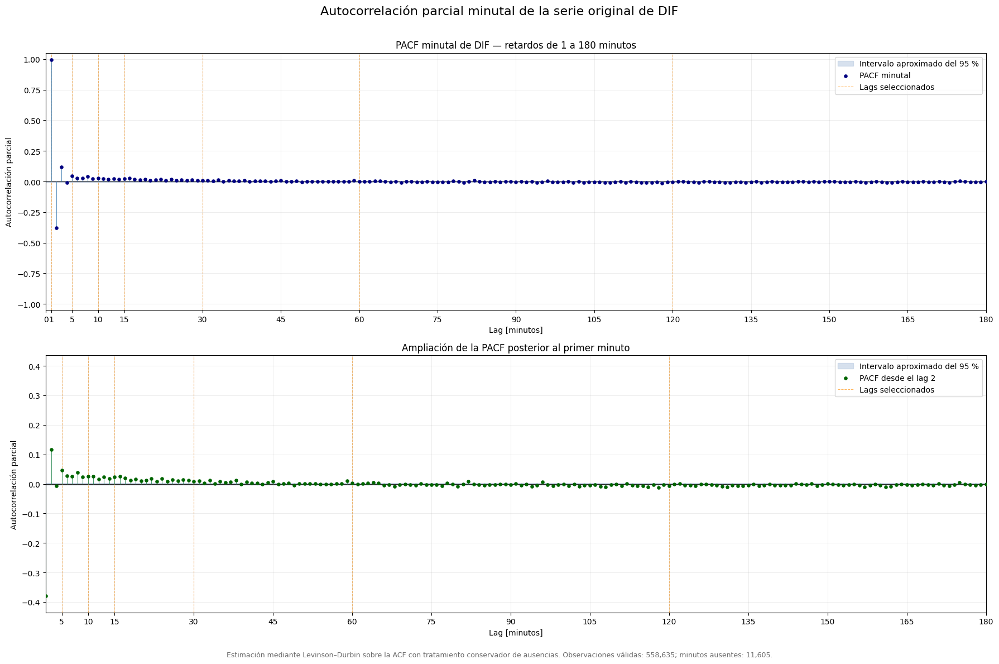

Control de la visualización PACF minutal:


,comprobacion,resultado
0,Serie representada,serie_regular_acf_minutal_dif
1,Resolución,1 minuto
2,Lag mínimo del panel principal,1
3,Lag máximo,180
4,Lag mínimo de la ampliación,2
5,Nivel de confianza,0.95
6,Observaciones válidas,558635
7,Minutos ausentes conservados,11605
8,Gráfica guardada,True
9,Ruta del archivo,/content/resultados_pacf_minutal_DIF_20261102_...


In [82]:
# 1. Comprobar los resultados del cálculo

# Definir los objetos que deben existir después
# del cálculo de la PACF minutal.
OBJETOS_REQUERIDOS_GRAFICO_PACF_MIN = [
    "valores_pacf_min",
    "lags_pacf_min",
    "semiancho_ic95_pacf_min",
    "MAX_LAG_PACF_MIN",
    "LAGS_CLAVE_PACF_MIN",
    "directorio_resultados_pacf_min",
    "serie_dif_minutal_pacf",
    "n_validos_pacf_min",
    "n_ausentes_pacf_min",
]

# Localizar los objetos que no estén disponibles.
objetos_ausentes_grafico_pacf_min = [
    nombre for nombre in OBJETOS_REQUERIDOS_GRAFICO_PACF_MIN if nombre not in globals()
]
if objetos_ausentes_grafico_pacf_min:

    # Detener la ejecución si no se ejecutaron
    # correctamente las celdas anteriores.
    raise NameError(
        "Faltan objetos para representar la PACF minutal: "
        f"{objetos_ausentes_grafico_pacf_min}. "
        "Ejecuta primero la preparación y el cálculo de la PACF minutal."
    )


# 2. Comprobar la integridad de los resultados
valores_pacf_min = np.asarray(valores_pacf_min, dtype=float)
lags_pacf_min = np.asarray(lags_pacf_min, dtype=int)

# Comprobar que los valores y los lags
# tengan exactamente la misma longitud.
if len(valores_pacf_min) != len(lags_pacf_min):
    raise RuntimeError("Los valores PACF y los lags tienen " "longitudes diferentes.")

if len(valores_pacf_min) != MAX_LAG_PACF_MIN + 1:
    raise RuntimeError(
        "La PACF no contiene todos los retardos " f"desde 0 hasta {MAX_LAG_PACF_MIN} minutos."
    )

if lags_pacf_min[0] != 0:

    # Detener la ejecución si la secuencia no comienza en cero.
    raise RuntimeError("La secuencia de lags PACF no comienza en cero.")

# Comprobar que el último lag coincida
# con el máximo configurado.
if lags_pacf_min[-1] != MAX_LAG_PACF_MIN:

    # Detener la ejecución si el último lag no es 180.
    raise RuntimeError("El último lag PACF no coincide " "con MAX_LAG_PACF_MIN.")

if not np.isfinite(valores_pacf_min).all():
    raise RuntimeError("Los valores PACF contienen resultados no finitos.")

if not np.isfinite(semiancho_ic95_pacf_min):

    # Detener la ejecución si la banda no puede representarse.
    raise RuntimeError("El semiancho del intervalo de confianza " "no es finito.")

if semiancho_ic95_pacf_min <= 0:

    # Detener la ejecución si el intervalo no es válido.
    raise RuntimeError("El semiancho del intervalo de confianza " "debe ser positivo.")

if not directorio_resultados_pacf_min.exists():

    # Detener la ejecución si no se creó la carpeta.
    raise FileNotFoundError("No existe el directorio de resultados PACF.")


# 3. Preparar los datos que se representarán

# Excluir el lag 0 de la gráfica principal.
#
# El lag 0 siempre tiene PACF igual a 1
# porque representa la correlación de la serie consigo misma.
mascara_completa_pacf_min = lags_pacf_min >= 1

# Seleccionar los lags desde 2 hasta 180
# para la gráfica ampliada.
#
# Se excluye el lag 1 porque normalmente será
# mucho mayor que los retardos posteriores.
mascara_ampliada_pacf_min = (lags_pacf_min >= 2) & (lags_pacf_min <= MAX_LAG_PACF_MIN)
if not mascara_completa_pacf_min.any():

    # Detener la ejecución si no existen lags posteriores a cero.
    raise RuntimeError("No existen lags para construir la gráfica principal.")

if not mascara_ampliada_pacf_min.any():

    # Detener la ejecución si no existen lags posteriores a uno.
    raise RuntimeError("No existen lags para construir la ampliación.")

marcas_regulares_x_pacf_min = np.arange(0, MAX_LAG_PACF_MIN + 1, 15)
marcas_eje_x_pacf_min = np.unique(
    np.concatenate([marcas_regulares_x_pacf_min, np.asarray(LAGS_CLAVE_PACF_MIN, dtype=int)])
)

# Conservar únicamente las marcas comprendidas
# en el intervalo representado.
marcas_eje_x_pacf_min = marcas_eje_x_pacf_min[
    (marcas_eje_x_pacf_min >= 0) & (marcas_eje_x_pacf_min <= MAX_LAG_PACF_MIN)
]


# 4. Calcular los límites verticales

# Calcular la mayor PACF absoluta entre los lags 1 y 180.
maximo_absoluto_completo_pacf_min = float(np.abs(valores_pacf_min[mascara_completa_pacf_min]).max())

# Crear un margen del 12 % alrededor
# de la mayor PACF observada.
limite_vertical_completo_pacf_min = maximo_absoluto_completo_pacf_min * 1.12
limite_vertical_completo_pacf_min = max(
    0.10, limite_vertical_completo_pacf_min, 3 * semiancho_ic95_pacf_min
)

# Evitar que la escala supere excesivamente
# el rango teórico de la PACF.
limite_vertical_completo_pacf_min = min(1.05, limite_vertical_completo_pacf_min)
maximo_absoluto_ampliado_pacf_min = float(np.abs(valores_pacf_min[mascara_ampliada_pacf_min]).max())
limite_vertical_ampliado_pacf_min = maximo_absoluto_ampliado_pacf_min * 1.15

# Garantizar que la banda de confianza
# pueda verse correctamente.
limite_vertical_ampliado_pacf_min = max(
    0.01, limite_vertical_ampliado_pacf_min, 3 * semiancho_ic95_pacf_min
)
limite_vertical_ampliado_pacf_min = min(1.05, limite_vertical_ampliado_pacf_min)


# 5. Crear la figura
figura_pacf_min, ejes_pacf_min = plt.subplots(nrows=2, ncols=1, figsize=(18, 12))

# Recuperar el eje correspondiente
# a la visión completa.
eje_completo_pacf_min = ejes_pacf_min[0]

# Recuperar el eje correspondiente
# a la ampliación posterior al lag 1.
eje_ampliado_pacf_min = ejes_pacf_min[1]


# 6. Dibujar la visión completa de 1 a 180 minutos

# Dibujar primero la banda aproximada
# del intervalo de confianza del 95 %.
eje_completo_pacf_min.axhspan(
    -semiancho_ic95_pacf_min,
    semiancho_ic95_pacf_min,
    color="lightsteelblue",
    alpha=0.50,
    label="Intervalo aproximado del 95 %",
    zorder=0,
)
eje_completo_pacf_min.axhline(y=0, color="black", linewidth=0.9, zorder=1)
eje_completo_pacf_min.vlines(
    x=lags_pacf_min[mascara_completa_pacf_min],
    ymin=0,
    ymax=valores_pacf_min[mascara_completa_pacf_min],
    color="steelblue",
    linewidth=0.8,
    alpha=0.85,
    zorder=2,
)
eje_completo_pacf_min.scatter(
    lags_pacf_min[mascara_completa_pacf_min],
    valores_pacf_min[mascara_completa_pacf_min],
    color="navy",
    s=14,
    zorder=3,
    label="PACF minutal",
)
for posicion_lag_clave_pacf_min, lag_clave_pacf_min in enumerate(LAGS_CLAVE_PACF_MIN):

    # Añadir una etiqueta a la leyenda
    # únicamente en la primera línea.
    if posicion_lag_clave_pacf_min == 0:
        etiqueta_lag_clave_pacf_min = "Lags seleccionados"

    # Evitar repetir la misma entrada en la leyenda.
    else:

        # No asignar etiqueta a las líneas posteriores.
        etiqueta_lag_clave_pacf_min = None

    eje_completo_pacf_min.axvline(
        x=lag_clave_pacf_min,
        color="darkorange",
        linestyle="--",
        linewidth=0.8,
        alpha=0.65,
        label=etiqueta_lag_clave_pacf_min,
        zorder=1,
    )

eje_completo_pacf_min.set_xlim(0, MAX_LAG_PACF_MIN)
eje_completo_pacf_min.set_ylim(
    -limite_vertical_completo_pacf_min, limite_vertical_completo_pacf_min
)
eje_completo_pacf_min.set_xticks(marcas_eje_x_pacf_min)
eje_completo_pacf_min.set_xlabel("Lag [minutos]")
eje_completo_pacf_min.set_ylabel("Autocorrelación parcial")
eje_completo_pacf_min.set_title("PACF minutal de DIF — retardos de 1 a 180 minutos")
eje_completo_pacf_min.grid(alpha=0.22)
eje_completo_pacf_min.legend(loc="best")


# 7. Dibujar la ampliación desde el lag 2

# Dibujar la banda aproximada
# del intervalo de confianza del 95 %.
eje_ampliado_pacf_min.axhspan(
    -semiancho_ic95_pacf_min,
    semiancho_ic95_pacf_min,
    color="lightsteelblue",
    alpha=0.50,
    label="Intervalo aproximado del 95 %",
    zorder=0,
)
eje_ampliado_pacf_min.axhline(y=0, color="black", linewidth=0.9, zorder=1)

# Dibujar una línea vertical para cada lag
# comprendido entre 2 y 180 minutos.
eje_ampliado_pacf_min.vlines(
    x=lags_pacf_min[mascara_ampliada_pacf_min],
    ymin=0,
    ymax=valores_pacf_min[mascara_ampliada_pacf_min],
    color="seagreen",
    linewidth=0.8,
    alpha=0.85,
    zorder=2,
)
eje_ampliado_pacf_min.scatter(
    lags_pacf_min[mascara_ampliada_pacf_min],
    valores_pacf_min[mascara_ampliada_pacf_min],
    color="darkgreen",
    s=14,
    zorder=3,
    label="PACF desde el lag 2",
)

# Seleccionar únicamente los lags clave
# que aparecen en la ampliación.
lags_clave_ampliacion_pacf_min = [lag for lag in LAGS_CLAVE_PACF_MIN if lag >= 2]
for posicion_lag_clave_pacf_min, lag_clave_pacf_min in enumerate(lags_clave_ampliacion_pacf_min):

    # Añadir una etiqueta únicamente a la primera línea.
    if posicion_lag_clave_pacf_min == 0:
        etiqueta_lag_clave_pacf_min = "Lags seleccionados"

    # Evitar entradas duplicadas en la leyenda.
    else:

        # No mostrar etiqueta en las líneas posteriores.
        etiqueta_lag_clave_pacf_min = None

    eje_ampliado_pacf_min.axvline(
        x=lag_clave_pacf_min,
        color="darkorange",
        linestyle="--",
        linewidth=0.8,
        alpha=0.65,
        label=etiqueta_lag_clave_pacf_min,
        zorder=1,
    )

eje_ampliado_pacf_min.set_xlim(2, MAX_LAG_PACF_MIN)
eje_ampliado_pacf_min.set_ylim(
    -limite_vertical_ampliado_pacf_min, limite_vertical_ampliado_pacf_min
)

# Utilizar las mismas referencias temporales,
# excluyendo las inferiores a dos minutos.
eje_ampliado_pacf_min.set_xticks(marcas_eje_x_pacf_min[marcas_eje_x_pacf_min >= 2])
eje_ampliado_pacf_min.set_xlabel("Lag [minutos]")
eje_ampliado_pacf_min.set_ylabel("Autocorrelación parcial")
eje_ampliado_pacf_min.set_title("Ampliación de la PACF posterior al primer minuto")
eje_ampliado_pacf_min.grid(alpha=0.22)
eje_ampliado_pacf_min.legend(loc="best")


# 8. Añadir información general a la figura
figura_pacf_min.suptitle(
    "Autocorrelación parcial minutal " "de la serie original de DIF", fontsize=16
)
figura_pacf_min.text(
    0.5,
    0.005,
    (
        "Estimación mediante Levinson–Durbin sobre la ACF "
        "con tratamiento conservador de ausencias. "
        f"Observaciones válidas: {n_validos_pacf_min:,}; "
        f"minutos ausentes: {n_ausentes_pacf_min:,}."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
    color="dimgray",
)

# Ajustar el espacio entre paneles,
# el título y la nota inferior.
figura_pacf_min.tight_layout(rect=[0, 0.025, 1, 0.97])


# 9. Guardar la figura
ruta_grafico_pacf_min = directorio_resultados_pacf_min / "pacf_minutal_DIF.png"
figura_pacf_min.savefig(ruta_grafico_pacf_min, dpi=200, bbox_inches="tight")
if not ruta_grafico_pacf_min.exists():

    # Detener la ejecución si el archivo no se creó.
    raise RuntimeError("La gráfica PACF no se ha guardado correctamente.")


# 10. Mostrar y cerrar la figura
plt.show()
plt.close(figura_pacf_min)


# 11. Mostrar el control de salida
control_grafico_pacf_min = pd.DataFrame(
    {
        "comprobacion": [
            "Serie representada",
            "Resolución",
            "Lag mínimo del panel principal",
            "Lag máximo",
            "Lag mínimo de la ampliación",
            "Nivel de confianza",
            "Observaciones válidas",
            "Minutos ausentes conservados",
            "Gráfica guardada",
            "Ruta del archivo",
        ],
        "resultado": [
            "serie_regular_acf_minutal_dif",
            "1 minuto",
            1,
            MAX_LAG_PACF_MIN,
            2,
            1 - ALPHA_PACF_MIN,
            n_validos_pacf_min,
            n_ausentes_pacf_min,
            ruta_grafico_pacf_min.exists(),
            str(ruta_grafico_pacf_min),
        ],
    }
)

# Mostrar el control de la visualización.
print("Control de la visualización PACF minutal:")

# Visualizar la tabla.
display(control_grafico_pacf_min)

**Conclusión.**

La función de autocorrelación parcial de la serie minutal original de irradiancia difusa mostró que la dependencia lineal directa se concentra fundamentalmente en los primeros retardos. La PACF correspondiente a un minuto fue 0,9962, lo que evidencia una continuidad temporal inmediata muy elevada. Los retardos de dos y tres minutos presentaron valores de −0,3786 y 0,1168, respectivamente, indicando que todavía contienen información lineal adicional una vez controlados los retardos intermedios. El signo negativo del segundo retardo no implica una correlación negativa entre observaciones separadas dos minutos, cuya ACF fue 0,9895, sino una corrección condicional respecto a la información proporcionada por el minuto inmediatamente anterior.

A partir de los primeros minutos, la magnitud de las autocorrelaciones parciales disminuyó rápidamente. La PACF fue 0,0089 a los 30 minutos, 0,0019 a una hora y −0,0009 a tres horas. Por tanto, aunque la ACF original permanecía elevada a dichos retardos, la PACF indica que esta persistencia se transmite principalmente mediante la sucesión de observaciones intermedias y no mediante relaciones lineales directas independientes con cada retardo lejano.

Debido al elevado tamaño muestral, numerosos coeficientes de pequeña magnitud resultaron estadísticamente significativos. En consecuencia, la selección de retardos no debe basarse exclusivamente en los intervalos de confianza, sino también en la magnitud y en la utilidad predictiva observada mediante validación temporal. Los resultados caracterizan la serie minutal como un proceso con una continuidad local muy intensa y una elevada redundancia temporal. No obstante, no permiten reducir directamente la ventana de entrada de N-BEATS al último minuto, puesto que la PACF únicamente evalúa dependencia lineal, la serie conserva tendencia y estacionalidad y el objetivo predictivo comprende un horizonte superior a un paso.

### A.4 Diagramas de retardo

Cada valor horario de la DIF se representa frente al observado 1, 12 y 24 horas antes: continuidad inmediata, fases aproximadamente opuestas del ciclo diario y repetición diaria. Estas proyecciones muestran curvaturas, agrupaciones o regímenes que un único coeficiente de correlación no recoge.

#### Preparación y validación

In [83]:
# 1. Importar las librerías necesarias
from pathlib import Path
import json

# Importar ZIP para comprimir los resultados finales.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 2. Identificar la serie horaria que se utilizará

# Guardar el nombre exacto de la serie horaria creada en la sección 10.
NOMBRE_SERIE_ORIGEN_LAG_ETAPA3B_DIF = "serie_horaria_original_etapa2_dif"
if NOMBRE_SERIE_ORIGEN_LAG_ETAPA3B_DIF not in globals():
    raise NameError(
        "No existe 'serie_horaria_original_etapa2_dif'. "
        "Ejecuta primero la sección 10.1 (serie horaria original)."
    )

if not isinstance(serie_horaria_original_etapa2_dif, pd.Series):

    # Detener la ejecución si el tipo de objeto no es correcto.
    raise TypeError("'serie_horaria_original_etapa2_dif' " "debe ser una pd.Series.")


# 3. Crear una copia independiente

# Copiar la serie para no modificar el objeto original.
serie_lag_etapa3b_dif = serie_horaria_original_etapa2_dif.copy(deep=True).astype(float)
serie_lag_etapa3b_dif.name = "DIF_horaria_diagramas_lag"


# 4. Validar la serie temporal
if not isinstance(serie_lag_etapa3b_dif.index, pd.DatetimeIndex):

    # Detener la ejecución si el índice no es temporal.
    raise TypeError("La serie no tiene un DatetimeIndex.")

# Comprobar que no existen timestamps duplicados.
if serie_lag_etapa3b_dif.index.duplicated().any():
    raise ValueError("La serie horaria contiene timestamps duplicados.")

if not serie_lag_etapa3b_dif.index.is_monotonic_increasing:

    # Detener la ejecución si el índice no está ordenado.
    raise ValueError("La serie horaria no está ordenada.")

# Comprobar que la serie no contiene valores ausentes.
if serie_lag_etapa3b_dif.isna().any():
    raise ValueError("La serie horaria contiene valores ausentes.")

if not np.isfinite(serie_lag_etapa3b_dif.to_numpy()).all():
    raise ValueError("La serie horaria contiene valores no finitos.")

separaciones_lag_etapa3b_dif = serie_lag_etapa3b_dif.index.to_series().diff().dropna()
frecuencia_regular_lag_etapa3b_dif = bool(
    (separaciones_lag_etapa3b_dif == pd.Timedelta(hours=1)).all()
)

# Detener la ejecución si la frecuencia no es regular.
if not frecuencia_regular_lag_etapa3b_dif:
    raise ValueError("La serie no presenta una frecuencia horaria regular.")


# 5. Definir los retardos del análisis
LAGS_DIAGRAMAS_ETAPA3B_DIF = (1, 12, 24)

# Definir el número deseado de intervalos para la curva de medianas.
NUMERO_INTERVALOS_MEDIANA_ETAPA3B_DIF = 30


# 6. Crear el directorio independiente de resultados
marca_ejecucion_lag_etapa3b_dif = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")

# Utilizar como base la carpeta desde la que se ejecuta el notebook.
directorio_notebook_lag_etapa3b_dif = Path.cwd()
directorio_resultados_lag_etapa3b_dif = directorio_notebook_lag_etapa3b_dif / (
    "resultados_etapa3b_diagramas_lag_DIF_" f"{marca_ejecucion_lag_etapa3b_dif}"
)
directorio_resultados_lag_etapa3b_dif.mkdir(parents=True, exist_ok=True)


# 7. Crear la tabla de control
control_preparacion_lag_etapa3b_dif = pd.DataFrame(
    {
        "comprobacion": [
            "Serie utilizada",
            "Resolución",
            "Primera observación",
            "Última observación",
            "Número de observaciones",
            "Valores ausentes",
            "Timestamps duplicados",
            "Frecuencia horaria regular",
            "Retardos seleccionados",
            "Media horaria recalculada ahora",
            "Valores interpolados ahora",
            "Observaciones eliminadas ahora",
        ],
        "resultado": [
            NOMBRE_SERIE_ORIGEN_LAG_ETAPA3B_DIF,
            "1 hora",
            serie_lag_etapa3b_dif.index.min(),
            serie_lag_etapa3b_dif.index.max(),
            len(serie_lag_etapa3b_dif),
            int(serie_lag_etapa3b_dif.isna().sum()),
            int(serie_lag_etapa3b_dif.index.duplicated().sum()),
            frecuencia_regular_lag_etapa3b_dif,
            str(list(LAGS_DIAGRAMAS_ETAPA3B_DIF)),
            False,
            False,
            False,
        ],
    }
)
print("Control de preparación de los diagramas de lag:")

# Visualizar la tabla de control.
display(control_preparacion_lag_etapa3b_dif)
print("\nDirectorio de resultados:", directorio_resultados_lag_etapa3b_dif)

Control de preparación de los diagramas de lag:


,comprobacion,resultado
0,Serie utilizada,serie_horaria_original_etapa2_dif
1,Resolución,1 hora
2,Primera observación,2023-12-28 00:00:00
3,Última observación,2024-11-30 23:00:00
4,Número de observaciones,8136
5,Valores ausentes,0
6,Timestamps duplicados,0
7,Frecuencia horaria regular,True
8,Retardos seleccionados,"[1, 12, 24]"
9,Media horaria recalculada ahora,False



Directorio de resultados: /content/resultados_etapa3b_diagramas_lag_DIF_20261102_154918


#### Parejas y resumen numérico

In [84]:
# 1. Comprobar los objetos de la preparación
OBJETOS_REQUERIDOS_PAREJAS_ETAPA3B_DIF = [
    "serie_lag_etapa3b_dif",
    "LAGS_DIAGRAMAS_ETAPA3B_DIF",
    "NUMERO_INTERVALOS_MEDIANA_ETAPA3B_DIF",
    "directorio_resultados_lag_etapa3b_dif",
]

# Localizar los objetos que no existen.
objetos_ausentes_parejas_etapa3b_dif = [
    nombre for nombre in OBJETOS_REQUERIDOS_PAREJAS_ETAPA3B_DIF if nombre not in globals()
]
if objetos_ausentes_parejas_etapa3b_dif:
    raise NameError("Faltan objetos de la preparación: " f"{objetos_ausentes_parejas_etapa3b_dif}")


# 2. Preparar los contenedores de resultados
pares_por_lag_etapa3b_dif = {}
perfiles_mediana_por_lag_etapa3b_dif = {}
registros_resumen_lag_etapa3b_dif = []


# 3. Construir las parejas para cada retardo
for lag_horas_etapa3b_dif in LAGS_DIAGRAMAS_ETAPA3B_DIF:
    serie_retrasada_etapa3b_dif = serie_lag_etapa3b_dif.shift(lag_horas_etapa3b_dif)

    # Crear las parejas entre el valor retrasado y el valor actual.
    pares_lag_actual_etapa3b_dif = pd.DataFrame(
        {"DIF_retrasada": (serie_retrasada_etapa3b_dif), "DIF_actual": (serie_lag_etapa3b_dif)}
    )

    # Eliminar únicamente las primeras filas sin valor retrasado.
    pares_lag_actual_etapa3b_dif = pares_lag_actual_etapa3b_dif.dropna().copy()
    pares_lag_actual_etapa3b_dif["Date_Time_retrasado"] = (
        pares_lag_actual_etapa3b_dif.index - pd.Timedelta(hours=lag_horas_etapa3b_dif)
    )
    pares_lag_actual_etapa3b_dif["hora_actual"] = pares_lag_actual_etapa3b_dif.index.hour
    numero_parejas_esperado_etapa3b_dif = len(serie_lag_etapa3b_dif) - lag_horas_etapa3b_dif

    # Comprobar que no se ha perdido ninguna pareja adicional.
    if len(pares_lag_actual_etapa3b_dif) != numero_parejas_esperado_etapa3b_dif:

        # Detener la ejecución si la alineación no es completa.
        raise RuntimeError(
            "El número de parejas no es el esperado " f"para el lag {lag_horas_etapa3b_dif}."
        )

    correlacion_pearson_etapa3b_dif = float(
        pares_lag_actual_etapa3b_dif["DIF_retrasada"].corr(
            pares_lag_actual_etapa3b_dif["DIF_actual"], method="pearson"
        )
    )
    correlacion_spearman_etapa3b_dif = float(
        pares_lag_actual_etapa3b_dif["DIF_retrasada"].corr(
            pares_lag_actual_etapa3b_dif["DIF_actual"], method="spearman"
        )
    )
    valores_x_etapa3b_dif = pares_lag_actual_etapa3b_dif["DIF_retrasada"].to_numpy(dtype=float)
    valores_y_etapa3b_dif = pares_lag_actual_etapa3b_dif["DIF_actual"].to_numpy(dtype=float)
    pendiente_lineal_etapa3b_dif, intercepto_lineal_etapa3b_dif = np.polyfit(
        valores_x_etapa3b_dif, valores_y_etapa3b_dif, deg=1
    )
    prediccion_lineal_etapa3b_dif = (
        pendiente_lineal_etapa3b_dif * valores_x_etapa3b_dif + intercepto_lineal_etapa3b_dif
    )
    suma_errores_cuadrados_etapa3b_dif = float(
        np.sum((valores_y_etapa3b_dif - prediccion_lineal_etapa3b_dif) ** 2)
    )
    suma_total_cuadrados_etapa3b_dif = float(
        np.sum((valores_y_etapa3b_dif - valores_y_etapa3b_dif.mean()) ** 2)
    )
    r2_lineal_etapa3b_dif = float(
        1 - (suma_errores_cuadrados_etapa3b_dif / suma_total_cuadrados_etapa3b_dif)
    )
    intervalos_cuantiles_etapa3b_dif = pd.qcut(
        pares_lag_actual_etapa3b_dif["DIF_retrasada"],
        q=NUMERO_INTERVALOS_MEDIANA_ETAPA3B_DIF,
        duplicates="drop",
    )
    tabla_perfil_lag_etapa3b_dif = pares_lag_actual_etapa3b_dif.assign(
        intervalo_DIF_retrasada=(intervalos_cuantiles_etapa3b_dif)
    )
    perfil_mediana_lag_etapa3b_dif = (
        tabla_perfil_lag_etapa3b_dif.groupby("intervalo_DIF_retrasada", observed=True)
        .agg(
            DIF_retrasada_mediana=("DIF_retrasada", "median"),
            DIF_actual_mediana=("DIF_actual", "median"),
            numero_pares=("DIF_actual", "size"),
        )
        .reset_index(drop=True)
        .sort_values("DIF_retrasada_mediana")
        .reset_index(drop=True)
    )
    pares_por_lag_etapa3b_dif[lag_horas_etapa3b_dif] = pares_lag_actual_etapa3b_dif
    perfiles_mediana_por_lag_etapa3b_dif[lag_horas_etapa3b_dif] = perfil_mediana_lag_etapa3b_dif
    registros_resumen_lag_etapa3b_dif.append(
        {
            "lag_horas": lag_horas_etapa3b_dif,
            "equivalencia_temporal": f"{lag_horas_etapa3b_dif} horas",
            "numero_parejas": len(pares_lag_actual_etapa3b_dif),
            "correlacion_Pearson": correlacion_pearson_etapa3b_dif,
            "correlacion_Spearman": correlacion_spearman_etapa3b_dif,
            "pendiente_lineal": float(pendiente_lineal_etapa3b_dif),
            "intercepto_lineal": float(intercepto_lineal_etapa3b_dif),
            "R2_lineal": r2_lineal_etapa3b_dif,
        }
    )


# 4. Crear y mostrar el resumen final
resumen_diagramas_lag_etapa3b_dif = pd.DataFrame(registros_resumen_lag_etapa3b_dif)
print("Resumen numérico de los diagramas de lag:")

# Visualizar los resultados con seis decimales.
display(
    resumen_diagramas_lag_etapa3b_dif.style.format(
        {
            "correlacion_Pearson": "{:.6f}",
            "correlacion_Spearman": "{:.6f}",
            "pendiente_lineal": "{:.6f}",
            "intercepto_lineal": "{:.6f}",
            "R2_lineal": "{:.6f}",
        }
    )
)
print(
    "\nLas correlaciones de esta tabla se calculan "
    "directamente sobre las parejas representadas. "
    "Pueden diferir ligeramente de los coeficientes ACF "
    "por la forma de centrado y normalización."
)

Resumen numérico de los diagramas de lag:


,lag_horas,equivalencia_temporal,numero_parejas,correlacion_Pearson,correlacion_Spearman,pendiente_lineal,intercepto_lineal,R2_lineal
0,1,1 horas,8135,0.915433,0.921641,0.915432,6.126776,0.838017
1,12,12 horas,8124,-0.437499,-0.647409,-0.437496,104.232292,0.191405
2,24,24 horas,8112,0.827073,0.915168,0.827022,12.546963,0.684049



Las correlaciones de esta tabla se calculan directamente sobre las parejas representadas. Pueden diferir ligeramente de los coeficientes ACF por la forma de centrado y normalización.


#### Diagramas

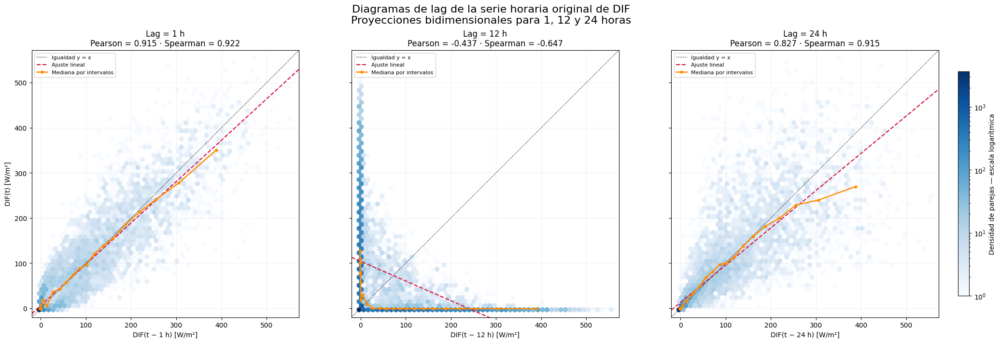

Gráfico guardado en: /content/resultados_etapa3b_diagramas_lag_DIF_20261102_154918/diagramas_lag_DIF_1h_12h_24h.png


In [85]:
# 1. Comprobar los objetos necesarios
OBJETOS_REQUERIDOS_GRAFICO_ETAPA3B_DIF = [
    "pares_por_lag_etapa3b_dif",
    "perfiles_mediana_por_lag_etapa3b_dif",
    "resumen_diagramas_lag_etapa3b_dif",
    "directorio_resultados_lag_etapa3b_dif",
]
objetos_ausentes_grafico_etapa3b_dif = [
    nombre for nombre in OBJETOS_REQUERIDOS_GRAFICO_ETAPA3B_DIF if nombre not in globals()
]
if objetos_ausentes_grafico_etapa3b_dif:
    raise NameError("Faltan resultados del cálculo: " f"{objetos_ausentes_grafico_etapa3b_dif}")


# 2. Definir límites comunes
minimo_diagrama_lag_etapa3b_dif = float(serie_lag_etapa3b_dif.min())
maximo_diagrama_lag_etapa3b_dif = float(serie_lag_etapa3b_dif.max())
rango_diagrama_lag_etapa3b_dif = maximo_diagrama_lag_etapa3b_dif - minimo_diagrama_lag_etapa3b_dif
margen_diagrama_lag_etapa3b_dif = 0.03 * rango_diagrama_lag_etapa3b_dif
limite_inferior_diagrama_lag_etapa3b_dif = (
    minimo_diagrama_lag_etapa3b_dif - margen_diagrama_lag_etapa3b_dif
)
limite_superior_diagrama_lag_etapa3b_dif = (
    maximo_diagrama_lag_etapa3b_dif + margen_diagrama_lag_etapa3b_dif
)


# 3. Crear la figura
figura_diagramas_lag_etapa3b_dif, ejes_diagramas_lag_etapa3b_dif = plt.subplots(
    nrows=1, ncols=3, figsize=(21, 7), sharex=True, sharey=True, constrained_layout=True
)
ultimo_hexbin_etapa3b_dif = None


# 4. Representar cada retardo
for eje_lag_etapa3b_dif, lag_horas_etapa3b_dif in zip(
    ejes_diagramas_lag_etapa3b_dif, LAGS_DIAGRAMAS_ETAPA3B_DIF
):
    pares_lag_actual_etapa3b_dif = pares_por_lag_etapa3b_dif[lag_horas_etapa3b_dif]
    perfil_lag_actual_etapa3b_dif = perfiles_mediana_por_lag_etapa3b_dif[lag_horas_etapa3b_dif]
    resumen_lag_actual_etapa3b_dif = resumen_diagramas_lag_etapa3b_dif.loc[
        resumen_diagramas_lag_etapa3b_dif["lag_horas"] == lag_horas_etapa3b_dif
    ].iloc[0]
    ultimo_hexbin_etapa3b_dif = eje_lag_etapa3b_dif.hexbin(
        pares_lag_actual_etapa3b_dif["DIF_retrasada"],
        pares_lag_actual_etapa3b_dif["DIF_actual"],
        gridsize=55,
        mincnt=1,
        bins="log",
        cmap="Blues",
        linewidths=0.15,
    )
    eje_lag_etapa3b_dif.plot(
        [limite_inferior_diagrama_lag_etapa3b_dif, limite_superior_diagrama_lag_etapa3b_dif],
        [limite_inferior_diagrama_lag_etapa3b_dif, limite_superior_diagrama_lag_etapa3b_dif],
        color="black",
        linestyle=":",
        linewidth=1.0,
        label="Igualdad y = x",
    )
    valores_recta_x_etapa3b_dif = np.linspace(
        limite_inferior_diagrama_lag_etapa3b_dif, limite_superior_diagrama_lag_etapa3b_dif, 200
    )
    valores_recta_y_etapa3b_dif = (
        resumen_lag_actual_etapa3b_dif["pendiente_lineal"] * valores_recta_x_etapa3b_dif
        + resumen_lag_actual_etapa3b_dif["intercepto_lineal"]
    )
    eje_lag_etapa3b_dif.plot(
        valores_recta_x_etapa3b_dif,
        valores_recta_y_etapa3b_dif,
        color="crimson",
        linestyle="--",
        linewidth=1.6,
        label="Ajuste lineal",
    )
    eje_lag_etapa3b_dif.plot(
        perfil_lag_actual_etapa3b_dif["DIF_retrasada_mediana"],
        perfil_lag_actual_etapa3b_dif["DIF_actual_mediana"],
        color="darkorange",
        marker="o",
        markersize=3.5,
        linewidth=1.8,
        label="Mediana por intervalos",
    )
    eje_lag_etapa3b_dif.set_xlim(
        limite_inferior_diagrama_lag_etapa3b_dif, limite_superior_diagrama_lag_etapa3b_dif
    )
    eje_lag_etapa3b_dif.set_ylim(
        limite_inferior_diagrama_lag_etapa3b_dif, limite_superior_diagrama_lag_etapa3b_dif
    )
    eje_lag_etapa3b_dif.set_aspect("equal", adjustable="box")
    eje_lag_etapa3b_dif.set_title(
        (
            f"Lag = {lag_horas_etapa3b_dif} h\n"
            f"Pearson = "
            f"{resumen_lag_actual_etapa3b_dif['correlacion_Pearson']:.3f}"
            " · "
            f"Spearman = "
            f"{resumen_lag_actual_etapa3b_dif['correlacion_Spearman']:.3f}"
        )
    )
    eje_lag_etapa3b_dif.set_xlabel(f"DIF(t − {lag_horas_etapa3b_dif} h) [W/m²]")
    eje_lag_etapa3b_dif.grid(alpha=0.18)
    eje_lag_etapa3b_dif.legend(loc="upper left", fontsize=8)


# 5. Completar y guardar la figura
ejes_diagramas_lag_etapa3b_dif[0].set_ylabel("DIF(t) [W/m²]")
barra_color_lag_etapa3b_dif = figura_diagramas_lag_etapa3b_dif.colorbar(
    ultimo_hexbin_etapa3b_dif, ax=ejes_diagramas_lag_etapa3b_dif, shrink=0.84, pad=0.02
)
barra_color_lag_etapa3b_dif.set_label("Densidad de parejas — escala logarítmica")
figura_diagramas_lag_etapa3b_dif.suptitle(
    (
        "Diagramas de lag de la serie horaria original de DIF\n"
        "Proyecciones bidimensionales para 1, 12 y 24 horas"
    ),
    fontsize=16,
)
ruta_grafico_diagramas_lag_etapa3b_dif = (
    directorio_resultados_lag_etapa3b_dif / "diagramas_lag_DIF_1h_12h_24h.png"
)
figura_diagramas_lag_etapa3b_dif.savefig(
    ruta_grafico_diagramas_lag_etapa3b_dif, dpi=220, bbox_inches="tight"
)
plt.show()
plt.close(figura_diagramas_lag_etapa3b_dif)
print("Gráfico guardado en:", ruta_grafico_diagramas_lag_etapa3b_dif)

**Interpretación.**

Con el objetivo de complementar los resultados obtenidos mediante las funciones ACF y PACF, se representaron los diagramas de retardo de la serie horaria original de radiación difusa para retardos de 1, 12 y 24 horas. Estos diagramas muestran las parejas formadas por el valor actual, $DIF_t$, y el valor observado $k$ horas antes, $DIF_{t-k}$, permitiendo examinar la geometría de la dependencia temporal que queda resumida en un único coeficiente dentro del análisis de autocorrelación.

Para facilitar la interpretación se incorporaron tres referencias. La línea de igualdad representa el caso de persistencia perfecta, la recta de regresión resume la asociación lineal y el perfil de medianas aproxima la relación central empírica sin imponer una forma funcional lineal. Este último se obtuvo dividiendo los valores retrasados en intervalos cuantílicos y calculando, dentro de cada intervalo, las medianas de $DIF_{t-k}$ y $DIF_t$.

El retardo de una hora presentó una correlación de Pearson de 0,915 y una correlación de Spearman de 0,922. La proximidad entre ambos coeficientes, junto con la similitud entre la recta ajustada y el perfil de medianas, indica una relación predominantemente lineal. El modelo lineal univariante alcanzó un $R^2$ de 0,838, lo que confirma que el valor de la hora inmediatamente anterior contiene una proporción elevada de la información sobre el nivel actual. Esta dependencia se relaciona con la continuidad de la evolución solar, la persistencia de las condiciones atmosféricas y la presencia de secuencias ascendentes o descendentes durante el periodo diurno. No obstante, la dispersión aumentó con el nivel de DIF, mostrando una mayor variabilidad durante las horas con radiación.

Para el retardo de doce horas se obtuvo una correlación de Pearson de −0,437 y una correlación de Spearman de −0,647, mientras que el $R^2$ lineal fue solamente 0,191. El perfil de medianas presentó una forma marcadamente no lineal: cuando el valor retrasado era próximo a cero, el valor actual podía corresponder al periodo diurno, mientras que los valores retrasados elevados se asociaban mayoritariamente con valores actuales nocturnos próximos a cero. En consecuencia, la correlación negativa de doce horas no debe interpretarse como una relación lineal inversa, sino como el resultado de comparar fases aproximadamente opuestas del ciclo diario.

El retardo de veinticuatro horas mostró una relación positiva fuerte, con una correlación de Pearson de 0,827 y una correlación de Spearman de 0,915. La diferencia entre ambos coeficientes indica que el orden relativo de los valores se conserva mejor que su proporcionalidad exacta. El perfil de medianas siguió aproximadamente la relación de igualdad para niveles bajos y moderados, pero se aplanó progresivamente en los valores más elevados. Así, los episodios extremos de DIF no tendieron a repetirse con la misma intensidad al día siguiente, sino que regresaron hacia valores más habituales. Este comportamiento puede relacionarse con la variabilidad interdiaria de la nubosidad, los cambios en la geometría solar y la existencia de diferentes regímenes atmosféricos capaces de producir niveles similares de radiación difusa.

Los diagramas permiten reconciliar la elevada asociación diaria observada en la ACF con la menor contribución directa encontrada mediante la PACF. La asociación de una hora se mantuvo elevada tanto en la ACF como en la PACF, confirmando su carácter directo. Por el contrario, las asociaciones de doce y veinticuatro horas se redujeron notablemente en la PACF después de controlar los retardos intermedios. Por tanto, su elevada relación bivariada procede principalmente del ciclo diario y de la información transmitida por la secuencia de horas intermedias.

En conjunto, los diagramas de retardo confirman la existencia de una dependencia lineal inmediata muy fuerte y revelan relaciones no lineales o dependientes del régimen en las escalas de doce y veinticuatro horas. Estos resultados respaldan el empleo de una ventana continua de al menos 24 horas para el modelo N-BEATS, puesto que permite incorporar simultáneamente la persistencia inmediata, la evolución intermedia y la fase diaria. Sin embargo, los diagramas constituyen una evidencia visual y descriptiva, no una demostración de que toda la componente no lineal resulte predictiva. Esta cuestión se aborda con la información mutua (sección 14) y, finalmente, con la comparación fuera de muestra entre N-BEATS, los modelos de persistencia y un modelo autorregresivo lineal.